In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("GPU connect nahi hua.")

GPU available: True
GPU name: Tesla T4


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

zip_path = Path(
    "/content/drive/MyDrive/RARE26/dataset/RARE25-train-data.zip"
)

print("ZIP exists:", zip_path.exists())

if zip_path.exists():
    size_gb = zip_path.stat().st_size / (1024 ** 3)
    print(f"ZIP size: {size_gb:.2f} GB")
    print("ZIP path:", zip_path)
else:
    print("ZIP file nahi mili. Path dobara check karna hoga.")

ZIP exists: True
ZIP size: 1.18 GB
ZIP path: /content/drive/MyDrive/RARE26/dataset/RARE25-train-data.zip


In [ ]:
import shutil
import zipfile
from pathlib import Path

# Google Drive wali ZIP
drive_zip = Path(
    "/content/drive/MyDrive/RARE26/dataset/RARE25-train-data.zip"
)

# Colab ki temporary fast storage
local_zip = Path("/content/RARE25-train-data.zip")
extract_folder = Path("/content/RARE26_data")

print("ZIP Colab storage mein copy ho rahi hai...")
shutil.copy2(drive_zip, local_zip)
print("ZIP copy complete.")

extract_folder.mkdir(parents=True, exist_ok=True)

print("Dataset extract ho raha hai...")
with zipfile.ZipFile(local_zip, "r") as zip_file:
    zip_file.extractall(extract_folder)

print("Dataset extraction complete.")
print("Extracted location:", extract_folder)

print("\nTop-level contents:")
for item in extract_folder.iterdir():
    print(item)

ZIP Colab storage mein copy ho rahi hai...
ZIP copy complete.
Dataset extract ho raha hai...
Dataset extraction complete.
Extracted location: /content/RARE26_data

Top-level contents:
/content/RARE26_data/center_2
/content/RARE26_data/center_1


In [ ]:
from pathlib import Path
import pandas as pd

dataset_root = Path("/content/RARE26_data")

folders = [
    ("center_1", "ndbe"),
    ("center_1", "neo"),
    ("center_2", "ndbe"),
    ("center_2", "neo"),
]

total = 0

print("DATASET COUNTS")
print("-" * 40)

for center, image_class in folders:
    folder = dataset_root / center / image_class
    count = len(list(folder.glob("*.png")))
    total += count
    print(f"{center} / {image_class}: {count}")

print("-" * 40)
print("Total images:", total)

# Uploaded split file check
train_csv = Path(
    "/content/drive/MyDrive/RARE26/splits/train_manifest.csv"
)

train_df = pd.read_csv(train_csv)

print("\nTRAIN MANIFEST")
print("Rows:", len(train_df))
print("Columns:", train_df.columns.tolist())

print("\nFirst row:")
print(train_df.iloc[0])

DATASET COUNTS
----------------------------------------
center_1 / ndbe: 2218
center_1 / neo: 61
center_2 / ndbe: 719
center_2 / neo: 97
----------------------------------------
Total images: 3095

TRAIN MANIFEST
Rows: 2159
Columns: ['file_path', 'relative_path', 'center', 'class', 'label', 'sha256', 'split']

First row:
file_path        C:\thesis\dataset\RARE25-train-data\center_1\n...
relative_path    center_1\ndbe\af193b2896e542abb727eba4b15a453d...
center                                                    center_1
class                                                         ndbe
label                                                            0
sha256           80fbd72c28f8f64f6d72b7271aefa4048ae583cc6e1972...
split                                                        train
Name: 0, dtype: object


In [ ]:
from pathlib import Path
import pandas as pd

dataset_root = Path("/content/RARE26_data")
splits_folder = Path("/content/drive/MyDrive/RARE26/splits")

split_names = [
    "train",
    "validation",
    "test",
]

for split_name in split_names:
    input_csv = splits_folder / f"{split_name}_manifest.csv"
    output_csv = splits_folder / f"{split_name}_colab.csv"

    df = pd.read_csv(input_csv)

    # Windows backslashes ko normal slashes mein convert karna
    df["relative_path"] = (
        df["relative_path"]
        .astype(str)
        .str.replace("\\", "/", regex=False)
    )

    # Colab mein actual image path banana
    df["colab_path"] = df["relative_path"].apply(
        lambda path: str(dataset_root / path)
    )

    # Check ke har image Colab mein mil rahi hai
    df["file_exists"] = df["colab_path"].apply(
        lambda path: Path(path).exists()
    )

    missing_count = (~df["file_exists"]).sum()

    df.to_csv(output_csv, index=False)

    print(f"\n{split_name.upper()}")
    print("Rows:", len(df))
    print("Missing images:", missing_count)
    print("Saved:", output_csv)

print("\nPath conversion complete.")


TRAIN
Rows: 2159
Missing images: 0
Saved: /content/drive/MyDrive/RARE26/splits/train_colab.csv

VALIDATION
Rows: 461
Missing images: 0
Saved: /content/drive/MyDrive/RARE26/splits/validation_colab.csv

TEST
Rows: 468
Missing images: 0
Saved: /content/drive/MyDrive/RARE26/splits/test_colab.csv

Path conversion complete.


In [ ]:
import torch
import pandas as pd

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms


# Images ko ResNet ke required format mein convert karega
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class RARE26Dataset(Dataset):
    def __init__(self, csv_path, transform=None):
        self.data = pd.read_csv(csv_path)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        row = self.data.iloc[index]

        image = Image.open(row["colab_path"]).convert("RGB")
        label = int(row["label"])

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)


splits_folder = "/content/drive/MyDrive/RARE26/splits"

train_dataset = RARE26Dataset(
    f"{splits_folder}/train_colab.csv",
    transform=image_transform
)

validation_dataset = RARE26Dataset(
    f"{splits_folder}/validation_colab.csv",
    transform=image_transform
)

test_dataset = RARE26Dataset(
    f"{splits_folder}/test_colab.csv",
    transform=image_transform
)


train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# Ek batch test karna
images, labels = next(iter(train_loader))

print("Train images:", len(train_dataset))
print("Validation images:", len(validation_dataset))
print("Test images:", len(test_dataset))

print("\nOne batch image shape:", images.shape)
print("One batch label shape:", labels.shape)

print(
    "Labels in this batch:",
    torch.bincount(labels, minlength=2).tolist()
)

print("\nDataLoader successfully created.")

Train images: 2159
Validation images: 461
Test images: 468

One batch image shape: torch.Size([32, 3, 224, 224])
One batch label shape: torch.Size([32])
Labels in this batch: [30, 2]

DataLoader successfully created.


In [ ]:
import torch
import torch.nn as nn

from torchvision.models import resnet18, ResNet18_Weights


# Reproducibility
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

# GPU select
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ImageNet-pretrained ResNet-18
weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights)

# Original 1000-class layer ko hamari 2 classes se replace karna
input_features = model.fc.in_features
model.fc = nn.Linear(input_features, 2)

# Model GPU par bhejna
model = model.to(device)

print("Device:", device)
print("Final output classes:", model.fc.out_features)

# Ek batch GPU par bhej kar model test karna
images, labels = next(iter(train_loader))

images = images.to(device)
labels = labels.to(device)

model.eval()

with torch.no_grad():
    outputs = model(images)

print("Input batch shape:", images.shape)
print("Model output shape:", outputs.shape)
print("Model successfully loaded and tested.")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 46.6MB/s]


Device: cuda
Final output classes: 2
Input batch shape: torch.Size([32, 3, 224, 224])
Model output shape: torch.Size([32, 2])
Model successfully loaded and tested.


In [ ]:
import torch
import torch.nn as nn
import pandas as pd

from pathlib import Path
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

# Baseline mein standard loss use hogi
criterion = nn.CrossEntropyLoss()

# Model ko update karne ke liye optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

# Model yahan save hoga
model_save_path = Path(
    "/content/drive/MyDrive/RARE26/models/"
    "resnet18_baseline_best.pth"
)

# Training class distribution check
train_labels = pd.read_csv(
    "/content/drive/MyDrive/RARE26/splits/train_colab.csv"
)["label"]

normal_count = int((train_labels == 0).sum())
neo_count = int((train_labels == 1).sum())

print("BASELINE TRAINING SETUP")
print("-" * 45)
print("Loss function: Standard CrossEntropyLoss")
print("Optimizer: AdamW")
print("Learning rate: 0.0001")
print("Normal training images:", normal_count)
print("Neoplasia training images:", neo_count)
print("Model will be saved at:")
print(model_save_path)

print("\nTraining setup successfully completed.")

BASELINE TRAINING SETUP
---------------------------------------------
Loss function: Standard CrossEntropyLoss
Optimizer: AdamW
Learning rate: 0.0001
Normal training images: 2050
Neoplasia training images: 109
Model will be saved at:
/content/drive/MyDrive/RARE26/models/resnet18_baseline_best.pth

Training setup successfully completed.


In [ ]:
import time
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
)

# Total training epochs
num_epochs = 10

# Best validation AUPRC track karne ke liye
best_val_auprc = -1.0

# Training history yahan store hogi
history = []

history_save_path = (
    "/content/drive/MyDrive/RARE26/results/"
    "resnet18_baseline_history.csv"
)

latest_model_path = (
    "/content/drive/MyDrive/RARE26/models/"
    "resnet18_baseline_latest.pth"
)


def evaluate_model(model, data_loader, criterion, device):
    model.eval()

    total_loss = 0.0
    all_labels = []
    all_probabilities = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)
            loss = criterion(outputs, labels)

            probabilities = torch.softmax(outputs, dim=1)[:, 1]
            predictions = torch.argmax(outputs, dim=1)

            total_loss += loss.item() * images.size(0)

            all_labels.extend(labels.cpu().numpy())
            all_probabilities.extend(probabilities.cpu().numpy())
            all_predictions.extend(predictions.cpu().numpy())

    average_loss = total_loss / len(data_loader.dataset)

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    precision = precision_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    auroc = roc_auc_score(
        all_labels,
        all_probabilities
    )

    auprc = average_precision_score(
        all_labels,
        all_probabilities
    )

    return {
        "loss": average_loss,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "auroc": auroc,
        "auprc": auprc,
    }


print("Baseline training start ho rahi hai...")
print("=" * 70)

for epoch in range(1, num_epochs + 1):
    start_time = time.time()

    model.train()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for images, labels in train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # Purane gradients clear
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Loss calculate
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Model weights update
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = torch.argmax(outputs, dim=1)

        correct_predictions += (
            predictions == labels
        ).sum().item()

        total_samples += labels.size(0)

    train_loss = running_loss / total_samples
    train_accuracy = correct_predictions / total_samples

    # Validation evaluation
    validation_metrics = evaluate_model(
        model,
        validation_loader,
        criterion,
        device
    )

    epoch_time = time.time() - start_time

    epoch_record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": validation_metrics["loss"],
        "val_accuracy": validation_metrics["accuracy"],
        "val_precision": validation_metrics["precision"],
        "val_recall": validation_metrics["recall"],
        "val_auroc": validation_metrics["auroc"],
        "val_auprc": validation_metrics["auprc"],
        "epoch_seconds": epoch_time,
    }

    history.append(epoch_record)

    # History har epoch ke baad Drive mein save
    pd.DataFrame(history).to_csv(
        history_save_path,
        index=False
    )

    # Latest checkpoint
    torch.save(
        {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "validation_metrics": validation_metrics,
        },
        latest_model_path
    )

    # Best model validation AUPRC ke basis par
    if validation_metrics["auprc"] > best_val_auprc:
        best_val_auprc = validation_metrics["auprc"]

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "validation_metrics": validation_metrics,
            },
            model_save_path
        )

        best_message = "  <-- Best model saved"
    else:
        best_message = ""

    print(
        f"Epoch {epoch:02d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {validation_metrics['loss']:.4f} | "
        f"Recall: {validation_metrics['recall']:.4f} | "
        f"Precision: {validation_metrics['precision']:.4f} | "
        f"AUROC: {validation_metrics['auroc']:.4f} | "
        f"AUPRC: {validation_metrics['auprc']:.4f} | "
        f"Time: {epoch_time:.1f}s"
        f"{best_message}"
    )

print("=" * 70)
print("Baseline training complete.")
print("Best validation AUPRC:", round(best_val_auprc, 4))
print("Best model saved at:")
print(model_save_path)
print("Training history saved at:")
print(history_save_path)

Baseline training start ho rahi hai...
Epoch 01/10 | Train Loss: 0.2688 | Val Loss: 0.1113 | Recall: 0.4783 | Precision: 1.0000 | AUROC: 0.8913 | AUPRC: 0.6861 | Time: 42.0s  <-- Best model saved
Epoch 02/10 | Train Loss: 0.0499 | Val Loss: 0.1194 | Recall: 0.4783 | Precision: 0.7857 | AUROC: 0.8538 | AUPRC: 0.6523 | Time: 35.9s
Epoch 03/10 | Train Loss: 0.0129 | Val Loss: 0.0930 | Recall: 0.5652 | Precision: 1.0000 | AUROC: 0.8925 | AUPRC: 0.7600 | Time: 35.7s  <-- Best model saved
Epoch 04/10 | Train Loss: 0.0055 | Val Loss: 0.0937 | Recall: 0.5217 | Precision: 1.0000 | AUROC: 0.9100 | AUPRC: 0.7520 | Time: 41.4s
Epoch 05/10 | Train Loss: 0.0032 | Val Loss: 0.0988 | Recall: 0.5217 | Precision: 1.0000 | AUROC: 0.9025 | AUPRC: 0.7528 | Time: 36.5s
Epoch 06/10 | Train Loss: 0.0023 | Val Loss: 0.0927 | Recall: 0.6087 | Precision: 1.0000 | AUROC: 0.9106 | AUPRC: 0.7754 | Time: 36.6s  <-- Best model saved
Epoch 07/10 | Train Loss: 0.0049 | Val Loss: 0.1564 | Recall: 0.6522 | Precision: 0.5

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torchvision.models import resnet18
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
)

# Best saved model path
best_model_path = Path(
    "/content/drive/MyDrive/RARE26/models/"
    "resnet18_baseline_best.pth"
)

# Model dobara create karna
best_model = resnet18(weights=None)
best_model.fc = nn.Linear(best_model.fc.in_features, 2)

# Best checkpoint load karna
checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=False # Added this line to fix the UnpicklingError
)

best_model.load_state_dict(
    checkpoint["model_state_dict"]
)

best_model = best_model.to(device)
best_model.eval()

print("Best checkpoint epoch:", checkpoint["epoch"])
print(
    "Saved validation AUPRC:",
    checkpoint["validation_metrics"]["auprc"]
)


def collect_predictions(model, data_loader, device):
    all_labels = []
    all_probabilities = []

    model.eval()

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device, non_blocking=True)

            outputs = model(images)
            probabilities = torch.softmax(outputs, dim=1)[:, 1]

            all_labels.extend(labels.numpy())
            all_probabilities.extend(
                probabilities.cpu().numpy()
            )

    return (
        np.array(all_labels),
        np.array(all_probabilities),
    )


def calculate_metrics(labels, probabilities, threshold):
    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    return {
        "threshold": threshold,
        "accuracy": accuracy_score(
            labels,
            predictions
        ),
        "precision": precision_score(
            labels,
            predictions,
            zero_division=0
        ),
        "recall": recall_score(
            labels,
            predictions,
            zero_division=0
        ),
        "specificity": specificity,
        "auroc": roc_auc_score(
            labels,
            probabilities
        ),
        "auprc": average_precision_score(
            labels,
            probabilities
        ),
        "true_negatives": tn,
        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp,
    }


# Validation probabilities
val_labels, val_probabilities = collect_predictions(
    best_model,
    validation_loader,
    device
)

# Test probabilities
test_labels, test_probabilities = collect_predictions(
    best_model,
    test_loader,
    device
)

# Validation set par 90% recall wala threshold choose karna
precision_values, recall_values, thresholds = (
    precision_recall_curve(
        val_labels,
        val_probabilities
    )
)

valid_indices = np.where(
    recall_values[:-1] >= 0.90
)[0]

if len(valid_indices) > 0:
    best_index = valid_indices[
        np.argmax(
            precision_values[:-1][valid_indices]
        )
    ]

    recall90_threshold = thresholds[best_index]
else:
    recall90_threshold = 0.5

# Default threshold metrics
default_metrics = calculate_metrics(
    test_labels,
    test_probabilities,
    threshold=0.5
)

# Validation-selected 90% recall threshold metrics
recall90_metrics = calculate_metrics(
    test_labels,
    test_probabilities,
    threshold=recall90_threshold
)

print("\nDEFAULT THRESHOLD = 0.5")
for key, value in default_metrics.items():
    print(f"{key}: {value}")

print("\nVALIDATION-SELECTED 90% RECALL THRESHOLD")
print("Selected threshold:", recall90_threshold)

for key, value in recall90_metrics.items():
    print(f"{key}: {value}")

# Results save karna
results_df = pd.DataFrame([
    {
        "evaluation": "default_threshold",
        **default_metrics
    },
    {
        "evaluation": "validation_selected_90_recall",
        **recall90_metrics
    }
])

results_path = Path(
    "/content/drive/MyDrive/RARE26/results/"
    "resnet18_baseline_test_metrics.csv"
)

results_df.to_csv(
    results_path,
    index=False
)

predictions_path = Path(
    "/content/drive/MyDrive/RARE26/results/"
    "resnet18_baseline_test_predictions.csv"
)

pd.DataFrame({
    "true_label": test_labels,
    "neoplasia_probability": test_probabilities
}).to_csv(
    predictions_path,
    index=False
)

print("\nResults saved at:")
print(results_path)

print("\nPredictions saved at:")
print(predictions_path)

UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL numpy._core.multiarray.scalar was not an allowed global by default. Please use `torch.serialization.add_safe_globals([numpy._core.multiarray.scalar])` or the `torch.serialization.safe_globals([numpy._core.multiarray.scalar])` context manager to allowlist this global if you trust this class/function.

Check the documentation of torch.load to learn 

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torchvision.models import resnet18
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
)

# GPU ya CPU automatically select hoga
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# Best saved model ka path
best_model_path = Path(
    "/content/drive/MyDrive/RARE26/models/"
    "resnet18_baseline_best.pth"
)

# ResNet-18 model dobara create karna
best_model = resnet18(weights=None)

# Original classification layer ko 2 classes mein convert karna
best_model.fc = nn.Linear(
    best_model.fc.in_features,
    2
)

# Apna trusted checkpoint load karna
checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=False
)

# Saved weights model mein load karna
best_model.load_state_dict(
    checkpoint["model_state_dict"]
)

# Model GPU par bhejna
best_model = best_model.to(device)
best_model.eval()

print("Best checkpoint epoch:", checkpoint["epoch"])
print(
    "Saved validation AUPRC:",
    checkpoint["validation_metrics"]["auprc"]
)


def collect_predictions(model, data_loader, device):
    """
    DataLoader se true labels aur neoplasia probabilities collect karta hai.
    """

    all_labels = []
    all_probabilities = []

    model.eval()

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_probabilities.extend(
                probabilities.cpu().numpy()
            )

    return (
        np.array(all_labels),
        np.array(all_probabilities),
    )


def calculate_metrics(
    labels,
    probabilities,
    threshold
):
    """
    Diye gaye threshold par saare important metrics calculate karta hai.
    """

    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    return {
        "threshold": float(threshold),

        "accuracy": float(
            accuracy_score(
                labels,
                predictions
            )
        ),

        "precision": float(
            precision_score(
                labels,
                predictions,
                zero_division=0
            )
        ),

        "recall": float(
            recall_score(
                labels,
                predictions,
                zero_division=0
            )
        ),

        "specificity": float(specificity),

        "auroc": float(
            roc_auc_score(
                labels,
                probabilities
            )
        ),

        "auprc": float(
            average_precision_score(
                labels,
                probabilities
            )
        ),

        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp),
    }


# Validation set predictions
val_labels, val_probabilities = collect_predictions(
    best_model,
    validation_loader,
    device
)

# Test set predictions
test_labels, test_probabilities = collect_predictions(
    best_model,
    test_loader,
    device
)

print("\nValidation samples:", len(val_labels))
print("Test samples:", len(test_labels))

# Validation set par threshold choose karna
# Target: kam az kam 90% recall
precision_values, recall_values, thresholds = (
    precision_recall_curve(
        val_labels,
        val_probabilities
    )
)

valid_indices = np.where(
    recall_values[:-1] >= 0.90
)[0]

if len(valid_indices) > 0:
    best_index = valid_indices[
        np.argmax(
            precision_values[:-1][valid_indices]
        )
    ]

    recall90_threshold = float(
        thresholds[best_index]
    )

    validation_precision_at_target = float(
        precision_values[best_index]
    )

    validation_recall_at_target = float(
        recall_values[best_index]
    )

else:
    recall90_threshold = 0.5
    validation_precision_at_target = 0.0
    validation_recall_at_target = 0.0


print("\nVALIDATION THRESHOLD SELECTION")
print(
    "Selected threshold:",
    recall90_threshold
)
print(
    "Validation recall at selected threshold:",
    validation_recall_at_target
)
print(
    "Validation precision at selected threshold:",
    validation_precision_at_target
)

# Test set par default threshold 0.5
default_metrics = calculate_metrics(
    test_labels,
    test_probabilities,
    threshold=0.5
)

# Test set par validation-selected threshold
recall90_metrics = calculate_metrics(
    test_labels,
    test_probabilities,
    threshold=recall90_threshold
)


print("\n" + "=" * 60)
print("TEST RESULTS: DEFAULT THRESHOLD = 0.5")
print("=" * 60)

for key, value in default_metrics.items():
    print(f"{key}: {value}")


print("\n" + "=" * 60)
print("TEST RESULTS: VALIDATION-SELECTED 90% RECALL THRESHOLD")
print("=" * 60)

for key, value in recall90_metrics.items():
    print(f"{key}: {value}")


# Metrics CSV save karna
results_df = pd.DataFrame([
    {
        "evaluation": "default_threshold",
        **default_metrics
    },
    {
        "evaluation": "validation_selected_90_recall",
        **recall90_metrics
    }
])

results_path = Path(
    "/content/drive/MyDrive/RARE26/results/"
    "resnet18_baseline_test_metrics.csv"
)

results_df.to_csv(
    results_path,
    index=False
)


# Har test image ki prediction save karna
predictions_df = pd.DataFrame({
    "true_label": test_labels,
    "neoplasia_probability": test_probabilities,
})

predictions_df[
    "prediction_threshold_0_5"
] = (
    predictions_df["neoplasia_probability"] >= 0.5
).astype(int)

predictions_df[
    "prediction_recall90_threshold"
] = (
    predictions_df["neoplasia_probability"]
    >= recall90_threshold
).astype(int)

predictions_path = Path(
    "/content/drive/MyDrive/RARE26/results/"
    "resnet18_baseline_test_predictions.csv"
)

predictions_df.to_csv(
    predictions_path,
    index=False
)


print("\n" + "=" * 60)
print("EVALUATION COMPLETE")
print("=" * 60)

print("\nResults saved at:")
print(results_path)

print("\nPredictions saved at:")
print(predictions_path)

Device: cuda
Best checkpoint epoch: 6
Saved validation AUPRC: 0.7754242969446877

Validation samples: 461
Test samples: 468

VALIDATION THRESHOLD SELECTION
Selected threshold: 0.001839792705141008
Validation recall at selected threshold: 0.9130434782608695
Validation precision at selected threshold: 0.08677685950413223

TEST RESULTS: DEFAULT THRESHOLD = 0.5
threshold: 0.5
accuracy: 0.9786324786324786
precision: 1.0
recall: 0.6153846153846154
specificity: 1.0
auroc: 0.9814653672119735
auprc: 0.9016959338388706
true_negatives: 442
false_positives: 0
false_negatives: 10
true_positives: 16

TEST RESULTS: VALIDATION-SELECTED 90% RECALL THRESHOLD
threshold: 0.001839792705141008
accuracy: 0.5235042735042735
precision: 0.10441767068273092
recall: 1.0
specificity: 0.49547511312217196
auroc: 0.9814653672119735
auprc: 0.9016959338388706
true_negatives: 219
false_positives: 223
false_negatives: 0
true_positives: 26

EVALUATION COMPLETE

Results saved at:
/content/drive/MyDrive/RARE26/results/resne

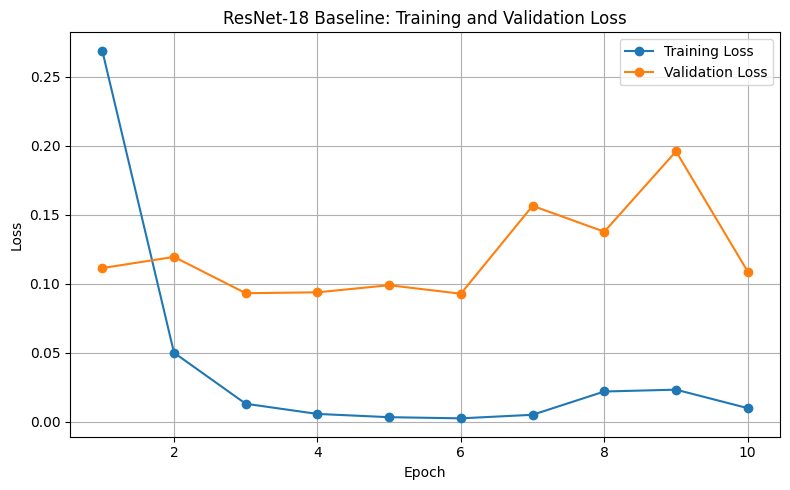

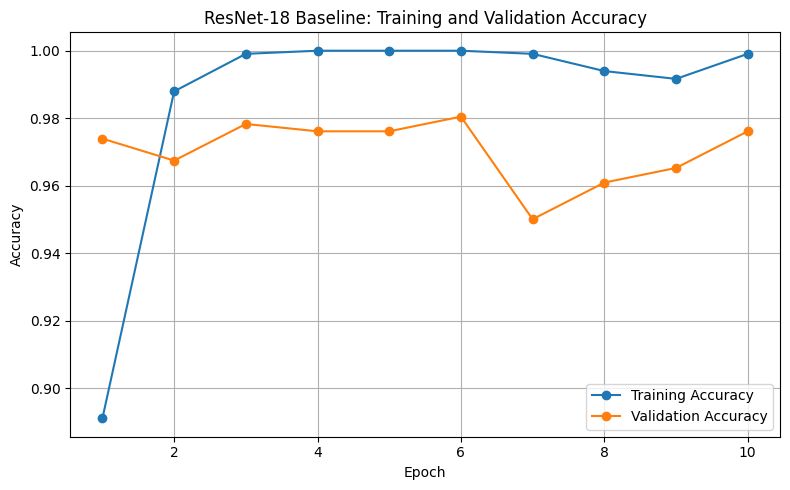

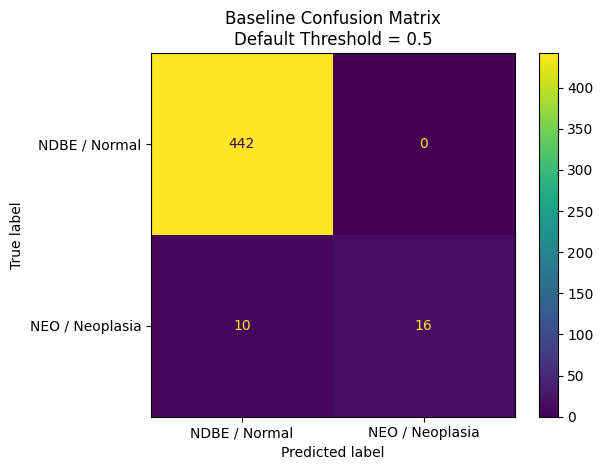

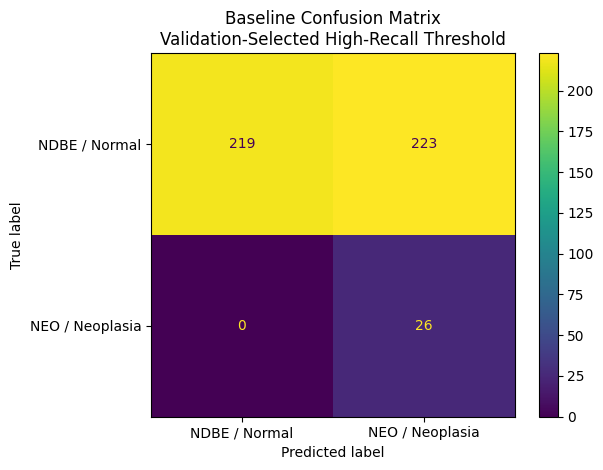

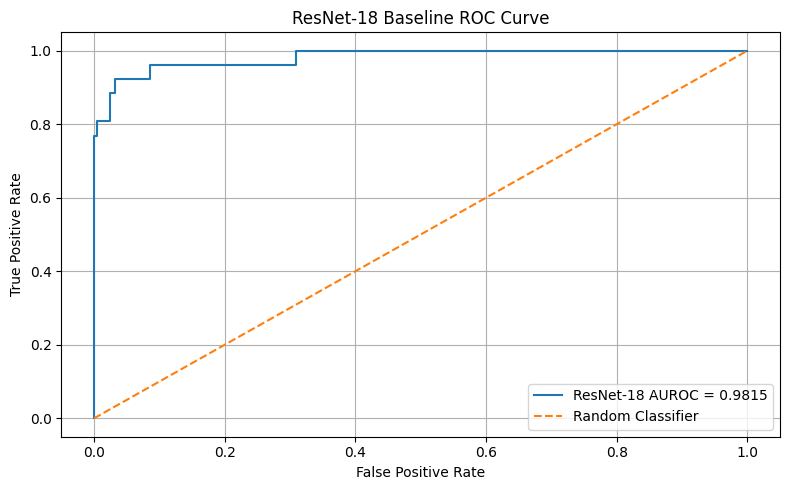

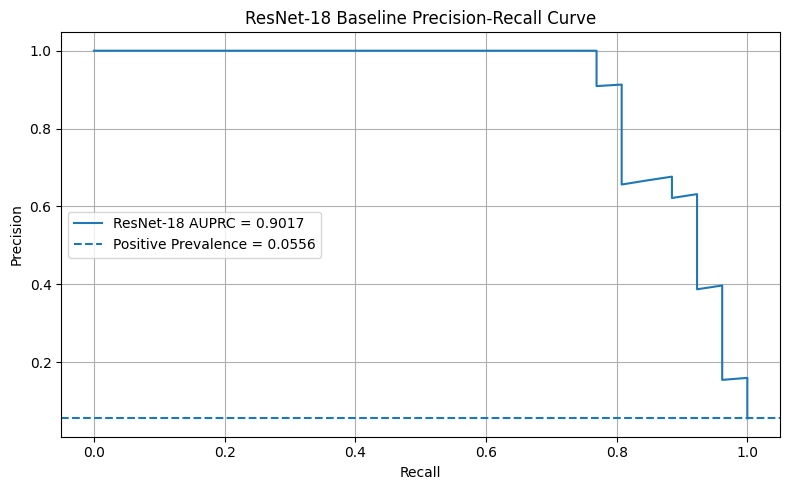

ALL BASELINE FIGURES CREATED
Loss curve:
/content/drive/MyDrive/RARE26/results/figures/baseline_loss_curve.png

Accuracy curve:
/content/drive/MyDrive/RARE26/results/figures/baseline_accuracy_curve.png

Default confusion matrix:
/content/drive/MyDrive/RARE26/results/figures/baseline_confusion_matrix_default.png

High-recall confusion matrix:
/content/drive/MyDrive/RARE26/results/figures/baseline_confusion_matrix_high_recall.png

ROC curve:
/content/drive/MyDrive/RARE26/results/figures/baseline_roc_curve.png

Precision-Recall curve:
/content/drive/MyDrive/RARE26/results/figures/baseline_precision_recall_curve.png


In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
)

# Saved files ke paths
results_folder = Path(
    "/content/drive/MyDrive/RARE26/results"
)

history_path = (
    results_folder / "resnet18_baseline_history.csv"
)

metrics_path = (
    results_folder / "resnet18_baseline_test_metrics.csv"
)

predictions_path = (
    results_folder / "resnet18_baseline_test_predictions.csv"
)

# Figures ke liye separate folder
figures_folder = results_folder / "figures"
figures_folder.mkdir(
    parents=True,
    exist_ok=True
)

# Files read karna
history_df = pd.read_csv(history_path)
metrics_df = pd.read_csv(metrics_path)
predictions_df = pd.read_csv(predictions_path)

# True labels aur probabilities
true_labels = (
    predictions_df["true_label"]
    .astype(int)
    .to_numpy()
)

probabilities = (
    predictions_df["neoplasia_probability"]
    .astype(float)
    .to_numpy()
)

# Saved thresholds read karna
default_threshold = float(
    metrics_df.loc[
        metrics_df["evaluation"] == "default_threshold",
        "threshold"
    ].iloc[0]
)

high_recall_threshold = float(
    metrics_df.loc[
        metrics_df["evaluation"]
        == "validation_selected_90_recall",
        "threshold"
    ].iloc[0]
)

default_predictions = (
    probabilities >= default_threshold
).astype(int)

high_recall_predictions = (
    probabilities >= high_recall_threshold
).astype(int)


# -----------------------------------
# 1. Training and validation loss
# -----------------------------------
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet-18 Baseline: Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()

loss_path = (
    figures_folder / "baseline_loss_curve.png"
)

plt.savefig(
    loss_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# -----------------------------------
# 2. Training and validation accuracy
# -----------------------------------
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ResNet-18 Baseline: Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()

accuracy_path = (
    figures_folder / "baseline_accuracy_curve.png"
)

plt.savefig(
    accuracy_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# -----------------------------------
# 3. Default threshold confusion matrix
# -----------------------------------
default_cm = confusion_matrix(
    true_labels,
    default_predictions,
    labels=[0, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=default_cm,
    display_labels=[
        "NDBE / Normal",
        "NEO / Neoplasia"
    ]
)

display.plot(
    values_format="d"
)

plt.title(
    "Baseline Confusion Matrix\nDefault Threshold = 0.5"
)

plt.tight_layout()

default_cm_path = (
    figures_folder
    / "baseline_confusion_matrix_default.png"
)

plt.savefig(
    default_cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# -----------------------------------
# 4. High-recall confusion matrix
# -----------------------------------
high_recall_cm = confusion_matrix(
    true_labels,
    high_recall_predictions,
    labels=[0, 1]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=high_recall_cm,
    display_labels=[
        "NDBE / Normal",
        "NEO / Neoplasia"
    ]
)

display.plot(
    values_format="d"
)

plt.title(
    "Baseline Confusion Matrix\n"
    "Validation-Selected High-Recall Threshold"
)

plt.tight_layout()

high_recall_cm_path = (
    figures_folder
    / "baseline_confusion_matrix_high_recall.png"
)

plt.savefig(
    high_recall_cm_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# -----------------------------------
# 5. ROC curve
# -----------------------------------
false_positive_rate, true_positive_rate, _ = roc_curve(
    true_labels,
    probabilities
)

test_auroc = roc_auc_score(
    true_labels,
    probabilities
)

plt.figure(figsize=(8, 5))

plt.plot(
    false_positive_rate,
    true_positive_rate,
    label=f"ResNet-18 AUROC = {test_auroc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ResNet-18 Baseline ROC Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()

roc_path = (
    figures_folder / "baseline_roc_curve.png"
)

plt.savefig(
    roc_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# -----------------------------------
# 6. Precision-Recall curve
# -----------------------------------
precision_values, recall_values, _ = (
    precision_recall_curve(
        true_labels,
        probabilities
    )
)

test_auprc = average_precision_score(
    true_labels,
    probabilities
)

positive_prevalence = true_labels.mean()

plt.figure(figsize=(8, 5))

plt.plot(
    recall_values,
    precision_values,
    label=f"ResNet-18 AUPRC = {test_auprc:.4f}"
)

plt.axhline(
    positive_prevalence,
    linestyle="--",
    label=f"Positive Prevalence = {positive_prevalence:.4f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("ResNet-18 Baseline Precision-Recall Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()

pr_path = (
    figures_folder
    / "baseline_precision_recall_curve.png"
)

plt.savefig(
    pr_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


print("=" * 60)
print("ALL BASELINE FIGURES CREATED")
print("=" * 60)

print("Loss curve:")
print(loss_path)

print("\nAccuracy curve:")
print(accuracy_path)

print("\nDefault confusion matrix:")
print(default_cm_path)

print("\nHigh-recall confusion matrix:")
print(high_recall_cm_path)

print("\nROC curve:")
print(roc_path)

print("\nPrecision-Recall curve:")
print(pr_path)

In [ ]:
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torchvision.models import (
    resnet18,
    ResNet18_Weights
)

# Reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# Training class counts
train_df = pd.read_csv(
    "/content/drive/MyDrive/RARE26/splits/train_colab.csv"
)

normal_count = int(
    (train_df["label"] == 0).sum()
)

neo_count = int(
    (train_df["label"] == 1).sum()
)

total_count = normal_count + neo_count

# Balanced class weights
normal_weight = total_count / (2 * normal_count)
neo_weight = total_count / (2 * neo_count)

class_weights = torch.tensor(
    [normal_weight, neo_weight],
    dtype=torch.float32,
    device=device
)

print("Normal images:", normal_count)
print("Neoplasia images:", neo_count)
print("Normal class weight:", normal_weight)
print("Neoplasia class weight:", neo_weight)
print("Weight ratio:", neo_weight / normal_weight)

# Fresh ImageNet-pretrained ResNet-18
weighted_model = resnet18(
    weights=ResNet18_Weights.DEFAULT
)

weighted_model.fc = nn.Linear(
    weighted_model.fc.in_features,
    2
)

weighted_model = weighted_model.to(device)

# Weighted Cross-Entropy Loss
weighted_criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

weighted_optimizer = torch.optim.AdamW(
    weighted_model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

# Save paths
weighted_best_model_path = Path(
    "/content/drive/MyDrive/RARE26/models/"
    "resnet18_weighted_best.pth"
)

weighted_latest_model_path = Path(
    "/content/drive/MyDrive/RARE26/models/"
    "resnet18_weighted_latest.pth"
)

weighted_history_path = Path(
    "/content/drive/MyDrive/RARE26/results/"
    "resnet18_weighted_history.csv"
)

num_epochs = 10
best_weighted_val_auprc = -1.0
weighted_history = []


def evaluate_weighted_model(
    model,
    data_loader,
    criterion,
    device
):
    model.eval()

    total_loss = 0.0
    all_labels = []
    all_probabilities = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = model(images)
            loss = criterion(outputs, labels)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            total_loss += (
                loss.item() * images.size(0)
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_probabilities.extend(
                probabilities.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    average_loss = (
        total_loss / len(data_loader.dataset)
    )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    precision = precision_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_predictions,
        zero_division=0
    )

    auroc = roc_auc_score(
        all_labels,
        all_probabilities
    )

    auprc = average_precision_score(
        all_labels,
        all_probabilities
    )

    return {
        "loss": average_loss,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "auroc": auroc,
        "auprc": auprc,
    }


print("\nWeighted-loss training start ho rahi hai...")
print("=" * 75)

for epoch in range(1, num_epochs + 1):
    start_time = time.time()

    weighted_model.train()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for images, labels in train_loader:
        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        weighted_optimizer.zero_grad()

        outputs = weighted_model(images)

        loss = weighted_criterion(
            outputs,
            labels
        )

        loss.backward()
        weighted_optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct_predictions += (
            predictions == labels
        ).sum().item()

        total_samples += labels.size(0)

    train_loss = (
        running_loss / total_samples
    )

    train_accuracy = (
        correct_predictions / total_samples
    )

    validation_metrics = evaluate_weighted_model(
        weighted_model,
        validation_loader,
        weighted_criterion,
        device
    )

    epoch_time = time.time() - start_time

    epoch_record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": validation_metrics["loss"],
        "val_accuracy": validation_metrics["accuracy"],
        "val_precision": validation_metrics["precision"],
        "val_recall": validation_metrics["recall"],
        "val_auroc": validation_metrics["auroc"],
        "val_auprc": validation_metrics["auprc"],
        "epoch_seconds": epoch_time,
    }

    weighted_history.append(epoch_record)

    pd.DataFrame(
        weighted_history
    ).to_csv(
        weighted_history_path,
        index=False
    )

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict":
                weighted_model.state_dict(),
            "optimizer_state_dict":
                weighted_optimizer.state_dict(),
            "validation_metrics":
                validation_metrics,
            "class_weights":
                class_weights.cpu(),
        },
        weighted_latest_model_path
    )

    if (
        validation_metrics["auprc"]
        > best_weighted_val_auprc
    ):
        best_weighted_val_auprc = (
            validation_metrics["auprc"]
        )

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict":
                    weighted_model.state_dict(),
                "optimizer_state_dict":
                    weighted_optimizer.state_dict(),
                "validation_metrics":
                    validation_metrics,
                "class_weights":
                    class_weights.cpu(),
            },
            weighted_best_model_path
        )

        best_message = "  <-- Best weighted model saved"

    else:
        best_message = ""

    print(
        f"Epoch {epoch:02d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {validation_metrics['loss']:.4f} | "
        f"Recall: {validation_metrics['recall']:.4f} | "
        f"Precision: {validation_metrics['precision']:.4f} | "
        f"AUROC: {validation_metrics['auroc']:.4f} | "
        f"AUPRC: {validation_metrics['auprc']:.4f} | "
        f"Time: {epoch_time:.1f}s"
        f"{best_message}"
    )

print("=" * 75)
print("Weighted-loss training complete.")
print(
    "Best weighted validation AUPRC:",
    round(best_weighted_val_auprc, 4)
)

print("\nBest weighted model saved at:")
print(weighted_best_model_path)

print("\nWeighted history saved at:")
print(weighted_history_path)

Device: cuda
Normal images: 2050
Neoplasia images: 109
Normal class weight: 0.5265853658536586
Neoplasia class weight: 9.903669724770642
Weight ratio: 18.807339449541285

Weighted-loss training start ho rahi hai...
Epoch 01/10 | Train Loss: 0.5831 | Val Loss: 0.3344 | Recall: 0.6957 | Precision: 0.2500 | AUROC: 0.8842 | AUPRC: 0.5791 | Time: 33.6s  <-- Best weighted model saved
Epoch 02/10 | Train Loss: 0.1506 | Val Loss: 0.1913 | Recall: 0.5652 | Precision: 0.8125 | AUROC: 0.8954 | AUPRC: 0.7227 | Time: 36.2s  <-- Best weighted model saved
Epoch 03/10 | Train Loss: 0.0306 | Val Loss: 0.2081 | Recall: 0.5652 | Precision: 0.8667 | AUROC: 0.8884 | AUPRC: 0.7102 | Time: 39.1s
Epoch 04/10 | Train Loss: 0.0129 | Val Loss: 0.2018 | Recall: 0.5652 | Precision: 0.8667 | AUROC: 0.9133 | AUPRC: 0.7434 | Time: 36.7s  <-- Best weighted model saved
Epoch 05/10 | Train Loss: 0.0079 | Val Loss: 0.2169 | Recall: 0.6087 | Precision: 0.8750 | AUROC: 0.9091 | AUPRC: 0.7287 | Time: 40.3s
Epoch 06/10 | Tra

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torchvision.models import resnet18
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Weighted model path
weighted_model_path = Path(
    "/content/drive/MyDrive/RARE26/models/"
    "resnet18_weighted_best.pth"
)

# Model create karna
weighted_best_model = resnet18(weights=None)

weighted_best_model.fc = nn.Linear(
    weighted_best_model.fc.in_features,
    2
)

# Trusted checkpoint load karna
weighted_checkpoint = torch.load(
    weighted_model_path,
    map_location=device,
    weights_only=False
)

weighted_best_model.load_state_dict(
    weighted_checkpoint["model_state_dict"]
)

weighted_best_model = weighted_best_model.to(device)
weighted_best_model.eval()

print("Best weighted checkpoint epoch:", weighted_checkpoint["epoch"])
print(
    "Saved weighted validation AUPRC:",
    weighted_checkpoint["validation_metrics"]["auprc"]
)


def collect_model_predictions(
    model,
    data_loader,
    device
):
    labels_list = []
    probabilities_list = []

    model.eval()

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            labels_list.extend(
                labels.cpu().numpy()
            )

            probabilities_list.extend(
                probabilities.cpu().numpy()
            )

    return (
        np.array(labels_list),
        np.array(probabilities_list)
    )


def get_metrics(
    labels,
    probabilities,
    threshold
):
    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    return {
        "threshold": float(threshold),
        "accuracy": float(
            accuracy_score(labels, predictions)
        ),
        "precision": float(
            precision_score(
                labels,
                predictions,
                zero_division=0
            )
        ),
        "recall": float(
            recall_score(
                labels,
                predictions,
                zero_division=0
            )
        ),
        "specificity": float(specificity),
        "auroc": float(
            roc_auc_score(
                labels,
                probabilities
            )
        ),
        "auprc": float(
            average_precision_score(
                labels,
                probabilities
            )
        ),
        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp),
    }


# Validation predictions
weighted_val_labels, weighted_val_probs = (
    collect_model_predictions(
        weighted_best_model,
        validation_loader,
        device
    )
)

# Test predictions
weighted_test_labels, weighted_test_probs = (
    collect_model_predictions(
        weighted_best_model,
        test_loader,
        device
    )
)

# Validation par 90% recall threshold select karna
precision_values, recall_values, thresholds = (
    precision_recall_curve(
        weighted_val_labels,
        weighted_val_probs
    )
)

valid_indices = np.where(
    recall_values[:-1] >= 0.90
)[0]

if len(valid_indices) > 0:
    best_index = valid_indices[
        np.argmax(
            precision_values[:-1][valid_indices]
        )
    ]

    weighted_recall90_threshold = float(
        thresholds[best_index]
    )

    validation_precision_target = float(
        precision_values[best_index]
    )

    validation_recall_target = float(
        recall_values[best_index]
    )

else:
    weighted_recall90_threshold = 0.5
    validation_precision_target = 0.0
    validation_recall_target = 0.0


print("\nVALIDATION THRESHOLD SELECTION")
print(
    "Selected threshold:",
    weighted_recall90_threshold
)
print(
    "Validation recall:",
    validation_recall_target
)
print(
    "Validation precision:",
    validation_precision_target
)

# Default threshold test metrics
weighted_default_metrics = get_metrics(
    weighted_test_labels,
    weighted_test_probs,
    threshold=0.5
)

# High-recall threshold test metrics
weighted_recall90_metrics = get_metrics(
    weighted_test_labels,
    weighted_test_probs,
    threshold=weighted_recall90_threshold
)

print("\n" + "=" * 65)
print("WEIGHTED MODEL TEST RESULTS: DEFAULT THRESHOLD")
print("=" * 65)

for key, value in weighted_default_metrics.items():
    print(f"{key}: {value}")

print("\n" + "=" * 65)
print("WEIGHTED MODEL TEST RESULTS: HIGH-RECALL THRESHOLD")
print("=" * 65)

for key, value in weighted_recall90_metrics.items():
    print(f"{key}: {value}")

# Save weighted metrics
weighted_results_df = pd.DataFrame([
    {
        "evaluation": "default_threshold",
        **weighted_default_metrics
    },
    {
        "evaluation": "validation_selected_90_recall",
        **weighted_recall90_metrics
    }
])

weighted_results_path = Path(
    "/content/drive/MyDrive/RARE26/results/"
    "resnet18_weighted_test_metrics.csv"
)

weighted_results_df.to_csv(
    weighted_results_path,
    index=False
)

# Save weighted predictions
weighted_predictions_df = pd.DataFrame({
    "true_label": weighted_test_labels,
    "neoplasia_probability": weighted_test_probs,
})

weighted_predictions_path = Path(
    "/content/drive/MyDrive/RARE26/results/"
    "resnet18_weighted_test_predictions.csv"
)

weighted_predictions_df.to_csv(
    weighted_predictions_path,
    index=False
)

print("\nWeighted results saved at:")
print(weighted_results_path)

print("\nWeighted predictions saved at:")
print(weighted_predictions_path)

Best weighted checkpoint epoch: 9
Saved weighted validation AUPRC: 0.7454331419346343

VALIDATION THRESHOLD SELECTION
Selected threshold: 0.0030609802342951298
Validation recall: 0.9130434782608695
Validation precision: 0.13815789473684212

WEIGHTED MODEL TEST RESULTS: DEFAULT THRESHOLD
threshold: 0.5
accuracy: 0.9722222222222222
precision: 1.0
recall: 0.5
specificity: 1.0
auroc: 0.9728506787330317
auprc: 0.8302878128637701
true_negatives: 442
false_positives: 0
false_negatives: 13
true_positives: 13

WEIGHTED MODEL TEST RESULTS: HIGH-RECALL THRESHOLD
threshold: 0.0030609802342951298
accuracy: 0.7243589743589743
precision: 0.16774193548387098
recall: 1.0
specificity: 0.7081447963800905
auroc: 0.9728506787330317
auprc: 0.8302878128637701
true_negatives: 313
false_positives: 129
false_negatives: 0
true_positives: 26

Weighted results saved at:
/content/drive/MyDrive/RARE26/results/resnet18_weighted_test_metrics.csv

Weighted predictions saved at:
/content/drive/MyDrive/RARE26/results/res

In [ ]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Google Drive results folder
results_folder = Path(
    "/content/drive/MyDrive/RARE26/results"
)

figures_folder = results_folder / "figures"
figures_folder.mkdir(
    parents=True,
    exist_ok=True
)

# Saved result files
baseline_metrics_path = (
    results_folder
    / "resnet18_baseline_test_metrics.csv"
)

weighted_metrics_path = (
    results_folder
    / "resnet18_weighted_test_metrics.csv"
)

# Files read karna
baseline_df = pd.read_csv(
    baseline_metrics_path
)

weighted_df = pd.read_csv(
    weighted_metrics_path
)

# Model name add karna
baseline_df["model"] = "Baseline ResNet-18"
weighted_df["model"] = "Weighted ResNet-18"

# Dono results combine karna
comparison_df = pd.concat(
    [baseline_df, weighted_df],
    ignore_index=True
)

# Columns arrange karna
comparison_df = comparison_df[
    [
        "model",
        "evaluation",
        "threshold",
        "accuracy",
        "precision",
        "recall",
        "specificity",
        "auroc",
        "auprc",
        "true_negatives",
        "false_positives",
        "false_negatives",
        "true_positives",
    ]
]

# Comparison CSV save karna
comparison_path = (
    results_folder
    / "baseline_vs_weighted_comparison.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)

print("=" * 70)
print("COMPLETE COMPARISON TABLE")
print("=" * 70)

display(comparison_df)


# High-recall results alag karna
high_recall_df = comparison_df[
    comparison_df["evaluation"]
    == "validation_selected_90_recall"
].copy()

high_recall_df = high_recall_df.set_index(
    "model"
)


# -----------------------------------
# Graph 1: Precision and specificity
# -----------------------------------
high_recall_df[
    ["precision", "specificity"]
].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title(
    "Baseline vs Weighted Model at High Recall"
)

plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(
    ["Precision / PPV", "Specificity"]
)
plt.grid(
    axis="y",
    alpha=0.3
)
plt.tight_layout()

score_graph_path = (
    figures_folder
    / "baseline_vs_weighted_high_recall_scores.png"
)

plt.savefig(
    score_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# -----------------------------------
# Graph 2: False positives
# -----------------------------------
high_recall_df[
    ["false_positives"]
].plot(
    kind="bar",
    figsize=(8, 5),
    legend=False
)

plt.title(
    "False Positives at High-Recall Threshold"
)

plt.xlabel("Model")
plt.ylabel("Number of False Positives")
plt.xticks(rotation=0)
plt.grid(
    axis="y",
    alpha=0.3
)
plt.tight_layout()

fp_graph_path = (
    figures_folder
    / "baseline_vs_weighted_false_positives.png"
)

plt.savefig(
    fp_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# -----------------------------------
# Graph 3: AUROC and AUPRC
# -----------------------------------
default_df = comparison_df[
    comparison_df["evaluation"]
    == "default_threshold"
].copy()

default_df = default_df.set_index(
    "model"
)

default_df[
    ["auroc", "auprc"]
].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title(
    "Overall Ranking Performance"
)

plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(
    ["AUROC", "AUPRC"]
)
plt.grid(
    axis="y",
    alpha=0.3
)
plt.tight_layout()

ranking_graph_path = (
    figures_folder
    / "baseline_vs_weighted_auroc_auprc.png"
)

plt.savefig(
    ranking_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# Improvement calculations
baseline_high = high_recall_df.loc[
    "Baseline ResNet-18"
]

weighted_high = high_recall_df.loc[
    "Weighted ResNet-18"
]

false_positive_reduction = (
    baseline_high["false_positives"]
    - weighted_high["false_positives"]
)

false_positive_reduction_percent = (
    false_positive_reduction
    / baseline_high["false_positives"]
    * 100
)

ppv_relative_improvement = (
    (
        weighted_high["precision"]
        - baseline_high["precision"]
    )
    / baseline_high["precision"]
    * 100
)

print("\n" + "=" * 70)
print("HIGH-RECALL IMPROVEMENT SUMMARY")
print("=" * 70)

print(
    "Baseline false positives:",
    int(baseline_high["false_positives"])
)

print(
    "Weighted false positives:",
    int(weighted_high["false_positives"])
)

print(
    "False positives reduced by:",
    int(false_positive_reduction)
)

print(
    "False-positive reduction percentage:",
    round(false_positive_reduction_percent, 2),
    "%"
)

print(
    "Baseline PPV:",
    round(baseline_high["precision"], 4)
)

print(
    "Weighted PPV:",
    round(weighted_high["precision"], 4)
)

print(
    "Relative PPV improvement:",
    round(ppv_relative_improvement, 2),
    "%"
)

print("\nFiles saved:")

print(comparison_path)
print(score_graph_path)
print(fp_graph_path)
print(ranking_graph_path)

COMPLETE COMPARISON TABLE


TypeError: 'ConfusionMatrixDisplay' object is not callable

COMPLETE COMPARISON TABLE


,model,evaluation,threshold,accuracy,precision,recall,specificity,auroc,auprc,true_negatives,false_positives,false_negatives,true_positives
0,Baseline ResNet-18,default_threshold,0.500000,0.978632,1.000000,0.615385,1.000000,0.981465,0.901696,442,0,10,16
1,Baseline ResNet-18,validation_selected_90_recall,0.001840,0.523504,0.104418,1.000000,0.495475,0.981465,0.901696,219,223,0,26
2,Weighted ResNet-18,default_threshold,0.500000,0.972222,1.000000,0.500000,1.000000,0.972851,0.830288,442,0,13,13
3,Weighted ResNet-18,validation_selected_90_recall,0.003061,0.724359,0.167742,1.000000,0.708145,0.972851,0.830288,313,129,0,26


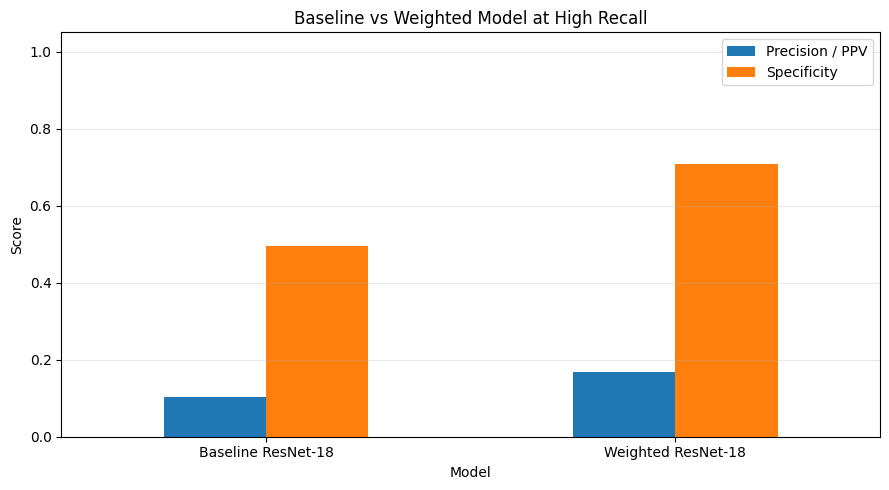

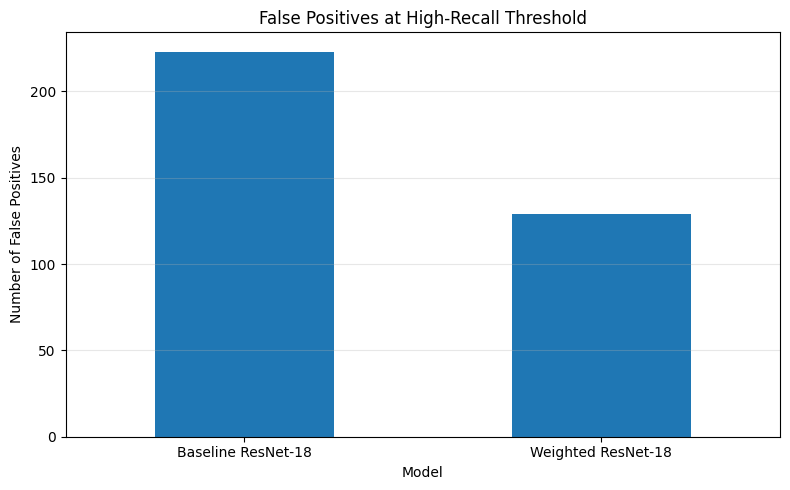

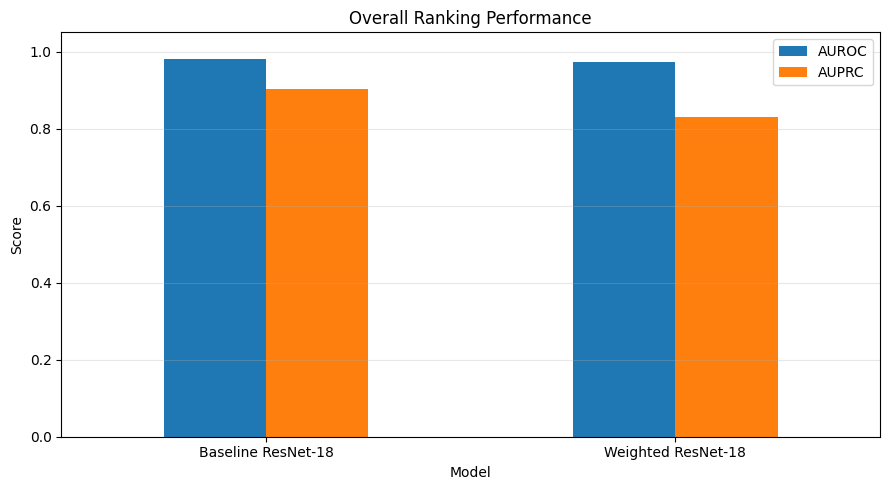


HIGH-RECALL IMPROVEMENT SUMMARY
Baseline false positives: 223
Weighted false positives: 129
False positives reduced by: 94
False-positive reduction percentage: 42.15 %
Baseline PPV: 0.1044
Weighted PPV: 0.1677
Relative PPV improvement: 60.65 %

Files saved:
/content/drive/MyDrive/RARE26/results/baseline_vs_weighted_comparison.csv
/content/drive/MyDrive/RARE26/results/figures/baseline_vs_weighted_high_recall_scores.png
/content/drive/MyDrive/RARE26/results/figures/baseline_vs_weighted_false_positives.png
/content/drive/MyDrive/RARE26/results/figures/baseline_vs_weighted_auroc_auprc.png


In [ ]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display as show_table


# Google Drive folders
results_folder = Path(
    "/content/drive/MyDrive/RARE26/results"
)

figures_folder = results_folder / "figures"

figures_folder.mkdir(
    parents=True,
    exist_ok=True
)


# Saved metrics files
baseline_metrics_path = (
    results_folder
    / "resnet18_baseline_test_metrics.csv"
)

weighted_metrics_path = (
    results_folder
    / "resnet18_weighted_test_metrics.csv"
)


# Files read karna
baseline_df = pd.read_csv(
    baseline_metrics_path
)

weighted_df = pd.read_csv(
    weighted_metrics_path
)


# Model names add karna
baseline_df["model"] = "Baseline ResNet-18"
weighted_df["model"] = "Weighted ResNet-18"


# Dono results combine karna
comparison_df = pd.concat(
    [baseline_df, weighted_df],
    ignore_index=True
)


# Columns arrange karna
comparison_df = comparison_df[
    [
        "model",
        "evaluation",
        "threshold",
        "accuracy",
        "precision",
        "recall",
        "specificity",
        "auroc",
        "auprc",
        "true_negatives",
        "false_positives",
        "false_negatives",
        "true_positives",
    ]
]


# Comparison CSV save karna
comparison_path = (
    results_folder
    / "baseline_vs_weighted_comparison.csv"
)

comparison_df.to_csv(
    comparison_path,
    index=False
)


print("=" * 70)
print("COMPLETE COMPARISON TABLE")
print("=" * 70)

show_table(comparison_df)


# High-recall results
high_recall_df = comparison_df[
    comparison_df["evaluation"]
    == "validation_selected_90_recall"
].copy()

high_recall_df = high_recall_df.set_index(
    "model"
)


# -----------------------------------
# Graph 1: Precision and specificity
# -----------------------------------
high_recall_df[
    ["precision", "specificity"]
].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title(
    "Baseline vs Weighted Model at High Recall"
)

plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)

plt.legend(
    ["Precision / PPV", "Specificity"]
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

score_graph_path = (
    figures_folder
    / "baseline_vs_weighted_high_recall_scores.png"
)

plt.savefig(
    score_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# -----------------------------------
# Graph 2: False positives
# -----------------------------------
high_recall_df[
    ["false_positives"]
].plot(
    kind="bar",
    figsize=(8, 5),
    legend=False
)

plt.title(
    "False Positives at High-Recall Threshold"
)

plt.xlabel("Model")
plt.ylabel("Number of False Positives")
plt.xticks(rotation=0)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

fp_graph_path = (
    figures_folder
    / "baseline_vs_weighted_false_positives.png"
)

plt.savefig(
    fp_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# -----------------------------------
# Graph 3: AUROC and AUPRC
# -----------------------------------
default_df = comparison_df[
    comparison_df["evaluation"]
    == "default_threshold"
].copy()

default_df = default_df.set_index(
    "model"
)

default_df[
    ["auroc", "auprc"]
].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title(
    "Overall Ranking Performance"
)

plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)

plt.legend(
    ["AUROC", "AUPRC"]
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

ranking_graph_path = (
    figures_folder
    / "baseline_vs_weighted_auroc_auprc.png"
)

plt.savefig(
    ranking_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# Improvement calculations
baseline_high = high_recall_df.loc[
    "Baseline ResNet-18"
]

weighted_high = high_recall_df.loc[
    "Weighted ResNet-18"
]

false_positive_reduction = (
    baseline_high["false_positives"]
    - weighted_high["false_positives"]
)

false_positive_reduction_percent = (
    false_positive_reduction
    / baseline_high["false_positives"]
    * 100
)

ppv_relative_improvement = (
    (
        weighted_high["precision"]
        - baseline_high["precision"]
    )
    / baseline_high["precision"]
    * 100
)


print("\n" + "=" * 70)
print("HIGH-RECALL IMPROVEMENT SUMMARY")
print("=" * 70)

print(
    "Baseline false positives:",
    int(baseline_high["false_positives"])
)

print(
    "Weighted false positives:",
    int(weighted_high["false_positives"])
)

print(
    "False positives reduced by:",
    int(false_positive_reduction)
)

print(
    "False-positive reduction percentage:",
    round(
        false_positive_reduction_percent,
        2
    ),
    "%"
)

print(
    "Baseline PPV:",
    round(
        baseline_high["precision"],
        4
    )
)

print(
    "Weighted PPV:",
    round(
        weighted_high["precision"],
        4
    )
)

print(
    "Relative PPV improvement:",
    round(
        ppv_relative_improvement,
        2
    ),
    "%"
)


print("\nFiles saved:")

print(comparison_path)
print(score_graph_path)
print(fp_graph_path)
print(ranking_graph_path)

In [ ]:
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torchvision.models import (
    resnet18,
    ResNet18_Weights
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
)

# -------------------------------------------------
# Reproducibility
# -------------------------------------------------
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# -------------------------------------------------
# Same training class weights
# -------------------------------------------------
train_df = pd.read_csv(
    "/content/drive/MyDrive/RARE26/splits/train_colab.csv"
)

normal_count = int(
    (train_df["label"] == 0).sum()
)

neo_count = int(
    (train_df["label"] == 1).sum()
)

total_count = normal_count + neo_count

normal_weight = total_count / (2 * normal_count)
neo_weight = total_count / (2 * neo_count)

focal_class_weights = torch.tensor(
    [normal_weight, neo_weight],
    dtype=torch.float32,
    device=device
)

print("Normal images:", normal_count)
print("Neoplasia images:", neo_count)
print("Normal weight:", normal_weight)
print("Neoplasia weight:", neo_weight)


# -------------------------------------------------
# Focal Loss definition
# -------------------------------------------------
class FocalLoss(nn.Module):
    def __init__(
        self,
        class_weights=None,
        gamma=2.0
    ):
        super().__init__()

        self.class_weights = class_weights
        self.gamma = gamma

    def forward(self, outputs, targets):
        cross_entropy = nn.functional.cross_entropy(
            outputs,
            targets,
            weight=self.class_weights,
            reduction="none"
        )

        probabilities_of_correct_class = torch.exp(
            -cross_entropy
        )

        focal_factor = (
            1 - probabilities_of_correct_class
        ) ** self.gamma

        focal_loss = focal_factor * cross_entropy

        return focal_loss.mean()


# -------------------------------------------------
# Fresh ResNet-18
# -------------------------------------------------
focal_model = resnet18(
    weights=ResNet18_Weights.DEFAULT
)

focal_model.fc = nn.Linear(
    focal_model.fc.in_features,
    2
)

focal_model = focal_model.to(device)


# Same weights + focal focusing factor
focal_criterion = FocalLoss(
    class_weights=focal_class_weights,
    gamma=2.0
)

focal_optimizer = torch.optim.AdamW(
    focal_model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)


# -------------------------------------------------
# Save paths
# -------------------------------------------------
focal_best_model_path = Path(
    "/content/drive/MyDrive/RARE26/models/"
    "resnet18_focal_best.pth"
)

focal_latest_model_path = Path(
    "/content/drive/MyDrive/RARE26/models/"
    "resnet18_focal_latest.pth"
)

focal_history_path = Path(
    "/content/drive/MyDrive/RARE26/results/"
    "resnet18_focal_history.csv"
)


# -------------------------------------------------
# Evaluation function
# -------------------------------------------------
def evaluate_focal_model(
    model,
    data_loader,
    criterion,
    device
):
    model.eval()

    total_loss = 0.0
    all_labels = []
    all_probabilities = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = model(images)
            loss = criterion(outputs, labels)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            total_loss += (
                loss.item() * images.size(0)
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_probabilities.extend(
                probabilities.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    average_loss = (
        total_loss / len(data_loader.dataset)
    )

    return {
        "loss": average_loss,

        "accuracy": accuracy_score(
            all_labels,
            all_predictions
        ),

        "precision": precision_score(
            all_labels,
            all_predictions,
            zero_division=0
        ),

        "recall": recall_score(
            all_labels,
            all_predictions,
            zero_division=0
        ),

        "auroc": roc_auc_score(
            all_labels,
            all_probabilities
        ),

        "auprc": average_precision_score(
            all_labels,
            all_probabilities
        ),
    }


# -------------------------------------------------
# Training
# -------------------------------------------------
num_epochs = 10
best_focal_val_auprc = -1.0
focal_history = []

print("\nFocal-loss training start ho rahi hai...")
print("=" * 75)

for epoch in range(1, num_epochs + 1):
    start_time = time.time()

    focal_model.train()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for images, labels in train_loader:
        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        focal_optimizer.zero_grad()

        outputs = focal_model(images)

        loss = focal_criterion(
            outputs,
            labels
        )

        loss.backward()
        focal_optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct_predictions += (
            predictions == labels
        ).sum().item()

        total_samples += labels.size(0)

    train_loss = (
        running_loss / total_samples
    )

    train_accuracy = (
        correct_predictions / total_samples
    )

    validation_metrics = evaluate_focal_model(
        focal_model,
        validation_loader,
        focal_criterion,
        device
    )

    epoch_time = time.time() - start_time

    epoch_record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": validation_metrics["loss"],
        "val_accuracy": validation_metrics["accuracy"],
        "val_precision": validation_metrics["precision"],
        "val_recall": validation_metrics["recall"],
        "val_auroc": validation_metrics["auroc"],
        "val_auprc": validation_metrics["auprc"],
        "epoch_seconds": epoch_time,
    }

    focal_history.append(epoch_record)

    # History permanently Drive mein save
    pd.DataFrame(
        focal_history
    ).to_csv(
        focal_history_path,
        index=False
    )

    # Latest checkpoint
    torch.save(
        {
            "epoch": epoch,
            "model_state_dict":
                focal_model.state_dict(),
            "optimizer_state_dict":
                focal_optimizer.state_dict(),
            "validation_metrics":
                validation_metrics,
            "class_weights":
                focal_class_weights.cpu(),
            "gamma": 2.0,
        },
        focal_latest_model_path
    )

    # Best checkpoint
    if (
        validation_metrics["auprc"]
        > best_focal_val_auprc
    ):
        best_focal_val_auprc = (
            validation_metrics["auprc"]
        )

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict":
                    focal_model.state_dict(),
                "optimizer_state_dict":
                    focal_optimizer.state_dict(),
                "validation_metrics":
                    validation_metrics,
                "class_weights":
                    focal_class_weights.cpu(),
                "gamma": 2.0,
            },
            focal_best_model_path
        )

        best_message = "  <-- Best focal model saved"

    else:
        best_message = ""

    print(
        f"Epoch {epoch:02d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {validation_metrics['loss']:.4f} | "
        f"Recall: {validation_metrics['recall']:.4f} | "
        f"Precision: {validation_metrics['precision']:.4f} | "
        f"AUROC: {validation_metrics['auroc']:.4f} | "
        f"AUPRC: {validation_metrics['auprc']:.4f} | "
        f"Time: {epoch_time:.1f}s"
        f"{best_message}"
    )

print("=" * 75)
print("Focal-loss training complete.")

print(
    "Best focal validation AUPRC:",
    round(best_focal_val_auprc, 4)
)

print("\nBest focal model saved at:")
print(focal_best_model_path)

print("\nFocal history saved at:")
print(focal_history_path)

Device: cuda
Normal images: 2050
Neoplasia images: 109
Normal weight: 0.5265853658536586
Neoplasia weight: 9.903669724770642

Focal-loss training start ho rahi hai...
Epoch 01/10 | Train Loss: 0.2580 | Val Loss: 0.2623 | Recall: 0.7391 | Precision: 0.1149 | AUROC: 0.8079 | AUPRC: 0.4923 | Time: 35.9s  <-- Best focal model saved
Epoch 02/10 | Train Loss: 0.0414 | Val Loss: 0.2432 | Recall: 0.7391 | Precision: 0.3333 | AUROC: 0.8961 | AUPRC: 0.6702 | Time: 35.6s  <-- Best focal model saved
Epoch 03/10 | Train Loss: 0.0059 | Val Loss: 0.3135 | Recall: 0.6522 | Precision: 0.4412 | AUROC: 0.8834 | AUPRC: 0.6529 | Time: 40.8s
Epoch 04/10 | Train Loss: 0.0021 | Val Loss: 0.2773 | Recall: 0.6957 | Precision: 0.4103 | AUROC: 0.8981 | AUPRC: 0.6882 | Time: 39.3s  <-- Best focal model saved
Epoch 05/10 | Train Loss: 0.0011 | Val Loss: 0.3217 | Recall: 0.6522 | Precision: 0.4545 | AUROC: 0.8890 | AUPRC: 0.6868 | Time: 41.4s
Epoch 06/10 | Train Loss: 0.0011 | Val Loss: 0.3659 | Recall: 0.6522 | Pre

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torchvision.models import resnet18
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Focal model path
focal_model_path = Path(
    "/content/drive/MyDrive/RARE26/models/"
    "resnet18_focal_best.pth"
)

# Model dobara create karna
focal_best_model = resnet18(weights=None)

focal_best_model.fc = nn.Linear(
    focal_best_model.fc.in_features,
    2
)

# Trusted checkpoint load karna
focal_checkpoint = torch.load(
    focal_model_path,
    map_location=device,
    weights_only=False
)

focal_best_model.load_state_dict(
    focal_checkpoint["model_state_dict"]
)

focal_best_model = focal_best_model.to(device)
focal_best_model.eval()

print("Best focal checkpoint epoch:", focal_checkpoint["epoch"])
print(
    "Saved focal validation AUPRC:",
    focal_checkpoint["validation_metrics"]["auprc"]
)


def collect_predictions(
    model,
    data_loader,
    device
):
    labels_list = []
    probabilities_list = []

    model.eval()

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            labels_list.extend(
                labels.cpu().numpy()
            )

            probabilities_list.extend(
                probabilities.cpu().numpy()
            )

    return (
        np.array(labels_list),
        np.array(probabilities_list)
    )


def calculate_metrics(
    labels,
    probabilities,
    threshold
):
    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    return {
        "threshold": float(threshold),

        "accuracy": float(
            accuracy_score(
                labels,
                predictions
            )
        ),

        "precision": float(
            precision_score(
                labels,
                predictions,
                zero_division=0
            )
        ),

        "recall": float(
            recall_score(
                labels,
                predictions,
                zero_division=0
            )
        ),

        "specificity": float(specificity),

        "auroc": float(
            roc_auc_score(
                labels,
                probabilities
            )
        ),

        "auprc": float(
            average_precision_score(
                labels,
                probabilities
            )
        ),

        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp),
    }


# Validation predictions
focal_val_labels, focal_val_probs = (
    collect_predictions(
        focal_best_model,
        validation_loader,
        device
    )
)

# Test predictions
focal_test_labels, focal_test_probs = (
    collect_predictions(
        focal_best_model,
        test_loader,
        device
    )
)

# Validation par 90% recall threshold choose karna
precision_values, recall_values, thresholds = (
    precision_recall_curve(
        focal_val_labels,
        focal_val_probs
    )
)

valid_indices = np.where(
    recall_values[:-1] >= 0.90
)[0]

if len(valid_indices) > 0:
    best_index = valid_indices[
        np.argmax(
            precision_values[:-1][valid_indices]
        )
    ]

    focal_recall90_threshold = float(
        thresholds[best_index]
    )

    focal_val_precision_target = float(
        precision_values[best_index]
    )

    focal_val_recall_target = float(
        recall_values[best_index]
    )

else:
    focal_recall90_threshold = 0.5
    focal_val_precision_target = 0.0
    focal_val_recall_target = 0.0


print("\nVALIDATION THRESHOLD SELECTION")
print(
    "Selected threshold:",
    focal_recall90_threshold
)
print(
    "Validation recall:",
    focal_val_recall_target
)
print(
    "Validation precision:",
    focal_val_precision_target
)


# Default threshold
focal_default_metrics = calculate_metrics(
    focal_test_labels,
    focal_test_probs,
    threshold=0.5
)

# High-recall threshold
focal_high_recall_metrics = calculate_metrics(
    focal_test_labels,
    focal_test_probs,
    threshold=focal_recall90_threshold
)


print("\n" + "=" * 65)
print("FOCAL MODEL TEST RESULTS: DEFAULT THRESHOLD")
print("=" * 65)

for key, value in focal_default_metrics.items():
    print(f"{key}: {value}")


print("\n" + "=" * 65)
print("FOCAL MODEL TEST RESULTS: HIGH-RECALL THRESHOLD")
print("=" * 65)

for key, value in focal_high_recall_metrics.items():
    print(f"{key}: {value}")


# Results save karna
focal_results_df = pd.DataFrame([
    {
        "evaluation": "default_threshold",
        **focal_default_metrics
    },
    {
        "evaluation": "validation_selected_90_recall",
        **focal_high_recall_metrics
    }
])

focal_results_path = Path(
    "/content/drive/MyDrive/RARE26/results/"
    "resnet18_focal_test_metrics.csv"
)

focal_results_df.to_csv(
    focal_results_path,
    index=False
)


# Predictions save karna
focal_predictions_df = pd.DataFrame({
    "true_label": focal_test_labels,
    "neoplasia_probability": focal_test_probs,
})

focal_predictions_path = Path(
    "/content/drive/MyDrive/RARE26/results/"
    "resnet18_focal_test_predictions.csv"
)

focal_predictions_df.to_csv(
    focal_predictions_path,
    index=False
)


print("\nFocal results saved at:")
print(focal_results_path)

print("\nFocal predictions saved at:")
print(focal_predictions_path)

Best focal checkpoint epoch: 8
Saved focal validation AUPRC: 0.6889796200872103

VALIDATION THRESHOLD SELECTION
Selected threshold: 0.13481731712818146
Validation recall: 0.9130434782608695
Validation precision: 0.14482758620689656

FOCAL MODEL TEST RESULTS: DEFAULT THRESHOLD
threshold: 0.5
accuracy: 0.9594017094017094
precision: 0.6060606060606061
recall: 0.7692307692307693
specificity: 0.9705882352941176
auroc: 0.930473372781065
auprc: 0.7831715702936741
true_negatives: 429
false_positives: 13
false_negatives: 6
true_positives: 20

FOCAL MODEL TEST RESULTS: HIGH-RECALL THRESHOLD
threshold: 0.13481731712818146
accuracy: 0.7072649572649573
precision: 0.1509433962264151
recall: 0.9230769230769231
specificity: 0.6945701357466063
auroc: 0.930473372781065
auprc: 0.7831715702936741
true_negatives: 307
false_positives: 135
false_negatives: 2
true_positives: 24

Focal results saved at:
/content/drive/MyDrive/RARE26/results/resnet18_focal_test_metrics.csv

Focal predictions saved at:
/content/

THREE-MODEL COMPARISON TABLE


,model,evaluation,threshold,accuracy,precision,recall,specificity,auroc,auprc,true_negatives,false_positives,false_negatives,true_positives
0,Baseline ResNet-18,default_threshold,0.500000,0.978632,1.000000,0.615385,1.000000,0.981465,0.901696,442,0,10,16
1,Baseline ResNet-18,validation_selected_90_recall,0.001840,0.523504,0.104418,1.000000,0.495475,0.981465,0.901696,219,223,0,26
2,Weighted ResNet-18,default_threshold,0.500000,0.972222,1.000000,0.500000,1.000000,0.972851,0.830288,442,0,13,13
3,Weighted ResNet-18,validation_selected_90_recall,0.003061,0.724359,0.167742,1.000000,0.708145,0.972851,0.830288,313,129,0,26
4,Focal ResNet-18,default_threshold,0.500000,0.959402,0.606061,0.769231,0.970588,0.930473,0.783172,429,13,6,20
5,Focal ResNet-18,validation_selected_90_recall,0.134817,0.707265,0.150943,0.923077,0.694570,0.930473,0.783172,307,135,2,24


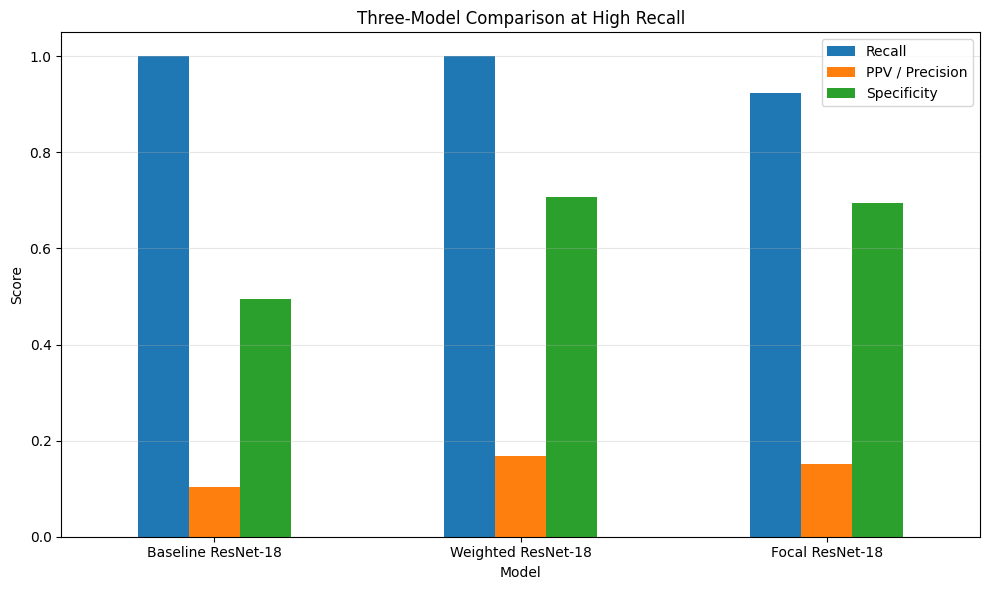

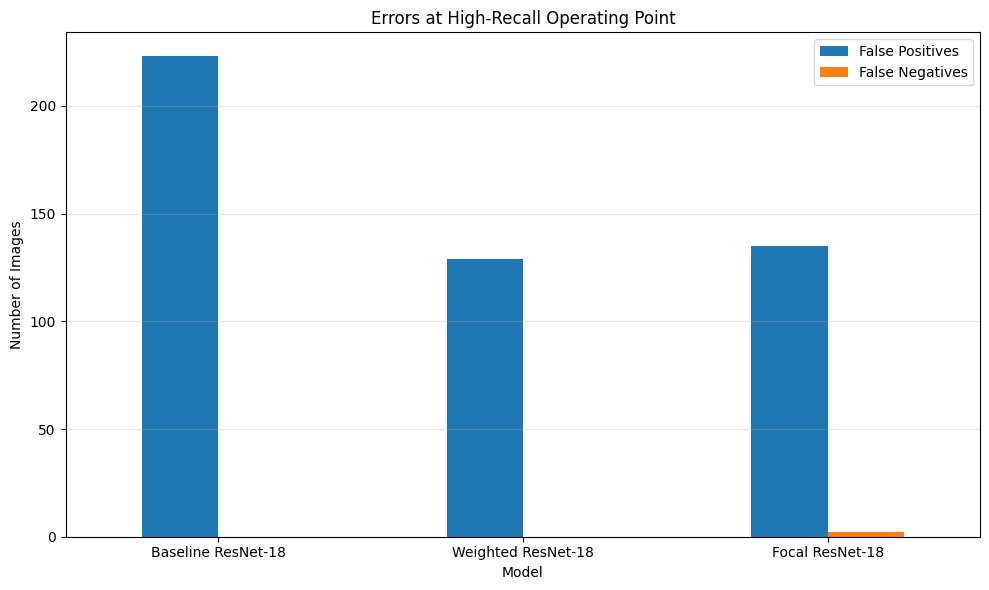

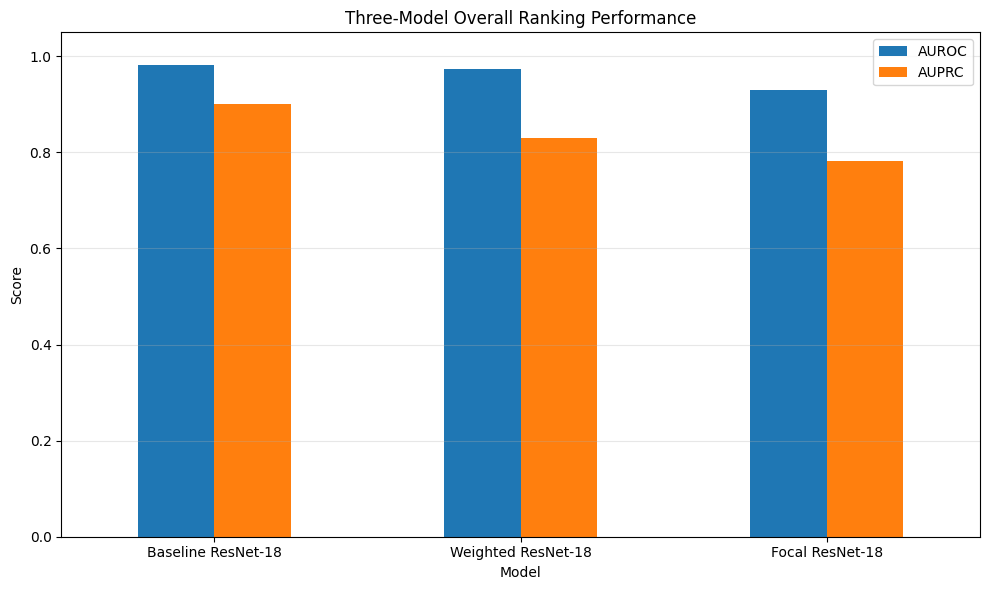


CURRENT BEST HIGH-RECALL MODEL
Best model: Weighted ResNet-18
Recall: 1.0
PPV: 0.1677
False positives: 129
False negatives: 0

Files saved:
/content/drive/MyDrive/RARE26/results/baseline_weighted_focal_comparison.csv
/content/drive/MyDrive/RARE26/results/figures/three_model_high_recall_scores.png
/content/drive/MyDrive/RARE26/results/figures/three_model_high_recall_errors.png
/content/drive/MyDrive/RARE26/results/figures/three_model_auroc_auprc.png


In [ ]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display as show_table

results_folder = Path(
    "/content/drive/MyDrive/RARE26/results"
)

figures_folder = results_folder / "figures"
figures_folder.mkdir(
    parents=True,
    exist_ok=True
)

# Three result files
baseline_path = (
    results_folder
    / "resnet18_baseline_test_metrics.csv"
)

weighted_path = (
    results_folder
    / "resnet18_weighted_test_metrics.csv"
)

focal_path = (
    results_folder
    / "resnet18_focal_test_metrics.csv"
)

# Read files
baseline_df = pd.read_csv(baseline_path)
weighted_df = pd.read_csv(weighted_path)
focal_df = pd.read_csv(focal_path)

# Add names
baseline_df["model"] = "Baseline ResNet-18"
weighted_df["model"] = "Weighted ResNet-18"
focal_df["model"] = "Focal ResNet-18"

# Combine
three_model_df = pd.concat(
    [
        baseline_df,
        weighted_df,
        focal_df
    ],
    ignore_index=True
)

three_model_df = three_model_df[
    [
        "model",
        "evaluation",
        "threshold",
        "accuracy",
        "precision",
        "recall",
        "specificity",
        "auroc",
        "auprc",
        "true_negatives",
        "false_positives",
        "false_negatives",
        "true_positives",
    ]
]

comparison_path = (
    results_folder
    / "baseline_weighted_focal_comparison.csv"
)

three_model_df.to_csv(
    comparison_path,
    index=False
)

print("=" * 75)
print("THREE-MODEL COMPARISON TABLE")
print("=" * 75)

show_table(three_model_df)

# High-recall rows
high_recall_df = three_model_df[
    three_model_df["evaluation"]
    == "validation_selected_90_recall"
].copy()

high_recall_df = high_recall_df.set_index(
    "model"
)

# Graph 1: Recall, PPV and specificity
high_recall_df[
    ["recall", "precision", "specificity"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Three-Model Comparison at High Recall"
)

plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(
    ["Recall", "PPV / Precision", "Specificity"]
)
plt.grid(
    axis="y",
    alpha=0.3
)
plt.tight_layout()

scores_path = (
    figures_folder
    / "three_model_high_recall_scores.png"
)

plt.savefig(
    scores_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Graph 2: False positives and false negatives
high_recall_df[
    ["false_positives", "false_negatives"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Errors at High-Recall Operating Point"
)

plt.xlabel("Model")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.legend(
    ["False Positives", "False Negatives"]
)
plt.grid(
    axis="y",
    alpha=0.3
)
plt.tight_layout()

errors_path = (
    figures_folder
    / "three_model_high_recall_errors.png"
)

plt.savefig(
    errors_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Graph 3: AUROC and AUPRC
default_df = three_model_df[
    three_model_df["evaluation"]
    == "default_threshold"
].copy()

default_df = default_df.set_index(
    "model"
)

default_df[
    ["auroc", "auprc"]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "Three-Model Overall Ranking Performance"
)

plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(
    ["AUROC", "AUPRC"]
)
plt.grid(
    axis="y",
    alpha=0.3
)
plt.tight_layout()

ranking_path = (
    figures_folder
    / "three_model_auroc_auprc.png"
)

plt.savefig(
    ranking_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Best high-recall model
best_model_name = high_recall_df[
    "precision"
].idxmax()

print("\n" + "=" * 75)
print("CURRENT BEST HIGH-RECALL MODEL")
print("=" * 75)

print("Best model:", best_model_name)

print(
    "Recall:",
    round(
        high_recall_df.loc[
            best_model_name,
            "recall"
        ],
        4
    )
)

print(
    "PPV:",
    round(
        high_recall_df.loc[
            best_model_name,
            "precision"
        ],
        4
    )
)

print(
    "False positives:",
    int(
        high_recall_df.loc[
            best_model_name,
            "false_positives"
        ]
    )
)

print(
    "False negatives:",
    int(
        high_recall_df.loc[
            best_model_name,
            "false_negatives"
        ]
    )
)

print("\nFiles saved:")
print(comparison_path)
print(scores_path)
print(errors_path)
print(ranking_path)

In [ ]:
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
)

# -------------------------------------------------
# Reproducibility
# -------------------------------------------------
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# -------------------------------------------------
# Training labels read karna
# -------------------------------------------------
train_csv_path = (
    "/content/drive/MyDrive/RARE26/splits/"
    "train_colab.csv"
)

train_df = pd.read_csv(train_csv_path)

train_labels = train_df["label"].astype(int).values

normal_count = int((train_labels == 0).sum())
neo_count = int((train_labels == 1).sum())

print("Normal images:", normal_count)
print("Neoplasia images:", neo_count)


# -------------------------------------------------
# Har class ka sampling weight
# -------------------------------------------------
class_sample_weights = {
    0: 1.0 / normal_count,
    1: 1.0 / neo_count,
}

sample_weights = np.array(
    [
        class_sample_weights[int(label)]
        for label in train_labels
    ],
    dtype=np.float64
)

sample_weights = torch.DoubleTensor(
    sample_weights
)


# -------------------------------------------------
# Balanced sampler
# -------------------------------------------------
balanced_sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)


# Important:
# shuffle=False because sampler khud selection karta hai
balanced_train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    sampler=balanced_sampler,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print(
    "Balanced train batches:",
    len(balanced_train_loader)
)


# -------------------------------------------------
# Check ek epoch mein sampled class balance
# -------------------------------------------------
sampled_normal = 0
sampled_neo = 0

for _, labels in balanced_train_loader:
    sampled_normal += int((labels == 0).sum())
    sampled_neo += int((labels == 1).sum())

print("One sampled epoch normal:", sampled_normal)
print("One sampled epoch neoplasia:", sampled_neo)


# -------------------------------------------------
# Fresh ResNet-18
# -------------------------------------------------
balanced_model = resnet18(
    weights=ResNet18_Weights.DEFAULT
)

balanced_model.fc = nn.Linear(
    balanced_model.fc.in_features,
    2
)

balanced_model = balanced_model.to(device)


# Standard loss — class weights nahi
balanced_criterion = nn.CrossEntropyLoss()

balanced_optimizer = torch.optim.AdamW(
    balanced_model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)


# -------------------------------------------------
# Save paths
# -------------------------------------------------
balanced_best_path = Path(
    "/content/drive/MyDrive/RARE26/models/"
    "resnet18_balanced_sampler_best.pth"
)

balanced_latest_path = Path(
    "/content/drive/MyDrive/RARE26/models/"
    "resnet18_balanced_sampler_latest.pth"
)

balanced_history_path = Path(
    "/content/drive/MyDrive/RARE26/results/"
    "resnet18_balanced_sampler_history.csv"
)


# -------------------------------------------------
# Validation function
# -------------------------------------------------
def evaluate_balanced_model(
    model,
    data_loader,
    criterion,
    device
):
    model.eval()

    total_loss = 0.0
    all_labels = []
    all_probabilities = []
    all_predictions = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = model(images)
            loss = criterion(outputs, labels)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            total_loss += (
                loss.item() * images.size(0)
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

            all_probabilities.extend(
                probabilities.cpu().numpy()
            )

            all_predictions.extend(
                predictions.cpu().numpy()
            )

    average_loss = (
        total_loss / len(data_loader.dataset)
    )

    return {
        "loss": average_loss,

        "accuracy": accuracy_score(
            all_labels,
            all_predictions
        ),

        "precision": precision_score(
            all_labels,
            all_predictions,
            zero_division=0
        ),

        "recall": recall_score(
            all_labels,
            all_predictions,
            zero_division=0
        ),

        "auroc": roc_auc_score(
            all_labels,
            all_probabilities
        ),

        "auprc": average_precision_score(
            all_labels,
            all_probabilities
        ),
    }


# -------------------------------------------------
# Training
# -------------------------------------------------
num_epochs = 10
best_balanced_auprc = -1.0
balanced_history = []

print("\nBalanced-sampling training start ho rahi hai...")
print("=" * 75)

for epoch in range(1, num_epochs + 1):
    start_time = time.time()

    balanced_model.train()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for images, labels in balanced_train_loader:
        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        balanced_optimizer.zero_grad()

        outputs = balanced_model(images)

        loss = balanced_criterion(
            outputs,
            labels
        )

        loss.backward()
        balanced_optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct_predictions += (
            predictions == labels
        ).sum().item()

        total_samples += labels.size(0)

    train_loss = running_loss / total_samples

    train_accuracy = (
        correct_predictions / total_samples
    )

    validation_metrics = evaluate_balanced_model(
        balanced_model,
        validation_loader,
        balanced_criterion,
        device
    )

    epoch_time = time.time() - start_time

    epoch_record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": validation_metrics["loss"],
        "val_accuracy": validation_metrics["accuracy"],
        "val_precision": validation_metrics["precision"],
        "val_recall": validation_metrics["recall"],
        "val_auroc": validation_metrics["auroc"],
        "val_auprc": validation_metrics["auprc"],
        "epoch_seconds": epoch_time,
    }

    balanced_history.append(epoch_record)

    pd.DataFrame(
        balanced_history
    ).to_csv(
        balanced_history_path,
        index=False
    )

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict":
                balanced_model.state_dict(),
            "optimizer_state_dict":
                balanced_optimizer.state_dict(),
            "validation_metrics":
                validation_metrics,
            "sampling_method":
                "weighted_random_sampler",
        },
        balanced_latest_path
    )

    if (
        validation_metrics["auprc"]
        > best_balanced_auprc
    ):
        best_balanced_auprc = (
            validation_metrics["auprc"]
        )

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict":
                    balanced_model.state_dict(),
                "optimizer_state_dict":
                    balanced_optimizer.state_dict(),
                "validation_metrics":
                    validation_metrics,
                "sampling_method":
                    "weighted_random_sampler",
            },
            balanced_best_path
        )

        best_message = (
            "  <-- Best balanced model saved"
        )

    else:
        best_message = ""

    print(
        f"Epoch {epoch:02d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {validation_metrics['loss']:.4f} | "
        f"Recall: {validation_metrics['recall']:.4f} | "
        f"Precision: {validation_metrics['precision']:.4f} | "
        f"AUROC: {validation_metrics['auroc']:.4f} | "
        f"AUPRC: {validation_metrics['auprc']:.4f} | "
        f"Time: {epoch_time:.1f}s"
        f"{best_message}"
    )

print("=" * 75)
print("Balanced-sampling training complete.")

print(
    "Best balanced validation AUPRC:",
    round(best_balanced_auprc, 4)
)

print("\nBest balanced model saved at:")
print(balanced_best_path)

print("\nBalanced history saved at:")
print(balanced_history_path)

Device: cuda
Normal images: 2050
Neoplasia images: 109
Balanced train batches: 68
One sampled epoch normal: 1099
One sampled epoch neoplasia: 1060

Balanced-sampling training start ho rahi hai...
Epoch 01/10 | Train Loss: 0.1511 | Val Loss: 0.1074 | Recall: 0.5217 | Precision: 1.0000 | AUROC: 0.8997 | AUPRC: 0.7379 | Time: 31.9s  <-- Best balanced model saved
Epoch 02/10 | Train Loss: 0.0131 | Val Loss: 0.1123 | Recall: 0.5652 | Precision: 0.9286 | AUROC: 0.9165 | AUPRC: 0.7311 | Time: 32.3s
Epoch 03/10 | Train Loss: 0.0051 | Val Loss: 0.1517 | Recall: 0.3478 | Precision: 0.8889 | AUROC: 0.9231 | AUPRC: 0.6983 | Time: 35.9s
Epoch 04/10 | Train Loss: 0.0025 | Val Loss: 0.1598 | Recall: 0.3913 | Precision: 1.0000 | AUROC: 0.9078 | AUPRC: 0.6800 | Time: 34.6s
Epoch 05/10 | Train Loss: 0.0035 | Val Loss: 0.1405 | Recall: 0.5652 | Precision: 0.8667 | AUROC: 0.9150 | AUPRC: 0.7242 | Time: 34.7s
Epoch 06/10 | Train Loss: 0.0019 | Val Loss: 0.1657 | Recall: 0.3478 | Precision: 1.0000 | AUROC: 

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torchvision.models import resnet18
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

balanced_model_path = Path(
    "/content/drive/MyDrive/RARE26/models/"
    "resnet18_balanced_sampler_best.pth"
)

balanced_best_model = resnet18(weights=None)

balanced_best_model.fc = nn.Linear(
    balanced_best_model.fc.in_features,
    2
)

balanced_checkpoint = torch.load(
    balanced_model_path,
    map_location=device,
    weights_only=False
)

balanced_best_model.load_state_dict(
    balanced_checkpoint["model_state_dict"]
)

balanced_best_model = balanced_best_model.to(device)
balanced_best_model.eval()

print(
    "Best balanced checkpoint epoch:",
    balanced_checkpoint["epoch"]
)

print(
    "Saved balanced validation AUPRC:",
    balanced_checkpoint["validation_metrics"]["auprc"]
)


def collect_balanced_predictions(
    model,
    data_loader,
    device
):
    labels_list = []
    probabilities_list = []

    model.eval()

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            labels_list.extend(
                labels.cpu().numpy()
            )

            probabilities_list.extend(
                probabilities.cpu().numpy()
            )

    return (
        np.array(labels_list),
        np.array(probabilities_list)
    )


def calculate_balanced_metrics(
    labels,
    probabilities,
    threshold
):
    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    return {
        "threshold": float(threshold),

        "accuracy": float(
            accuracy_score(
                labels,
                predictions
            )
        ),

        "precision": float(
            precision_score(
                labels,
                predictions,
                zero_division=0
            )
        ),

        "recall": float(
            recall_score(
                labels,
                predictions,
                zero_division=0
            )
        ),

        "specificity": float(specificity),

        "auroc": float(
            roc_auc_score(
                labels,
                probabilities
            )
        ),

        "auprc": float(
            average_precision_score(
                labels,
                probabilities
            )
        ),

        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp),
    }


# Validation predictions
balanced_val_labels, balanced_val_probs = (
    collect_balanced_predictions(
        balanced_best_model,
        validation_loader,
        device
    )
)

# Test predictions
balanced_test_labels, balanced_test_probs = (
    collect_balanced_predictions(
        balanced_best_model,
        test_loader,
        device
    )
)


# Validation par 90% recall threshold
precision_values, recall_values, thresholds = (
    precision_recall_curve(
        balanced_val_labels,
        balanced_val_probs
    )
)

valid_indices = np.where(
    recall_values[:-1] >= 0.90
)[0]

if len(valid_indices) > 0:
    best_index = valid_indices[
        np.argmax(
            precision_values[:-1][valid_indices]
        )
    ]

    balanced_recall90_threshold = float(
        thresholds[best_index]
    )

    validation_precision_target = float(
        precision_values[best_index]
    )

    validation_recall_target = float(
        recall_values[best_index]
    )

else:
    balanced_recall90_threshold = 0.5
    validation_precision_target = 0.0
    validation_recall_target = 0.0


print("\nVALIDATION THRESHOLD SELECTION")

print(
    "Selected threshold:",
    balanced_recall90_threshold
)

print(
    "Validation recall:",
    validation_recall_target
)

print(
    "Validation precision:",
    validation_precision_target
)


# Default threshold metrics
balanced_default_metrics = calculate_balanced_metrics(
    balanced_test_labels,
    balanced_test_probs,
    threshold=0.5
)

# High-recall threshold metrics
balanced_high_recall_metrics = calculate_balanced_metrics(
    balanced_test_labels,
    balanced_test_probs,
    threshold=balanced_recall90_threshold
)


print("\n" + "=" * 65)
print("BALANCED MODEL TEST RESULTS: DEFAULT THRESHOLD")
print("=" * 65)

for key, value in balanced_default_metrics.items():
    print(f"{key}: {value}")


print("\n" + "=" * 65)
print("BALANCED MODEL TEST RESULTS: HIGH-RECALL THRESHOLD")
print("=" * 65)

for key, value in balanced_high_recall_metrics.items():
    print(f"{key}: {value}")


# Save metrics
balanced_results_df = pd.DataFrame([
    {
        "evaluation": "default_threshold",
        **balanced_default_metrics
    },
    {
        "evaluation": "validation_selected_90_recall",
        **balanced_high_recall_metrics
    }
])

balanced_results_path = Path(
    "/content/drive/MyDrive/RARE26/results/"
    "resnet18_balanced_sampler_test_metrics.csv"
)

balanced_results_df.to_csv(
    balanced_results_path,
    index=False
)


# Save predictions
balanced_predictions_df = pd.DataFrame({
    "true_label": balanced_test_labels,
    "neoplasia_probability": balanced_test_probs,
})

balanced_predictions_path = Path(
    "/content/drive/MyDrive/RARE26/results/"
    "resnet18_balanced_sampler_test_predictions.csv"
)

balanced_predictions_df.to_csv(
    balanced_predictions_path,
    index=False
)


print("\nBalanced results saved at:")
print(balanced_results_path)

print("\nBalanced predictions saved at:")
print(balanced_predictions_path)

Best balanced checkpoint epoch: 10
Saved balanced validation AUPRC: 0.7513591175445667

VALIDATION THRESHOLD SELECTION
Selected threshold: 5.204434637562372e-05
Validation recall: 0.9130434782608695
Validation precision: 0.09251101321585903

BALANCED MODEL TEST RESULTS: DEFAULT THRESHOLD
threshold: 0.5
accuracy: 0.9700854700854701
precision: 1.0
recall: 0.46153846153846156
specificity: 1.0
auroc: 0.9385659589279499
auprc: 0.791680693769524
true_negatives: 442
false_positives: 0
false_negatives: 14
true_positives: 12

BALANCED MODEL TEST RESULTS: HIGH-RECALL THRESHOLD
threshold: 5.204434637562372e-05
accuracy: 0.5747863247863247
precision: 0.1085972850678733
recall: 0.9230769230769231
specificity: 0.5542986425339367
auroc: 0.9385659589279499
auprc: 0.791680693769524
true_negatives: 245
false_positives: 197
false_negatives: 2
true_positives: 24

Balanced results saved at:
/content/drive/MyDrive/RARE26/results/resnet18_balanced_sampler_test_metrics.csv

Balanced predictions saved at:
/con

FOUR-MODEL COMPARISON TABLE


,model,evaluation,threshold,accuracy,precision,recall,specificity,auroc,auprc,true_negatives,false_positives,false_negatives,true_positives
0,Baseline ResNet-18,default_threshold,0.500000,0.978632,1.000000,0.615385,1.000000,0.981465,0.901696,442,0,10,16
1,Baseline ResNet-18,validation_selected_90_recall,0.001840,0.523504,0.104418,1.000000,0.495475,0.981465,0.901696,219,223,0,26
2,Weighted ResNet-18,default_threshold,0.500000,0.972222,1.000000,0.500000,1.000000,0.972851,0.830288,442,0,13,13
3,Weighted ResNet-18,validation_selected_90_recall,0.003061,0.724359,0.167742,1.000000,0.708145,0.972851,0.830288,313,129,0,26
4,Focal ResNet-18,default_threshold,0.500000,0.959402,0.606061,0.769231,0.970588,0.930473,0.783172,429,13,6,20
5,Focal ResNet-18,validation_selected_90_recall,0.134817,0.707265,0.150943,0.923077,0.694570,0.930473,0.783172,307,135,2,24
6,Balanced Sampler ResNet-18,default_threshold,0.500000,0.970085,1.000000,0.461538,1.000000,0.938566,0.791681,442,0,14,12
7,Balanced Sampler ResNet-18,validation_selected_90_recall,0.000052,0.574786,0.108597,0.923077,0.554299,0.938566,0.791681,245,197,2,24


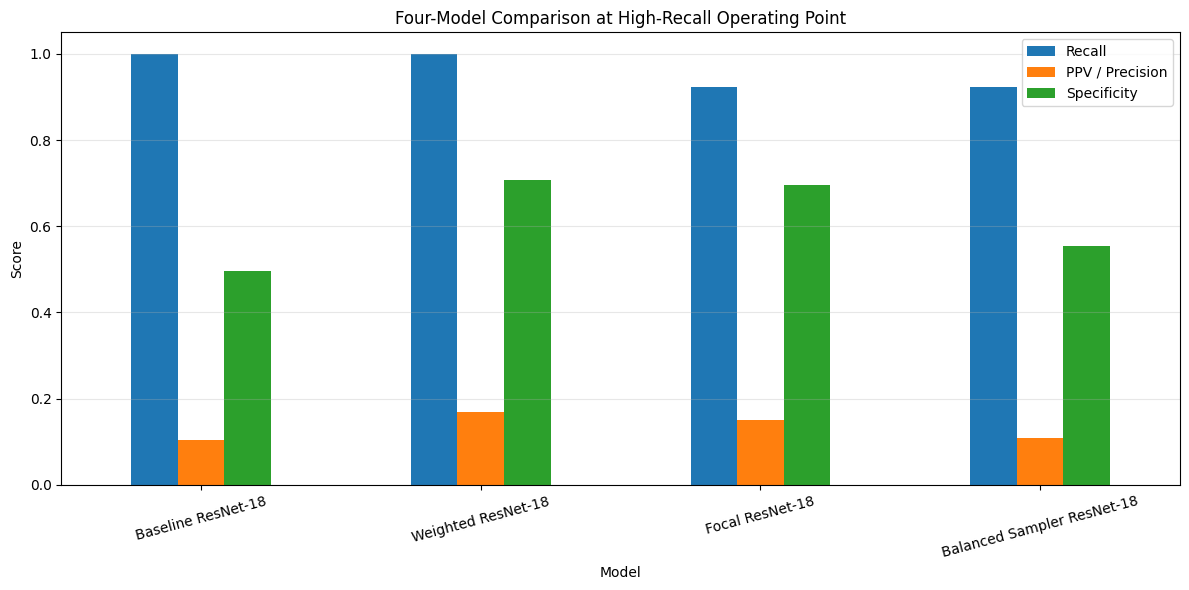

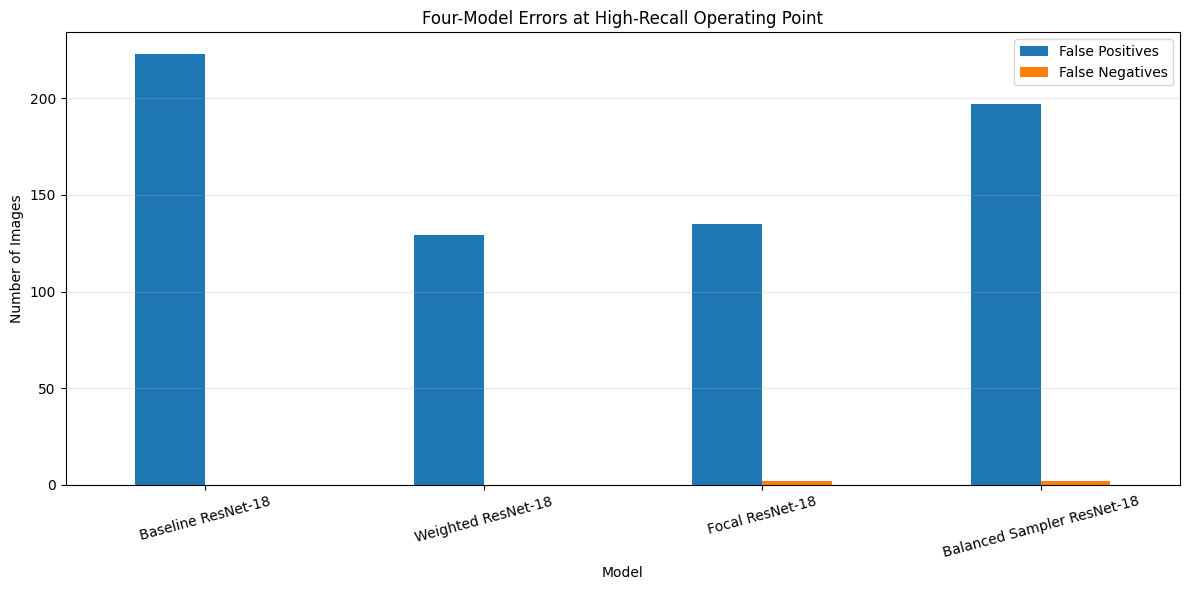

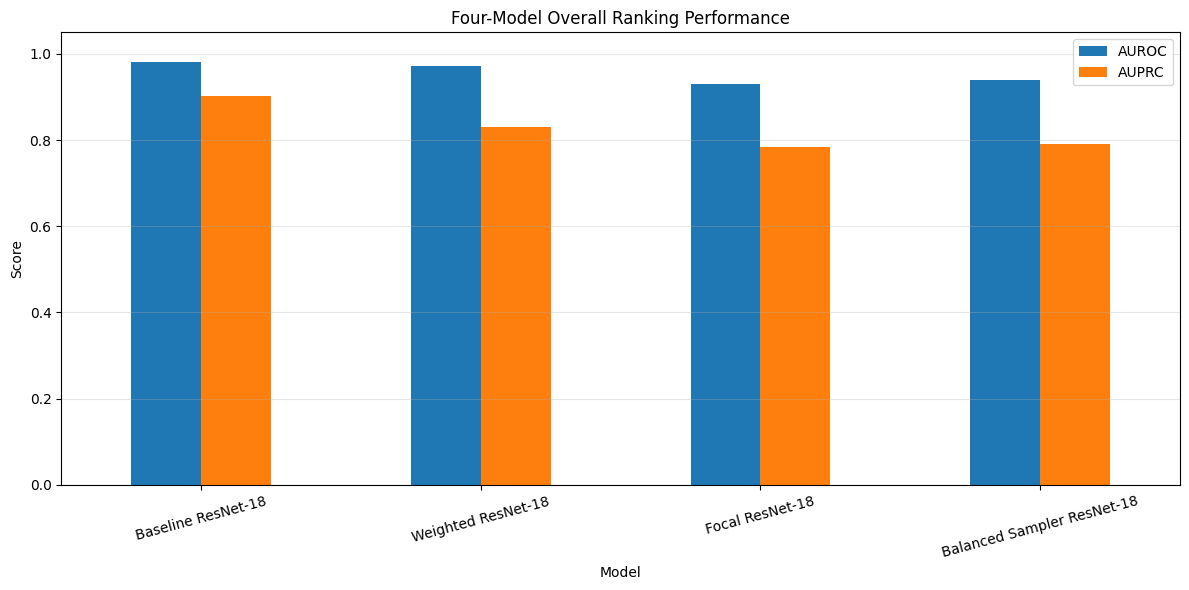


HIGH-RECALL MODEL RANKING


,recall,precision,specificity,false_positives,false_negatives,auroc,auprc
model,,,,,,,
Weighted ResNet-18,1.000000,0.167742,0.708145,129,0,0.972851,0.830288
Focal ResNet-18,0.923077,0.150943,0.694570,135,2,0.930473,0.783172
Balanced Sampler ResNet-18,0.923077,0.108597,0.554299,197,2,0.938566,0.791681
Baseline ResNet-18,1.000000,0.104418,0.495475,223,0,0.981465,0.901696



CURRENT BEST MODEL: Weighted ResNet-18
Recall: 1.0
PPV: 0.1677
False positives: 129
False negatives: 0

Files saved:
/content/drive/MyDrive/RARE26/results/four_model_comparison.csv
/content/drive/MyDrive/RARE26/results/figures/four_model_high_recall_scores.png
/content/drive/MyDrive/RARE26/results/figures/four_model_high_recall_errors.png
/content/drive/MyDrive/RARE26/results/figures/four_model_auroc_auprc.png


In [ ]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display as show_table


# -------------------------------------------------
# Folders
# -------------------------------------------------
results_folder = Path(
    "/content/drive/MyDrive/RARE26/results"
)

figures_folder = results_folder / "figures"

figures_folder.mkdir(
    parents=True,
    exist_ok=True
)


# -------------------------------------------------
# Result files
# -------------------------------------------------
baseline_path = (
    results_folder
    / "resnet18_baseline_test_metrics.csv"
)

weighted_path = (
    results_folder
    / "resnet18_weighted_test_metrics.csv"
)

focal_path = (
    results_folder
    / "resnet18_focal_test_metrics.csv"
)

balanced_path = (
    results_folder
    / "resnet18_balanced_sampler_test_metrics.csv"
)


# -------------------------------------------------
# Files read karna
# -------------------------------------------------
baseline_df = pd.read_csv(baseline_path)
weighted_df = pd.read_csv(weighted_path)
focal_df = pd.read_csv(focal_path)
balanced_df = pd.read_csv(balanced_path)


# Model names
baseline_df["model"] = "Baseline ResNet-18"
weighted_df["model"] = "Weighted ResNet-18"
focal_df["model"] = "Focal ResNet-18"
balanced_df["model"] = "Balanced Sampler ResNet-18"


# -------------------------------------------------
# Combine all four models
# -------------------------------------------------
four_model_df = pd.concat(
    [
        baseline_df,
        weighted_df,
        focal_df,
        balanced_df,
    ],
    ignore_index=True
)

four_model_df = four_model_df[
    [
        "model",
        "evaluation",
        "threshold",
        "accuracy",
        "precision",
        "recall",
        "specificity",
        "auroc",
        "auprc",
        "true_negatives",
        "false_positives",
        "false_negatives",
        "true_positives",
    ]
]


# Save comparison CSV
comparison_path = (
    results_folder
    / "four_model_comparison.csv"
)

four_model_df.to_csv(
    comparison_path,
    index=False
)


print("=" * 80)
print("FOUR-MODEL COMPARISON TABLE")
print("=" * 80)

show_table(four_model_df)


# -------------------------------------------------
# High-recall results
# -------------------------------------------------
high_recall_df = four_model_df[
    four_model_df["evaluation"]
    == "validation_selected_90_recall"
].copy()

high_recall_df = high_recall_df.set_index(
    "model"
)


# -------------------------------------------------
# Graph 1: Recall, PPV and specificity
# -------------------------------------------------
high_recall_df[
    [
        "recall",
        "precision",
        "specificity",
    ]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Four-Model Comparison at High-Recall Operating Point"
)

plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)

plt.legend(
    [
        "Recall",
        "PPV / Precision",
        "Specificity",
    ]
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

scores_path = (
    figures_folder
    / "four_model_high_recall_scores.png"
)

plt.savefig(
    scores_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# -------------------------------------------------
# Graph 2: False positives and negatives
# -------------------------------------------------
high_recall_df[
    [
        "false_positives",
        "false_negatives",
    ]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Four-Model Errors at High-Recall Operating Point"
)

plt.xlabel("Model")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)

plt.legend(
    [
        "False Positives",
        "False Negatives",
    ]
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

errors_path = (
    figures_folder
    / "four_model_high_recall_errors.png"
)

plt.savefig(
    errors_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# -------------------------------------------------
# Graph 3: AUROC and AUPRC
# -------------------------------------------------
default_df = four_model_df[
    four_model_df["evaluation"]
    == "default_threshold"
].copy()

default_df = default_df.set_index(
    "model"
)

default_df[
    [
        "auroc",
        "auprc",
    ]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title(
    "Four-Model Overall Ranking Performance"
)

plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)

plt.legend(
    [
        "AUROC",
        "AUPRC",
    ]
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

ranking_path = (
    figures_folder
    / "four_model_auroc_auprc.png"
)

plt.savefig(
    ranking_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# -------------------------------------------------
# Rank only models with recall >= 90%
# -------------------------------------------------
eligible_models = high_recall_df[
    high_recall_df["recall"] >= 0.90
].copy()

eligible_models = eligible_models.sort_values(
    by=[
        "precision",
        "specificity",
    ],
    ascending=False
)


print("\n" + "=" * 80)
print("HIGH-RECALL MODEL RANKING")
print("=" * 80)

show_table(
    eligible_models[
        [
            "recall",
            "precision",
            "specificity",
            "false_positives",
            "false_negatives",
            "auroc",
            "auprc",
        ]
    ]
)


best_model_name = eligible_models.index[0]

print("\nCURRENT BEST MODEL:", best_model_name)

print(
    "Recall:",
    round(
        eligible_models.loc[
            best_model_name,
            "recall"
        ],
        4
    )
)

print(
    "PPV:",
    round(
        eligible_models.loc[
            best_model_name,
            "precision"
        ],
        4
    )
)

print(
    "False positives:",
    int(
        eligible_models.loc[
            best_model_name,
            "false_positives"
        ]
    )
)

print(
    "False negatives:",
    int(
        eligible_models.loc[
            best_model_name,
            "false_negatives"
        ]
    )
)


print("\nFiles saved:")

print(comparison_path)
print(scores_path)
print(errors_path)
print(ranking_path)

In [ ]:
import time
import random
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from pathlib import Path
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
)

# -------------------------------------------------
# Reproducibility
# -------------------------------------------------
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# -------------------------------------------------
# Training data information
# -------------------------------------------------
train_csv_path = (
    "/content/drive/MyDrive/RARE26/splits/"
    "train_colab.csv"
)

train_df = pd.read_csv(train_csv_path)

normal_count = int(
    (train_df["label"] == 0).sum()
)

neo_count = int(
    (train_df["label"] == 1).sum()
)

total_count = normal_count + neo_count

normal_weight = total_count / (2 * normal_count)
neo_weight = total_count / (2 * neo_count)

augmentation_class_weights = torch.tensor(
    [normal_weight, neo_weight],
    dtype=torch.float32,
    device=device
)

print("Normal images:", normal_count)
print("Neoplasia images:", neo_count)
print("Normal class weight:", normal_weight)
print("Neoplasia class weight:", neo_weight)


# -------------------------------------------------
# Mild training-only augmentation
# -------------------------------------------------
augmentation_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=8
    ),

    transforms.ColorJitter(
        brightness=0.12,
        contrast=0.12,
        saturation=0.08,
        hue=0.02
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])


# Existing training dataset ki copy
augmented_train_dataset = copy.deepcopy(
    train_dataset
)

# Dataset ke transform ko replace karna
if hasattr(
    augmented_train_dataset,
    "transform"
):
    augmented_train_dataset.transform = (
        augmentation_transform
    )

elif hasattr(
    augmented_train_dataset,
    "transforms"
):
    augmented_train_dataset.transforms = (
        augmentation_transform
    )

else:
    raise AttributeError(
        "Training dataset mein transform attribute nahi mila."
    )


augmentation_train_loader = DataLoader(
    augmented_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print(
    "Augmentation training batches:",
    len(augmentation_train_loader)
)


# -------------------------------------------------
# Fresh pretrained ResNet-18
# -------------------------------------------------
augmentation_model = resnet18(
    weights=ResNet18_Weights.DEFAULT
)

augmentation_model.fc = nn.Linear(
    augmentation_model.fc.in_features,
    2
)

augmentation_model = augmentation_model.to(
    device
)


# Same weighted loss as current best model
augmentation_criterion = nn.CrossEntropyLoss(
    weight=augmentation_class_weights
)

augmentation_optimizer = torch.optim.AdamW(
    augmentation_model.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)


# -------------------------------------------------
# Save paths
# -------------------------------------------------
best_model_path = Path(
    "/content/drive/MyDrive/RARE26/models/"
    "resnet18_weighted_augmentation_best.pth"
)

latest_model_path = Path(
    "/content/drive/MyDrive/RARE26/models/"
    "resnet18_weighted_augmentation_latest.pth"
)

history_path = Path(
    "/content/drive/MyDrive/RARE26/results/"
    "resnet18_weighted_augmentation_history.csv"
)

test_metrics_path = Path(
    "/content/drive/MyDrive/RARE26/results/"
    "resnet18_weighted_augmentation_test_metrics.csv"
)

test_predictions_path = Path(
    "/content/drive/MyDrive/RARE26/results/"
    "resnet18_weighted_augmentation_test_predictions.csv"
)


# -------------------------------------------------
# Validation function
# -------------------------------------------------
def evaluate_augmentation_model(
    model,
    data_loader,
    criterion,
    device
):
    model.eval()

    total_loss = 0.0
    labels_list = []
    probabilities_list = []
    predictions_list = []

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = model(images)
            loss = criterion(outputs, labels)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            total_loss += (
                loss.item() * images.size(0)
            )

            labels_list.extend(
                labels.cpu().numpy()
            )

            probabilities_list.extend(
                probabilities.cpu().numpy()
            )

            predictions_list.extend(
                predictions.cpu().numpy()
            )

    average_loss = (
        total_loss / len(data_loader.dataset)
    )

    return {
        "loss": average_loss,

        "accuracy": accuracy_score(
            labels_list,
            predictions_list
        ),

        "precision": precision_score(
            labels_list,
            predictions_list,
            zero_division=0
        ),

        "recall": recall_score(
            labels_list,
            predictions_list,
            zero_division=0
        ),

        "auroc": roc_auc_score(
            labels_list,
            probabilities_list
        ),

        "auprc": average_precision_score(
            labels_list,
            probabilities_list
        ),
    }


# -------------------------------------------------
# Training
# -------------------------------------------------
num_epochs = 10
best_validation_auprc = -1.0
augmentation_history = []

print(
    "\nWeighted + augmentation training start ho rahi hai..."
)

print("=" * 80)

for epoch in range(1, num_epochs + 1):
    start_time = time.time()

    augmentation_model.train()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for images, labels in augmentation_train_loader:
        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        augmentation_optimizer.zero_grad()

        outputs = augmentation_model(images)

        loss = augmentation_criterion(
            outputs,
            labels
        )

        loss.backward()
        augmentation_optimizer.step()

        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct_predictions += (
            predictions == labels
        ).sum().item()

        total_samples += labels.size(0)

    train_loss = running_loss / total_samples

    train_accuracy = (
        correct_predictions / total_samples
    )

    validation_metrics = evaluate_augmentation_model(
        augmentation_model,
        validation_loader,
        augmentation_criterion,
        device
    )

    epoch_time = time.time() - start_time

    epoch_record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": validation_metrics["loss"],
        "val_accuracy": validation_metrics["accuracy"],
        "val_precision": validation_metrics["precision"],
        "val_recall": validation_metrics["recall"],
        "val_auroc": validation_metrics["auroc"],
        "val_auprc": validation_metrics["auprc"],
        "epoch_seconds": epoch_time,
    }

    augmentation_history.append(
        epoch_record
    )

    pd.DataFrame(
        augmentation_history
    ).to_csv(
        history_path,
        index=False
    )

    torch.save(
        {
            "epoch": epoch,
            "model_state_dict":
                augmentation_model.state_dict(),
            "optimizer_state_dict":
                augmentation_optimizer.state_dict(),
            "validation_metrics":
                validation_metrics,
            "class_weights":
                augmentation_class_weights.cpu(),
            "augmentation":
                "mild_rotation_flip_color_jitter",
        },
        latest_model_path
    )

    if (
        validation_metrics["auprc"]
        > best_validation_auprc
    ):
        best_validation_auprc = (
            validation_metrics["auprc"]
        )

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict":
                    augmentation_model.state_dict(),
                "optimizer_state_dict":
                    augmentation_optimizer.state_dict(),
                "validation_metrics":
                    validation_metrics,
                "class_weights":
                    augmentation_class_weights.cpu(),
                "augmentation":
                    "mild_rotation_flip_color_jitter",
            },
            best_model_path
        )

        best_message = (
            "  <-- Best augmentation model saved"
        )

    else:
        best_message = ""

    print(
        f"Epoch {epoch:02d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {validation_metrics['loss']:.4f} | "
        f"Recall: {validation_metrics['recall']:.4f} | "
        f"Precision: {validation_metrics['precision']:.4f} | "
        f"AUROC: {validation_metrics['auroc']:.4f} | "
        f"AUPRC: {validation_metrics['auprc']:.4f} | "
        f"Time: {epoch_time:.1f}s"
        f"{best_message}"
    )

print("=" * 80)

print(
    "Weighted + augmentation training complete."
)

print(
    "Best validation AUPRC:",
    round(best_validation_auprc, 4)
)


# -------------------------------------------------
# Best model load karna
# -------------------------------------------------
best_checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=False
)

best_augmentation_model = resnet18(
    weights=None
)

best_augmentation_model.fc = nn.Linear(
    best_augmentation_model.fc.in_features,
    2
)

best_augmentation_model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

best_augmentation_model = (
    best_augmentation_model.to(device)
)

best_augmentation_model.eval()

print(
    "\nBest checkpoint epoch:",
    best_checkpoint["epoch"]
)

print(
    "Saved validation AUPRC:",
    best_checkpoint[
        "validation_metrics"
    ]["auprc"]
)


# -------------------------------------------------
# Prediction collection
# -------------------------------------------------
def collect_augmentation_predictions(
    model,
    data_loader,
    device
):
    labels_list = []
    probabilities_list = []

    model.eval()

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            labels_list.extend(
                labels.cpu().numpy()
            )

            probabilities_list.extend(
                probabilities.cpu().numpy()
            )

    return (
        np.array(labels_list),
        np.array(probabilities_list)
    )


def calculate_augmentation_metrics(
    labels,
    probabilities,
    threshold
):
    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    return {
        "threshold": float(threshold),

        "accuracy": float(
            accuracy_score(
                labels,
                predictions
            )
        ),

        "precision": float(
            precision_score(
                labels,
                predictions,
                zero_division=0
            )
        ),

        "recall": float(
            recall_score(
                labels,
                predictions,
                zero_division=0
            )
        ),

        "specificity": float(specificity),

        "auroc": float(
            roc_auc_score(
                labels,
                probabilities
            )
        ),

        "auprc": float(
            average_precision_score(
                labels,
                probabilities
            )
        ),

        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp),
    }


# Validation and test predictions
augmentation_val_labels, augmentation_val_probs = (
    collect_augmentation_predictions(
        best_augmentation_model,
        validation_loader,
        device
    )
)

augmentation_test_labels, augmentation_test_probs = (
    collect_augmentation_predictions(
        best_augmentation_model,
        test_loader,
        device
    )
)


# Validation-selected threshold for >=90% recall
precision_values, recall_values, thresholds = (
    precision_recall_curve(
        augmentation_val_labels,
        augmentation_val_probs
    )
)

valid_indices = np.where(
    recall_values[:-1] >= 0.90
)[0]

if len(valid_indices) > 0:
    best_index = valid_indices[
        np.argmax(
            precision_values[:-1][valid_indices]
        )
    ]

    augmentation_recall90_threshold = float(
        thresholds[best_index]
    )

    selected_validation_precision = float(
        precision_values[best_index]
    )

    selected_validation_recall = float(
        recall_values[best_index]
    )

else:
    augmentation_recall90_threshold = 0.5
    selected_validation_precision = 0.0
    selected_validation_recall = 0.0


print("\nVALIDATION THRESHOLD SELECTION")

print(
    "Selected threshold:",
    augmentation_recall90_threshold
)

print(
    "Validation recall:",
    selected_validation_recall
)

print(
    "Validation precision:",
    selected_validation_precision
)


# Test metrics
augmentation_default_metrics = (
    calculate_augmentation_metrics(
        augmentation_test_labels,
        augmentation_test_probs,
        threshold=0.5
    )
)

augmentation_high_recall_metrics = (
    calculate_augmentation_metrics(
        augmentation_test_labels,
        augmentation_test_probs,
        threshold=augmentation_recall90_threshold
    )
)


print("\n" + "=" * 70)
print(
    "WEIGHTED + AUGMENTATION TEST: DEFAULT THRESHOLD"
)
print("=" * 70)

for key, value in (
    augmentation_default_metrics.items()
):
    print(f"{key}: {value}")


print("\n" + "=" * 70)
print(
    "WEIGHTED + AUGMENTATION TEST: HIGH-RECALL THRESHOLD"
)
print("=" * 70)

for key, value in (
    augmentation_high_recall_metrics.items()
):
    print(f"{key}: {value}")


# Save test metrics
augmentation_results_df = pd.DataFrame([
    {
        "evaluation": "default_threshold",
        **augmentation_default_metrics
    },
    {
        "evaluation":
            "validation_selected_90_recall",
        **augmentation_high_recall_metrics
    }
])

augmentation_results_df.to_csv(
    test_metrics_path,
    index=False
)


# Save predictions
augmentation_predictions_df = pd.DataFrame({
    "true_label": augmentation_test_labels,
    "neoplasia_probability":
        augmentation_test_probs,
})

augmentation_predictions_df.to_csv(
    test_predictions_path,
    index=False
)


print("\nFiles saved:")
print(best_model_path)
print(history_path)
print(test_metrics_path)
print(test_predictions_path)

Device: cuda
Normal images: 2050
Neoplasia images: 109
Normal class weight: 0.5265853658536586
Neoplasia class weight: 9.903669724770642
Augmentation training batches: 68

Weighted + augmentation training start ho rahi hai...
Epoch 01/10 | Train Loss: 0.5654 | Val Loss: 0.2774 | Recall: 0.7391 | Precision: 0.3091 | AUROC: 0.9003 | AUPRC: 0.6371 | Time: 48.8s  <-- Best augmentation model saved
Epoch 02/10 | Train Loss: 0.2904 | Val Loss: 0.2654 | Recall: 0.5652 | Precision: 0.7222 | AUROC: 0.8416 | AUPRC: 0.6590 | Time: 45.1s  <-- Best augmentation model saved
Epoch 03/10 | Train Loss: 0.2314 | Val Loss: 0.1929 | Recall: 0.6957 | Precision: 0.4444 | AUROC: 0.9075 | AUPRC: 0.7155 | Time: 49.6s  <-- Best augmentation model saved
Epoch 04/10 | Train Loss: 0.1757 | Val Loss: 0.2707 | Recall: 0.6087 | Precision: 0.3889 | AUROC: 0.8701 | AUPRC: 0.6502 | Time: 50.8s
Epoch 05/10 | Train Loss: 0.1077 | Val Loss: 0.3374 | Recall: 0.6087 | Precision: 0.3415 | AUROC: 0.8562 | AUPRC: 0.5985 | Time: 

FIVE-MODEL COMPARISON TABLE


,model,evaluation,threshold,accuracy,precision,recall,specificity,auroc,auprc,true_negatives,false_positives,false_negatives,true_positives
0,Baseline ResNet-18,default_threshold,0.500000,0.978632,1.000000,0.615385,1.000000,0.981465,0.901696,442,0,10,16
1,Baseline ResNet-18,validation_selected_90_recall,0.001840,0.523504,0.104418,1.000000,0.495475,0.981465,0.901696,219,223,0,26
2,Weighted ResNet-18,default_threshold,0.500000,0.972222,1.000000,0.500000,1.000000,0.972851,0.830288,442,0,13,13
3,Weighted ResNet-18,validation_selected_90_recall,0.003061,0.724359,0.167742,1.000000,0.708145,0.972851,0.830288,313,129,0,26
4,Focal ResNet-18,default_threshold,0.500000,0.959402,0.606061,0.769231,0.970588,0.930473,0.783172,429,13,6,20
5,Focal ResNet-18,validation_selected_90_recall,0.134817,0.707265,0.150943,0.923077,0.694570,0.930473,0.783172,307,135,2,24
6,Balanced Sampler ResNet-18,default_threshold,0.500000,0.970085,1.000000,0.461538,1.000000,0.938566,0.791681,442,0,14,12
7,Balanced Sampler ResNet-18,validation_selected_90_recall,0.000052,0.574786,0.108597,0.923077,0.554299,0.938566,0.791681,245,197,2,24
8,Weighted + Augmentation ResNet-18,default_threshold,0.500000,0.957265,0.575000,0.884615,0.961538,0.975287,0.892000,425,17,3,23
9,Weighted + Augmentation ResNet-18,validation_selected_90_recall,0.022335,0.814103,0.220183,0.923077,0.807692,0.975287,0.892000,357,85,2,24


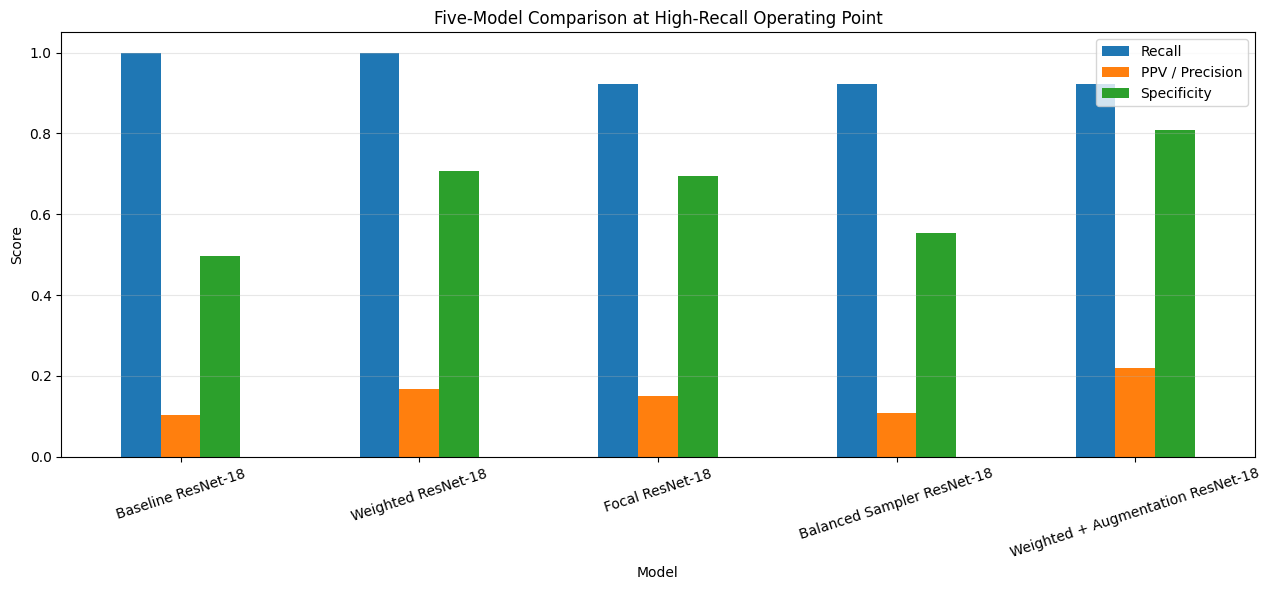

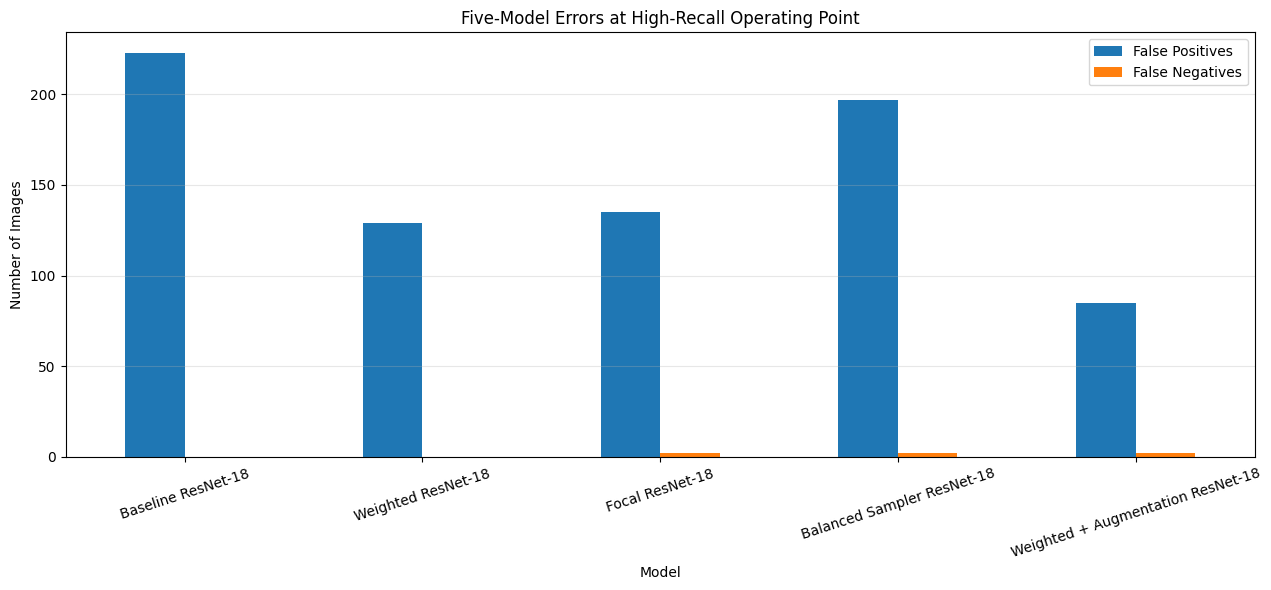

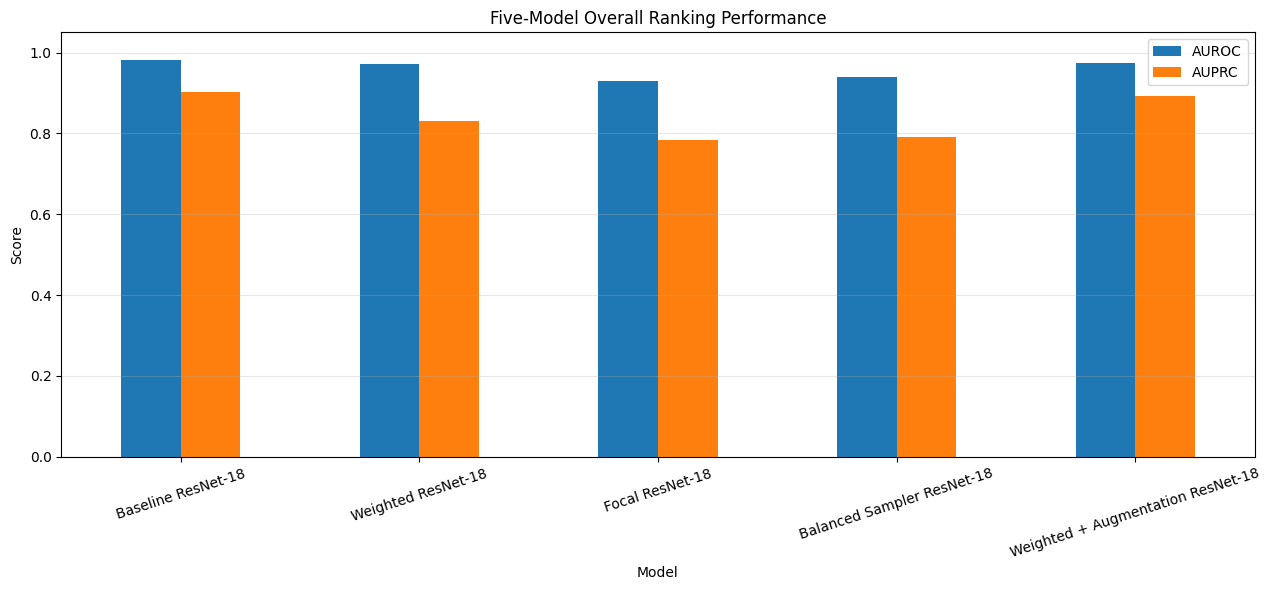


HIGH-RECALL MODEL RANKING


,recall,precision,specificity,false_positives,false_negatives,auroc,auprc
model,,,,,,,
Weighted + Augmentation ResNet-18,0.923077,0.220183,0.807692,85,2,0.975287,0.892000
Weighted ResNet-18,1.000000,0.167742,0.708145,129,0,0.972851,0.830288
Focal ResNet-18,0.923077,0.150943,0.694570,135,2,0.930473,0.783172
Balanced Sampler ResNet-18,0.923077,0.108597,0.554299,197,2,0.938566,0.791681
Baseline ResNet-18,1.000000,0.104418,0.495475,223,0,0.981465,0.901696



CURRENT BEST MODEL: Weighted + Augmentation ResNet-18
Recall: 0.9231
PPV: 0.2202
Specificity: 0.8077
False positives: 85
False negatives: 2

AUGMENTATION IMPROVEMENT OVER WEIGHTED-ONLY MODEL
False positives reduced by: 44
False-positive reduction: 34.11 %
Relative PPV improvement: 31.26 %

Files saved:
/content/drive/MyDrive/RARE26/results/five_model_comparison.csv
/content/drive/MyDrive/RARE26/results/figures/five_model_high_recall_scores.png
/content/drive/MyDrive/RARE26/results/figures/five_model_high_recall_errors.png
/content/drive/MyDrive/RARE26/results/figures/five_model_auroc_auprc.png


In [ ]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display as show_table


# -------------------------------------------------
# Folders
# -------------------------------------------------
results_folder = Path(
    "/content/drive/MyDrive/RARE26/results"
)

figures_folder = results_folder / "figures"

figures_folder.mkdir(
    parents=True,
    exist_ok=True
)


# -------------------------------------------------
# Read all five model results
# -------------------------------------------------
model_files = {
    "Baseline ResNet-18":
        "resnet18_baseline_test_metrics.csv",

    "Weighted ResNet-18":
        "resnet18_weighted_test_metrics.csv",

    "Focal ResNet-18":
        "resnet18_focal_test_metrics.csv",

    "Balanced Sampler ResNet-18":
        "resnet18_balanced_sampler_test_metrics.csv",

    "Weighted + Augmentation ResNet-18":
        "resnet18_weighted_augmentation_test_metrics.csv",
}


all_model_results = []

for model_name, filename in model_files.items():

    model_df = pd.read_csv(
        results_folder / filename
    )

    model_df["model"] = model_name

    all_model_results.append(
        model_df
    )


five_model_df = pd.concat(
    all_model_results,
    ignore_index=True
)


five_model_df = five_model_df[
    [
        "model",
        "evaluation",
        "threshold",
        "accuracy",
        "precision",
        "recall",
        "specificity",
        "auroc",
        "auprc",
        "true_negatives",
        "false_positives",
        "false_negatives",
        "true_positives",
    ]
]


# -------------------------------------------------
# Save complete comparison
# -------------------------------------------------
comparison_path = (
    results_folder
    / "five_model_comparison.csv"
)

five_model_df.to_csv(
    comparison_path,
    index=False
)


print("=" * 85)
print("FIVE-MODEL COMPARISON TABLE")
print("=" * 85)

show_table(five_model_df)


# -------------------------------------------------
# High-recall rows
# -------------------------------------------------
high_recall_df = five_model_df[
    five_model_df["evaluation"]
    == "validation_selected_90_recall"
].copy()

high_recall_df = high_recall_df.set_index(
    "model"
)


# -------------------------------------------------
# Graph 1: Recall, PPV, specificity
# -------------------------------------------------
high_recall_df[
    [
        "recall",
        "precision",
        "specificity",
    ]
].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title(
    "Five-Model Comparison at High-Recall Operating Point"
)

plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=18)

plt.legend(
    [
        "Recall",
        "PPV / Precision",
        "Specificity",
    ]
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

scores_path = (
    figures_folder
    / "five_model_high_recall_scores.png"
)

plt.savefig(
    scores_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# -------------------------------------------------
# Graph 2: False positives and false negatives
# -------------------------------------------------
high_recall_df[
    [
        "false_positives",
        "false_negatives",
    ]
].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title(
    "Five-Model Errors at High-Recall Operating Point"
)

plt.xlabel("Model")
plt.ylabel("Number of Images")
plt.xticks(rotation=18)

plt.legend(
    [
        "False Positives",
        "False Negatives",
    ]
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

errors_path = (
    figures_folder
    / "five_model_high_recall_errors.png"
)

plt.savefig(
    errors_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# -------------------------------------------------
# Graph 3: AUROC and AUPRC
# -------------------------------------------------
default_df = five_model_df[
    five_model_df["evaluation"]
    == "default_threshold"
].copy()

default_df = default_df.set_index(
    "model"
)

default_df[
    [
        "auroc",
        "auprc",
    ]
].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title(
    "Five-Model Overall Ranking Performance"
)

plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=18)

plt.legend(
    [
        "AUROC",
        "AUPRC",
    ]
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

ranking_path = (
    figures_folder
    / "five_model_auroc_auprc.png"
)

plt.savefig(
    ranking_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# -------------------------------------------------
# Only models with recall >= 90%
# Rank by highest PPV
# -------------------------------------------------
eligible_models = high_recall_df[
    high_recall_df["recall"] >= 0.90
].copy()

eligible_models = eligible_models.sort_values(
    by=[
        "precision",
        "specificity",
    ],
    ascending=False
)


print("\n" + "=" * 85)
print("HIGH-RECALL MODEL RANKING")
print("=" * 85)

show_table(
    eligible_models[
        [
            "recall",
            "precision",
            "specificity",
            "false_positives",
            "false_negatives",
            "auroc",
            "auprc",
        ]
    ]
)


best_model_name = eligible_models.index[0]

print("\nCURRENT BEST MODEL:", best_model_name)

print(
    "Recall:",
    round(
        eligible_models.loc[
            best_model_name,
            "recall"
        ],
        4
    )
)

print(
    "PPV:",
    round(
        eligible_models.loc[
            best_model_name,
            "precision"
        ],
        4
    )
)

print(
    "Specificity:",
    round(
        eligible_models.loc[
            best_model_name,
            "specificity"
        ],
        4
    )
)

print(
    "False positives:",
    int(
        eligible_models.loc[
            best_model_name,
            "false_positives"
        ]
    )
)

print(
    "False negatives:",
    int(
        eligible_models.loc[
            best_model_name,
            "false_negatives"
        ]
    )
)


# -------------------------------------------------
# Improvement versus weighted-only model
# -------------------------------------------------
weighted_row = high_recall_df.loc[
    "Weighted ResNet-18"
]

augmentation_row = high_recall_df.loc[
    "Weighted + Augmentation ResNet-18"
]

fp_reduction = (
    weighted_row["false_positives"]
    - augmentation_row["false_positives"]
)

fp_reduction_percent = (
    fp_reduction
    / weighted_row["false_positives"]
    * 100
)

ppv_improvement_percent = (
    (
        augmentation_row["precision"]
        - weighted_row["precision"]
    )
    / weighted_row["precision"]
    * 100
)

print("\n" + "=" * 85)
print("AUGMENTATION IMPROVEMENT OVER WEIGHTED-ONLY MODEL")
print("=" * 85)

print(
    "False positives reduced by:",
    int(fp_reduction)
)

print(
    "False-positive reduction:",
    round(fp_reduction_percent, 2),
    "%"
)

print(
    "Relative PPV improvement:",
    round(ppv_improvement_percent, 2),
    "%"
)

print("\nFiles saved:")
print(comparison_path)
print(scores_path)
print(errors_path)
print(ranking_path)

TEST FILE CHECK
Test manifest rows: 468
Prediction rows: 468

Test manifest columns:
['file_path', 'relative_path', 'center', 'class', 'label', 'sha256', 'split', 'colab_path', 'file_exists']

Prediction file columns:
['true_label', 'neoplasia_probability']

Detected label column: label
Labels and row order successfully verified.

Centre information detected from column:
center

Centre distribution:
center_name
center_1    344
center_2    124
Name: count, dtype: int64

PER-CENTRE TEST RESULTS


,center,evaluation,total_images,normal_images,neoplasia_images,threshold,accuracy,precision,recall,specificity,auroc,auprc,true_negatives,false_positives,false_negatives,true_positives
0,center_1,default_threshold,344,334,10,0.500000,0.965116,0.437500,0.7,0.973054,0.951796,0.655371,325,9,3,7
1,center_2,default_threshold,124,108,16,0.500000,0.935484,0.666667,1.0,0.925926,0.998843,0.992417,100,8,0,16
2,center_1,validation_selected_90_recall,344,334,10,0.022335,0.860465,0.148148,0.8,0.862275,0.951796,0.655371,288,46,2,8
3,center_2,validation_selected_90_recall,124,108,16,0.022335,0.685484,0.290909,1.0,0.638889,0.998843,0.992417,69,39,0,16


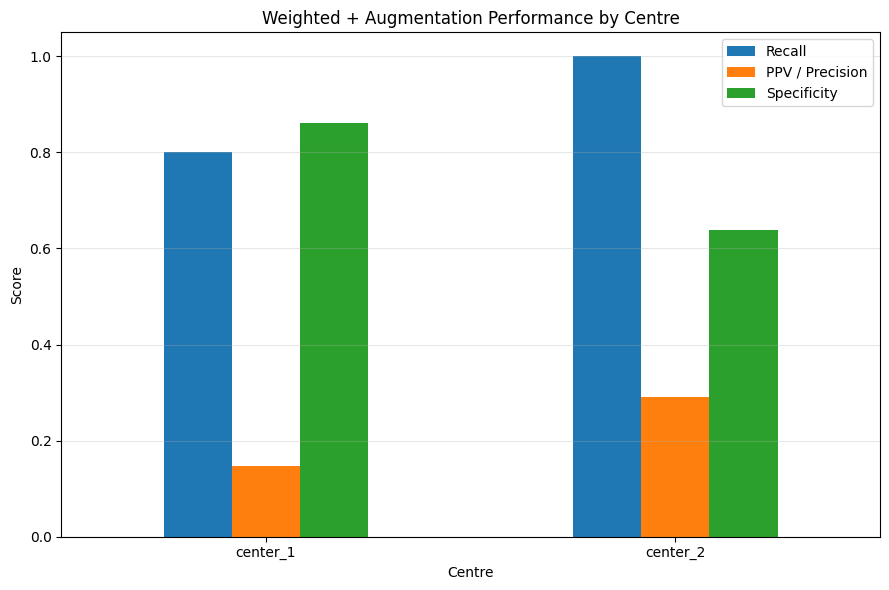

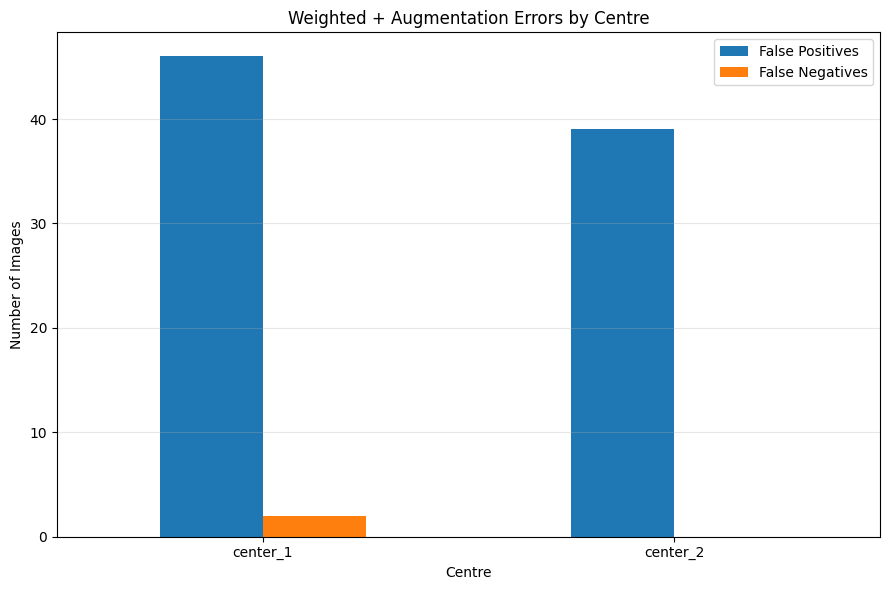


HIGH-RECALL CENTRE-WISE SUMMARY

center_1
Total images: 344
Neoplasia images: 10
Recall: 0.8
PPV: 0.1481
Specificity: 0.8623
False positives: 46
False negatives: 2

center_2
Total images: 124
Neoplasia images: 16
Recall: 1.0
PPV: 0.2909
Specificity: 0.6389
False positives: 39
False negatives: 0

MISSED NEOPLASIA CASES BY CENTRE
center_name
center_1    2
Name: count, dtype: int64

FALSE POSITIVES BY CENTRE
center_name
center_1    46
center_2    39
Name: count, dtype: int64

Files saved:
/content/drive/MyDrive/RARE26/results/weighted_augmentation_per_center_test_metrics.csv
/content/drive/MyDrive/RARE26/results/weighted_augmentation_per_center_test_predictions.csv
/content/drive/MyDrive/RARE26/results/figures/weighted_augmentation_per_center_high_recall_scores.png
/content/drive/MyDrive/RARE26/results/figures/weighted_augmentation_per_center_high_recall_errors.png


In [ ]:
# ================================================================
# EXPERIMENT 6 — CROSS-CENTRE ROBUSTNESS
# Part 1: Current best model ka per-centre test analysis
# ================================================================

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from IPython.display import display as show_table

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
)


# -------------------------------------------------
# Folders and file paths
# -------------------------------------------------
results_folder = Path(
    "/content/drive/MyDrive/RARE26/results"
)

figures_folder = results_folder / "figures"

figures_folder.mkdir(
    parents=True,
    exist_ok=True
)


test_manifest_path = Path(
    "/content/drive/MyDrive/RARE26/splits/"
    "test_colab.csv"
)

test_predictions_path = Path(
    "/content/drive/MyDrive/RARE26/results/"
    "resnet18_weighted_augmentation_test_predictions.csv"
)


per_center_metrics_path = Path(
    "/content/drive/MyDrive/RARE26/results/"
    "weighted_augmentation_per_center_test_metrics.csv"
)

per_center_predictions_path = Path(
    "/content/drive/MyDrive/RARE26/results/"
    "weighted_augmentation_per_center_test_predictions.csv"
)

scores_graph_path = Path(
    "/content/drive/MyDrive/RARE26/results/figures/"
    "weighted_augmentation_per_center_high_recall_scores.png"
)

errors_graph_path = Path(
    "/content/drive/MyDrive/RARE26/results/figures/"
    "weighted_augmentation_per_center_high_recall_errors.png"
)


# -------------------------------------------------
# Read test manifest and saved predictions
# -------------------------------------------------
test_df = pd.read_csv(
    test_manifest_path
)

predictions_df = pd.read_csv(
    test_predictions_path
)


print("=" * 80)
print("TEST FILE CHECK")
print("=" * 80)

print("Test manifest rows:", len(test_df))
print("Prediction rows:", len(predictions_df))

print("\nTest manifest columns:")
print(list(test_df.columns))

print("\nPrediction file columns:")
print(list(predictions_df.columns))


# -------------------------------------------------
# Verify same number of rows
# -------------------------------------------------
if len(test_df) != len(predictions_df):
    raise ValueError(
        "Test manifest aur prediction file ki row count match nahi karti."
    )


# -------------------------------------------------
# Find label column automatically
# -------------------------------------------------
possible_label_columns = [
    "label",
    "target",
    "class_id",
    "class",
    "y",
]

label_column = None

for column_name in possible_label_columns:
    if column_name in test_df.columns:
        label_column = column_name
        break


if label_column is None:
    raise ValueError(
        "Test manifest mein label column nahi mila. "
        f"Available columns: {list(test_df.columns)}"
    )


print("\nDetected label column:", label_column)


# -------------------------------------------------
# Verify test order using saved true labels
# -------------------------------------------------
manifest_labels = (
    test_df[label_column]
    .astype(int)
    .to_numpy()
)

saved_labels = (
    predictions_df["true_label"]
    .astype(int)
    .to_numpy()
)


if not np.array_equal(
    manifest_labels,
    saved_labels
):
    raise ValueError(
        "Test manifest aur saved predictions ka order match nahi karta."
    )


print("Labels and row order successfully verified.")


# -------------------------------------------------
# Function for normalizing centre names
# -------------------------------------------------
def normalize_center_name(value):

    value_string = str(value).lower().strip()

    match = re.search(
        r"(?:center|centre)[_\-\s/\\]?([12])",
        value_string
    )

    if match:
        return f"center_{match.group(1)}"

    if value_string in ["1", "1.0"]:
        return "center_1"

    if value_string in ["2", "2.0"]:
        return "center_2"

    return np.nan


# -------------------------------------------------
# First try direct centre columns
# -------------------------------------------------
possible_center_columns = [
    "center",
    "centre",
    "center_name",
    "centre_name",
    "site",
    "hospital",
]

center_column = None
center_series = None


for column_name in possible_center_columns:

    if column_name in test_df.columns:

        temporary_series = test_df[
            column_name
        ].apply(normalize_center_name)

        if temporary_series.notna().sum() == len(test_df):

            center_column = column_name
            center_series = temporary_series
            break


# -------------------------------------------------
# If no direct centre column, detect it from paths
# -------------------------------------------------
if center_series is None:

    for column_name in test_df.columns:

        if (
            test_df[column_name].dtype == "object"
            or pd.api.types.is_string_dtype(
                test_df[column_name]
            )
        ):

            temporary_series = test_df[
                column_name
            ].apply(normalize_center_name)

            if temporary_series.notna().sum() == len(test_df):

                center_column = column_name
                center_series = temporary_series
                break


if center_series is None:

    raise ValueError(
        "Center 1 aur Center 2 image paths se identify nahi hue. "
        f"Available columns: {list(test_df.columns)}"
    )


test_df["center_name"] = center_series


print("\nCentre information detected from column:")
print(center_column)

print("\nCentre distribution:")
print(
    test_df["center_name"].value_counts()
)


# -------------------------------------------------
# Add saved probabilities
# -------------------------------------------------
test_df["true_label"] = saved_labels

test_df["neoplasia_probability"] = (
    predictions_df[
        "neoplasia_probability"
    ].astype(float).to_numpy()
)


# -------------------------------------------------
# Thresholds
# -------------------------------------------------
default_threshold = 0.5

# Weighted + augmentation model ka
# validation-selected high-recall threshold
high_recall_threshold = (
    0.022335337474942207
)


test_df["default_prediction"] = (
    test_df["neoplasia_probability"]
    >= default_threshold
).astype(int)

test_df["high_recall_prediction"] = (
    test_df["neoplasia_probability"]
    >= high_recall_threshold
).astype(int)


# -------------------------------------------------
# Metrics function
# -------------------------------------------------
def calculate_per_center_metrics(
    center_data,
    prediction_column,
    threshold
):

    labels = (
        center_data["true_label"]
        .astype(int)
        .to_numpy()
    )

    predictions = (
        center_data[prediction_column]
        .astype(int)
        .to_numpy()
    )

    probabilities = (
        center_data[
            "neoplasia_probability"
        ].astype(float).to_numpy()
    )


    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()


    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )


    if len(np.unique(labels)) == 2:

        auroc = roc_auc_score(
            labels,
            probabilities
        )

        auprc = average_precision_score(
            labels,
            probabilities
        )

    else:

        auroc = np.nan
        auprc = np.nan


    return {
        "total_images": int(len(center_data)),

        "normal_images": int(
            (labels == 0).sum()
        ),

        "neoplasia_images": int(
            (labels == 1).sum()
        ),

        "threshold": float(threshold),

        "accuracy": float(
            accuracy_score(
                labels,
                predictions
            )
        ),

        "precision": float(
            precision_score(
                labels,
                predictions,
                zero_division=0
            )
        ),

        "recall": float(
            recall_score(
                labels,
                predictions,
                zero_division=0
            )
        ),

        "specificity": float(specificity),

        "auroc": float(auroc),

        "auprc": float(auprc),

        "true_negatives": int(tn),

        "false_positives": int(fp),

        "false_negatives": int(fn),

        "true_positives": int(tp),
    }


# -------------------------------------------------
# Calculate results for both centres
# and both thresholds
# -------------------------------------------------
center_results = []


evaluation_settings = [
    {
        "evaluation":
            "default_threshold",

        "prediction_column":
            "default_prediction",

        "threshold":
            default_threshold,
    },

    {
        "evaluation":
            "validation_selected_90_recall",

        "prediction_column":
            "high_recall_prediction",

        "threshold":
            high_recall_threshold,
    },
]


for evaluation_setting in evaluation_settings:

    for center_name in sorted(
        test_df["center_name"].unique()
    ):

        center_data = test_df[
            test_df["center_name"]
            == center_name
        ].copy()


        center_metrics = (
            calculate_per_center_metrics(
                center_data=center_data,

                prediction_column=(
                    evaluation_setting[
                        "prediction_column"
                    ]
                ),

                threshold=(
                    evaluation_setting[
                        "threshold"
                    ]
                ),
            )
        )


        center_metrics["center"] = center_name

        center_metrics["evaluation"] = (
            evaluation_setting[
                "evaluation"
            ]
        )


        center_results.append(
            center_metrics
        )


center_results_df = pd.DataFrame(
    center_results
)


center_results_df = center_results_df[
    [
        "center",
        "evaluation",
        "total_images",
        "normal_images",
        "neoplasia_images",
        "threshold",
        "accuracy",
        "precision",
        "recall",
        "specificity",
        "auroc",
        "auprc",
        "true_negatives",
        "false_positives",
        "false_negatives",
        "true_positives",
    ]
]


# -------------------------------------------------
# Save metrics and detailed predictions
# -------------------------------------------------
center_results_df.to_csv(
    per_center_metrics_path,
    index=False
)

test_df.to_csv(
    per_center_predictions_path,
    index=False
)


print("\n" + "=" * 80)
print("PER-CENTRE TEST RESULTS")
print("=" * 80)

show_table(
    center_results_df
)


# -------------------------------------------------
# High-recall results only
# -------------------------------------------------
high_recall_center_df = center_results_df[
    center_results_df["evaluation"]
    == "validation_selected_90_recall"
].copy()

high_recall_center_df = (
    high_recall_center_df.set_index(
        "center"
    )
)


# -------------------------------------------------
# Graph 1: Recall, PPV and specificity
# -------------------------------------------------
high_recall_center_df[
    [
        "recall",
        "precision",
        "specificity",
    ]
].plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title(
    "Weighted + Augmentation Performance by Centre"
)

plt.xlabel("Centre")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)

plt.legend(
    [
        "Recall",
        "PPV / Precision",
        "Specificity",
    ]
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    scores_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# -------------------------------------------------
# Graph 2: False positives and false negatives
# -------------------------------------------------
high_recall_center_df[
    [
        "false_positives",
        "false_negatives",
    ]
].plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title(
    "Weighted + Augmentation Errors by Centre"
)

plt.xlabel("Centre")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)

plt.legend(
    [
        "False Positives",
        "False Negatives",
    ]
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    errors_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# -------------------------------------------------
# Simple summary
# -------------------------------------------------
print("\n" + "=" * 80)
print("HIGH-RECALL CENTRE-WISE SUMMARY")
print("=" * 80)


for center_name in high_recall_center_df.index:

    row = high_recall_center_df.loc[
        center_name
    ]

    print(f"\n{center_name}")

    print(
        "Total images:",
        int(row["total_images"])
    )

    print(
        "Neoplasia images:",
        int(row["neoplasia_images"])
    )

    print(
        "Recall:",
        round(row["recall"], 4)
    )

    print(
        "PPV:",
        round(row["precision"], 4)
    )

    print(
        "Specificity:",
        round(row["specificity"], 4)
    )

    print(
        "False positives:",
        int(row["false_positives"])
    )

    print(
        "False negatives:",
        int(row["false_negatives"])
    )


# -------------------------------------------------
# Identify missed neoplasia cases
# -------------------------------------------------
missed_neoplasia_df = test_df[
    (test_df["true_label"] == 1)
    &
    (test_df["high_recall_prediction"] == 0)
].copy()


false_positive_df = test_df[
    (test_df["true_label"] == 0)
    &
    (test_df["high_recall_prediction"] == 1)
].copy()


print("\n" + "=" * 80)
print("MISSED NEOPLASIA CASES BY CENTRE")
print("=" * 80)

if len(missed_neoplasia_df) == 0:

    print("Koi neoplasia image miss nahi hui.")

else:

    print(
        missed_neoplasia_df[
            "center_name"
        ].value_counts()
    )


print("\n" + "=" * 80)
print("FALSE POSITIVES BY CENTRE")
print("=" * 80)

print(
    false_positive_df[
        "center_name"
    ].value_counts()
)


print("\nFiles saved:")

print(per_center_metrics_path)
print(per_center_predictions_path)
print(scores_graph_path)
print(errors_graph_path)

In [ ]:
# ================================================================
# EXPERIMENT 6 — TRUE CROSS-CENTRE EXTERNAL VALIDATION
#
# Direction 1:
# Train/Validate on Center 1 -> Test on all Center 2 images
#
# Direction 2:
# Train/Validate on Center 2 -> Test on all Center 1 images
# ================================================================

import re
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
)
from IPython.display import display as show_table


# -------------------------------------------------
# Reproducibility
# -------------------------------------------------
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# -------------------------------------------------
# Folders
# -------------------------------------------------
drive_folder = Path(
    "/content/drive/MyDrive/RARE26"
)

splits_folder = drive_folder / "splits"
models_folder = drive_folder / "models"
results_folder = drive_folder / "results"
figures_folder = results_folder / "figures"

models_folder.mkdir(
    parents=True,
    exist_ok=True
)

results_folder.mkdir(
    parents=True,
    exist_ok=True
)

figures_folder.mkdir(
    parents=True,
    exist_ok=True
)


# -------------------------------------------------
# Read all existing deduplicated split files
# -------------------------------------------------
train_manifest = pd.read_csv(
    splits_folder / "train_colab.csv"
)

validation_manifest = pd.read_csv(
    splits_folder / "validation_colab.csv"
)

test_manifest = pd.read_csv(
    splits_folder / "test_colab.csv"
)

all_images_df = pd.concat(
    [
        train_manifest,
        validation_manifest,
        test_manifest,
    ],
    ignore_index=True
)

print("Total combined unique images:", len(all_images_df))
print("Available columns:", list(all_images_df.columns))


# -------------------------------------------------
# Detect path column
# -------------------------------------------------
possible_path_columns = [
    "filepath",
    "file_path",
    "image_path",
    "path",
    "image",
    "filename",
]

path_column = None

for column_name in possible_path_columns:
    if column_name in all_images_df.columns:
        path_column = column_name
        break

if path_column is None:
    raise ValueError(
        "Image path column nahi mila. "
        f"Available columns: {list(all_images_df.columns)}"
    )


# -------------------------------------------------
# Detect label column
# -------------------------------------------------
possible_label_columns = [
    "label",
    "target",
    "class_id",
    "class",
]

label_column = None

for column_name in possible_label_columns:
    if column_name in all_images_df.columns:
        label_column = column_name
        break

if label_column is None:
    raise ValueError(
        "Label column nahi mila. "
        f"Available columns: {list(all_images_df.columns)}"
    )

all_images_df[label_column] = (
    all_images_df[label_column]
    .astype(int)
)

print("Detected path column:", path_column)
print("Detected label column:", label_column)


# -------------------------------------------------
# Detect centre from image path
# -------------------------------------------------
def extract_center(value):

    value = str(value).lower()

    match = re.search(
        r"(?:center|centre)[_\-\s/\\]?([12])",
        value
    )

    if match:
        return f"center_{match.group(1)}"

    return np.nan


all_images_df["center_name"] = (
    all_images_df[path_column]
    .apply(extract_center)
)

if all_images_df["center_name"].isna().any():

    missing_count = int(
        all_images_df["center_name"]
        .isna()
        .sum()
    )

    raise ValueError(
        f"{missing_count} images ka centre identify nahi hua."
    )


# Remove accidental repeated paths, if any
all_images_df = (
    all_images_df
    .drop_duplicates(
        subset=[path_column]
    )
    .reset_index(drop=True)
)


print("\nComplete centre/class distribution:")

print(
    pd.crosstab(
        all_images_df["center_name"],
        all_images_df[label_column]
    )
)


# -------------------------------------------------
# Image transforms
# -------------------------------------------------
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=8
    ),

    transforms.ColorJitter(
        brightness=0.12,
        contrast=0.12,
        saturation=0.08,
        hue=0.02
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])


evaluation_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])


# -------------------------------------------------
# Standalone dataset class
# -------------------------------------------------
class CrossCenterDataset(Dataset):

    def __init__(
        self,
        dataframe,
        path_column,
        label_column,
        transform=None
    ):

        self.dataframe = (
            dataframe.reset_index(drop=True)
        )

        self.path_column = path_column
        self.label_column = label_column
        self.transform = transform


    def __len__(self):

        return len(self.dataframe)


    def __getitem__(self, index):

        image_path = str(
            self.dataframe.loc[
                index,
                self.path_column
            ]
        )

        image_path = image_path.replace(
            "\\",
            "/"
        )

        image = Image.open(
            image_path
        ).convert("RGB")

        label = int(
            self.dataframe.loc[
                index,
                self.label_column
            ]
        )

        if self.transform is not None:
            image = self.transform(image)

        return image, label


# -------------------------------------------------
# Validation evaluation function
# -------------------------------------------------
def evaluate_model(
    model,
    data_loader,
    criterion
):

    model.eval()

    total_loss = 0.0
    labels_list = []
    probabilities_list = []
    predictions_list = []

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            probabilities = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            total_loss += (
                loss.item()
                * images.size(0)
            )

            labels_list.extend(
                labels.cpu().numpy()
            )

            probabilities_list.extend(
                probabilities.cpu().numpy()
            )

            predictions_list.extend(
                predictions.cpu().numpy()
            )

    return {
        "loss": (
            total_loss
            / len(data_loader.dataset)
        ),

        "accuracy": accuracy_score(
            labels_list,
            predictions_list
        ),

        "precision": precision_score(
            labels_list,
            predictions_list,
            zero_division=0
        ),

        "recall": recall_score(
            labels_list,
            predictions_list,
            zero_division=0
        ),

        "auroc": roc_auc_score(
            labels_list,
            probabilities_list
        ),

        "auprc": average_precision_score(
            labels_list,
            probabilities_list
        ),
    }


# -------------------------------------------------
# Collect probabilities
# -------------------------------------------------
def collect_predictions(
    model,
    data_loader
):

    model.eval()

    labels_list = []
    probabilities_list = []

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )[:, 1]

            labels_list.extend(
                labels.numpy()
            )

            probabilities_list.extend(
                probabilities
                .cpu()
                .numpy()
            )

    return (
        np.array(labels_list),
        np.array(probabilities_list)
    )


# -------------------------------------------------
# Final metrics function
# -------------------------------------------------
def calculate_metrics(
    labels,
    probabilities,
    threshold
):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )

    return {
        "threshold": float(threshold),

        "accuracy": float(
            accuracy_score(
                labels,
                predictions
            )
        ),

        "precision": float(
            precision_score(
                labels,
                predictions,
                zero_division=0
            )
        ),

        "recall": float(
            recall_score(
                labels,
                predictions,
                zero_division=0
            )
        ),

        "specificity": float(
            specificity
        ),

        "auroc": float(
            roc_auc_score(
                labels,
                probabilities
            )
        ),

        "auprc": float(
            average_precision_score(
                labels,
                probabilities
            )
        ),

        "true_negatives": int(tn),
        "false_positives": int(fp),
        "false_negatives": int(fn),
        "true_positives": int(tp),
    }


# -------------------------------------------------
# One complete cross-centre direction
# -------------------------------------------------
def run_cross_center_experiment(
    source_center,
    target_center
):

    direction_name = (
        f"{source_center}_to_{target_center}"
    )

    print("\n" + "=" * 90)
    print(
        f"CROSS-CENTRE DIRECTION: "
        f"{source_center} -> {target_center}"
    )
    print("=" * 90)


    # ---------------------------------------------
    # Source and target data
    # ---------------------------------------------
    source_df = all_images_df[
        all_images_df["center_name"]
        == source_center
    ].copy()

    target_df = all_images_df[
        all_images_df["center_name"]
        == target_center
    ].copy()


    # Source centre only:
    # 80% training, 20% validation
    source_train_df, source_val_df = (
        train_test_split(
            source_df,
            test_size=0.20,
            random_state=42,
            stratify=source_df[label_column]
        )
    )


    source_train_df = (
        source_train_df
        .reset_index(drop=True)
    )

    source_val_df = (
        source_val_df
        .reset_index(drop=True)
    )

    target_df = (
        target_df
        .reset_index(drop=True)
    )


    print(
        "Source training images:",
        len(source_train_df)
    )

    print(
        "Source validation images:",
        len(source_val_df)
    )

    print(
        "External target test images:",
        len(target_df)
    )


    print("\nSource training class counts:")

    print(
        source_train_df[
            label_column
        ].value_counts()
    )


    print("\nExternal test class counts:")

    print(
        target_df[
            label_column
        ].value_counts()
    )


    # Save exact cross-centre splits
    source_train_df.to_csv(
        splits_folder
        / f"{direction_name}_source_train.csv",
        index=False
    )

    source_val_df.to_csv(
        splits_folder
        / f"{direction_name}_source_validation.csv",
        index=False
    )

    target_df.to_csv(
        splits_folder
        / f"{direction_name}_external_test.csv",
        index=False
    )


    # ---------------------------------------------
    # Datasets and loaders
    # ---------------------------------------------
    source_train_dataset = CrossCenterDataset(
        source_train_df,
        path_column,
        label_column,
        transform=train_transform
    )

    source_val_dataset = CrossCenterDataset(
        source_val_df,
        path_column,
        label_column,
        transform=evaluation_transform
    )

    target_test_dataset = CrossCenterDataset(
        target_df,
        path_column,
        label_column,
        transform=evaluation_transform
    )


    source_train_loader = DataLoader(
        source_train_dataset,
        batch_size=32,
        shuffle=True,
        num_workers=2,
        pin_memory=True
    )

    source_val_loader = DataLoader(
        source_val_dataset,
        batch_size=32,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    target_test_loader = DataLoader(
        target_test_dataset,
        batch_size=32,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )


    # ---------------------------------------------
    # Source-specific class weights
    # ---------------------------------------------
    normal_count = int(
        (
            source_train_df[label_column]
            == 0
        ).sum()
    )

    neo_count = int(
        (
            source_train_df[label_column]
            == 1
        ).sum()
    )

    total_count = (
        normal_count + neo_count
    )

    normal_weight = (
        total_count
        / (2 * normal_count)
    )

    neo_weight = (
        total_count
        / (2 * neo_count)
    )

    class_weights = torch.tensor(
        [
            normal_weight,
            neo_weight,
        ],
        dtype=torch.float32,
        device=device
    )


    print("\nClass weights:")

    print(
        "Normal weight:",
        normal_weight
    )

    print(
        "Neoplasia weight:",
        neo_weight
    )


    # ---------------------------------------------
    # Fresh model
    # ---------------------------------------------
    model = resnet18(
        weights=ResNet18_Weights.DEFAULT
    )

    model.fc = nn.Linear(
        model.fc.in_features,
        2
    )

    model = model.to(device)


    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=0.0001,
        weight_decay=0.0001
    )


    best_model_path = (
        models_folder
        / f"resnet18_cross_center_{direction_name}_best.pth"
    )

    history_path = (
        results_folder
        / f"cross_center_{direction_name}_history.csv"
    )

    metrics_path = (
        results_folder
        / f"cross_center_{direction_name}_test_metrics.csv"
    )

    predictions_path = (
        results_folder
        / f"cross_center_{direction_name}_test_predictions.csv"
    )


    # ---------------------------------------------
    # Training
    # ---------------------------------------------
    number_of_epochs = 10
    best_validation_auprc = -1.0
    history = []

    print("\nTraining start ho rahi hai...")

    for epoch in range(
        1,
        number_of_epochs + 1
    ):

        start_time = time.time()

        model.train()

        running_loss = 0.0
        total_samples = 0

        for images, labels in source_train_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            loss.backward()
            optimizer.step()

            running_loss += (
                loss.item()
                * images.size(0)
            )

            total_samples += (
                labels.size(0)
            )


        train_loss = (
            running_loss
            / total_samples
        )


        validation_metrics = evaluate_model(
            model,
            source_val_loader,
            criterion
        )


        epoch_seconds = (
            time.time() - start_time
        )


        epoch_record = {
            "epoch": epoch,
            "train_loss": train_loss,
            "val_loss":
                validation_metrics["loss"],
            "val_accuracy":
                validation_metrics["accuracy"],
            "val_precision":
                validation_metrics["precision"],
            "val_recall":
                validation_metrics["recall"],
            "val_auroc":
                validation_metrics["auroc"],
            "val_auprc":
                validation_metrics["auprc"],
            "epoch_seconds":
                epoch_seconds,
        }


        history.append(
            epoch_record
        )


        pd.DataFrame(
            history
        ).to_csv(
            history_path,
            index=False
        )


        if (
            validation_metrics["auprc"]
            > best_validation_auprc
        ):

            best_validation_auprc = (
                validation_metrics["auprc"]
            )

            torch.save(
                {
                    "epoch": epoch,

                    "model_state_dict":
                        model.state_dict(),

                    "optimizer_state_dict":
                        optimizer.state_dict(),

                    "validation_metrics":
                        validation_metrics,

                    "source_center":
                        source_center,

                    "target_center":
                        target_center,

                    "class_weights":
                        class_weights.cpu(),
                },
                best_model_path
            )

            best_message = (
                " <-- Best model saved"
            )

        else:

            best_message = ""


        print(
            f"Epoch {epoch:02d}/10 | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Recall: "
            f"{validation_metrics['recall']:.4f} | "
            f"Val Precision: "
            f"{validation_metrics['precision']:.4f} | "
            f"Val AUROC: "
            f"{validation_metrics['auroc']:.4f} | "
            f"Val AUPRC: "
            f"{validation_metrics['auprc']:.4f} | "
            f"Time: {epoch_seconds:.1f}s"
            f"{best_message}"
        )


    # ---------------------------------------------
    # Load best model
    # ---------------------------------------------
    best_checkpoint = torch.load(
        best_model_path,
        map_location=device,
        weights_only=False
    )

    best_model = resnet18(
        weights=None
    )

    best_model.fc = nn.Linear(
        best_model.fc.in_features,
        2
    )

    best_model.load_state_dict(
        best_checkpoint[
            "model_state_dict"
        ]
    )

    best_model = best_model.to(device)
    best_model.eval()


    print(
        "\nBest checkpoint epoch:",
        best_checkpoint["epoch"]
    )

    print(
        "Best source validation AUPRC:",
        best_checkpoint[
            "validation_metrics"
        ]["auprc"]
    )


    # ---------------------------------------------
    # Source validation probabilities
    # ---------------------------------------------
    validation_labels, validation_probs = (
        collect_predictions(
            best_model,
            source_val_loader
        )
    )


    # ---------------------------------------------
    # Select threshold using source validation only
    # ---------------------------------------------
    precision_values, recall_values, thresholds = (
        precision_recall_curve(
            validation_labels,
            validation_probs
        )
    )

    valid_indices = np.where(
        recall_values[:-1] >= 0.90
    )[0]


    if len(valid_indices) > 0:

        best_threshold_index = valid_indices[
            np.argmax(
                precision_values[:-1][
                    valid_indices
                ]
            )
        ]

        high_recall_threshold = float(
            thresholds[
                best_threshold_index
            ]
        )

        selected_val_recall = float(
            recall_values[
                best_threshold_index
            ]
        )

        selected_val_precision = float(
            precision_values[
                best_threshold_index
            ]
        )

    else:

        high_recall_threshold = 0.5
        selected_val_recall = 0.0
        selected_val_precision = 0.0


    print(
        "\nSource-validation selected threshold:",
        high_recall_threshold
    )

    print(
        "Source-validation recall:",
        selected_val_recall
    )

    print(
        "Source-validation precision:",
        selected_val_precision
    )


    # ---------------------------------------------
    # External target-centre predictions
    # ---------------------------------------------
    target_labels, target_probs = (
        collect_predictions(
            best_model,
            target_test_loader
        )
    )


    default_metrics = calculate_metrics(
        target_labels,
        target_probs,
        threshold=0.5
    )

    high_recall_metrics = calculate_metrics(
        target_labels,
        target_probs,
        threshold=high_recall_threshold
    )


    print("\n" + "-" * 75)

    print(
        f"{source_center} -> {target_center} "
        "EXTERNAL TEST: DEFAULT THRESHOLD"
    )

    print("-" * 75)

    for key, value in default_metrics.items():
        print(f"{key}: {value}")


    print("\n" + "-" * 75)

    print(
        f"{source_center} -> {target_center} "
        "EXTERNAL TEST: HIGH-RECALL THRESHOLD"
    )

    print("-" * 75)

    for key, value in high_recall_metrics.items():
        print(f"{key}: {value}")


    # ---------------------------------------------
    # Save metrics
    # ---------------------------------------------
    metrics_df = pd.DataFrame([
        {
            "direction": direction_name,
            "source_center": source_center,
            "target_center": target_center,
            "evaluation": "default_threshold",
            **default_metrics,
        },

        {
            "direction": direction_name,
            "source_center": source_center,
            "target_center": target_center,
            "evaluation":
                "source_validation_selected_90_recall",
            **high_recall_metrics,
        },
    ])

    metrics_df.to_csv(
        metrics_path,
        index=False
    )


    # Save external predictions
    predictions_df = target_df[
        [
            path_column,
            label_column,
            "center_name",
        ]
    ].copy()

    predictions_df = (
        predictions_df.reset_index(
            drop=True
        )
    )

    predictions_df[
        "neoplasia_probability"
    ] = target_probs

    predictions_df[
        "default_prediction"
    ] = (
        target_probs >= 0.5
    ).astype(int)

    predictions_df[
        "high_recall_prediction"
    ] = (
        target_probs
        >= high_recall_threshold
    ).astype(int)

    predictions_df.to_csv(
        predictions_path,
        index=False
    )


    print("\nFiles saved:")

    print(best_model_path)
    print(history_path)
    print(metrics_path)
    print(predictions_path)


    return metrics_df


# ================================================================
# RUN BOTH DIRECTIONS
# ================================================================

center1_to_center2_results = (
    run_cross_center_experiment(
        source_center="center_1",
        target_center="center_2"
    )
)


center2_to_center1_results = (
    run_cross_center_experiment(
        source_center="center_2",
        target_center="center_1"
    )
)


# -------------------------------------------------
# Combine both directions
# -------------------------------------------------
combined_results_df = pd.concat(
    [
        center1_to_center2_results,
        center2_to_center1_results,
    ],
    ignore_index=True
)


combined_results_path = (
    results_folder
    / "cross_center_combined_results.csv"
)

combined_results_df.to_csv(
    combined_results_path,
    index=False
)


print("\n" + "=" * 90)
print("COMBINED CROSS-CENTRE RESULTS")
print("=" * 90)

show_table(
    combined_results_df
)


# -------------------------------------------------
# High-recall rows
# -------------------------------------------------
high_recall_results_df = combined_results_df[
    combined_results_df["evaluation"]
    == "source_validation_selected_90_recall"
].copy()


high_recall_results_df = (
    high_recall_results_df.set_index(
        "direction"
    )
)


# -------------------------------------------------
# Graph 1: scores
# -------------------------------------------------
high_recall_results_df[
    [
        "recall",
        "precision",
        "specificity",
    ]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "True Cross-Centre External Validation"
)

plt.xlabel("Training Centre → Testing Centre")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)

plt.legend(
    [
        "Recall",
        "PPV / Precision",
        "Specificity",
    ]
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()


cross_center_scores_path = (
    figures_folder
    / "true_cross_center_high_recall_scores.png"
)

plt.savefig(
    cross_center_scores_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# -------------------------------------------------
# Graph 2: errors
# -------------------------------------------------
high_recall_results_df[
    [
        "false_positives",
        "false_negatives",
    ]
].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title(
    "True Cross-Centre External Validation Errors"
)

plt.xlabel("Training Centre → Testing Centre")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)

plt.legend(
    [
        "False Positives",
        "False Negatives",
    ]
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()


cross_center_errors_path = (
    figures_folder
    / "true_cross_center_high_recall_errors.png"
)

plt.savefig(
    cross_center_errors_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


print("\nFinal files saved:")

print(combined_results_path)
print(cross_center_scores_path)
print(cross_center_errors_path)

Device: cuda
Total combined unique images: 3088
Available columns: ['file_path', 'relative_path', 'center', 'class', 'label', 'sha256', 'split', 'colab_path', 'file_exists']
Detected path column: file_path
Detected label column: label

Complete centre/class distribution:
label           0   1
center_name          
center_1     2218  61
center_2      712  97

CROSS-CENTRE DIRECTION: center_1 -> center_2
Source training images: 1823
Source validation images: 456
External target test images: 809

Source training class counts:
label
0    1774
1      49
Name: count, dtype: int64

External test class counts:
label
0    712
1     97
Name: count, dtype: int64

Class weights:
Normal weight: 0.5138105975197295
Neoplasia weight: 18.602040816326532

Training start ho rahi hai...


FileNotFoundError: Caught FileNotFoundError in DataLoader worker process 0.
Original Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/_utils/worker.py", line 358, in _worker_loop
    data = fetcher.fetch(index)  # type: ignore[possibly-undefined]
           ^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/_utils/fetch.py", line 54, in fetch
    data = [self.dataset[idx] for idx in possibly_batched_index]
            ~~~~~~~~~~~~^^^^^
  File "/tmp/ipykernel_6065/984017954.py", line 306, in __getitem__
    image = Image.open(
            ^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/PIL/Image.py", line 3513, in open
    fp = builtins.open(filename, "rb")
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
FileNotFoundError: [Errno 2] No such file or directory: 'C:/thesis/dataset/RARE25-train-data/center_1/ndbe/742c57adb6e148bf9043f3c3e4d755d6.png'


Device: cuda

COMBINED DATASET CHECK
Total rows before duplicate path check: 3088
Available columns: ['file_path', 'relative_path', 'center', 'class', 'label', 'sha256', 'split', 'colab_path', 'file_exists']
Total unique image paths: 3088
Available Colab image paths: 3088
Missing Colab image paths: 0

Complete centre/class distribution:


label,0,1
center_name,,
center_1,2218,61
center_2,712,97



Expected total unique images: 3088

CROSS-CENTRE DIRECTION: center_1 -> center_2
Source training images: 1823
Source validation images: 456
External target test images: 809

Source training class counts:
label
0    1774
1      49
Name: count, dtype: int64

Source validation class counts:
label
0    444
1     12
Name: count, dtype: int64

External test class counts:
label
0    712
1     97
Name: count, dtype: int64

Source-specific class weights:
Normal weight: 0.5138105975197295
Neoplasia weight: 18.602040816326532

Training start ho rahi hai...
-----------------------------------------------------------------------------------------------
Epoch 01/10 | Train Loss: 0.5914 | Train Acc: 0.6829 | Val Loss: 0.7960 | Val Recall: 0.2500 | Val Precision: 0.1364 | Val AUROC: 0.7050 | Val AUPRC: 0.2403 | Time: 43.9s  <-- Best model saved
Epoch 02/10 | Train Loss: 0.2986 | Train Acc: 0.8892 | Val Loss: 0.9067 | Val Recall: 0.2500 | Val Precision: 0.1667 | Val AUROC: 0.6547 | Val AUPRC: 0.2052 |

,direction,source_center,target_center,best_epoch,best_source_validation_auprc,source_validation_selected_recall,source_validation_selected_precision,evaluation,threshold,accuracy,precision,recall,specificity,auroc,auprc,true_negatives,false_positives,false_negatives,true_positives
0,center_1_to_center_2,center_1,center_2,5,0.307501,1.000000,0.026608,default_threshold,0.500000,0.915946,0.754386,0.443299,0.980337,0.881660,0.666324,698,14,54,43
1,center_1_to_center_2,center_1,center_2,5,0.307501,1.000000,0.026608,source_validation_selected_90_recall,0.000081,0.127318,0.120797,1.000000,0.008427,0.881660,0.666324,6,706,0,97
2,center_2_to_center_1,center_2,center_1,10,0.972108,0.947368,0.857143,default_threshold,0.500000,0.880211,0.144295,0.704918,0.885032,0.861247,0.426859,1963,255,18,43
3,center_2_to_center_1,center_2,center_1,10,0.972108,0.947368,0.857143,source_validation_selected_90_recall,0.910427,0.942519,0.246377,0.557377,0.953111,0.861247,0.426859,2114,104,27,34



TRUE CROSS-CENTRE HIGH-RECALL SUMMARY


,source_center,target_center,threshold,recall,precision,specificity,auroc,auprc,false_positives,false_negatives,true_positives,true_negatives
direction,,,,,,,,,,,,
center_1_to_center_2,center_1,center_2,0.000081,1.000000,0.120797,0.008427,0.881660,0.666324,706,0,97,6
center_2_to_center_1,center_2,center_1,0.910427,0.557377,0.246377,0.953111,0.861247,0.426859,104,27,34,2114


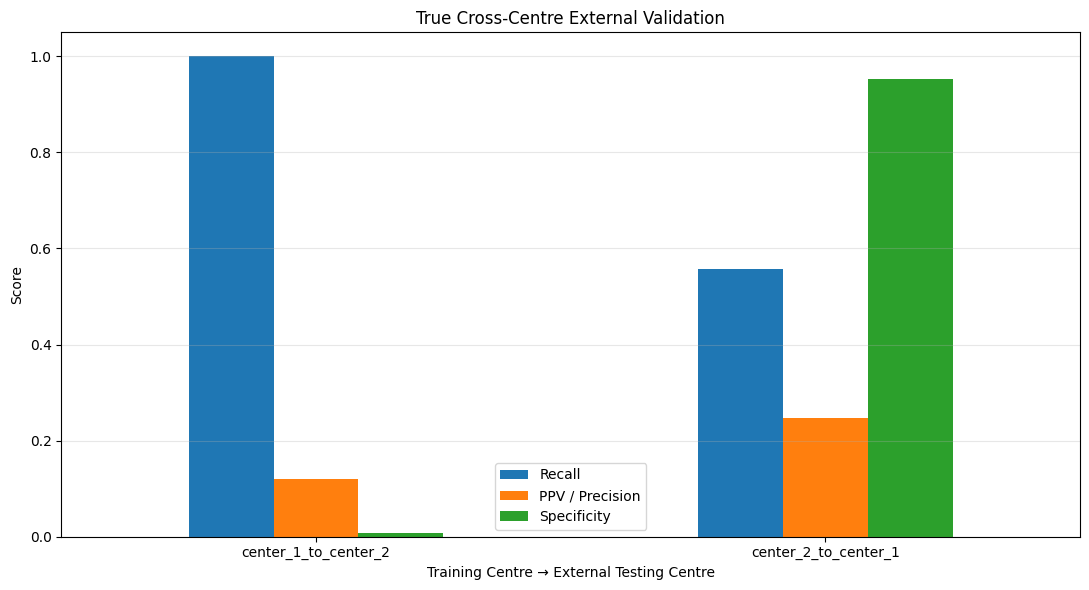

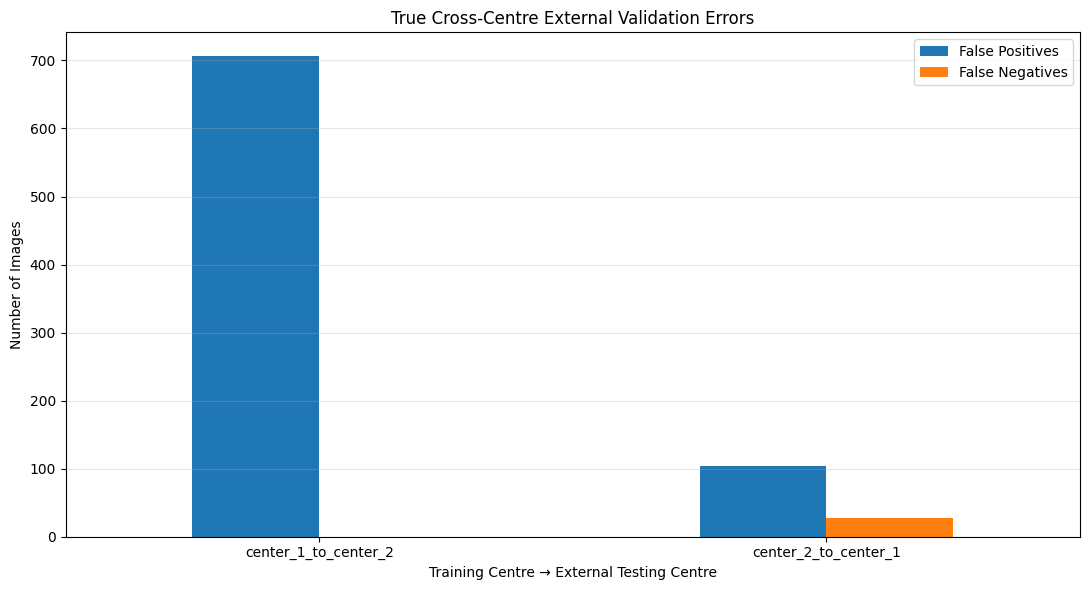


FINAL CROSS-CENTRE SUMMARY

Direction: center_1_to_center_2
External recall: 1.0
External PPV: 0.1208
External specificity: 0.0084
External AUROC: 0.8817
External AUPRC: 0.6663
False positives: 706
False negatives: 0

Direction: center_2_to_center_1
External recall: 0.5574
External PPV: 0.2464
External specificity: 0.9531
External AUROC: 0.8612
External AUPRC: 0.4269
False positives: 104
False negatives: 27

Final combined files saved:
/content/drive/MyDrive/RARE26/results/cross_center_combined_results.csv
/content/drive/MyDrive/RARE26/results/figures/true_cross_center_high_recall_scores.png
/content/drive/MyDrive/RARE26/results/figures/true_cross_center_high_recall_errors.png


In [ ]:
# ================================================================
# EXPERIMENT 6 — PART 2
# TRUE CROSS-CENTRE EXTERNAL VALIDATION
#
# Direction 1:
# Train/Validate on Center 1 -> Test on all Center 2 images
#
# Direction 2:
# Train/Validate on Center 2 -> Test on all Center 1 images
#
# Model setup:
# Weighted ResNet-18 + Mild Data Augmentation
# ================================================================

import re
import gc
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import (
    resnet18,
    ResNet18_Weights,
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
)
from IPython.display import display as show_table


# ================================================================
# 1. REPRODUCIBILITY
# ================================================================

def set_all_seeds(seed=42):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_all_seeds(42)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ================================================================
# 2. GOOGLE DRIVE FOLDERS
# ================================================================

drive_folder = Path(
    "/content/drive/MyDrive/RARE26"
)

splits_folder = drive_folder / "splits"
models_folder = drive_folder / "models"
results_folder = drive_folder / "results"
figures_folder = results_folder / "figures"


splits_folder.mkdir(
    parents=True,
    exist_ok=True
)

models_folder.mkdir(
    parents=True,
    exist_ok=True
)

results_folder.mkdir(
    parents=True,
    exist_ok=True
)

figures_folder.mkdir(
    parents=True,
    exist_ok=True
)


# ================================================================
# 3. READ ALL EXISTING DEDUPLICATED MANIFESTS
# ================================================================

train_manifest_path = (
    splits_folder / "train_colab.csv"
)

validation_manifest_path = (
    splits_folder / "validation_colab.csv"
)

test_manifest_path = (
    splits_folder / "test_colab.csv"
)


train_manifest = pd.read_csv(
    train_manifest_path
)

validation_manifest = pd.read_csv(
    validation_manifest_path
)

test_manifest = pd.read_csv(
    test_manifest_path
)


all_images_df = pd.concat(
    [
        train_manifest,
        validation_manifest,
        test_manifest,
    ],
    ignore_index=True
)


print("\n" + "=" * 90)
print("COMBINED DATASET CHECK")
print("=" * 90)

print(
    "Total rows before duplicate path check:",
    len(all_images_df)
)

print(
    "Available columns:",
    list(all_images_df.columns)
)


# ================================================================
# 4. USE CORRECT GOOGLE COLAB PATH COLUMN
# ================================================================

path_column = "colab_path"
label_column = "label"


if path_column not in all_images_df.columns:

    raise ValueError(
        "CSV files mein 'colab_path' column nahi mila. "
        f"Available columns: {list(all_images_df.columns)}"
    )


if label_column not in all_images_df.columns:

    raise ValueError(
        "CSV files mein 'label' column nahi mila. "
        f"Available columns: {list(all_images_df.columns)}"
    )


all_images_df[path_column] = (
    all_images_df[path_column]
    .astype(str)
    .str.replace(
        "\\",
        "/",
        regex=False
    )
)


all_images_df[label_column] = (
    all_images_df[label_column]
    .astype(int)
)


# Duplicate paths remove karna
all_images_df = (
    all_images_df
    .drop_duplicates(
        subset=[path_column]
    )
    .reset_index(drop=True)
)


print(
    "Total unique image paths:",
    len(all_images_df)
)


# ================================================================
# 5. VERIFY THAT COLAB IMAGE FILES EXIST
# ================================================================

path_exists_mask = all_images_df[
    path_column
].apply(
    lambda image_path: Path(
        image_path
    ).exists()
)


available_path_count = int(
    path_exists_mask.sum()
)

missing_path_count = int(
    (~path_exists_mask).sum()
)


print(
    "Available Colab image paths:",
    available_path_count
)

print(
    "Missing Colab image paths:",
    missing_path_count
)


if missing_path_count > 0:

    print("\nFirst missing paths:")

    print(
        all_images_df.loc[
            ~path_exists_mask,
            path_column
        ].head(10)
    )

    raise FileNotFoundError(
        "Dataset images /content mein available nahi hain. "
        "RARE25-train-data.zip ko dobara "
        "/content/RARE26_data mein extract karna hoga."
    )


# ================================================================
# 6. CENTRE NAME DETECTION
# ================================================================

def normalize_center_name(value):

    value_string = str(
        value
    ).lower().strip()

    match = re.search(
        r"(?:center|centre)[_\-\s/\\]?([12])",
        value_string
    )

    if match:

        return (
            f"center_{match.group(1)}"
        )

    if value_string in [
        "1",
        "1.0",
    ]:

        return "center_1"

    if value_string in [
        "2",
        "2.0",
    ]:

        return "center_2"

    return np.nan


# Pehle existing center column use karna
if "center" in all_images_df.columns:

    all_images_df["center_name"] = (
        all_images_df["center"]
        .apply(normalize_center_name)
    )

else:

    all_images_df["center_name"] = (
        all_images_df[path_column]
        .apply(normalize_center_name)
    )


# Agar center column se kuch missing ho,
# un rows ka centre path se detect karna
missing_center_mask = (
    all_images_df["center_name"]
    .isna()
)


if missing_center_mask.any():

    all_images_df.loc[
        missing_center_mask,
        "center_name"
    ] = (
        all_images_df.loc[
            missing_center_mask,
            path_column
        ].apply(
            normalize_center_name
        )
    )


remaining_missing_centers = int(
    all_images_df[
        "center_name"
    ].isna().sum()
)


if remaining_missing_centers > 0:

    raise ValueError(
        f"{remaining_missing_centers} images ka "
        "centre identify nahi hua."
    )


print("\nComplete centre/class distribution:")

center_class_table = pd.crosstab(
    all_images_df["center_name"],
    all_images_df[label_column]
)

show_table(
    center_class_table
)


print(
    "\nExpected total unique images:",
    len(all_images_df)
)


# ================================================================
# 7. IMAGE TRANSFORMS
# ================================================================

# Training images par mild augmentation
train_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=8
    ),

    transforms.ColorJitter(
        brightness=0.12,
        contrast=0.12,
        saturation=0.08,
        hue=0.02
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],

        std=[
            0.229,
            0.224,
            0.225
        ]
    ),
])


# Validation aur external test par
# augmentation nahi hogi
evaluation_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],

        std=[
            0.229,
            0.224,
            0.225
        ]
    ),
])


# ================================================================
# 8. DATASET CLASS
# ================================================================

class CrossCenterDataset(Dataset):

    def __init__(
        self,
        dataframe,
        path_column,
        label_column,
        transform=None
    ):

        self.dataframe = (
            dataframe
            .reset_index(drop=True)
            .copy()
        )

        self.path_column = (
            path_column
        )

        self.label_column = (
            label_column
        )

        self.transform = transform


    def __len__(self):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index
    ):

        image_path = str(
            self.dataframe.iloc[
                index
            ][self.path_column]
        ).replace(
            "\\",
            "/"
        )


        image = Image.open(
            image_path
        ).convert(
            "RGB"
        )


        label = int(
            self.dataframe.iloc[
                index
            ][self.label_column]
        )


        if self.transform is not None:

            image = self.transform(
                image
            )


        return image, label


# ================================================================
# 9. VALIDATION FUNCTION
# ================================================================

def evaluate_validation_model(
    model,
    data_loader,
    criterion
):

    model.eval()

    total_loss = 0.0

    labels_list = []
    probabilities_list = []
    predictions_list = []


    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )


            outputs = model(
                images
            )

            loss = criterion(
                outputs,
                labels
            )


            probabilities = torch.softmax(
                outputs,
                dim=1
            )[:, 1]


            predictions = torch.argmax(
                outputs,
                dim=1
            )


            total_loss += (
                loss.item()
                * images.size(0)
            )


            labels_list.extend(
                labels
                .cpu()
                .numpy()
            )

            probabilities_list.extend(
                probabilities
                .cpu()
                .numpy()
            )

            predictions_list.extend(
                predictions
                .cpu()
                .numpy()
            )


    average_loss = (
        total_loss
        / len(data_loader.dataset)
    )


    return {

        "loss": float(
            average_loss
        ),

        "accuracy": float(
            accuracy_score(
                labels_list,
                predictions_list
            )
        ),

        "precision": float(
            precision_score(
                labels_list,
                predictions_list,
                zero_division=0
            )
        ),

        "recall": float(
            recall_score(
                labels_list,
                predictions_list,
                zero_division=0
            )
        ),

        "auroc": float(
            roc_auc_score(
                labels_list,
                probabilities_list
            )
        ),

        "auprc": float(
            average_precision_score(
                labels_list,
                probabilities_list
            )
        ),
    }


# ================================================================
# 10. PREDICTION COLLECTION FUNCTION
# ================================================================

def collect_model_predictions(
    model,
    data_loader
):

    model.eval()

    labels_list = []
    probabilities_list = []


    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(
                device,
                non_blocking=True
            )


            outputs = model(
                images
            )


            probabilities = torch.softmax(
                outputs,
                dim=1
            )[:, 1]


            labels_list.extend(
                labels
                .cpu()
                .numpy()
            )


            probabilities_list.extend(
                probabilities
                .cpu()
                .numpy()
            )


    return (
        np.array(
            labels_list
        ),

        np.array(
            probabilities_list
        )
    )


# ================================================================
# 11. FINAL METRICS FUNCTION
# ================================================================

def calculate_test_metrics(
    labels,
    probabilities,
    threshold
):

    predictions = (
        probabilities >= threshold
    ).astype(int)


    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()


    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )


    return {

        "threshold": float(
            threshold
        ),

        "accuracy": float(
            accuracy_score(
                labels,
                predictions
            )
        ),

        "precision": float(
            precision_score(
                labels,
                predictions,
                zero_division=0
            )
        ),

        "recall": float(
            recall_score(
                labels,
                predictions,
                zero_division=0
            )
        ),

        "specificity": float(
            specificity
        ),

        "auroc": float(
            roc_auc_score(
                labels,
                probabilities
            )
        ),

        "auprc": float(
            average_precision_score(
                labels,
                probabilities
            )
        ),

        "true_negatives": int(
            tn
        ),

        "false_positives": int(
            fp
        ),

        "false_negatives": int(
            fn
        ),

        "true_positives": int(
            tp
        ),
    }


# ================================================================
# 12. RUN ONE CROSS-CENTRE DIRECTION
# ================================================================

def run_cross_center_direction(
    source_center,
    target_center,
    random_seed=42
):

    set_all_seeds(
        random_seed
    )


    direction_name = (
        f"{source_center}_to_{target_center}"
    )


    print("\n" + "=" * 95)

    print(
        "CROSS-CENTRE DIRECTION:",
        source_center,
        "->",
        target_center
    )

    print("=" * 95)


    # ------------------------------------------------------------
    # Source centre and target centre data
    # ------------------------------------------------------------

    source_df = all_images_df[
        all_images_df["center_name"]
        == source_center
    ].copy()


    target_df = all_images_df[
        all_images_df["center_name"]
        == target_center
    ].copy()


    # Source centre ka 80% training,
    # 20% validation
    source_train_df, source_validation_df = (
        train_test_split(

            source_df,

            test_size=0.20,

            random_state=random_seed,

            stratify=source_df[
                label_column
            ]
        )
    )


    source_train_df = (
        source_train_df
        .reset_index(drop=True)
    )


    source_validation_df = (
        source_validation_df
        .reset_index(drop=True)
    )


    target_test_df = (
        target_df
        .reset_index(drop=True)
    )


    print(
        "Source training images:",
        len(source_train_df)
    )

    print(
        "Source validation images:",
        len(source_validation_df)
    )

    print(
        "External target test images:",
        len(target_test_df)
    )


    print("\nSource training class counts:")

    print(
        source_train_df[
            label_column
        ].value_counts().sort_index()
    )


    print("\nSource validation class counts:")

    print(
        source_validation_df[
            label_column
        ].value_counts().sort_index()
    )


    print("\nExternal test class counts:")

    print(
        target_test_df[
            label_column
        ].value_counts().sort_index()
    )


    # ------------------------------------------------------------
    # Save exact split manifests
    # ------------------------------------------------------------

    source_train_split_path = (
        splits_folder
        / f"{direction_name}_source_train.csv"
    )


    source_validation_split_path = (
        splits_folder
        / f"{direction_name}_source_validation.csv"
    )


    target_test_split_path = (
        splits_folder
        / f"{direction_name}_external_test.csv"
    )


    source_train_df.to_csv(
        source_train_split_path,
        index=False
    )


    source_validation_df.to_csv(
        source_validation_split_path,
        index=False
    )


    target_test_df.to_csv(
        target_test_split_path,
        index=False
    )


    # ------------------------------------------------------------
    # Datasets
    # ------------------------------------------------------------

    source_train_dataset = CrossCenterDataset(

        dataframe=source_train_df,

        path_column=path_column,

        label_column=label_column,

        transform=train_transform
    )


    source_validation_dataset = CrossCenterDataset(

        dataframe=source_validation_df,

        path_column=path_column,

        label_column=label_column,

        transform=evaluation_transform
    )


    target_test_dataset = CrossCenterDataset(

        dataframe=target_test_df,

        path_column=path_column,

        label_column=label_column,

        transform=evaluation_transform
    )


    # ------------------------------------------------------------
    # DataLoaders
    # ------------------------------------------------------------

    source_train_loader = DataLoader(

        source_train_dataset,

        batch_size=32,

        shuffle=True,

        num_workers=2,

        pin_memory=True
    )


    source_validation_loader = DataLoader(

        source_validation_dataset,

        batch_size=32,

        shuffle=False,

        num_workers=2,

        pin_memory=True
    )


    target_test_loader = DataLoader(

        target_test_dataset,

        batch_size=32,

        shuffle=False,

        num_workers=2,

        pin_memory=True
    )


    # ------------------------------------------------------------
    # Source-specific class weights
    # ------------------------------------------------------------

    normal_count = int(
        (
            source_train_df[
                label_column
            ] == 0
        ).sum()
    )


    neoplasia_count = int(
        (
            source_train_df[
                label_column
            ] == 1
        ).sum()
    )


    total_count = (
        normal_count
        + neoplasia_count
    )


    normal_weight = (
        total_count
        / (2 * normal_count)
    )


    neoplasia_weight = (
        total_count
        / (2 * neoplasia_count)
    )


    class_weights = torch.tensor(

        [
            normal_weight,
            neoplasia_weight,
        ],

        dtype=torch.float32,

        device=device
    )


    print("\nSource-specific class weights:")

    print(
        "Normal weight:",
        normal_weight
    )

    print(
        "Neoplasia weight:",
        neoplasia_weight
    )


    # ------------------------------------------------------------
    # Fresh pretrained ResNet-18
    # ------------------------------------------------------------

    model = resnet18(
        weights=ResNet18_Weights.DEFAULT
    )


    model.fc = nn.Linear(
        model.fc.in_features,
        2
    )


    model = model.to(
        device
    )


    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )


    optimizer = torch.optim.AdamW(

        model.parameters(),

        lr=0.0001,

        weight_decay=0.0001
    )


    # ------------------------------------------------------------
    # Save paths
    # ------------------------------------------------------------

    best_model_path = (
        models_folder
        / f"resnet18_cross_center_{direction_name}_best.pth"
    )


    latest_model_path = (
        models_folder
        / f"resnet18_cross_center_{direction_name}_latest.pth"
    )


    history_path = (
        results_folder
        / f"cross_center_{direction_name}_history.csv"
    )


    metrics_path = (
        results_folder
        / f"cross_center_{direction_name}_external_test_metrics.csv"
    )


    predictions_path = (
        results_folder
        / f"cross_center_{direction_name}_external_test_predictions.csv"
    )


    # ------------------------------------------------------------
    # Training
    # ------------------------------------------------------------

    number_of_epochs = 10

    best_validation_auprc = -1.0

    training_history = []


    print(
        "\nTraining start ho rahi hai..."
    )

    print("-" * 95)


    for epoch in range(
        1,
        number_of_epochs + 1
    ):

        epoch_start_time = time.time()

        model.train()

        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0


        for images, labels in source_train_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )


            optimizer.zero_grad()


            outputs = model(
                images
            )


            loss = criterion(
                outputs,
                labels
            )


            loss.backward()

            optimizer.step()


            running_loss += (
                loss.item()
                * images.size(0)
            )


            batch_predictions = torch.argmax(
                outputs,
                dim=1
            )


            correct_predictions += (
                batch_predictions
                == labels
            ).sum().item()


            total_samples += (
                labels.size(0)
            )


        train_loss = (
            running_loss
            / total_samples
        )


        train_accuracy = (
            correct_predictions
            / total_samples
        )


        validation_metrics = (
            evaluate_validation_model(

                model=model,

                data_loader=source_validation_loader,

                criterion=criterion
            )
        )


        epoch_seconds = (
            time.time()
            - epoch_start_time
        )


        epoch_record = {

            "epoch": epoch,

            "train_loss": train_loss,

            "train_accuracy": train_accuracy,

            "val_loss":
                validation_metrics["loss"],

            "val_accuracy":
                validation_metrics["accuracy"],

            "val_precision":
                validation_metrics["precision"],

            "val_recall":
                validation_metrics["recall"],

            "val_auroc":
                validation_metrics["auroc"],

            "val_auprc":
                validation_metrics["auprc"],

            "epoch_seconds":
                epoch_seconds,
        }


        training_history.append(
            epoch_record
        )


        pd.DataFrame(
            training_history
        ).to_csv(
            history_path,
            index=False
        )


        # Latest checkpoint save
        torch.save(

            {
                "epoch": epoch,

                "model_state_dict":
                    model.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "validation_metrics":
                    validation_metrics,

                "source_center":
                    source_center,

                "target_center":
                    target_center,

                "class_weights":
                    class_weights.cpu(),

                "training_method":
                    "weighted_loss_plus_mild_augmentation",
            },

            latest_model_path
        )


        # Best checkpoint by validation AUPRC
        if (
            validation_metrics["auprc"]
            > best_validation_auprc
        ):

            best_validation_auprc = (
                validation_metrics["auprc"]
            )


            torch.save(

                {
                    "epoch": epoch,

                    "model_state_dict":
                        model.state_dict(),

                    "optimizer_state_dict":
                        optimizer.state_dict(),

                    "validation_metrics":
                        validation_metrics,

                    "source_center":
                        source_center,

                    "target_center":
                        target_center,

                    "class_weights":
                        class_weights.cpu(),

                    "training_method":
                        "weighted_loss_plus_mild_augmentation",
                },

                best_model_path
            )


            best_message = (
                "  <-- Best model saved"
            )

        else:

            best_message = ""


        print(

            f"Epoch {epoch:02d}/10 | "

            f"Train Loss: "
            f"{train_loss:.4f} | "

            f"Train Acc: "
            f"{train_accuracy:.4f} | "

            f"Val Loss: "
            f"{validation_metrics['loss']:.4f} | "

            f"Val Recall: "
            f"{validation_metrics['recall']:.4f} | "

            f"Val Precision: "
            f"{validation_metrics['precision']:.4f} | "

            f"Val AUROC: "
            f"{validation_metrics['auroc']:.4f} | "

            f"Val AUPRC: "
            f"{validation_metrics['auprc']:.4f} | "

            f"Time: "
            f"{epoch_seconds:.1f}s"

            f"{best_message}"
        )


    print("-" * 95)

    print(
        "Training complete for:",
        direction_name
    )


    # ------------------------------------------------------------
    # Load best checkpoint
    # ------------------------------------------------------------

    best_checkpoint = torch.load(

        best_model_path,

        map_location=device,

        weights_only=False
    )


    best_model = resnet18(
        weights=None
    )


    best_model.fc = nn.Linear(
        best_model.fc.in_features,
        2
    )


    best_model.load_state_dict(
        best_checkpoint[
            "model_state_dict"
        ]
    )


    best_model = best_model.to(
        device
    )


    best_model.eval()


    best_epoch = int(
        best_checkpoint["epoch"]
    )


    best_val_auprc = float(
        best_checkpoint[
            "validation_metrics"
        ]["auprc"]
    )


    print(
        "\nBest checkpoint epoch:",
        best_epoch
    )


    print(
        "Best source validation AUPRC:",
        best_val_auprc
    )


    # ------------------------------------------------------------
    # Source validation probabilities
    # Threshold target data se select nahi hoga
    # ------------------------------------------------------------

    validation_labels, validation_probabilities = (
        collect_model_predictions(

            model=best_model,

            data_loader=source_validation_loader
        )
    )


    precision_values, recall_values, thresholds = (
        precision_recall_curve(

            validation_labels,

            validation_probabilities
        )
    )


    valid_indices = np.where(
        recall_values[:-1] >= 0.90
    )[0]


    if len(valid_indices) > 0:

        selected_index = valid_indices[

            np.argmax(

                precision_values[:-1][
                    valid_indices
                ]
            )
        ]


        selected_threshold = float(
            thresholds[
                selected_index
            ]
        )


        selected_validation_recall = float(
            recall_values[
                selected_index
            ]
        )


        selected_validation_precision = float(
            precision_values[
                selected_index
            ]
        )

    else:

        selected_threshold = 0.5

        selected_validation_recall = 0.0

        selected_validation_precision = 0.0


    print(
        "\nSource-validation selected threshold:",
        selected_threshold
    )


    print(
        "Source-validation recall:",
        selected_validation_recall
    )


    print(
        "Source-validation precision:",
        selected_validation_precision
    )


    # ------------------------------------------------------------
    # External target-centre test predictions
    # ------------------------------------------------------------

    target_labels, target_probabilities = (
        collect_model_predictions(

            model=best_model,

            data_loader=target_test_loader
        )
    )


    default_metrics = calculate_test_metrics(

        labels=target_labels,

        probabilities=target_probabilities,

        threshold=0.5
    )


    high_recall_metrics = calculate_test_metrics(

        labels=target_labels,

        probabilities=target_probabilities,

        threshold=selected_threshold
    )


    # ------------------------------------------------------------
    # Print external test results
    # ------------------------------------------------------------

    print("\n" + "=" * 90)

    print(
        f"{source_center} -> {target_center}"
        " | EXTERNAL TEST | DEFAULT THRESHOLD"
    )

    print("=" * 90)


    for metric_name, metric_value in (
        default_metrics.items()
    ):

        print(
            f"{metric_name}: {metric_value}"
        )


    print("\n" + "=" * 90)

    print(
        f"{source_center} -> {target_center}"
        " | EXTERNAL TEST | HIGH-RECALL THRESHOLD"
    )

    print("=" * 90)


    for metric_name, metric_value in (
        high_recall_metrics.items()
    ):

        print(
            f"{metric_name}: {metric_value}"
        )


    # ------------------------------------------------------------
    # Save external metrics
    # ------------------------------------------------------------

    direction_metrics_df = pd.DataFrame([

        {
            "direction":
                direction_name,

            "source_center":
                source_center,

            "target_center":
                target_center,

            "best_epoch":
                best_epoch,

            "best_source_validation_auprc":
                best_val_auprc,

            "source_validation_selected_recall":
                selected_validation_recall,

            "source_validation_selected_precision":
                selected_validation_precision,

            "evaluation":
                "default_threshold",

            **default_metrics,
        },

        {
            "direction":
                direction_name,

            "source_center":
                source_center,

            "target_center":
                target_center,

            "best_epoch":
                best_epoch,

            "best_source_validation_auprc":
                best_val_auprc,

            "source_validation_selected_recall":
                selected_validation_recall,

            "source_validation_selected_precision":
                selected_validation_precision,

            "evaluation":
                "source_validation_selected_90_recall",

            **high_recall_metrics,
        },
    ])


    direction_metrics_df.to_csv(
        metrics_path,
        index=False
    )


    # ------------------------------------------------------------
    # Save detailed target predictions
    # ------------------------------------------------------------

    target_predictions_df = (
        target_test_df.copy()
    )


    target_predictions_df[
        "true_label"
    ] = target_labels


    target_predictions_df[
        "neoplasia_probability"
    ] = target_probabilities


    target_predictions_df[
        "default_prediction"
    ] = (
        target_probabilities
        >= 0.5
    ).astype(int)


    target_predictions_df[
        "high_recall_threshold"
    ] = selected_threshold


    target_predictions_df[
        "high_recall_prediction"
    ] = (
        target_probabilities
        >= selected_threshold
    ).astype(int)


    target_predictions_df.to_csv(
        predictions_path,
        index=False
    )


    print("\nSaved files for this direction:")

    print(
        source_train_split_path
    )

    print(
        source_validation_split_path
    )

    print(
        target_test_split_path
    )

    print(
        best_model_path
    )

    print(
        latest_model_path
    )

    print(
        history_path
    )

    print(
        metrics_path
    )

    print(
        predictions_path
    )


    # ------------------------------------------------------------
    # Clear unnecessary GPU memory
    # ------------------------------------------------------------

    del model
    del best_model

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


    return direction_metrics_df


# ================================================================
# 13. RUN DIRECTION 1
# CENTER 1 -> CENTER 2
# ================================================================

center_1_to_center_2_results = (
    run_cross_center_direction(

        source_center="center_1",

        target_center="center_2",

        random_seed=42
    )
)


# ================================================================
# 14. RUN DIRECTION 2
# CENTER 2 -> CENTER 1
# ================================================================

center_2_to_center_1_results = (
    run_cross_center_direction(

        source_center="center_2",

        target_center="center_1",

        random_seed=42
    )
)


# ================================================================
# 15. COMBINE RESULTS FROM BOTH DIRECTIONS
# ================================================================

combined_results_df = pd.concat(

    [
        center_1_to_center_2_results,
        center_2_to_center_1_results,
    ],

    ignore_index=True
)


combined_results_path = (
    results_folder
    / "cross_center_combined_results.csv"
)


combined_results_df.to_csv(
    combined_results_path,
    index=False
)


print("\n" + "=" * 100)

print(
    "COMBINED TRUE CROSS-CENTRE RESULTS"
)

print("=" * 100)


show_table(
    combined_results_df
)


# ================================================================
# 16. HIGH-RECALL RESULTS ONLY
# ================================================================

high_recall_results_df = combined_results_df[

    combined_results_df["evaluation"]
    == "source_validation_selected_90_recall"

].copy()


high_recall_results_df = (
    high_recall_results_df
    .set_index("direction")
)


print("\n" + "=" * 100)

print(
    "TRUE CROSS-CENTRE HIGH-RECALL SUMMARY"
)

print("=" * 100)


show_table(

    high_recall_results_df[
        [
            "source_center",
            "target_center",
            "threshold",
            "recall",
            "precision",
            "specificity",
            "auroc",
            "auprc",
            "false_positives",
            "false_negatives",
            "true_positives",
            "true_negatives",
        ]
    ]
)


# ================================================================
# 17. GRAPH — CROSS-CENTRE SCORES
# ================================================================

high_recall_results_df[
    [
        "recall",
        "precision",
        "specificity",
    ]
].plot(

    kind="bar",

    figsize=(11, 6)
)


plt.title(
    "True Cross-Centre External Validation"
)

plt.xlabel(
    "Training Centre → External Testing Centre"
)

plt.ylabel(
    "Score"
)

plt.ylim(
    0,
    1.05
)

plt.xticks(
    rotation=0
)

plt.legend(
    [
        "Recall",
        "PPV / Precision",
        "Specificity",
    ]
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()


cross_center_scores_path = (
    figures_folder
    / "true_cross_center_high_recall_scores.png"
)


plt.savefig(
    cross_center_scores_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ================================================================
# 18. GRAPH — CROSS-CENTRE ERRORS
# ================================================================

high_recall_results_df[
    [
        "false_positives",
        "false_negatives",
    ]
].plot(

    kind="bar",

    figsize=(11, 6)
)


plt.title(
    "True Cross-Centre External Validation Errors"
)

plt.xlabel(
    "Training Centre → External Testing Centre"
)

plt.ylabel(
    "Number of Images"
)

plt.xticks(
    rotation=0
)

plt.legend(
    [
        "False Positives",
        "False Negatives",
    ]
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()


cross_center_errors_path = (
    figures_folder
    / "true_cross_center_high_recall_errors.png"
)


plt.savefig(
    cross_center_errors_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ================================================================
# 19. SIMPLE FINAL SUMMARY
# ================================================================

print("\n" + "=" * 100)

print(
    "FINAL CROSS-CENTRE SUMMARY"
)

print("=" * 100)


for direction_name in high_recall_results_df.index:

    row = high_recall_results_df.loc[
        direction_name
    ]


    print(
        f"\nDirection: {direction_name}"
    )


    print(
        "External recall:",
        round(
            row["recall"],
            4
        )
    )


    print(
        "External PPV:",
        round(
            row["precision"],
            4
        )
    )


    print(
        "External specificity:",
        round(
            row["specificity"],
            4
        )
    )


    print(
        "External AUROC:",
        round(
            row["auroc"],
            4
        )
    )


    print(
        "External AUPRC:",
        round(
            row["auprc"],
            4
        )
    )


    print(
        "False positives:",
        int(
            row["false_positives"]
        )
    )


    print(
        "False negatives:",
        int(
            row["false_negatives"]
        )
    )


print("\nFinal combined files saved:")

print(
    combined_results_path
)

print(
    cross_center_scores_path
)

print(
    cross_center_errors_path
)

Device: cuda

EXPERIMENT 7 DATA CHECK
Training rows: 2159
Validation rows: 461
Test rows: 468
Available columns: ['file_path', 'relative_path', 'center', 'class', 'label', 'sha256', 'split', 'colab_path', 'file_exists']
Available image paths: 3088
Missing image paths: 0

Training centre/class distribution:


label,0,1
center_name,,
center_1,1552,42
center_2,498,67



Validation centre/class distribution:


label,0,1
center_name,,
center_1,332,9
center_2,106,14



Test centre/class distribution:


...

label,0,1
center_name,,
center_1,1116,203
center_2,597,243



Training batches: 68
Validation batches: 15
Test batches: 15

CENTRE-CLASS BALANCED + ARTIFACT-ROBUST TRAINING START
Epoch 01/10 | Train Loss: 0.2866 | Val Loss: 0.0876 | Global Recall: 0.5652 | Global AUPRC: 0.7433 | C1 Recall: 0.3333 | C1 AUPRC: 0.4384 | C2 Recall: 0.7143 | C2 AUPRC: 0.9247 | Macro Centre AUPRC: 0.6816 | Time: 53.6s  <-- Best robust model saved
Epoch 02/10 | Train Loss: 0.0833 | Val Loss: 0.1202 | Global Recall: 0.5652 | Global AUPRC: 0.6858 | C1 Recall: 0.4444 | C1 AUPRC: 0.4822 | C2 Recall: 0.6429 | C2 AUPRC: 0.8152 | Macro Centre AUPRC: 0.6487 | Time: 48.3s
Epoch 03/10 | Train Loss: 0.0558 | Val Loss: 0.1071 | Global Recall: 0.6522 | Global AUPRC: 0.7576 | C1 Recall: 0.5556 | C1 AUPRC: 0.6376 | C2 Recall: 0.7143 | C2 AUPRC: 0.8474 | Macro Centre AUPRC: 0.7425 | Time: 50.1s  <-- Best robust model saved
Epoch 04/10 | Train Loss: 0.0402 | Val Loss: 0.0870 | Global Recall: 0.6522 | Global AUPRC: 0.7879 | C1 Recall: 0.5556 | C1 AUPRC: 0.6399 | C2 Recall: 0.7143 | C2 A

,scope,center,evaluation,threshold,accuracy,precision,recall,specificity,auroc,auprc,true_negatives,false_positives,false_negatives,true_positives
0,overall,all_centers,default_threshold,0.500000,0.980769,0.840000,0.807692,0.990950,0.967543,0.854068,438,4,5,21
1,per_center,center_1,default_threshold,0.500000,0.979651,0.714286,0.500000,0.994012,0.939820,0.569898,332,2,5,5
2,per_center,center_2,default_threshold,0.500000,0.983871,0.888889,1.000000,0.981481,0.999421,0.996324,106,2,0,16
3,overall,all_centers,validation_selected_robust_threshold,0.000628,0.371795,0.081250,1.000000,0.334842,0.967543,0.854068,148,294,0,26
4,per_center,center_1,validation_selected_robust_threshold,0.000628,0.433140,0.048780,1.000000,0.416168,0.939820,0.569898,139,195,0,10
5,per_center,center_2,validation_selected_robust_threshold,0.000628,0.201613,0.139130,1.000000,0.083333,0.999421,0.996324,9,99,0,16



EXPERIMENT 7 ROBUST-THRESHOLD SUMMARY


,scope,center,threshold,recall,precision,specificity,auroc,auprc,false_positives,false_negatives,true_positives,true_negatives
3,overall,all_centers,0.000628,1.0,0.08125,0.334842,0.967543,0.854068,294,0,26,148
4,per_center,center_1,0.000628,1.0,0.04878,0.416168,0.939820,0.569898,195,0,10,139
5,per_center,center_2,0.000628,1.0,0.13913,0.083333,0.999421,0.996324,99,0,16,9


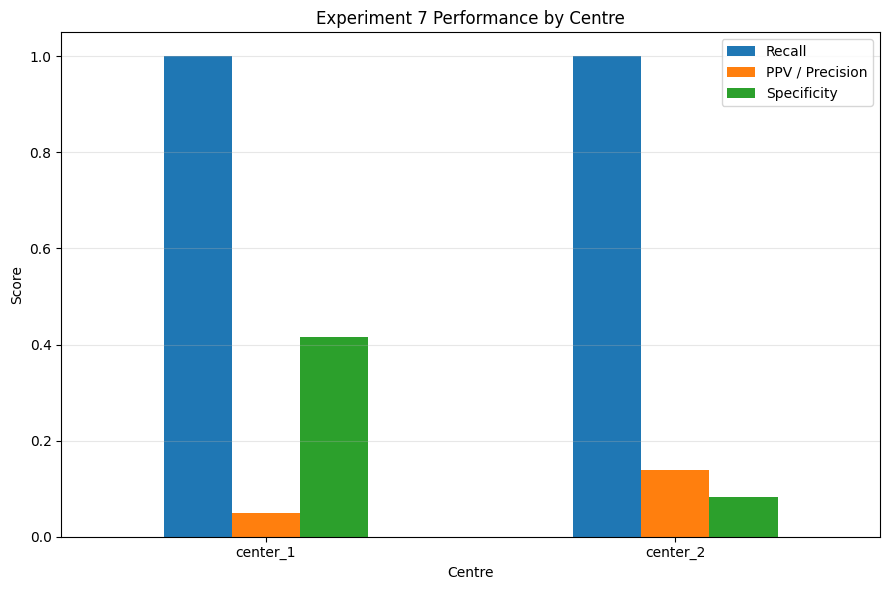

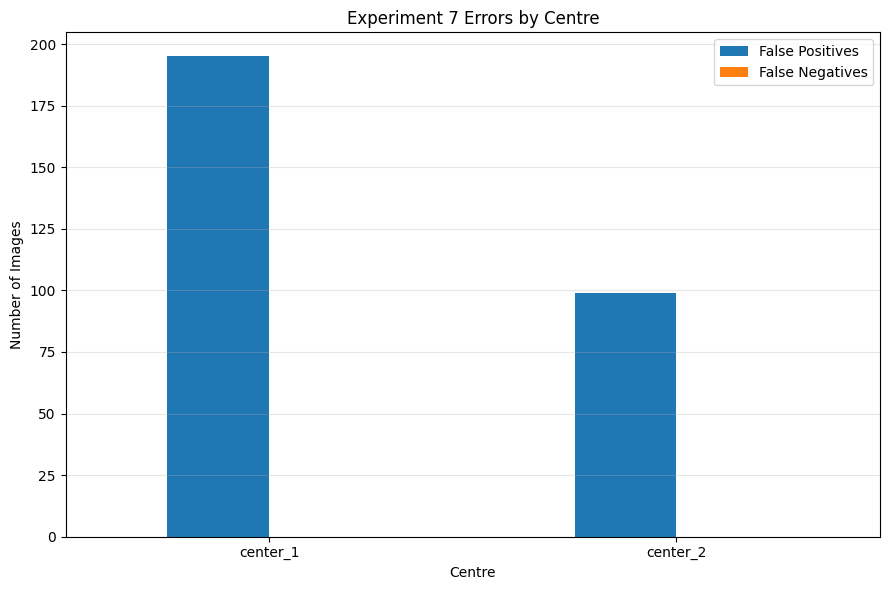


FINAL EXPERIMENT 7 SUMMARY

Overall test:
Recall: 1.0
PPV: 0.0812
Specificity: 0.3348
False positives: 294
False negatives: 0

Center 1 test:
Recall: 1.0
PPV: 0.0488
Specificity: 0.4162
False positives: 195
False negatives: 0

Center 2 test:
Recall: 1.0
PPV: 0.1391
Specificity: 0.0833
False positives: 99
False negatives: 0

Files saved:
/content/drive/MyDrive/RARE26/models/resnet18_center_artifact_robust_best.pth
/content/drive/MyDrive/RARE26/results/resnet18_center_artifact_robust_history.csv
/content/drive/MyDrive/RARE26/results/resnet18_center_artifact_robust_threshold_search.csv
/content/drive/MyDrive/RARE26/results/resnet18_center_artifact_robust_test_metrics.csv
/content/drive/MyDrive/RARE26/results/resnet18_center_artifact_robust_test_predictions.csv
/content/drive/MyDrive/RARE26/results/figures/center_artifact_robust_per_center_scores.png
/content/drive/MyDrive/RARE26/results/figures/center_artifact_robust_per_center_errors.png


In [ ]:
# ================================================================
# EXPERIMENT 7
# CENTRE-CLASS BALANCED + ARTIFACT-ROBUST TRAINING
#
# Purpose:
# 1. Center 1 aur Center 2 imbalance ko reduce karna
# 2. Normal vs neoplasia imbalance ko moderately reduce karna
# 3. Borders, overlays, lighting aur camera-style shortcuts
#    par model dependence reduce karna
# 4. Overall aur per-centre test performance evaluate karna
# ================================================================

import re
import gc
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from pathlib import Path
from PIL import Image

from torch.utils.data import (
    Dataset,
    DataLoader,
    WeightedRandomSampler,
)

from torchvision import transforms

from torchvision.models import (
    resnet18,
    ResNet18_Weights,
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
)

from IPython.display import display as show_table


# ================================================================
# 1. REPRODUCIBILITY
# ================================================================

SEED = 42


def set_all_seeds(seed=42):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_all_seeds(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)


# ================================================================
# 2. GOOGLE DRIVE PATHS
# ================================================================

drive_folder = Path(
    "/content/drive/MyDrive/RARE26"
)

splits_folder = (
    drive_folder / "splits"
)

models_folder = (
    drive_folder / "models"
)

results_folder = (
    drive_folder / "results"
)

figures_folder = (
    results_folder / "figures"
)


models_folder.mkdir(
    parents=True,
    exist_ok=True
)

results_folder.mkdir(
    parents=True,
    exist_ok=True
)

figures_folder.mkdir(
    parents=True,
    exist_ok=True
)


train_csv_path = (
    splits_folder / "train_colab.csv"
)

validation_csv_path = (
    splits_folder / "validation_colab.csv"
)

test_csv_path = (
    splits_folder / "test_colab.csv"
)


best_model_path = (
    models_folder
    / "resnet18_center_artifact_robust_best.pth"
)

latest_model_path = (
    models_folder
    / "resnet18_center_artifact_robust_latest.pth"
)

history_path = (
    results_folder
    / "resnet18_center_artifact_robust_history.csv"
)

test_metrics_path = (
    results_folder
    / "resnet18_center_artifact_robust_test_metrics.csv"
)

test_predictions_path = (
    results_folder
    / "resnet18_center_artifact_robust_test_predictions.csv"
)

validation_threshold_path = (
    results_folder
    / "resnet18_center_artifact_robust_threshold_search.csv"
)

centre_scores_graph_path = (
    figures_folder
    / "center_artifact_robust_per_center_scores.png"
)

centre_errors_graph_path = (
    figures_folder
    / "center_artifact_robust_per_center_errors.png"
)


# ================================================================
# 3. READ EXISTING SPLITS
# ================================================================

train_df = pd.read_csv(
    train_csv_path
)

validation_df = pd.read_csv(
    validation_csv_path
)

test_df = pd.read_csv(
    test_csv_path
)


print("\n" + "=" * 90)
print("EXPERIMENT 7 DATA CHECK")
print("=" * 90)

print("Training rows:", len(train_df))
print("Validation rows:", len(validation_df))
print("Test rows:", len(test_df))

print(
    "Available columns:",
    list(train_df.columns)
)


# ================================================================
# 4. CLEAN PATHS AND CENTRE NAMES
# ================================================================

path_column = "colab_path"
label_column = "label"


for dataframe_name, dataframe in [
    ("train", train_df),
    ("validation", validation_df),
    ("test", test_df),
]:

    if path_column not in dataframe.columns:

        raise ValueError(
            f"{dataframe_name} CSV mein "
            "'colab_path' column nahi mila."
        )

    if label_column not in dataframe.columns:

        raise ValueError(
            f"{dataframe_name} CSV mein "
            "'label' column nahi mila."
        )


def normalize_center_name(value):

    value_string = str(
        value
    ).lower().strip()

    match = re.search(
        r"(?:center|centre)[_\-\s/\\]?([12])",
        value_string
    )

    if match:

        return (
            f"center_{match.group(1)}"
        )

    if value_string in [
        "1",
        "1.0",
    ]:

        return "center_1"

    if value_string in [
        "2",
        "2.0",
    ]:

        return "center_2"

    return np.nan


def prepare_manifest(dataframe):

    dataframe = (
        dataframe.copy()
        .reset_index(drop=True)
    )

    dataframe[path_column] = (
        dataframe[path_column]
        .astype(str)
        .str.replace(
            "\\",
            "/",
            regex=False
        )
    )

    dataframe[label_column] = (
        dataframe[label_column]
        .astype(int)
    )

    if "center" in dataframe.columns:

        dataframe["center_name"] = (
            dataframe["center"]
            .apply(
                normalize_center_name
            )
        )

    else:

        dataframe["center_name"] = (
            dataframe[path_column]
            .apply(
                normalize_center_name
            )
        )

    missing_center_mask = (
        dataframe["center_name"]
        .isna()
    )

    if missing_center_mask.any():

        dataframe.loc[
            missing_center_mask,
            "center_name"
        ] = (
            dataframe.loc[
                missing_center_mask,
                path_column
            ].apply(
                normalize_center_name
            )
        )

    if dataframe[
        "center_name"
    ].isna().any():

        raise ValueError(
            "Kuch images ka centre "
            "identify nahi hua."
        )

    return dataframe


train_df = prepare_manifest(
    train_df
)

validation_df = prepare_manifest(
    validation_df
)

test_df = prepare_manifest(
    test_df
)


# ================================================================
# 5. VERIFY IMAGE PATHS
# ================================================================

combined_paths = pd.concat(
    [
        train_df[[path_column]],
        validation_df[[path_column]],
        test_df[[path_column]],
    ],
    ignore_index=True
)


path_exists_mask = combined_paths[
    path_column
].apply(
    lambda image_path:
        Path(image_path).exists()
)


missing_count = int(
    (~path_exists_mask).sum()
)


print(
    "Available image paths:",
    int(path_exists_mask.sum())
)

print(
    "Missing image paths:",
    missing_count
)


if missing_count > 0:

    print(
        combined_paths.loc[
            ~path_exists_mask,
            path_column
        ].head(10)
    )

    raise FileNotFoundError(
        "Dataset /content mein available nahi. "
        "ZIP dobara extract karni hogi."
    )


print("\nTraining centre/class distribution:")

show_table(
    pd.crosstab(
        train_df["center_name"],
        train_df[label_column]
    )
)


print("\nValidation centre/class distribution:")

show_table(
    pd.crosstab(
        validation_df["center_name"],
        validation_df[label_column]
    )
)


print("\nTest centre/class distribution:")

show_table(
    pd.crosstab(
        test_df["center_name"],
        test_df[label_column]
    )
)


# ================================================================
# 6. ARTIFACT-ROBUST TRANSFORMS
# ================================================================

# Training:
# Mild crop, rotation, lighting changes, blur
# aur very small random erasing.
train_transform = transforms.Compose([

    transforms.Resize(
        (240, 240)
    ),

    transforms.RandomResizedCrop(
        size=224,
        scale=(0.88, 1.00),
        ratio=(0.95, 1.05)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        degrees=6
    ),

    transforms.ColorJitter(
        brightness=0.12,
        contrast=0.12,
        saturation=0.06,
        hue=0.01
    ),

    transforms.RandomApply(
        [
            transforms.GaussianBlur(
                kernel_size=3,
                sigma=(0.1, 0.8)
            )
        ],
        p=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],

        std=[
            0.229,
            0.224,
            0.225
        ]
    ),

    transforms.RandomErasing(
        p=0.10,
        scale=(0.01, 0.04),
        ratio=(0.5, 2.0),
        value=0
    ),
])


# Validation/test:
# Same deterministic crop for fair evaluation.
evaluation_transform = transforms.Compose([

    transforms.Resize(
        (240, 240)
    ),

    transforms.CenterCrop(
        224
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],

        std=[
            0.229,
            0.224,
            0.225
        ]
    ),
])


# ================================================================
# 7. DATASET CLASS
# ================================================================

class RobustEndoscopyDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.dataframe = (
            dataframe.copy()
            .reset_index(drop=True)
        )

        self.transform = transform


    def __len__(self):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index
    ):

        row = self.dataframe.iloc[
            index
        ]

        image_path = str(
            row[path_column]
        ).replace(
            "\\",
            "/"
        )

        image = Image.open(
            image_path
        ).convert(
            "RGB"
        )

        label = int(
            row[label_column]
        )

        center_name = str(
            row["center_name"]
        )

        if self.transform is not None:

            image = self.transform(
                image
            )

        return (
            image,
            label,
            center_name
        )


train_dataset_robust = (
    RobustEndoscopyDataset(
        train_df,
        transform=train_transform
    )
)

validation_dataset_robust = (
    RobustEndoscopyDataset(
        validation_df,
        transform=evaluation_transform
    )
)

test_dataset_robust = (
    RobustEndoscopyDataset(
        test_df,
        transform=evaluation_transform
    )
)


# ================================================================
# 8. MODERATED CENTRE-CLASS SAMPLER
# ================================================================

# Groups:
# center_1 normal
# center_1 neoplasia
# center_2 normal
# center_2 neoplasia

train_df["sampling_group"] = (
    train_df["center_name"]
    + "_label_"
    + train_df[label_column].astype(str)
)


group_counts = (
    train_df["sampling_group"]
    .value_counts()
    .to_dict()
)


print("\nOriginal training group counts:")

for group_name, group_count in (
    sorted(group_counts.items())
):

    print(
        group_name,
        ":",
        group_count
    )


# Full inverse weighting bohat aggressive hoti.
# 1/sqrt(count) moderated balancing provide karega.
sample_weights = []

for group_name in train_df[
    "sampling_group"
]:

    group_count = group_counts[
        group_name
    ]

    weight = (
        1.0
        / np.sqrt(group_count)
    )

    sample_weights.append(
        weight
    )


sample_weights = torch.DoubleTensor(
    sample_weights
)


def create_joint_sampler():

    sampler_generator = (
        torch.Generator()
    )

    sampler_generator.manual_seed(
        SEED
    )

    return WeightedRandomSampler(

        weights=sample_weights,

        num_samples=len(
            sample_weights
        ),

        replacement=True,

        generator=sampler_generator
    )


# Audit expected sampled distribution
audit_sampler = (
    create_joint_sampler()
)

audit_indices = list(
    iter(audit_sampler)
)

sampled_audit_df = (
    train_df.iloc[
        audit_indices
    ]
)


print("\nOne sampled epoch group distribution:")

show_table(
    pd.crosstab(
        sampled_audit_df["center_name"],
        sampled_audit_df[label_column]
    )
)


training_sampler = (
    create_joint_sampler()
)


# ================================================================
# 9. DATALOADERS
# ================================================================

train_loader_robust = DataLoader(

    train_dataset_robust,

    batch_size=32,

    sampler=training_sampler,

    shuffle=False,

    num_workers=2,

    pin_memory=torch.cuda.is_available()
)


validation_loader_robust = DataLoader(

    validation_dataset_robust,

    batch_size=32,

    shuffle=False,

    num_workers=2,

    pin_memory=torch.cuda.is_available()
)


test_loader_robust = DataLoader(

    test_dataset_robust,

    batch_size=32,

    shuffle=False,

    num_workers=2,

    pin_memory=torch.cuda.is_available()
)


print(
    "\nTraining batches:",
    len(train_loader_robust)
)

print(
    "Validation batches:",
    len(validation_loader_robust)
)

print(
    "Test batches:",
    len(test_loader_robust)
)


# ================================================================
# 10. METRIC HELPER
# ================================================================

def calculate_binary_metrics(
    labels,
    probabilities,
    threshold=0.5
):

    labels = np.asarray(
        labels
    ).astype(int)

    probabilities = np.asarray(
        probabilities
    ).astype(float)

    predictions = (
        probabilities >= threshold
    ).astype(int)


    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()


    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )


    if len(
        np.unique(labels)
    ) == 2:

        auroc = roc_auc_score(
            labels,
            probabilities
        )

        auprc = average_precision_score(
            labels,
            probabilities
        )

    else:

        auroc = np.nan
        auprc = np.nan


    return {

        "accuracy": float(
            accuracy_score(
                labels,
                predictions
            )
        ),

        "precision": float(
            precision_score(
                labels,
                predictions,
                zero_division=0
            )
        ),

        "recall": float(
            recall_score(
                labels,
                predictions,
                zero_division=0
            )
        ),

        "specificity": float(
            specificity
        ),

        "auroc": float(
            auroc
        ),

        "auprc": float(
            auprc
        ),

        "true_negatives": int(
            tn
        ),

        "false_positives": int(
            fp
        ),

        "false_negatives": int(
            fn
        ),

        "true_positives": int(
            tp
        ),
    }


# ================================================================
# 11. COLLECT PREDICTIONS
# ================================================================

def collect_predictions(
    model,
    data_loader,
    criterion=None
):

    model.eval()

    total_loss = 0.0
    total_samples = 0

    labels_list = []
    probabilities_list = []
    centers_list = []


    with torch.no_grad():

        for (
            images,
            labels,
            center_names
        ) in data_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels_device = labels.to(
                device,
                non_blocking=True
            )


            outputs = model(
                images
            )


            if criterion is not None:

                loss = criterion(
                    outputs,
                    labels_device
                )

                total_loss += (
                    loss.item()
                    * images.size(0)
                )

                total_samples += (
                    images.size(0)
                )


            probabilities = torch.softmax(
                outputs,
                dim=1
            )[:, 1]


            labels_list.extend(
                labels
                .cpu()
                .numpy()
            )


            probabilities_list.extend(
                probabilities
                .cpu()
                .numpy()
            )


            centers_list.extend(
                list(center_names)
            )


    average_loss = (

        total_loss / total_samples

        if (
            criterion is not None
            and total_samples > 0
        )

        else np.nan
    )


    return (
        np.array(labels_list),

        np.array(
            probabilities_list
        ),

        np.array(
            centers_list
        ),

        float(
            average_loss
        )
    )


# ================================================================
# 12. MODEL
# ================================================================

robust_model = resnet18(
    weights=ResNet18_Weights.DEFAULT
)

robust_model.fc = nn.Linear(
    robust_model.fc.in_features,
    2
)

robust_model = robust_model.to(
    device
)


# Sampler already imbalance reduce kar raha hai.
# Is experiment mein standard CE use hogi.
criterion = nn.CrossEntropyLoss()


optimizer = torch.optim.AdamW(

    robust_model.parameters(),

    lr=0.0001,

    weight_decay=0.0001
)


# ================================================================
# 13. TRAINING
# ================================================================

number_of_epochs = 10

best_macro_center_auprc = -1.0

training_history = []


print("\n" + "=" * 95)

print(
    "CENTRE-CLASS BALANCED + "
    "ARTIFACT-ROBUST TRAINING START"
)

print("=" * 95)


for epoch in range(
    1,
    number_of_epochs + 1
):

    epoch_start_time = time.time()

    robust_model.train()

    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0


    for (
        images,
        labels,
        _
    ) in train_loader_robust:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )


        optimizer.zero_grad()


        outputs = robust_model(
            images
        )


        loss = criterion(
            outputs,
            labels
        )


        loss.backward()

        optimizer.step()


        running_loss += (
            loss.item()
            * images.size(0)
        )


        batch_predictions = (
            torch.argmax(
                outputs,
                dim=1
            )
        )


        correct_predictions += (
            batch_predictions
            == labels
        ).sum().item()


        total_samples += (
            labels.size(0)
        )


    train_loss = (
        running_loss
        / total_samples
    )


    train_accuracy = (
        correct_predictions
        / total_samples
    )


    (
        val_labels,
        val_probabilities,
        val_centers,
        val_loss
    ) = collect_predictions(

        model=robust_model,

        data_loader=validation_loader_robust,

        criterion=criterion
    )


    global_val_metrics = (
        calculate_binary_metrics(

            labels=val_labels,

            probabilities=val_probabilities,

            threshold=0.5
        )
    )


    center_1_mask = (
        val_centers == "center_1"
    )

    center_2_mask = (
        val_centers == "center_2"
    )


    center_1_metrics = (
        calculate_binary_metrics(

            labels=val_labels[
                center_1_mask
            ],

            probabilities=val_probabilities[
                center_1_mask
            ],

            threshold=0.5
        )
    )


    center_2_metrics = (
        calculate_binary_metrics(

            labels=val_labels[
                center_2_mask
            ],

            probabilities=val_probabilities[
                center_2_mask
            ],

            threshold=0.5
        )
    )


    macro_center_auprc = float(
        np.mean(
            [
                center_1_metrics[
                    "auprc"
                ],

                center_2_metrics[
                    "auprc"
                ],
            ]
        )
    )


    epoch_seconds = (
        time.time()
        - epoch_start_time
    )


    epoch_record = {

        "epoch":
            epoch,

        "train_loss":
            train_loss,

        "train_accuracy":
            train_accuracy,

        "val_loss":
            val_loss,

        "global_val_recall":
            global_val_metrics["recall"],

        "global_val_precision":
            global_val_metrics["precision"],

        "global_val_auroc":
            global_val_metrics["auroc"],

        "global_val_auprc":
            global_val_metrics["auprc"],

        "center_1_val_recall":
            center_1_metrics["recall"],

        "center_1_val_precision":
            center_1_metrics["precision"],

        "center_1_val_auprc":
            center_1_metrics["auprc"],

        "center_2_val_recall":
            center_2_metrics["recall"],

        "center_2_val_precision":
            center_2_metrics["precision"],

        "center_2_val_auprc":
            center_2_metrics["auprc"],

        "macro_center_val_auprc":
            macro_center_auprc,

        "epoch_seconds":
            epoch_seconds,
    }


    training_history.append(
        epoch_record
    )


    pd.DataFrame(
        training_history
    ).to_csv(
        history_path,
        index=False
    )


    checkpoint_data = {

        "epoch":
            epoch,

        "model_state_dict":
            robust_model.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "global_validation_metrics":
            global_val_metrics,

        "center_1_validation_metrics":
            center_1_metrics,

        "center_2_validation_metrics":
            center_2_metrics,

        "macro_center_validation_auprc":
            macro_center_auprc,

        "training_method":
            (
                "sqrt_joint_center_class_sampler_"
                "plus_artifact_robust_augmentation"
            ),
    }


    torch.save(
        checkpoint_data,
        latest_model_path
    )


    if (
        macro_center_auprc
        > best_macro_center_auprc
    ):

        best_macro_center_auprc = (
            macro_center_auprc
        )

        torch.save(
            checkpoint_data,
            best_model_path
        )

        best_message = (
            "  <-- Best robust model saved"
        )

    else:

        best_message = ""


    print(

        f"Epoch {epoch:02d}/10 | "

        f"Train Loss: "
        f"{train_loss:.4f} | "

        f"Val Loss: "
        f"{val_loss:.4f} | "

        f"Global Recall: "
        f"{global_val_metrics['recall']:.4f} | "

        f"Global AUPRC: "
        f"{global_val_metrics['auprc']:.4f} | "

        f"C1 Recall: "
        f"{center_1_metrics['recall']:.4f} | "

        f"C1 AUPRC: "
        f"{center_1_metrics['auprc']:.4f} | "

        f"C2 Recall: "
        f"{center_2_metrics['recall']:.4f} | "

        f"C2 AUPRC: "
        f"{center_2_metrics['auprc']:.4f} | "

        f"Macro Centre AUPRC: "
        f"{macro_center_auprc:.4f} | "

        f"Time: "
        f"{epoch_seconds:.1f}s"

        f"{best_message}"
    )


print("=" * 95)

print(
    "Experiment 7 training complete."
)

print(
    "Best macro-centre validation AUPRC:",
    round(
        best_macro_center_auprc,
        4
    )
)


# ================================================================
# 14. LOAD BEST MODEL
# ================================================================

best_checkpoint = torch.load(

    best_model_path,

    map_location=device,

    weights_only=False
)


best_model = resnet18(
    weights=None
)

best_model.fc = nn.Linear(
    best_model.fc.in_features,
    2
)

best_model.load_state_dict(
    best_checkpoint[
        "model_state_dict"
    ]
)

best_model = best_model.to(
    device
)

best_model.eval()


print(
    "\nBest checkpoint epoch:",
    best_checkpoint["epoch"]
)

print(
    "Saved macro-centre validation AUPRC:",
    best_checkpoint[
        "macro_center_validation_auprc"
    ]
)


# ================================================================
# 15. VALIDATION PREDICTIONS
# ================================================================

(
    validation_labels,
    validation_probabilities,
    validation_centers,
    _
) = collect_predictions(

    model=best_model,

    data_loader=validation_loader_robust,

    criterion=None
)


# ================================================================
# 16. ROBUST THRESHOLD SEARCH
#
# Rule:
# - Overall validation recall >= 90%
# - Phir worst-centre recall maximum
# - Phir overall precision maximum
# ================================================================

candidate_thresholds = np.unique(
    np.concatenate(
        [
            np.array([0.0]),
            validation_probabilities,
            np.array([1.0]),
        ]
    )
)


threshold_records = []


for threshold in candidate_thresholds:

    overall_metrics = (
        calculate_binary_metrics(

            labels=validation_labels,

            probabilities=validation_probabilities,

            threshold=threshold
        )
    )


    center_1_mask = (
        validation_centers
        == "center_1"
    )

    center_2_mask = (
        validation_centers
        == "center_2"
    )


    c1_metrics = (
        calculate_binary_metrics(

            labels=validation_labels[
                center_1_mask
            ],

            probabilities=validation_probabilities[
                center_1_mask
            ],

            threshold=threshold
        )
    )


    c2_metrics = (
        calculate_binary_metrics(

            labels=validation_labels[
                center_2_mask
            ],

            probabilities=validation_probabilities[
                center_2_mask
            ],

            threshold=threshold
        )
    )


    minimum_center_recall = min(

        c1_metrics["recall"],

        c2_metrics["recall"]
    )


    threshold_records.append({

        "threshold":
            float(threshold),

        "overall_recall":
            overall_metrics["recall"],

        "overall_precision":
            overall_metrics["precision"],

        "overall_specificity":
            overall_metrics["specificity"],

        "center_1_recall":
            c1_metrics["recall"],

        "center_1_precision":
            c1_metrics["precision"],

        "center_2_recall":
            c2_metrics["recall"],

        "center_2_precision":
            c2_metrics["precision"],

        "minimum_center_recall":
            minimum_center_recall,
    })


threshold_search_df = pd.DataFrame(
    threshold_records
)


eligible_thresholds_df = (
    threshold_search_df[

        threshold_search_df[
            "overall_recall"
        ] >= 0.90

    ].copy()
)


if len(
    eligible_thresholds_df
) > 0:

    eligible_thresholds_df = (
        eligible_thresholds_df
        .sort_values(

            by=[
                "minimum_center_recall",
                "overall_precision",
                "overall_specificity",
                "threshold",
            ],

            ascending=[
                False,
                False,
                False,
                False,
            ]
        )
    )

    selected_threshold_row = (
        eligible_thresholds_df.iloc[0]
    )

else:

    threshold_search_df = (
        threshold_search_df
        .sort_values(

            by=[
                "overall_recall",
                "minimum_center_recall",
                "overall_precision",
            ],

            ascending=[
                False,
                False,
                False,
            ]
        )
    )

    selected_threshold_row = (
        threshold_search_df.iloc[0]
    )


selected_threshold = float(
    selected_threshold_row[
        "threshold"
    ]
)


threshold_search_df.to_csv(
    validation_threshold_path,
    index=False
)


print("\n" + "=" * 90)

print(
    "VALIDATION-SELECTED ROBUST THRESHOLD"
)

print("=" * 90)

print(
    "Selected threshold:",
    selected_threshold
)

print(
    "Overall validation recall:",
    selected_threshold_row[
        "overall_recall"
    ]
)

print(
    "Overall validation precision:",
    selected_threshold_row[
        "overall_precision"
    ]
)

print(
    "Center 1 validation recall:",
    selected_threshold_row[
        "center_1_recall"
    ]
)

print(
    "Center 2 validation recall:",
    selected_threshold_row[
        "center_2_recall"
    ]
)

print(
    "Minimum centre recall:",
    selected_threshold_row[
        "minimum_center_recall"
    ]
)


# ================================================================
# 17. TEST PREDICTIONS
# ================================================================

(
    test_labels,
    test_probabilities,
    test_centers,
    _
) = collect_predictions(

    model=best_model,

    data_loader=test_loader_robust,

    criterion=None
)


# ================================================================
# 18. TEST METRICS:
# OVERALL + BOTH CENTRES
# ================================================================

test_metric_rows = []


evaluation_settings = [

    {
        "evaluation":
            "default_threshold",

        "threshold":
            0.5,
    },

    {
        "evaluation":
            "validation_selected_robust_threshold",

        "threshold":
            selected_threshold,
    },
]


for setting in evaluation_settings:

    threshold = setting[
        "threshold"
    ]

    evaluation_name = setting[
        "evaluation"
    ]


    # Overall
    overall_metrics = (
        calculate_binary_metrics(

            labels=test_labels,

            probabilities=test_probabilities,

            threshold=threshold
        )
    )


    test_metric_rows.append({

        "scope":
            "overall",

        "center":
            "all_centers",

        "evaluation":
            evaluation_name,

        "threshold":
            threshold,

        **overall_metrics,
    })


    # Per-centre
    for center_name in [
        "center_1",
        "center_2",
    ]:

        center_mask = (
            test_centers
            == center_name
        )


        center_metrics = (
            calculate_binary_metrics(

                labels=test_labels[
                    center_mask
                ],

                probabilities=test_probabilities[
                    center_mask
                ],

                threshold=threshold
            )
        )


        test_metric_rows.append({

            "scope":
                "per_center",

            "center":
                center_name,

            "evaluation":
                evaluation_name,

            "threshold":
                threshold,

            **center_metrics,
        })


test_metrics_df = pd.DataFrame(
    test_metric_rows
)


test_metrics_df.to_csv(
    test_metrics_path,
    index=False
)


print("\n" + "=" * 100)

print(
    "EXPERIMENT 7 TEST RESULTS"
)

print("=" * 100)


show_table(
    test_metrics_df
)


# ================================================================
# 19. SAVE DETAILED TEST PREDICTIONS
# ================================================================

test_predictions_df = (
    test_df.copy()
    .reset_index(drop=True)
)


test_predictions_df[
    "true_label"
] = test_labels


test_predictions_df[
    "neoplasia_probability"
] = test_probabilities


test_predictions_df[
    "default_prediction"
] = (
    test_probabilities
    >= 0.5
).astype(int)


test_predictions_df[
    "robust_threshold"
] = selected_threshold


test_predictions_df[
    "robust_prediction"
] = (
    test_probabilities
    >= selected_threshold
).astype(int)


test_predictions_df.to_csv(
    test_predictions_path,
    index=False
)


# ================================================================
# 20. HIGH-RECALL PER-CENTRE SUMMARY
# ================================================================

robust_test_df = test_metrics_df[

    test_metrics_df["evaluation"]
    == "validation_selected_robust_threshold"

].copy()


print("\n" + "=" * 100)

print(
    "EXPERIMENT 7 ROBUST-THRESHOLD SUMMARY"
)

print("=" * 100)


show_table(

    robust_test_df[
        [
            "scope",
            "center",
            "threshold",
            "recall",
            "precision",
            "specificity",
            "auroc",
            "auprc",
            "false_positives",
            "false_negatives",
            "true_positives",
            "true_negatives",
        ]
    ]
)


# ================================================================
# 21. GRAPHS
# ================================================================

per_center_robust_df = robust_test_df[

    robust_test_df["scope"]
    == "per_center"

].copy()


per_center_robust_df = (
    per_center_robust_df
    .set_index("center")
)


per_center_robust_df[
    [
        "recall",
        "precision",
        "specificity",
    ]
].plot(

    kind="bar",

    figsize=(9, 6)
)


plt.title(
    "Experiment 7 Performance by Centre"
)

plt.xlabel(
    "Centre"
)

plt.ylabel(
    "Score"
)

plt.ylim(
    0,
    1.05
)

plt.xticks(
    rotation=0
)

plt.legend(
    [
        "Recall",
        "PPV / Precision",
        "Specificity",
    ]
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()


plt.savefig(
    centre_scores_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


per_center_robust_df[
    [
        "false_positives",
        "false_negatives",
    ]
].plot(

    kind="bar",

    figsize=(9, 6)
)


plt.title(
    "Experiment 7 Errors by Centre"
)

plt.xlabel(
    "Centre"
)

plt.ylabel(
    "Number of Images"
)

plt.xticks(
    rotation=0
)

plt.legend(
    [
        "False Positives",
        "False Negatives",
    ]
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()


plt.savefig(
    centre_errors_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ================================================================
# 22. SIMPLE FINAL OUTPUT
# ================================================================

overall_robust_row = robust_test_df[

    robust_test_df["scope"]
    == "overall"

].iloc[0]


center_1_robust_row = robust_test_df[

    robust_test_df["center"]
    == "center_1"

].iloc[0]


center_2_robust_row = robust_test_df[

    robust_test_df["center"]
    == "center_2"

].iloc[0]


print("\n" + "=" * 100)

print(
    "FINAL EXPERIMENT 7 SUMMARY"
)

print("=" * 100)


print("\nOverall test:")

print(
    "Recall:",
    round(
        overall_robust_row[
            "recall"
        ],
        4
    )
)

print(
    "PPV:",
    round(
        overall_robust_row[
            "precision"
        ],
        4
    )
)

print(
    "Specificity:",
    round(
        overall_robust_row[
            "specificity"
        ],
        4
    )
)

print(
    "False positives:",
    int(
        overall_robust_row[
            "false_positives"
        ]
    )
)

print(
    "False negatives:",
    int(
        overall_robust_row[
            "false_negatives"
        ]
    )
)


print("\nCenter 1 test:")

print(
    "Recall:",
    round(
        center_1_robust_row[
            "recall"
        ],
        4
    )
)

print(
    "PPV:",
    round(
        center_1_robust_row[
            "precision"
        ],
        4
    )
)

print(
    "Specificity:",
    round(
        center_1_robust_row[
            "specificity"
        ],
        4
    )
)

print(
    "False positives:",
    int(
        center_1_robust_row[
            "false_positives"
        ]
    )
)

print(
    "False negatives:",
    int(
        center_1_robust_row[
            "false_negatives"
        ]
    )
)


print("\nCenter 2 test:")

print(
    "Recall:",
    round(
        center_2_robust_row[
            "recall"
        ],
        4
    )
)

print(
    "PPV:",
    round(
        center_2_robust_row[
            "precision"
        ],
        4
    )
)

print(
    "Specificity:",
    round(
        center_2_robust_row[
            "specificity"
        ],
        4
    )
)

print(
    "False positives:",
    int(
        center_2_robust_row[
            "false_positives"
        ]
    )
)

print(
    "False negatives:",
    int(
        center_2_robust_row[
            "false_negatives"
        ]
    )
)


print("\nFiles saved:")

print(
    best_model_path
)

print(
    history_path
)

print(
    validation_threshold_path
)

print(
    test_metrics_path
)

print(
    test_predictions_path
)

print(
    centre_scores_graph_path
)

print(
    centre_errors_graph_path
)


# Clear memory
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Device: cuda

Validation distribution:


label,0,1
center_name,,
center_1,332,9
center_2,106,14



Test distribution:


label,0,1
center_name,,
center_1,334,10
center_2,108,16



Available image paths: 929
Missing image paths: 0

Baseline checkpoint epoch: 6
Augmentation checkpoint epoch: 9

VALIDATION-SELECTED ENSEMBLE
Baseline weight: 0.44999999999999996
Augmentation weight: 0.55
Selected threshold: 0.01642357287928462
Validation overall recall: 0.9565217391304348
Validation overall precision: 0.24175824175824176
Validation Center 1 recall: 0.8888888888888888
Validation Center 2 recall: 1.0
Validation minimum-centre recall: 0.8888888888888888

EXPERIMENT 8 TEST RESULTS


,scope,center,evaluation,baseline_weight,augmentation_weight,threshold,accuracy,precision,recall,specificity,auroc,auprc,true_negatives,false_positives,false_negatives,true_positives
0,overall,all_centers,default_threshold,0.45,0.55,0.500000,0.982906,0.846154,0.846154,0.990950,0.976679,0.902280,438,4,4,22
1,per_center,center_1,default_threshold,0.45,0.55,0.500000,0.979651,0.666667,0.600000,0.991018,0.953593,0.681602,331,3,4,6
2,per_center,center_2,default_threshold,0.45,0.55,0.500000,0.991935,0.941176,1.000000,0.990741,1.000000,1.000000,107,1,0,16
3,overall,all_centers,validation_selected_ensemble_threshold,0.45,0.55,0.016424,0.814103,0.225225,0.961538,0.805430,0.976679,0.902280,356,86,1,25
4,per_center,center_1,validation_selected_ensemble_threshold,0.45,0.55,0.016424,0.869186,0.169811,0.900000,0.868263,0.953593,0.681602,290,44,1,9
5,per_center,center_2,validation_selected_ensemble_threshold,0.45,0.55,0.016424,0.661290,0.275862,1.000000,0.611111,1.000000,1.000000,66,42,0,16



FINAL EXPERIMENT 8 SUMMARY


,scope,center,baseline_weight,augmentation_weight,threshold,recall,precision,specificity,auroc,auprc,false_positives,false_negatives,true_positives,true_negatives
3,overall,all_centers,0.45,0.55,0.016424,0.961538,0.225225,0.805430,0.976679,0.902280,86,1,25,356
4,per_center,center_1,0.45,0.55,0.016424,0.900000,0.169811,0.868263,0.953593,0.681602,44,1,9,290
5,per_center,center_2,0.45,0.55,0.016424,1.000000,0.275862,0.611111,1.000000,1.000000,42,0,16,66


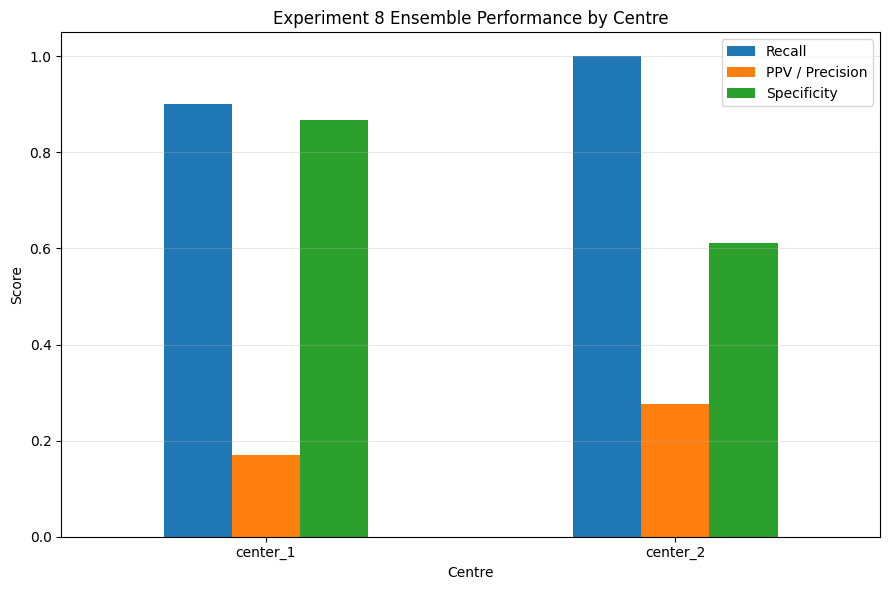

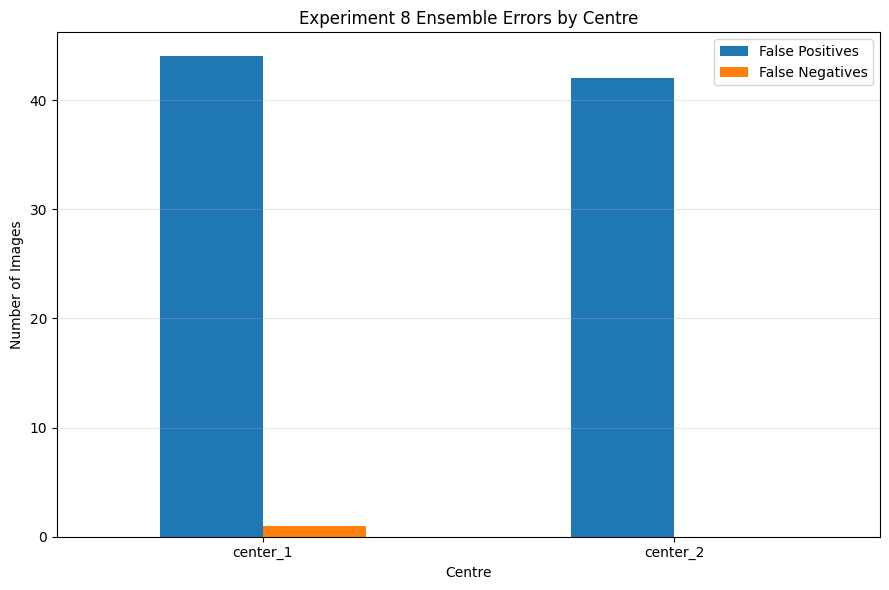


Overall test:
Recall: 0.9615
PPV: 0.2252
Specificity: 0.8054
False positives: 86
False negatives: 1

Center 1 test:
Recall: 0.9
False positives: 44
False negatives: 1

Center 2 test:
Recall: 1.0
False positives: 42
False negatives: 0

Files saved:
/content/drive/MyDrive/RARE26/results/baseline_augmentation_ensemble_validation_search.csv
/content/drive/MyDrive/RARE26/results/baseline_augmentation_ensemble_test_metrics.csv
/content/drive/MyDrive/RARE26/results/baseline_augmentation_ensemble_test_predictions.csv
/content/drive/MyDrive/RARE26/results/figures/baseline_augmentation_ensemble_per_center_scores.png
/content/drive/MyDrive/RARE26/results/figures/baseline_augmentation_ensemble_per_center_errors.png


In [ ]:
# ================================================================
# EXPERIMENT 8
# VALIDATION-TUNED PROBABILITY ENSEMBLE
#
# Models:
# 1. Baseline ResNet-18
# 2. Weighted + Augmentation ResNet-18
#
# Selection rules:
# - Overall validation recall >= 90%
# - Minimum per-centre validation recall >= 80%
# - In conditions ke andar maximum precision choose karna
# ================================================================

import gc
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
)
from IPython.display import display as show_table


# ================================================================
# 1. REPRODUCIBILITY
# ================================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ================================================================
# 2. PATHS
# ================================================================

drive_folder = Path(
    "/content/drive/MyDrive/RARE26"
)

splits_folder = drive_folder / "splits"
models_folder = drive_folder / "models"
results_folder = drive_folder / "results"
figures_folder = results_folder / "figures"

figures_folder.mkdir(
    parents=True,
    exist_ok=True
)


validation_csv_path = (
    splits_folder / "validation_colab.csv"
)

test_csv_path = (
    splits_folder / "test_colab.csv"
)


baseline_model_path = (
    models_folder
    / "resnet18_baseline_best.pth"
)

augmentation_model_path = (
    models_folder
    / "resnet18_weighted_augmentation_best.pth"
)


ensemble_search_path = (
    results_folder
    / "baseline_augmentation_ensemble_validation_search.csv"
)

ensemble_metrics_path = (
    results_folder
    / "baseline_augmentation_ensemble_test_metrics.csv"
)

ensemble_predictions_path = (
    results_folder
    / "baseline_augmentation_ensemble_test_predictions.csv"
)

ensemble_scores_graph_path = (
    figures_folder
    / "baseline_augmentation_ensemble_per_center_scores.png"
)

ensemble_errors_graph_path = (
    figures_folder
    / "baseline_augmentation_ensemble_per_center_errors.png"
)


# ================================================================
# 3. READ VALIDATION AND TEST MANIFESTS
# ================================================================

validation_df = pd.read_csv(
    validation_csv_path
)

test_df = pd.read_csv(
    test_csv_path
)


path_column = "colab_path"
label_column = "label"


def clean_manifest(dataframe):

    dataframe = dataframe.copy().reset_index(
        drop=True
    )

    dataframe[path_column] = (
        dataframe[path_column]
        .astype(str)
        .str.replace(
            "\\",
            "/",
            regex=False
        )
    )

    dataframe[label_column] = (
        dataframe[label_column]
        .astype(int)
    )

    dataframe["center_name"] = (
        dataframe["center"]
        .astype(str)
        .str.lower()
        .str.replace(
            "centre_",
            "center_",
            regex=False
        )
    )

    return dataframe


validation_df = clean_manifest(
    validation_df
)

test_df = clean_manifest(
    test_df
)


print("\nValidation distribution:")

show_table(
    pd.crosstab(
        validation_df["center_name"],
        validation_df[label_column]
    )
)


print("\nTest distribution:")

show_table(
    pd.crosstab(
        test_df["center_name"],
        test_df[label_column]
    )
)


# Verify files
all_paths = pd.concat(
    [
        validation_df[[path_column]],
        test_df[[path_column]],
    ],
    ignore_index=True
)

exists_mask = all_paths[
    path_column
].apply(
    lambda path: Path(path).exists()
)

missing_count = int(
    (~exists_mask).sum()
)

print(
    "\nAvailable image paths:",
    int(exists_mask.sum())
)

print(
    "Missing image paths:",
    missing_count
)

if missing_count > 0:
    raise FileNotFoundError(
        "Kuch images /content mein missing hain."
    )


# ================================================================
# 4. SAME EVALUATION TRANSFORM
# ================================================================

evaluation_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],

        std=[
            0.229,
            0.224,
            0.225
        ]
    ),
])


# ================================================================
# 5. DATASET
# ================================================================

class EnsembleDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform
    ):

        self.dataframe = (
            dataframe.copy()
            .reset_index(drop=True)
        )

        self.transform = transform


    def __len__(self):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index
    ):

        row = self.dataframe.iloc[
            index
        ]

        image = Image.open(
            row[path_column]
        ).convert("RGB")

        image = self.transform(
            image
        )

        label = int(
            row[label_column]
        )

        center_name = str(
            row["center_name"]
        )

        return (
            image,
            label,
            center_name
        )


validation_dataset = EnsembleDataset(
    validation_df,
    evaluation_transform
)

test_dataset = EnsembleDataset(
    test_df,
    evaluation_transform
)


validation_loader_ensemble = DataLoader(

    validation_dataset,

    batch_size=32,

    shuffle=False,

    num_workers=2,

    pin_memory=torch.cuda.is_available()
)


test_loader_ensemble = DataLoader(

    test_dataset,

    batch_size=32,

    shuffle=False,

    num_workers=2,

    pin_memory=torch.cuda.is_available()
)


# ================================================================
# 6. LOAD MODEL FUNCTION
# ================================================================

def load_resnet18_checkpoint(
    checkpoint_path
):

    checkpoint = torch.load(

        checkpoint_path,

        map_location=device,

        weights_only=False
    )

    model = resnet18(
        weights=None
    )

    model.fc = nn.Linear(
        model.fc.in_features,
        2
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model = model.to(
        device
    )

    model.eval()

    return model, checkpoint


baseline_model, baseline_checkpoint = (
    load_resnet18_checkpoint(
        baseline_model_path
    )
)


augmentation_model, augmentation_checkpoint = (
    load_resnet18_checkpoint(
        augmentation_model_path
    )
)


print(
    "\nBaseline checkpoint epoch:",
    baseline_checkpoint["epoch"]
)

print(
    "Augmentation checkpoint epoch:",
    augmentation_checkpoint["epoch"]
)


# ================================================================
# 7. COLLECT TWO-MODEL PROBABILITIES
# ================================================================

def collect_two_model_predictions(
    first_model,
    second_model,
    data_loader
):

    labels_list = []
    centers_list = []

    first_probabilities = []
    second_probabilities = []


    first_model.eval()
    second_model.eval()


    with torch.no_grad():

        for (
            images,
            labels,
            center_names
        ) in data_loader:

            images = images.to(
                device,
                non_blocking=True
            )


            first_outputs = first_model(
                images
            )

            second_outputs = second_model(
                images
            )


            first_probs = torch.softmax(
                first_outputs,
                dim=1
            )[:, 1]


            second_probs = torch.softmax(
                second_outputs,
                dim=1
            )[:, 1]


            labels_list.extend(
                labels.numpy()
            )

            centers_list.extend(
                list(center_names)
            )

            first_probabilities.extend(
                first_probs.cpu().numpy()
            )

            second_probabilities.extend(
                second_probs.cpu().numpy()
            )


    return (
        np.array(labels_list),
        np.array(centers_list),
        np.array(first_probabilities),
        np.array(second_probabilities),
    )


(
    validation_labels,
    validation_centers,
    validation_baseline_probs,
    validation_augmentation_probs,
) = collect_two_model_predictions(

    first_model=baseline_model,

    second_model=augmentation_model,

    data_loader=validation_loader_ensemble
)


(
    test_labels,
    test_centers,
    test_baseline_probs,
    test_augmentation_probs,
) = collect_two_model_predictions(

    first_model=baseline_model,

    second_model=augmentation_model,

    data_loader=test_loader_ensemble
)


# ================================================================
# 8. METRICS FUNCTION
# ================================================================

def calculate_metrics(
    labels,
    probabilities,
    threshold
):

    labels = np.asarray(
        labels
    ).astype(int)

    probabilities = np.asarray(
        probabilities
    ).astype(float)

    predictions = (
        probabilities >= threshold
    ).astype(int)


    tn, fp, fn, tp = confusion_matrix(
        labels,
        predictions,
        labels=[0, 1]
    ).ravel()


    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )


    return {

        "accuracy": float(
            accuracy_score(
                labels,
                predictions
            )
        ),

        "precision": float(
            precision_score(
                labels,
                predictions,
                zero_division=0
            )
        ),

        "recall": float(
            recall_score(
                labels,
                predictions,
                zero_division=0
            )
        ),

        "specificity": float(
            specificity
        ),

        "auroc": float(
            roc_auc_score(
                labels,
                probabilities
            )
        ),

        "auprc": float(
            average_precision_score(
                labels,
                probabilities
            )
        ),

        "true_negatives": int(tn),

        "false_positives": int(fp),

        "false_negatives": int(fn),

        "true_positives": int(tp),
    }


# ================================================================
# 9. VALIDATION SEARCH
#
# alpha = Augmentation model weight
# 1-alpha = Baseline model weight
# ================================================================

alpha_values = np.linspace(
    0.0,
    1.0,
    21
)


search_records = []


for alpha in alpha_values:

    ensemble_validation_probs = (

        (1.0 - alpha)
        * validation_baseline_probs

        +

        alpha
        * validation_augmentation_probs
    )


    candidate_thresholds = np.unique(
        np.concatenate(
            [
                np.array([0.0]),
                ensemble_validation_probs,
                np.array([1.0]),
            ]
        )
    )


    for threshold in candidate_thresholds:

        overall_metrics = calculate_metrics(

            labels=validation_labels,

            probabilities=ensemble_validation_probs,

            threshold=threshold
        )


        center_1_mask = (
            validation_centers
            == "center_1"
        )

        center_2_mask = (
            validation_centers
            == "center_2"
        )


        center_1_metrics = calculate_metrics(

            labels=validation_labels[
                center_1_mask
            ],

            probabilities=ensemble_validation_probs[
                center_1_mask
            ],

            threshold=threshold
        )


        center_2_metrics = calculate_metrics(

            labels=validation_labels[
                center_2_mask
            ],

            probabilities=ensemble_validation_probs[
                center_2_mask
            ],

            threshold=threshold
        )


        minimum_center_recall = min(

            center_1_metrics["recall"],

            center_2_metrics["recall"]
        )


        search_records.append({

            "augmentation_weight":
                float(alpha),

            "baseline_weight":
                float(1.0 - alpha),

            "threshold":
                float(threshold),

            "overall_recall":
                overall_metrics["recall"],

            "overall_precision":
                overall_metrics["precision"],

            "overall_specificity":
                overall_metrics["specificity"],

            "center_1_recall":
                center_1_metrics["recall"],

            "center_1_precision":
                center_1_metrics["precision"],

            "center_2_recall":
                center_2_metrics["recall"],

            "center_2_precision":
                center_2_metrics["precision"],

            "minimum_center_recall":
                minimum_center_recall,
        })


search_df = pd.DataFrame(
    search_records
)


# Main rules
eligible_df = search_df[

    (search_df["overall_recall"] >= 0.90)

    &

    (
        search_df[
            "minimum_center_recall"
        ] >= 0.80
    )

].copy()


# Relax only if strict condition has no result
if len(eligible_df) == 0:

    print(
        "\nStrict per-centre condition ka "
        "koi result nahi mila."
    )

    print(
        "Overall recall >=90% wali "
        "condition use ho rahi hai."
    )

    eligible_df = search_df[

        search_df[
            "overall_recall"
        ] >= 0.90

    ].copy()


eligible_df = eligible_df.sort_values(

    by=[
        "overall_precision",
        "minimum_center_recall",
        "overall_specificity",
        "augmentation_weight",
        "threshold",
    ],

    ascending=[
        False,
        False,
        False,
        False,
        False,
    ]
)


selected_row = eligible_df.iloc[0]


selected_augmentation_weight = float(
    selected_row[
        "augmentation_weight"
    ]
)

selected_baseline_weight = float(
    selected_row[
        "baseline_weight"
    ]
)

selected_threshold = float(
    selected_row[
        "threshold"
    ]
)


search_df.to_csv(
    ensemble_search_path,
    index=False
)


print("\n" + "=" * 90)

print(
    "VALIDATION-SELECTED ENSEMBLE"
)

print("=" * 90)

print(
    "Baseline weight:",
    selected_baseline_weight
)

print(
    "Augmentation weight:",
    selected_augmentation_weight
)

print(
    "Selected threshold:",
    selected_threshold
)

print(
    "Validation overall recall:",
    selected_row[
        "overall_recall"
    ]
)

print(
    "Validation overall precision:",
    selected_row[
        "overall_precision"
    ]
)

print(
    "Validation Center 1 recall:",
    selected_row[
        "center_1_recall"
    ]
)

print(
    "Validation Center 2 recall:",
    selected_row[
        "center_2_recall"
    ]
)

print(
    "Validation minimum-centre recall:",
    selected_row[
        "minimum_center_recall"
    ]
)


# ================================================================
# 10. CREATE TEST ENSEMBLE PROBABILITIES
# ================================================================

test_ensemble_probs = (

    selected_baseline_weight
    * test_baseline_probs

    +

    selected_augmentation_weight
    * test_augmentation_probs
)


# ================================================================
# 11. TEST METRICS — OVERALL AND PER CENTRE
# ================================================================

test_metric_rows = []


for evaluation_name, threshold in [

    (
        "default_threshold",
        0.5
    ),

    (
        "validation_selected_ensemble_threshold",
        selected_threshold
    ),
]:

    overall_metrics = calculate_metrics(

        labels=test_labels,

        probabilities=test_ensemble_probs,

        threshold=threshold
    )


    test_metric_rows.append({

        "scope":
            "overall",

        "center":
            "all_centers",

        "evaluation":
            evaluation_name,

        "baseline_weight":
            selected_baseline_weight,

        "augmentation_weight":
            selected_augmentation_weight,

        "threshold":
            threshold,

        **overall_metrics,
    })


    for center_name in [
        "center_1",
        "center_2",
    ]:

        center_mask = (
            test_centers
            == center_name
        )


        center_metrics = calculate_metrics(

            labels=test_labels[
                center_mask
            ],

            probabilities=test_ensemble_probs[
                center_mask
            ],

            threshold=threshold
        )


        test_metric_rows.append({

            "scope":
                "per_center",

            "center":
                center_name,

            "evaluation":
                evaluation_name,

            "baseline_weight":
                selected_baseline_weight,

            "augmentation_weight":
                selected_augmentation_weight,

            "threshold":
                threshold,

            **center_metrics,
        })


test_metrics_df = pd.DataFrame(
    test_metric_rows
)


test_metrics_df.to_csv(
    ensemble_metrics_path,
    index=False
)


print("\n" + "=" * 100)

print(
    "EXPERIMENT 8 TEST RESULTS"
)

print("=" * 100)

show_table(
    test_metrics_df
)


# ================================================================
# 12. SAVE DETAILED PREDICTIONS
# ================================================================

test_predictions_df = (
    test_df.copy()
    .reset_index(drop=True)
)


test_predictions_df[
    "true_label"
] = test_labels


test_predictions_df[
    "baseline_probability"
] = test_baseline_probs


test_predictions_df[
    "augmentation_probability"
] = test_augmentation_probs


test_predictions_df[
    "ensemble_probability"
] = test_ensemble_probs


test_predictions_df[
    "ensemble_threshold"
] = selected_threshold


test_predictions_df[
    "ensemble_prediction"
] = (
    test_ensemble_probs
    >= selected_threshold
).astype(int)


test_predictions_df.to_csv(
    ensemble_predictions_path,
    index=False
)


# ================================================================
# 13. SELECTED-THRESHOLD SUMMARY
# ================================================================

selected_test_df = test_metrics_df[

    test_metrics_df["evaluation"]
    == "validation_selected_ensemble_threshold"

].copy()


print("\n" + "=" * 100)

print(
    "FINAL EXPERIMENT 8 SUMMARY"
)

print("=" * 100)


show_table(

    selected_test_df[
        [
            "scope",
            "center",
            "baseline_weight",
            "augmentation_weight",
            "threshold",
            "recall",
            "precision",
            "specificity",
            "auroc",
            "auprc",
            "false_positives",
            "false_negatives",
            "true_positives",
            "true_negatives",
        ]
    ]
)


# ================================================================
# 14. GRAPHS
# ================================================================

per_center_df = selected_test_df[

    selected_test_df["scope"]
    == "per_center"

].copy()


per_center_df = per_center_df.set_index(
    "center"
)


per_center_df[
    [
        "recall",
        "precision",
        "specificity",
    ]
].plot(

    kind="bar",

    figsize=(9, 6)
)

plt.title(
    "Experiment 8 Ensemble Performance by Centre"
)

plt.xlabel("Centre")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)

plt.legend(
    [
        "Recall",
        "PPV / Precision",
        "Specificity",
    ]
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    ensemble_scores_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


per_center_df[
    [
        "false_positives",
        "false_negatives",
    ]
].plot(

    kind="bar",

    figsize=(9, 6)
)

plt.title(
    "Experiment 8 Ensemble Errors by Centre"
)

plt.xlabel("Centre")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)

plt.legend(
    [
        "False Positives",
        "False Negatives",
    ]
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    ensemble_errors_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ================================================================
# 15. SIMPLE OUTPUT
# ================================================================

overall_row = selected_test_df[

    selected_test_df["scope"]
    == "overall"

].iloc[0]


center_1_row = selected_test_df[

    selected_test_df["center"]
    == "center_1"

].iloc[0]


center_2_row = selected_test_df[

    selected_test_df["center"]
    == "center_2"

].iloc[0]


print("\nOverall test:")

print(
    "Recall:",
    round(
        overall_row["recall"],
        4
    )
)

print(
    "PPV:",
    round(
        overall_row["precision"],
        4
    )
)

print(
    "Specificity:",
    round(
        overall_row["specificity"],
        4
    )
)

print(
    "False positives:",
    int(
        overall_row["false_positives"]
    )
)

print(
    "False negatives:",
    int(
        overall_row["false_negatives"]
    )
)


print("\nCenter 1 test:")

print(
    "Recall:",
    round(
        center_1_row["recall"],
        4
    )
)

print(
    "False positives:",
    int(
        center_1_row["false_positives"]
    )
)

print(
    "False negatives:",
    int(
        center_1_row["false_negatives"]
    )
)


print("\nCenter 2 test:")

print(
    "Recall:",
    round(
        center_2_row["recall"],
        4
    )
)

print(
    "False positives:",
    int(
        center_2_row["false_positives"]
    )
)

print(
    "False negatives:",
    int(
        center_2_row["false_negatives"]
    )
)


print("\nFiles saved:")

print(
    ensemble_search_path
)

print(
    ensemble_metrics_path
)

print(
    ensemble_predictions_path
)

print(
    ensemble_scores_graph_path
)

print(
    ensemble_errors_graph_path
)


del baseline_model
del augmentation_model

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Device: cuda
Baseline weight: 0.45
Augmentation weight: 0.55

Validation distribution:


label,0,1
center_name,,
center_1,332,9
center_2,106,14


Missing validation images: 0

Baseline checkpoint epoch: 6
Augmentation checkpoint epoch: 9

TEMPERATURE SCALING RESULT
Learned temperature: 1.0617399215698242

CALIBRATION METRICS


,dataset,calibration_status,temperature,brier_score,negative_log_likelihood,ece_10_bins,auroc,auprc
0,validation,before_temperature_scaling,1.06174,0.022645,0.089931,0.024580,0.940838,0.774255
1,validation,after_temperature_scaling,1.06174,0.022789,0.089682,0.020695,0.940838,0.774255
2,test,before_temperature_scaling,1.06174,0.016711,0.068153,0.024897,0.976679,0.902280
3,test,after_temperature_scaling,1.06174,0.017133,0.069756,0.027481,0.976679,0.902280



VALIDATION-SELECTED CALIBRATED THRESHOLD
Selected threshold: 0.02074470743536949
Validation overall recall: 0.9565217391304348
Validation overall precision: 0.24175824175824176
Validation Center 1 recall: 0.8888888888888888
Validation Center 2 recall: 1.0

FINAL CALIBRATED ENSEMBLE TEST RESULTS


,scope,center,temperature,threshold,accuracy,precision,recall,specificity,auroc,auprc,true_negatives,false_positives,false_negatives,true_positives
0,overall,all_centers,1.06174,0.020745,0.814103,0.225225,0.961538,0.805430,0.976679,0.902280,356,86,1,25
1,per_center,center_1,1.06174,0.020745,0.869186,0.169811,0.900000,0.868263,0.953593,0.681602,290,44,1,9
2,per_center,center_2,1.06174,0.020745,0.661290,0.275862,1.000000,0.611111,1.000000,1.000000,66,42,0,16


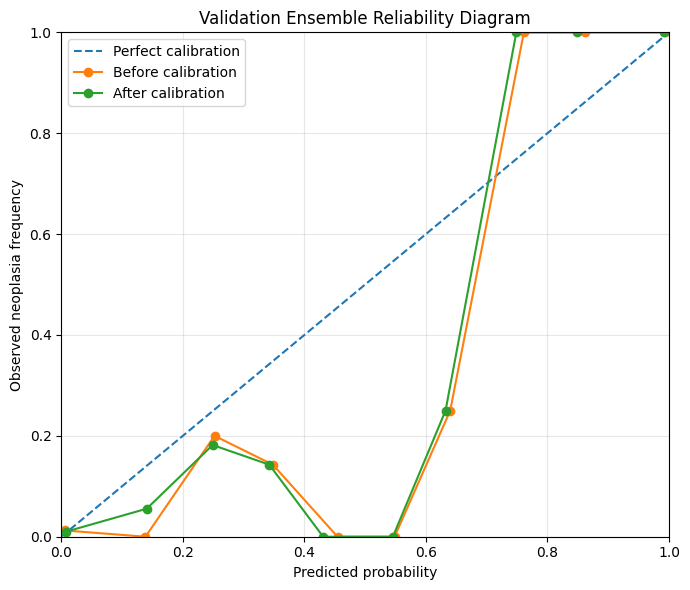

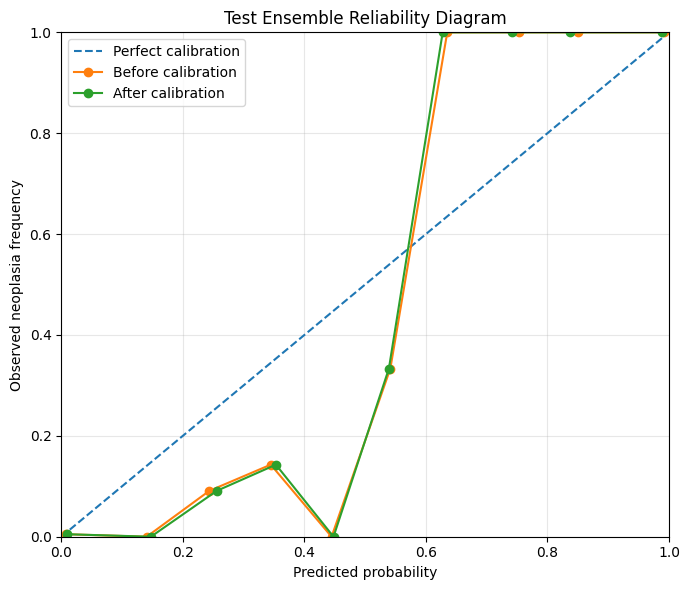


FINAL EXPERIMENT 9 SUMMARY
Learned temperature: 1.0617399215698242

Validation calibration:
Brier before: 0.022645
Brier after: 0.022789
NLL before: 0.089931
NLL after: 0.089682
ECE before: 0.02458
ECE after: 0.020695

Calibrated test operating point:
Recall: 0.9615
PPV: 0.2252
Specificity: 0.8054
False positives: 86
False negatives: 1

Files saved:
/content/drive/MyDrive/RARE26/results/ensemble_temperature_scaling_parameter.csv
/content/drive/MyDrive/RARE26/results/ensemble_calibration_metrics.csv
/content/drive/MyDrive/RARE26/results/calibrated_ensemble_validation_threshold_search.csv
/content/drive/MyDrive/RARE26/results/calibrated_ensemble_test_metrics.csv
/content/drive/MyDrive/RARE26/results/calibrated_ensemble_test_predictions.csv
/content/drive/MyDrive/RARE26/results/calibrated_ensemble_validation_predictions.csv
/content/drive/MyDrive/RARE26/results/figures/ensemble_validation_reliability_diagram.png
/content/drive/MyDrive/RARE26/results/figures/ensemble_test_reliability_diag

In [ ]:
# ================================================================
# EXPERIMENT 9
# VALIDATION-ONLY TEMPERATURE SCALING
# FOR THE SELECTED ENSEMBLE
#
# Selected ensemble:
# Baseline weight = 0.45
# Weighted + Augmentation weight = 0.55
#
# Purpose:
# - Probability reliability improve karna
# - Brier Score, NLL aur ECE evaluate karna
# - Threshold sirf validation set par select karna
# ================================================================

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss,
)

from IPython.display import display as show_table


# ================================================================
# 1. REPRODUCIBILITY
# ================================================================

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)


# ================================================================
# 2. PATHS
# ================================================================

drive_folder = Path(
    "/content/drive/MyDrive/RARE26"
)

splits_folder = drive_folder / "splits"
models_folder = drive_folder / "models"
results_folder = drive_folder / "results"
figures_folder = results_folder / "figures"

figures_folder.mkdir(
    parents=True,
    exist_ok=True
)


validation_csv_path = (
    splits_folder / "validation_colab.csv"
)

baseline_model_path = (
    models_folder / "resnet18_baseline_best.pth"
)

augmentation_model_path = (
    models_folder
    / "resnet18_weighted_augmentation_best.pth"
)

existing_test_predictions_path = (
    results_folder
    / "baseline_augmentation_ensemble_test_predictions.csv"
)


temperature_path = (
    results_folder
    / "ensemble_temperature_scaling_parameter.csv"
)

calibration_metrics_path = (
    results_folder
    / "ensemble_calibration_metrics.csv"
)

threshold_search_path = (
    results_folder
    / "calibrated_ensemble_validation_threshold_search.csv"
)

calibrated_test_metrics_path = (
    results_folder
    / "calibrated_ensemble_test_metrics.csv"
)

calibrated_test_predictions_path = (
    results_folder
    / "calibrated_ensemble_test_predictions.csv"
)

validation_predictions_path = (
    results_folder
    / "calibrated_ensemble_validation_predictions.csv"
)

validation_reliability_path = (
    figures_folder
    / "ensemble_validation_reliability_diagram.png"
)

test_reliability_path = (
    figures_folder
    / "ensemble_test_reliability_diagram.png"
)


# ================================================================
# 3. SELECTED ENSEMBLE SETTINGS
# ================================================================

BASELINE_WEIGHT = 0.45
AUGMENTATION_WEIGHT = 0.55

print(
    "Baseline weight:",
    BASELINE_WEIGHT
)

print(
    "Augmentation weight:",
    AUGMENTATION_WEIGHT
)


# ================================================================
# 4. VALIDATION MANIFEST
# ================================================================

validation_df = pd.read_csv(
    validation_csv_path
)


validation_df["colab_path"] = (
    validation_df["colab_path"]
    .astype(str)
    .str.replace(
        "\\",
        "/",
        regex=False
    )
)

validation_df["label"] = (
    validation_df["label"]
    .astype(int)
)

validation_df["center_name"] = (
    validation_df["center"]
    .astype(str)
    .str.lower()
    .str.replace(
        "centre_",
        "center_",
        regex=False
    )
)


print("\nValidation distribution:")

show_table(
    pd.crosstab(
        validation_df["center_name"],
        validation_df["label"]
    )
)


missing_validation_images = int(
    (
        ~validation_df["colab_path"]
        .apply(
            lambda path:
                Path(path).exists()
        )
    ).sum()
)

print(
    "Missing validation images:",
    missing_validation_images
)

if missing_validation_images > 0:

    raise FileNotFoundError(
        "Validation images /content mein missing hain."
    )


# ================================================================
# 5. EVALUATION TRANSFORM
# ================================================================

evaluation_transform = transforms.Compose([

    transforms.Resize(
        (224, 224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],

        std=[
            0.229,
            0.224,
            0.225
        ]
    ),
])


# ================================================================
# 6. VALIDATION DATASET
# ================================================================

class CalibrationDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform
    ):

        self.dataframe = (
            dataframe.copy()
            .reset_index(drop=True)
        )

        self.transform = transform


    def __len__(self):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index
    ):

        row = self.dataframe.iloc[
            index
        ]

        image = Image.open(
            row["colab_path"]
        ).convert("RGB")

        image = self.transform(
            image
        )

        label = int(
            row["label"]
        )

        center_name = str(
            row["center_name"]
        )

        return (
            image,
            label,
            center_name
        )


validation_dataset = CalibrationDataset(
    validation_df,
    evaluation_transform
)


validation_loader = DataLoader(

    validation_dataset,

    batch_size=32,

    shuffle=False,

    num_workers=2,

    pin_memory=torch.cuda.is_available()
)


# ================================================================
# 7. LOAD BOTH SAVED MODELS
# ================================================================

def load_saved_resnet18(
    model_path
):

    checkpoint = torch.load(

        model_path,

        map_location=device,

        weights_only=False
    )

    model = resnet18(
        weights=None
    )

    model.fc = nn.Linear(
        model.fc.in_features,
        2
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model = model.to(
        device
    )

    model.eval()

    return model, checkpoint


baseline_model, baseline_checkpoint = (
    load_saved_resnet18(
        baseline_model_path
    )
)


augmentation_model, augmentation_checkpoint = (
    load_saved_resnet18(
        augmentation_model_path
    )
)


print(
    "\nBaseline checkpoint epoch:",
    baseline_checkpoint["epoch"]
)

print(
    "Augmentation checkpoint epoch:",
    augmentation_checkpoint["epoch"]
)


# ================================================================
# 8. COLLECT VALIDATION PROBABILITIES
# ================================================================

validation_labels = []
validation_centers = []

validation_baseline_probabilities = []
validation_augmentation_probabilities = []


baseline_model.eval()
augmentation_model.eval()


with torch.no_grad():

    for (
        images,
        labels,
        center_names
    ) in validation_loader:

        images = images.to(
            device,
            non_blocking=True
        )


        baseline_outputs = baseline_model(
            images
        )

        augmentation_outputs = (
            augmentation_model(
                images
            )
        )


        baseline_probabilities = (
            torch.softmax(
                baseline_outputs,
                dim=1
            )[:, 1]
        )


        augmentation_probabilities = (
            torch.softmax(
                augmentation_outputs,
                dim=1
            )[:, 1]
        )


        validation_labels.extend(
            labels.numpy()
        )

        validation_centers.extend(
            list(center_names)
        )

        validation_baseline_probabilities.extend(
            baseline_probabilities
            .cpu()
            .numpy()
        )

        validation_augmentation_probabilities.extend(
            augmentation_probabilities
            .cpu()
            .numpy()
        )


validation_labels = np.array(
    validation_labels
).astype(int)

validation_centers = np.array(
    validation_centers
)

validation_baseline_probabilities = np.array(
    validation_baseline_probabilities
)

validation_augmentation_probabilities = np.array(
    validation_augmentation_probabilities
)


validation_ensemble_probabilities = (

    BASELINE_WEIGHT
    * validation_baseline_probabilities

    +

    AUGMENTATION_WEIGHT
    * validation_augmentation_probabilities
)


# ================================================================
# 9. READ SAVED TEST ENSEMBLE PROBABILITIES
# ================================================================

test_predictions_df = pd.read_csv(
    existing_test_predictions_path
)


if "center_name" not in test_predictions_df.columns:

    test_predictions_df["center_name"] = (
        test_predictions_df["center"]
        .astype(str)
        .str.lower()
        .str.replace(
            "centre_",
            "center_",
            regex=False
        )
    )


test_labels = (
    test_predictions_df["true_label"]
    .astype(int)
    .to_numpy()
)

test_centers = (
    test_predictions_df["center_name"]
    .astype(str)
    .to_numpy()
)

test_ensemble_probabilities = (
    test_predictions_df[
        "ensemble_probability"
    ]
    .astype(float)
    .to_numpy()
)


# ================================================================
# 10. CONVERT PROBABILITIES TO LOGITS
# ================================================================

def probabilities_to_logits(
    probabilities
):

    clipped_probabilities = np.clip(
        probabilities,
        1e-6,
        1 - 1e-6
    )

    return np.log(
        clipped_probabilities
        /
        (
            1
            - clipped_probabilities
        )
    )


validation_ensemble_logits = (
    probabilities_to_logits(
        validation_ensemble_probabilities
    )
)

test_ensemble_logits = (
    probabilities_to_logits(
        test_ensemble_probabilities
    )
)


# ================================================================
# 11. FIT TEMPERATURE ON VALIDATION ONLY
# ================================================================

validation_logits_tensor = torch.tensor(

    validation_ensemble_logits,

    dtype=torch.float32,

    device=device
)


validation_labels_tensor = torch.tensor(

    validation_labels,

    dtype=torch.float32,

    device=device
)


log_temperature = nn.Parameter(

    torch.zeros(
        1,
        device=device
    )
)


temperature_optimizer = torch.optim.LBFGS(

    [log_temperature],

    lr=0.1,

    max_iter=100,

    line_search_fn="strong_wolfe"
)


def temperature_closure():

    temperature_optimizer.zero_grad()

    temperature = torch.exp(
        log_temperature
    )

    calibrated_logits = (
        validation_logits_tensor
        /
        temperature
    )

    loss = (
        F.binary_cross_entropy_with_logits(

            calibrated_logits,

            validation_labels_tensor
        )
    )

    loss.backward()

    return loss


temperature_optimizer.step(
    temperature_closure
)


temperature = float(
    torch.exp(
        log_temperature
    ).detach().cpu().item()
)


print("\n" + "=" * 90)

print(
    "TEMPERATURE SCALING RESULT"
)

print("=" * 90)

print(
    "Learned temperature:",
    temperature
)


# ================================================================
# 12. APPLY CALIBRATION
# ================================================================

def apply_temperature_scaling(
    logits,
    temperature
):

    scaled_logits = (
        logits
        /
        temperature
    )

    return (
        1.0
        /
        (
            1.0
            + np.exp(
                -scaled_logits
            )
        )
    )


validation_calibrated_probabilities = (
    apply_temperature_scaling(

        validation_ensemble_logits,

        temperature
    )
)


test_calibrated_probabilities = (
    apply_temperature_scaling(

        test_ensemble_logits,

        temperature
    )
)


# ================================================================
# 13. EXPECTED CALIBRATION ERROR
# ================================================================

def expected_calibration_error(
    labels,
    probabilities,
    number_of_bins=10
):

    labels = np.asarray(
        labels
    ).astype(int)

    probabilities = np.asarray(
        probabilities
    ).astype(float)


    bin_edges = np.linspace(
        0.0,
        1.0,
        number_of_bins + 1
    )


    ece = 0.0


    for bin_index in range(
        number_of_bins
    ):

        lower_bound = bin_edges[
            bin_index
        ]

        upper_bound = bin_edges[
            bin_index + 1
        ]


        if bin_index == (
            number_of_bins - 1
        ):

            bin_mask = (

                probabilities
                >= lower_bound

            ) & (

                probabilities
                <= upper_bound
            )

        else:

            bin_mask = (

                probabilities
                >= lower_bound

            ) & (

                probabilities
                < upper_bound
            )


        if bin_mask.sum() == 0:

            continue


        bin_accuracy = labels[
            bin_mask
        ].mean()


        bin_confidence = probabilities[
            bin_mask
        ].mean()


        bin_weight = (
            bin_mask.sum()
            /
            len(labels)
        )


        ece += (

            bin_weight
            *
            abs(
                bin_accuracy
                - bin_confidence
            )
        )


    return float(ece)


# ================================================================
# 14. CALIBRATION METRICS
# ================================================================

def calculate_calibration_metrics(
    labels,
    probabilities,
    dataset_name,
    calibration_status
):

    probabilities = np.clip(
        probabilities,
        1e-6,
        1 - 1e-6
    )


    return {

        "dataset":
            dataset_name,

        "calibration_status":
            calibration_status,

        "temperature":
            temperature,

        "brier_score":
            float(
                brier_score_loss(
                    labels,
                    probabilities
                )
            ),

        "negative_log_likelihood":
            float(
                log_loss(
                    labels,
                    probabilities,
                    labels=[0, 1]
                )
            ),

        "ece_10_bins":
            expected_calibration_error(
                labels,
                probabilities,
                number_of_bins=10
            ),

        "auroc":
            float(
                roc_auc_score(
                    labels,
                    probabilities
                )
            ),

        "auprc":
            float(
                average_precision_score(
                    labels,
                    probabilities
                )
            ),
    }


calibration_metric_rows = [

    calculate_calibration_metrics(

        validation_labels,

        validation_ensemble_probabilities,

        "validation",

        "before_temperature_scaling"
    ),

    calculate_calibration_metrics(

        validation_labels,

        validation_calibrated_probabilities,

        "validation",

        "after_temperature_scaling"
    ),

    calculate_calibration_metrics(

        test_labels,

        test_ensemble_probabilities,

        "test",

        "before_temperature_scaling"
    ),

    calculate_calibration_metrics(

        test_labels,

        test_calibrated_probabilities,

        "test",

        "after_temperature_scaling"
    ),
]


calibration_metrics_df = pd.DataFrame(
    calibration_metric_rows
)


calibration_metrics_df.to_csv(
    calibration_metrics_path,
    index=False
)


pd.DataFrame(
    [
        {
            "temperature":
                temperature,

            "baseline_weight":
                BASELINE_WEIGHT,

            "augmentation_weight":
                AUGMENTATION_WEIGHT,
        }
    ]
).to_csv(
    temperature_path,
    index=False
)


print("\n" + "=" * 100)

print(
    "CALIBRATION METRICS"
)

print("=" * 100)


show_table(
    calibration_metrics_df
)


# ================================================================
# 15. CLASSIFICATION METRICS FUNCTION
# ================================================================

def calculate_classification_metrics(
    labels,
    probabilities,
    threshold
):

    predictions = (
        probabilities
        >= threshold
    ).astype(int)


    tn, fp, fn, tp = confusion_matrix(

        labels,

        predictions,

        labels=[0, 1]
    ).ravel()


    specificity = (

        tn / (tn + fp)

        if (tn + fp) > 0

        else np.nan
    )


    return {

        "accuracy": float(
            accuracy_score(
                labels,
                predictions
            )
        ),

        "precision": float(
            precision_score(
                labels,
                predictions,
                zero_division=0
            )
        ),

        "recall": float(
            recall_score(
                labels,
                predictions,
                zero_division=0
            )
        ),

        "specificity": float(
            specificity
        ),

        "auroc": float(
            roc_auc_score(
                labels,
                probabilities
            )
        ),

        "auprc": float(
            average_precision_score(
                labels,
                probabilities
            )
        ),

        "true_negatives": int(tn),

        "false_positives": int(fp),

        "false_negatives": int(fn),

        "true_positives": int(tp),
    }


# ================================================================
# 16. SELECT CALIBRATED THRESHOLD ON VALIDATION
#
# Conditions:
# - Overall recall >= 90%
# - Minimum centre recall >= 80%
# - Maximum precision
# ================================================================

candidate_thresholds = np.unique(
    np.concatenate(
        [
            np.array([0.0]),
            validation_calibrated_probabilities,
            np.array([1.0]),
        ]
    )
)


threshold_records = []


for threshold in candidate_thresholds:

    overall_metrics = (
        calculate_classification_metrics(

            validation_labels,

            validation_calibrated_probabilities,

            threshold
        )
    )


    center_1_mask = (
        validation_centers
        == "center_1"
    )

    center_2_mask = (
        validation_centers
        == "center_2"
    )


    center_1_metrics = (
        calculate_classification_metrics(

            validation_labels[
                center_1_mask
            ],

            validation_calibrated_probabilities[
                center_1_mask
            ],

            threshold
        )
    )


    center_2_metrics = (
        calculate_classification_metrics(

            validation_labels[
                center_2_mask
            ],

            validation_calibrated_probabilities[
                center_2_mask
            ],

            threshold
        )
    )


    minimum_center_recall = min(

        center_1_metrics["recall"],

        center_2_metrics["recall"]
    )


    threshold_records.append({

        "threshold":
            float(threshold),

        "overall_recall":
            overall_metrics["recall"],

        "overall_precision":
            overall_metrics["precision"],

        "overall_specificity":
            overall_metrics["specificity"],

        "center_1_recall":
            center_1_metrics["recall"],

        "center_1_precision":
            center_1_metrics["precision"],

        "center_2_recall":
            center_2_metrics["recall"],

        "center_2_precision":
            center_2_metrics["precision"],

        "minimum_center_recall":
            minimum_center_recall,
    })


threshold_search_df = pd.DataFrame(
    threshold_records
)


eligible_thresholds_df = (
    threshold_search_df[

        (
            threshold_search_df[
                "overall_recall"
            ] >= 0.90
        )

        &

        (
            threshold_search_df[
                "minimum_center_recall"
            ] >= 0.80
        )

    ].copy()
)


if len(
    eligible_thresholds_df
) == 0:

    eligible_thresholds_df = (
        threshold_search_df[

            threshold_search_df[
                "overall_recall"
            ] >= 0.90

        ].copy()
    )


eligible_thresholds_df = (
    eligible_thresholds_df
    .sort_values(

        by=[
            "overall_precision",
            "minimum_center_recall",
            "overall_specificity",
            "threshold",
        ],

        ascending=[
            False,
            False,
            False,
            False,
        ]
    )
)


selected_threshold_row = (
    eligible_thresholds_df.iloc[0]
)


selected_calibrated_threshold = float(
    selected_threshold_row[
        "threshold"
    ]
)


threshold_search_df.to_csv(
    threshold_search_path,
    index=False
)


print("\n" + "=" * 90)

print(
    "VALIDATION-SELECTED CALIBRATED THRESHOLD"
)

print("=" * 90)


print(
    "Selected threshold:",
    selected_calibrated_threshold
)

print(
    "Validation overall recall:",
    selected_threshold_row[
        "overall_recall"
    ]
)

print(
    "Validation overall precision:",
    selected_threshold_row[
        "overall_precision"
    ]
)

print(
    "Validation Center 1 recall:",
    selected_threshold_row[
        "center_1_recall"
    ]
)

print(
    "Validation Center 2 recall:",
    selected_threshold_row[
        "center_2_recall"
    ]
)


# ================================================================
# 17. TEST METRICS
# ================================================================

test_metric_rows = []


for scope_name, center_name, mask in [

    (
        "overall",
        "all_centers",
        np.ones(
            len(test_labels),
            dtype=bool
        )
    ),

    (
        "per_center",
        "center_1",
        test_centers == "center_1"
    ),

    (
        "per_center",
        "center_2",
        test_centers == "center_2"
    ),
]:

    metrics = calculate_classification_metrics(

        test_labels[mask],

        test_calibrated_probabilities[mask],

        selected_calibrated_threshold
    )


    test_metric_rows.append({

        "scope":
            scope_name,

        "center":
            center_name,

        "temperature":
            temperature,

        "threshold":
            selected_calibrated_threshold,

        **metrics,
    })


calibrated_test_metrics_df = pd.DataFrame(
    test_metric_rows
)


calibrated_test_metrics_df.to_csv(
    calibrated_test_metrics_path,
    index=False
)


print("\n" + "=" * 100)

print(
    "FINAL CALIBRATED ENSEMBLE TEST RESULTS"
)

print("=" * 100)


show_table(
    calibrated_test_metrics_df
)


# ================================================================
# 18. SAVE VALIDATION AND TEST PREDICTIONS
# ================================================================

validation_output_df = (
    validation_df.copy()
    .reset_index(drop=True)
)


validation_output_df[
    "baseline_probability"
] = validation_baseline_probabilities


validation_output_df[
    "augmentation_probability"
] = validation_augmentation_probabilities


validation_output_df[
    "uncalibrated_ensemble_probability"
] = validation_ensemble_probabilities


validation_output_df[
    "calibrated_ensemble_probability"
] = validation_calibrated_probabilities


validation_output_df[
    "calibrated_threshold"
] = selected_calibrated_threshold


validation_output_df.to_csv(
    validation_predictions_path,
    index=False
)


calibrated_test_predictions_df = (
    test_predictions_df.copy()
)


calibrated_test_predictions_df[
    "uncalibrated_ensemble_probability"
] = test_ensemble_probabilities


calibrated_test_predictions_df[
    "calibrated_ensemble_probability"
] = test_calibrated_probabilities


calibrated_test_predictions_df[
    "temperature"
] = temperature


calibrated_test_predictions_df[
    "calibrated_threshold"
] = selected_calibrated_threshold


calibrated_test_predictions_df[
    "calibrated_prediction"
] = (

    test_calibrated_probabilities
    >= selected_calibrated_threshold

).astype(int)


calibrated_test_predictions_df.to_csv(
    calibrated_test_predictions_path,
    index=False
)


# ================================================================
# 19. RELIABILITY DIAGRAM FUNCTION
# ================================================================

def plot_reliability_diagram(
    labels,
    probabilities_before,
    probabilities_after,
    title,
    save_path,
    number_of_bins=10
):

    bin_edges = np.linspace(
        0.0,
        1.0,
        number_of_bins + 1
    )


    def calculate_bin_points(
        probabilities
    ):

        mean_confidences = []
        observed_frequencies = []


        for index in range(
            number_of_bins
        ):

            lower_bound = bin_edges[
                index
            ]

            upper_bound = bin_edges[
                index + 1
            ]


            if index == (
                number_of_bins - 1
            ):

                mask = (

                    probabilities
                    >= lower_bound

                ) & (

                    probabilities
                    <= upper_bound
                )

            else:

                mask = (

                    probabilities
                    >= lower_bound

                ) & (

                    probabilities
                    < upper_bound
                )


            if mask.sum() == 0:

                continue


            mean_confidences.append(

                probabilities[
                    mask
                ].mean()
            )


            observed_frequencies.append(

                labels[
                    mask
                ].mean()
            )


        return (
            mean_confidences,
            observed_frequencies
        )


    (
        confidence_before,
        frequency_before
    ) = calculate_bin_points(
        probabilities_before
    )


    (
        confidence_after,
        frequency_after
    ) = calculate_bin_points(
        probabilities_after
    )


    plt.figure(
        figsize=(7, 6)
    )


    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        label="Perfect calibration"
    )


    plt.plot(
        confidence_before,
        frequency_before,
        marker="o",
        label="Before calibration"
    )


    plt.plot(
        confidence_after,
        frequency_after,
        marker="o",
        label="After calibration"
    )


    plt.title(
        title
    )

    plt.xlabel(
        "Predicted probability"
    )

    plt.ylabel(
        "Observed neoplasia frequency"
    )

    plt.xlim(
        0,
        1
    )

    plt.ylim(
        0,
        1
    )

    plt.grid(
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


plot_reliability_diagram(

    labels=validation_labels,

    probabilities_before=
        validation_ensemble_probabilities,

    probabilities_after=
        validation_calibrated_probabilities,

    title=
        "Validation Ensemble Reliability Diagram",

    save_path=
        validation_reliability_path
)


plot_reliability_diagram(

    labels=test_labels,

    probabilities_before=
        test_ensemble_probabilities,

    probabilities_after=
        test_calibrated_probabilities,

    title=
        "Test Ensemble Reliability Diagram",

    save_path=
        test_reliability_path
)


# ================================================================
# 20. SIMPLE FINAL SUMMARY
# ================================================================

before_validation = (
    calibration_metrics_df[
        (
            calibration_metrics_df[
                "dataset"
            ] == "validation"
        )
        &
        (
            calibration_metrics_df[
                "calibration_status"
            ]
            ==
            "before_temperature_scaling"
        )
    ].iloc[0]
)


after_validation = (
    calibration_metrics_df[
        (
            calibration_metrics_df[
                "dataset"
            ] == "validation"
        )
        &
        (
            calibration_metrics_df[
                "calibration_status"
            ]
            ==
            "after_temperature_scaling"
        )
    ].iloc[0]
)


overall_test_row = (
    calibrated_test_metrics_df[
        calibrated_test_metrics_df[
            "scope"
        ] == "overall"
    ].iloc[0]
)


print("\n" + "=" * 100)

print(
    "FINAL EXPERIMENT 9 SUMMARY"
)

print("=" * 100)


print(
    "Learned temperature:",
    temperature
)


print("\nValidation calibration:")

print(
    "Brier before:",
    round(
        before_validation[
            "brier_score"
        ],
        6
    )
)

print(
    "Brier after:",
    round(
        after_validation[
            "brier_score"
        ],
        6
    )
)

print(
    "NLL before:",
    round(
        before_validation[
            "negative_log_likelihood"
        ],
        6
    )
)

print(
    "NLL after:",
    round(
        after_validation[
            "negative_log_likelihood"
        ],
        6
    )
)

print(
    "ECE before:",
    round(
        before_validation[
            "ece_10_bins"
        ],
        6
    )
)

print(
    "ECE after:",
    round(
        after_validation[
            "ece_10_bins"
        ],
        6
    )
)


print("\nCalibrated test operating point:")

print(
    "Recall:",
    round(
        overall_test_row[
            "recall"
        ],
        4
    )
)

print(
    "PPV:",
    round(
        overall_test_row[
            "precision"
        ],
        4
    )
)

print(
    "Specificity:",
    round(
        overall_test_row[
            "specificity"
        ],
        4
    )
)

print(
    "False positives:",
    int(
        overall_test_row[
            "false_positives"
        ]
    )
)

print(
    "False negatives:",
    int(
        overall_test_row[
            "false_negatives"
        ]
    )
)


print("\nFiles saved:")

print(
    temperature_path
)

print(
    calibration_metrics_path
)

print(
    threshold_search_path
)

print(
    calibrated_test_metrics_path
)

print(
    calibrated_test_predictions_path
)

print(
    validation_predictions_path
)

print(
    validation_reliability_path
)

print(
    test_reliability_path
)

Classification threshold: 0.01642357287928462
Referral percentile: 0.9

Validation rows: 461
Test rows: 468

Validation columns: ['file_path', 'relative_path', 'center', 'class', 'label', 'sha256', 'split', 'colab_path', 'file_exists', 'center_name', 'baseline_probability', 'augmentation_probability', 'uncalibrated_ensemble_probability', 'calibrated_ensemble_probability', 'calibrated_threshold']

Test columns: ['file_path', 'relative_path', 'center', 'class', 'label', 'sha256', 'split', 'colab_path', 'file_exists', 'center_name', 'true_label', 'baseline_probability', 'augmentation_probability', 'ensemble_probability', 'ensemble_threshold', 'ensemble_prediction', 'uncalibrated_ensemble_probability', 'calibrated_ensemble_probability', 'temperature', 'calibrated_threshold', 'calibrated_prediction']

VALIDATION-SELECTED UNCERTAINTY REFERRAL
Referral cutoff: 0.8300795372378887
Validation referral count: 47
Validation referral rate: 0.102
Test referral count: 53
Test referral rate: 0.1132

E

,evaluation_group,referral_cutoff,referral_rate,total_cases,accuracy,precision,recall,specificity,auroc,auprc,...,true_positives,total_test_errors,referred_test_errors,error_capture_rate,total_false_negatives,referred_false_negatives,false_negative_capture_rate,total_false_positives,referred_false_positives,false_positive_capture_rate
0,all_test_cases,0.83008,0.113248,468,0.814103,0.225225,0.961538,0.805430,0.976679,0.902280,...,25,87,36,0.413793,1,0,0.0,86,36,0.418605
1,automatic_low_uncertainty_cases,0.83008,0.113248,415,0.877108,0.324324,0.960000,0.871795,0.984923,0.929558,...,24,87,36,0.413793,1,0,0.0,86,36,0.418605
2,referred_high_uncertainty_cases,0.83008,0.113248,53,0.320755,0.027027,1.000000,0.307692,0.596154,0.045455,...,1,87,36,0.413793,1,0,0.0,86,36,0.418605



PER-CENTRE REFERRAL SUMMARY


,center,total_cases,referred_cases,referral_rate,total_errors,referred_errors,false_negatives,referred_false_negatives,false_positives,referred_false_positives
0,center_1,344,33,0.09593,45,20,1,0,44,20
1,center_2,124,20,0.16129,42,16,0,0,42,16



Main referral findings:
Test referral rate: 0.1132
Total classification errors: 87
Errors captured in referred group: 36
Error capture rate: 0.4138
Total false negatives: 1
False negatives captured: 0
False-negative capture rate: 0.0
Automatic low-uncertainty recall: 0.96
Automatic low-uncertainty PPV: 0.3243
Automatic low-uncertainty specificity: 0.8718


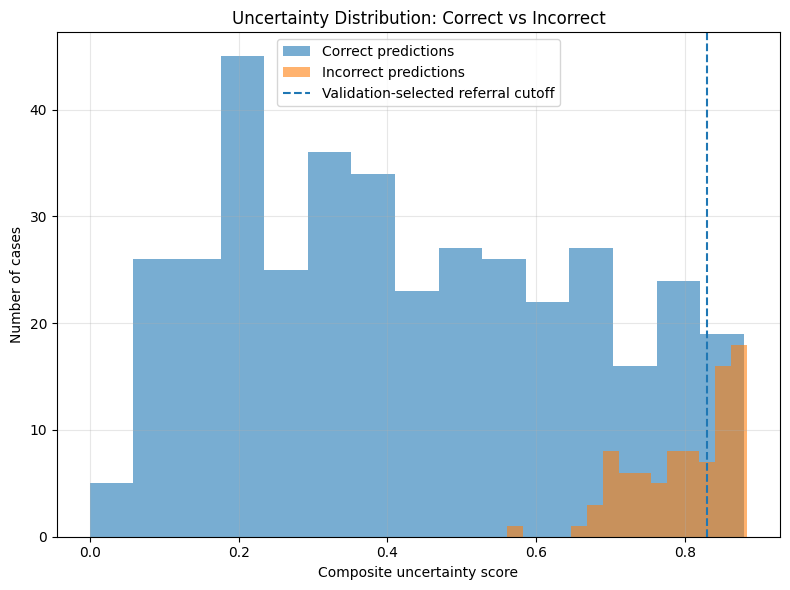

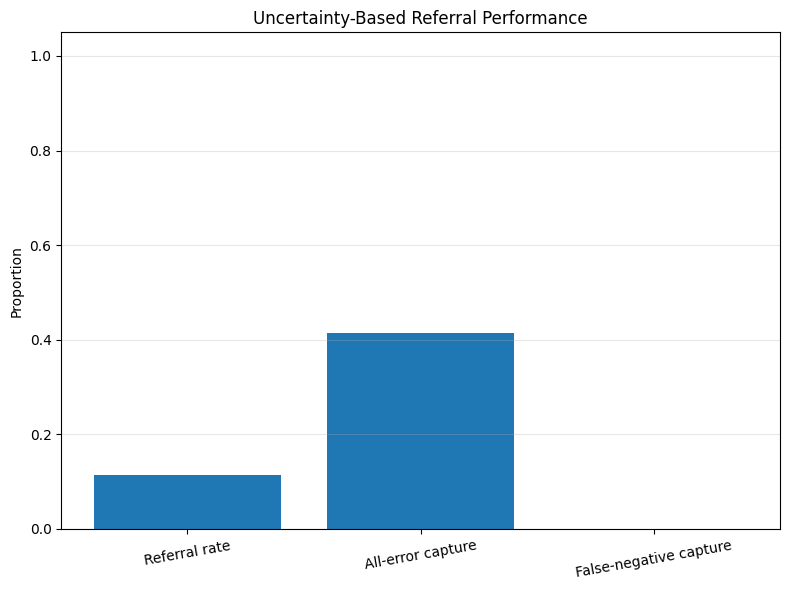


FINAL EXPERIMENT 10 SUMMARY
Validation-selected referral cutoff: 0.8300795372378887
Test referral count: 53
Test referral rate: 0.1132
Total test errors: 87
Errors captured by referral: 36
Error capture rate: 0.4138
False negatives captured: 0 / 1
Automatic cases recall: 0.96
Automatic cases PPV: 0.3243
Automatic cases specificity: 0.8718

Files saved:
/content/drive/MyDrive/RARE26/results/ensemble_uncertainty_validation_predictions.csv
/content/drive/MyDrive/RARE26/results/ensemble_uncertainty_test_predictions.csv
/content/drive/MyDrive/RARE26/results/ensemble_uncertainty_referral_summary.csv
/content/drive/MyDrive/RARE26/results/ensemble_uncertainty_center_referral_summary.csv
/content/drive/MyDrive/RARE26/results/figures/ensemble_uncertainty_correct_vs_error.png
/content/drive/MyDrive/RARE26/results/figures/ensemble_uncertainty_referral_summary.png


In [ ]:
# ================================================================
# EXPERIMENT 10
# ENSEMBLE UNCERTAINTY + MANUAL-REVIEW REFERRAL ANALYSIS
#
# Primary classifier:
# 45% Baseline + 55% Weighted-Augmentation Ensemble
#
# Uncertainty components:
# 1. Predictive entropy
# 2. Baseline vs augmentation disagreement
# 3. Proximity to the selected operating threshold
#
# Referral cutoff:
# Validation set ke top 10% most uncertain cases
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
)

from IPython.display import display as show_table


# ================================================================
# 1. PATHS AND SETTINGS
# ================================================================

drive_folder = Path(
    "/content/drive/MyDrive/RARE26"
)

results_folder = (
    drive_folder / "results"
)

figures_folder = (
    results_folder / "figures"
)

figures_folder.mkdir(
    parents=True,
    exist_ok=True
)


validation_predictions_path = (
    results_folder
    / "calibrated_ensemble_validation_predictions.csv"
)

test_predictions_path = (
    results_folder
    / "calibrated_ensemble_test_predictions.csv"
)


validation_uncertainty_path = (
    results_folder
    / "ensemble_uncertainty_validation_predictions.csv"
)

test_uncertainty_path = (
    results_folder
    / "ensemble_uncertainty_test_predictions.csv"
)

uncertainty_summary_path = (
    results_folder
    / "ensemble_uncertainty_referral_summary.csv"
)

center_referral_path = (
    results_folder
    / "ensemble_uncertainty_center_referral_summary.csv"
)

uncertainty_distribution_graph_path = (
    figures_folder
    / "ensemble_uncertainty_correct_vs_error.png"
)

referral_graph_path = (
    figures_folder
    / "ensemble_uncertainty_referral_summary.png"
)


# Primary uncalibrated ensemble threshold
CLASSIFICATION_THRESHOLD = (
    0.01642357287928462
)

# Validation ke approximately top 10%
# uncertain cases manual review ke liye
REFERRAL_PERCENTILE = 0.90


print(
    "Classification threshold:",
    CLASSIFICATION_THRESHOLD
)

print(
    "Referral percentile:",
    REFERRAL_PERCENTILE
)


# ================================================================
# 2. READ SAVED VALIDATION AND TEST PREDICTIONS
# ================================================================

validation_df = pd.read_csv(
    validation_predictions_path
)

test_df = pd.read_csv(
    test_predictions_path
)


print("\nValidation rows:", len(validation_df))
print("Test rows:", len(test_df))

print(
    "\nValidation columns:",
    list(validation_df.columns)
)

print(
    "\nTest columns:",
    list(test_df.columns)
)


# ================================================================
# 3. STANDARDIZE LABEL AND CENTRE COLUMNS
# ================================================================

if "true_label" in validation_df.columns:

    validation_df[
        "analysis_label"
    ] = (
        validation_df[
            "true_label"
        ].astype(int)
    )

elif "label" in validation_df.columns:

    validation_df[
        "analysis_label"
    ] = (
        validation_df[
            "label"
        ].astype(int)
    )

else:

    raise ValueError(
        "Validation file mein label column nahi mila."
    )


if "true_label" in test_df.columns:

    test_df[
        "analysis_label"
    ] = (
        test_df[
            "true_label"
        ].astype(int)
    )

elif "label" in test_df.columns:

    test_df[
        "analysis_label"
    ] = (
        test_df[
            "label"
        ].astype(int)
    )

else:

    raise ValueError(
        "Test file mein label column nahi mila."
    )


for dataframe in [
    validation_df,
    test_df,
]:

    if "center_name" not in dataframe.columns:

        dataframe[
            "center_name"
        ] = (
            dataframe["center"]
            .astype(str)
            .str.lower()
            .str.replace(
                "centre_",
                "center_",
                regex=False
            )
        )

    else:

        dataframe[
            "center_name"
        ] = (
            dataframe[
                "center_name"
            ]
            .astype(str)
            .str.lower()
            .str.replace(
                "centre_",
                "center_",
                regex=False
            )
        )


# ================================================================
# 4. VERIFY REQUIRED PROBABILITY COLUMNS
# ================================================================

required_columns = [

    "baseline_probability",

    "augmentation_probability",

    "uncalibrated_ensemble_probability",
]


for required_column in required_columns:

    if required_column not in validation_df.columns:

        raise ValueError(
            f"Validation file mein "
            f"{required_column} column missing hai."
        )

    if required_column not in test_df.columns:

        raise ValueError(
            f"Test file mein "
            f"{required_column} column missing hai."
        )


# ================================================================
# 5. UNCERTAINTY HELPER FUNCTIONS
# ================================================================

def safe_logit(
    probabilities
):

    probabilities = np.clip(
        probabilities,
        1e-6,
        1 - 1e-6
    )

    return np.log(
        probabilities
        /
        (
            1
            - probabilities
        )
    )


def normalized_binary_entropy(
    probabilities
):

    probabilities = np.clip(
        probabilities,
        1e-6,
        1 - 1e-6
    )

    entropy = -(
        probabilities
        * np.log(probabilities)

        +

        (
            1 - probabilities
        )
        * np.log(
            1 - probabilities
        )
    )

    return (
        entropy
        /
        np.log(2.0)
    )


def threshold_proximity_score(
    probabilities,
    threshold
):

    probability_logits = safe_logit(
        probabilities
    )

    threshold_logit = safe_logit(
        np.array([threshold])
    )[0]

    logit_distance = np.abs(
        probability_logits
        - threshold_logit
    )

    # 1 means threshold ke bohat qareeb
    # 0 ke qareeb means decision se door
    return np.exp(
        -logit_distance
    )


def empirical_percentile(
    values,
    reference_values
):

    sorted_reference = np.sort(
        np.asarray(
            reference_values
        )
    )

    values = np.asarray(
        values
    )

    percentile_values = (
        np.searchsorted(
            sorted_reference,
            values,
            side="right"
        )
        /
        len(sorted_reference)
    )

    return percentile_values


# ================================================================
# 6. CALCULATE RAW UNCERTAINTY COMPONENTS
# ================================================================

def add_raw_uncertainty_components(
    dataframe
):

    dataframe = dataframe.copy()

    ensemble_probabilities = (
        dataframe[
            "uncalibrated_ensemble_probability"
        ]
        .astype(float)
        .to_numpy()
    )

    baseline_probabilities = (
        dataframe[
            "baseline_probability"
        ]
        .astype(float)
        .to_numpy()
    )

    augmentation_probabilities = (
        dataframe[
            "augmentation_probability"
        ]
        .astype(float)
        .to_numpy()
    )


    dataframe[
        "predictive_entropy"
    ] = normalized_binary_entropy(
        ensemble_probabilities
    )


    dataframe[
        "model_disagreement"
    ] = np.abs(
        baseline_probabilities
        - augmentation_probabilities
    )


    dataframe[
        "threshold_proximity"
    ] = threshold_proximity_score(

        probabilities=
            ensemble_probabilities,

        threshold=
            CLASSIFICATION_THRESHOLD
    )


    dataframe[
        "ensemble_prediction"
    ] = (
        ensemble_probabilities
        >= CLASSIFICATION_THRESHOLD
    ).astype(int)


    dataframe[
        "is_correct"
    ] = (
        dataframe[
            "ensemble_prediction"
        ]
        ==
        dataframe[
            "analysis_label"
        ]
    ).astype(int)


    dataframe[
        "is_error"
    ] = (
        1
        - dataframe[
            "is_correct"
        ]
    )


    dataframe[
        "is_false_negative"
    ] = (

        (
            dataframe[
                "analysis_label"
            ] == 1
        )

        &

        (
            dataframe[
                "ensemble_prediction"
            ] == 0
        )

    ).astype(int)


    dataframe[
        "is_false_positive"
    ] = (

        (
            dataframe[
                "analysis_label"
            ] == 0
        )

        &

        (
            dataframe[
                "ensemble_prediction"
            ] == 1
        )

    ).astype(int)


    return dataframe


validation_df = (
    add_raw_uncertainty_components(
        validation_df
    )
)

test_df = (
    add_raw_uncertainty_components(
        test_df
    )
)


# ================================================================
# 7. CREATE COMPOSITE UNCERTAINTY SCORE
#
# Test normalization validation reference se hogi.
# Test labels selection mein use nahi honge.
# ================================================================

uncertainty_components = [

    "predictive_entropy",

    "model_disagreement",

    "threshold_proximity",
]


for component_name in uncertainty_components:

    validation_df[
        component_name
        + "_percentile"
    ] = empirical_percentile(

        validation_df[
            component_name
        ].to_numpy(),

        validation_df[
            component_name
        ].to_numpy()
    )


    test_df[
        component_name
        + "_percentile"
    ] = empirical_percentile(

        test_df[
            component_name
        ].to_numpy(),

        validation_df[
            component_name
        ].to_numpy()
    )


validation_df[
    "composite_uncertainty_score"
] = (

    validation_df[
        "predictive_entropy_percentile"
    ]

    +

    validation_df[
        "model_disagreement_percentile"
    ]

    +

    validation_df[
        "threshold_proximity_percentile"
    ]

) / 3.0


test_df[
    "composite_uncertainty_score"
] = (

    test_df[
        "predictive_entropy_percentile"
    ]

    +

    test_df[
        "model_disagreement_percentile"
    ]

    +

    test_df[
        "threshold_proximity_percentile"
    ]

) / 3.0


# ================================================================
# 8. SELECT REFERRAL CUTOFF ON VALIDATION ONLY
# ================================================================

referral_cutoff = float(

    validation_df[
        "composite_uncertainty_score"
    ].quantile(
        REFERRAL_PERCENTILE
    )
)


validation_df[
    "refer_for_manual_review"
] = (

    validation_df[
        "composite_uncertainty_score"
    ]
    >= referral_cutoff

).astype(int)


test_df[
    "refer_for_manual_review"
] = (

    test_df[
        "composite_uncertainty_score"
    ]
    >= referral_cutoff

).astype(int)


print("\n" + "=" * 90)

print(
    "VALIDATION-SELECTED UNCERTAINTY REFERRAL"
)

print("=" * 90)


print(
    "Referral cutoff:",
    referral_cutoff
)


print(
    "Validation referral count:",
    int(
        validation_df[
            "refer_for_manual_review"
        ].sum()
    )
)


print(
    "Validation referral rate:",
    round(
        validation_df[
            "refer_for_manual_review"
        ].mean(),
        4
    )
)


print(
    "Test referral count:",
    int(
        test_df[
            "refer_for_manual_review"
        ].sum()
    )
)


print(
    "Test referral rate:",
    round(
        test_df[
            "refer_for_manual_review"
        ].mean(),
        4
    )
)


# ================================================================
# 9. CLASSIFICATION METRICS FUNCTION
# ================================================================

def calculate_metrics(
    dataframe
):

    labels = (
        dataframe[
            "analysis_label"
        ]
        .astype(int)
        .to_numpy()
    )

    predictions = (
        dataframe[
            "ensemble_prediction"
        ]
        .astype(int)
        .to_numpy()
    )

    probabilities = (
        dataframe[
            "uncalibrated_ensemble_probability"
        ]
        .astype(float)
        .to_numpy()
    )


    tn, fp, fn, tp = confusion_matrix(

        labels,

        predictions,

        labels=[0, 1]
    ).ravel()


    specificity = (

        tn / (tn + fp)

        if (tn + fp) > 0

        else np.nan
    )


    if len(
        np.unique(labels)
    ) == 2:

        auroc = roc_auc_score(
            labels,
            probabilities
        )

        auprc = average_precision_score(
            labels,
            probabilities
        )

    else:

        auroc = np.nan
        auprc = np.nan


    return {

        "total_cases":
            int(len(dataframe)),

        "accuracy":
            float(
                accuracy_score(
                    labels,
                    predictions
                )
            ),

        "precision":
            float(
                precision_score(
                    labels,
                    predictions,
                    zero_division=0
                )
            ),

        "recall":
            float(
                recall_score(
                    labels,
                    predictions,
                    zero_division=0
                )
            ),

        "specificity":
            float(specificity),

        "auroc":
            float(auroc),

        "auprc":
            float(auprc),

        "true_negatives":
            int(tn),

        "false_positives":
            int(fp),

        "false_negatives":
            int(fn),

        "true_positives":
            int(tp),
    }


# ================================================================
# 10. TEST REFERRAL ANALYSIS
# ================================================================

all_test_metrics = calculate_metrics(
    test_df
)


automatic_test_df = test_df[

    test_df[
        "refer_for_manual_review"
    ] == 0

].copy()


referred_test_df = test_df[

    test_df[
        "refer_for_manual_review"
    ] == 1

].copy()


automatic_test_metrics = calculate_metrics(
    automatic_test_df
)


if len(referred_test_df) > 0:

    referred_test_metrics = (
        calculate_metrics(
            referred_test_df
        )
    )

else:

    referred_test_metrics = {
        "total_cases": 0
    }


total_test_errors = int(
    test_df["is_error"].sum()
)

referred_test_errors = int(
    referred_test_df[
        "is_error"
    ].sum()
)


error_capture_rate = (

    referred_test_errors
    /
    total_test_errors

    if total_test_errors > 0

    else 0.0
)


total_false_negatives = int(
    test_df[
        "is_false_negative"
    ].sum()
)

referred_false_negatives = int(
    referred_test_df[
        "is_false_negative"
    ].sum()
)


false_negative_capture_rate = (

    referred_false_negatives
    /
    total_false_negatives

    if total_false_negatives > 0

    else 0.0
)


total_false_positives = int(
    test_df[
        "is_false_positive"
    ].sum()
)

referred_false_positives = int(
    referred_test_df[
        "is_false_positive"
    ].sum()
)


false_positive_capture_rate = (

    referred_false_positives
    /
    total_false_positives

    if total_false_positives > 0

    else 0.0
)


# ================================================================
# 11. SAVE SUMMARY TABLE
# ================================================================

summary_rows = [

    {
        "evaluation_group":
            "all_test_cases",

        "referral_cutoff":
            referral_cutoff,

        "referral_rate":
            float(
                test_df[
                    "refer_for_manual_review"
                ].mean()
            ),

        **all_test_metrics,
    },

    {
        "evaluation_group":
            "automatic_low_uncertainty_cases",

        "referral_cutoff":
            referral_cutoff,

        "referral_rate":
            float(
                test_df[
                    "refer_for_manual_review"
                ].mean()
            ),

        **automatic_test_metrics,
    },

    {
        "evaluation_group":
            "referred_high_uncertainty_cases",

        "referral_cutoff":
            referral_cutoff,

        "referral_rate":
            float(
                test_df[
                    "refer_for_manual_review"
                ].mean()
            ),

        **referred_test_metrics,
    },
]


summary_df = pd.DataFrame(
    summary_rows
)


summary_df[
    "total_test_errors"
] = total_test_errors


summary_df[
    "referred_test_errors"
] = referred_test_errors


summary_df[
    "error_capture_rate"
] = error_capture_rate


summary_df[
    "total_false_negatives"
] = total_false_negatives


summary_df[
    "referred_false_negatives"
] = referred_false_negatives


summary_df[
    "false_negative_capture_rate"
] = false_negative_capture_rate


summary_df[
    "total_false_positives"
] = total_false_positives


summary_df[
    "referred_false_positives"
] = referred_false_positives


summary_df[
    "false_positive_capture_rate"
] = false_positive_capture_rate


summary_df.to_csv(
    uncertainty_summary_path,
    index=False
)


# ================================================================
# 12. PER-CENTRE REFERRAL SUMMARY
# ================================================================

center_rows = []


for center_name in [

    "center_1",

    "center_2",
]:

    center_df = test_df[

        test_df[
            "center_name"
        ] == center_name

    ].copy()


    center_referred_df = center_df[

        center_df[
            "refer_for_manual_review"
        ] == 1

    ]


    center_rows.append({

        "center":
            center_name,

        "total_cases":
            int(len(center_df)),

        "referred_cases":
            int(
                len(
                    center_referred_df
                )
            ),

        "referral_rate":
            float(
                center_df[
                    "refer_for_manual_review"
                ].mean()
            ),

        "total_errors":
            int(
                center_df[
                    "is_error"
                ].sum()
            ),

        "referred_errors":
            int(
                center_referred_df[
                    "is_error"
                ].sum()
            ),

        "false_negatives":
            int(
                center_df[
                    "is_false_negative"
                ].sum()
            ),

        "referred_false_negatives":
            int(
                center_referred_df[
                    "is_false_negative"
                ].sum()
            ),

        "false_positives":
            int(
                center_df[
                    "is_false_positive"
                ].sum()
            ),

        "referred_false_positives":
            int(
                center_referred_df[
                    "is_false_positive"
                ].sum()
            ),
    })


center_summary_df = pd.DataFrame(
    center_rows
)


center_summary_df.to_csv(
    center_referral_path,
    index=False
)


# ================================================================
# 13. SAVE DETAILED PREDICTIONS
# ================================================================

validation_df.to_csv(
    validation_uncertainty_path,
    index=False
)


test_df.to_csv(
    test_uncertainty_path,
    index=False
)


# ================================================================
# 14. PRINT RESULTS
# ================================================================

print("\n" + "=" * 100)

print(
    "EXPERIMENT 10 UNCERTAINTY SUMMARY"
)

print("=" * 100)


show_table(
    summary_df
)


print("\n" + "=" * 100)

print(
    "PER-CENTRE REFERRAL SUMMARY"
)

print("=" * 100)


show_table(
    center_summary_df
)


print("\nMain referral findings:")


print(
    "Test referral rate:",
    round(
        test_df[
            "refer_for_manual_review"
        ].mean(),
        4
    )
)


print(
    "Total classification errors:",
    total_test_errors
)


print(
    "Errors captured in referred group:",
    referred_test_errors
)


print(
    "Error capture rate:",
    round(
        error_capture_rate,
        4
    )
)


print(
    "Total false negatives:",
    total_false_negatives
)


print(
    "False negatives captured:",
    referred_false_negatives
)


print(
    "False-negative capture rate:",
    round(
        false_negative_capture_rate,
        4
    )
)


print(
    "Automatic low-uncertainty recall:",
    round(
        automatic_test_metrics[
            "recall"
        ],
        4
    )
)


print(
    "Automatic low-uncertainty PPV:",
    round(
        automatic_test_metrics[
            "precision"
        ],
        4
    )
)


print(
    "Automatic low-uncertainty specificity:",
    round(
        automatic_test_metrics[
            "specificity"
        ],
        4
    )
)


# ================================================================
# 15. GRAPH 1:
# UNCERTAINTY IN CORRECT VS INCORRECT CASES
# ================================================================

correct_scores = test_df.loc[

    test_df[
        "is_correct"
    ] == 1,

    "composite_uncertainty_score"

].to_numpy()


error_scores = test_df.loc[

    test_df[
        "is_error"
    ] == 1,

    "composite_uncertainty_score"

].to_numpy()


plt.figure(
    figsize=(8, 6)
)


plt.hist(
    correct_scores,
    bins=15,
    alpha=0.6,
    label="Correct predictions"
)


plt.hist(
    error_scores,
    bins=15,
    alpha=0.6,
    label="Incorrect predictions"
)


plt.axvline(
    referral_cutoff,
    linestyle="--",
    label="Validation-selected referral cutoff"
)


plt.title(
    "Uncertainty Distribution: Correct vs Incorrect"
)

plt.xlabel(
    "Composite uncertainty score"
)

plt.ylabel(
    "Number of cases"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()


plt.savefig(
    uncertainty_distribution_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ================================================================
# 16. GRAPH 2:
# REFERRAL RATE VS ERROR CAPTURE
# ================================================================

graph_values = [

    float(
        test_df[
            "refer_for_manual_review"
        ].mean()
    ),

    error_capture_rate,

    false_negative_capture_rate,
]


graph_labels = [

    "Referral rate",

    "All-error capture",

    "False-negative capture",
]


plt.figure(
    figsize=(8, 6)
)


plt.bar(
    graph_labels,
    graph_values
)


plt.title(
    "Uncertainty-Based Referral Performance"
)

plt.ylabel(
    "Proportion"
)

plt.ylim(
    0,
    1.05
)

plt.xticks(
    rotation=10
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()


plt.savefig(
    referral_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ================================================================
# 17. FINAL SIMPLE OUTPUT
# ================================================================

print("\n" + "=" * 100)

print(
    "FINAL EXPERIMENT 10 SUMMARY"
)

print("=" * 100)


print(
    "Validation-selected referral cutoff:",
    referral_cutoff
)


print(
    "Test referral count:",
    int(
        test_df[
            "refer_for_manual_review"
        ].sum()
    )
)


print(
    "Test referral rate:",
    round(
        test_df[
            "refer_for_manual_review"
        ].mean(),
        4
    )
)


print(
    "Total test errors:",
    total_test_errors
)


print(
    "Errors captured by referral:",
    referred_test_errors
)


print(
    "Error capture rate:",
    round(
        error_capture_rate,
        4
    )
)


print(
    "False negatives captured:",
    referred_false_negatives,
    "/",
    total_false_negatives
)


print(
    "Automatic cases recall:",
    round(
        automatic_test_metrics[
            "recall"
        ],
        4
    )
)


print(
    "Automatic cases PPV:",
    round(
        automatic_test_metrics[
            "precision"
        ],
        4
    )
)


print(
    "Automatic cases specificity:",
    round(
        automatic_test_metrics[
            "specificity"
        ],
        4
    )
)


print("\nFiles saved:")

print(
    validation_uncertainty_path
)

print(
    test_uncertainty_path
)

print(
    uncertainty_summary_path
)

print(
    center_referral_path
)

print(
    uncertainty_distribution_graph_path
)

print(
    referral_graph_path
)

In [ ]:
Classification threshold: 0.01642357287928462
Referral percentile: 0.9

Validation rows: 461
Test rows: 468

Validation columns: ['file_path', 'relative_path', 'center', 'class', 'label', 'sha256', 'split', 'colab_path', 'file_exists', 'center_name', 'baseline_probability', 'augmentation_probability', 'uncalibrated_ensemble_probability', 'calibrated_ensemble_probability', 'calibrated_threshold']

Test columns: ['file_path', 'relative_path', 'center', 'class', 'label', 'sha256', 'split', 'colab_path', 'file_exists', 'center_name', 'true_label', 'baseline_probability', 'augmentation_probability', 'ensemble_probability', 'ensemble_threshold', 'ensemble_prediction', 'uncalibrated_ensemble_probability', 'calibrated_ensemble_probability', 'temperature', 'calibrated_threshold', 'calibrated_prediction']

==========================================================================================
VALIDATION-SELECTED UNCERTAINTY REFERRAL
==========================================================================================
Referral cutoff: 0.8300795372378887
Validation referral count: 47
Validation referral rate: 0.102
Test referral count: 53
Test referral rate: 0.1132

====================================================================================================
EXPERIMENT 10 UNCERTAINTY SUMMARY
====================================================================================================
evaluation_group	referral_cutoff	referral_rate	total_cases	accuracy	precision	recall	specificity	auroc	auprc	...	true_positives	total_test_errors	referred_test_errors	error_capture_rate	total_false_negatives	referred_false_negatives	false_negative_capture_rate	total_false_positives	referred_false_positives	false_positive_capture_rate
0	all_test_cases	0.83008	0.113248	468	0.814103	0.225225	0.961538	0.805430	0.976679	0.902280	...	25	87	36	0.413793	1	0	0.0	86	36	0.418605
1	automatic_low_uncertainty_cases	0.83008	0.113248	415	0.877108	0.324324	0.960000	0.871795	0.984923	0.929558	...	24	87	36	0.413793	1	0	0.0	86	36	0.418605
2	referred_high_uncertainty_cases	0.83008	0.113248	53	0.320755	0.027027	1.000000	0.307692	0.596154	0.045455	...	1	87	36	0.413793	1	0	0.0	86	36	0.418605
3 rows × 23 columns




====================================================================================================
PER-CENTRE REFERRAL SUMMARY
====================================================================================================
center	total_cases	referred_cases	referral_rate	total_errors	referred_errors	false_negatives	referred_false_negatives	false_positives	referred_false_positives
0	center_1	344	33	0.09593	45	20	1	0	44	20
1	center_2	124	20	0.16129	42	16	0	0	42	16


Main referral findings:
Test referral rate: 0.1132
Total classification errors: 87
Errors captured in referred group: 36
Error capture rate: 0.4138
Total false negatives: 1
False negatives captured: 0
False-negative capture rate: 0.0
Automatic low-uncertainty recall: 0.96
Automatic low-uncertainty PPV: 0.3243
Automatic low-uncertainty specificity: 0.8718



====================================================================================================
FINAL EXPERIMENT 10 SUMMARY
====================================================================================================
Validation-selected referral cutoff: 0.8300795372378887
Test referral count: 53
Test referral rate: 0.1132
Total test errors: 87
Errors captured by referral: 36
Error capture rate: 0.4138
False negatives captured: 0 / 1
Automatic cases recall: 0.96
Automatic cases PPV: 0.3243
Automatic cases specificity: 0.8718

Files saved:
/content/drive/MyDrive/RARE26/results/ensemble_uncertainty_validation_predictions.csv
/content/drive/MyDrive/RARE26/results/ensemble_uncertainty_test_predictions.csv
/content/drive/MyDrive/RARE26/results/ensemble_uncertainty_referral_summary.csv
/content/drive/MyDrive/RARE26/results/ensemble_uncertainty_center_referral_summary.csv
/content/drive/MyDrive/RARE26/results/figures/ensemble_uncertainty_correct_vs_error.png
/content/drive/MyDrive/RARE26/results/figures/ensemble_uncertainty_referral_summary.png

SyntaxError: invalid character '×' (U+00D7) (1654557040.py, line 27)

Classification threshold: 0.01642357287928462
Maximum validation referral rate: 0.15

Validation rows: 461
Test rows: 468

Uncertainty cutoff: 0.8300795372378887
Base validation referral rate: 0.102

VALIDATION-SELECTED ASYMMETRIC REFERRAL RULE
Uncertainty cutoff: 0.8300795372378887
Negative safety cutoff: 0.016423572
Validation referral rate: 0.1019522776572668
Validation FN capture rate: 0.5
Validation all-error capture rate: 0.352112676056338

EXPERIMENT 11 TEST SUMMARY


,evaluation_group,total_cases,accuracy,precision,recall,specificity,auroc,auprc,true_negatives,false_positives,...,test_referral_rate,total_errors,referred_errors,error_capture_rate,total_false_negatives,referred_false_negatives,false_negative_capture_rate,total_false_positives,referred_false_positives,false_positive_capture_rate
0,all_test_cases,468,0.814103,0.225225,0.961538,0.805430,0.976679,0.902280,356,86,...,0.113248,87,36,0.413793,1,0,0.0,86,36,0.418605
1,automatic_cases,415,0.877108,0.324324,0.960000,0.871795,0.984923,0.929558,340,50,...,0.113248,87,36,0.413793,1,0,0.0,86,36,0.418605
2,manual_review_cases,53,0.320755,0.027027,1.000000,0.307692,0.596154,0.045455,16,36,...,0.113248,87,36,0.413793,1,0,0.0,86,36,0.418605



PER-CENTRE ASYMMETRIC REFERRAL


,center,total_cases,referred_cases,referral_rate,total_errors,referred_errors,total_false_negatives,referred_false_negatives,total_false_positives,referred_false_positives
0,center_1,344,33,0.09593,45,20,1,0,44,20
1,center_2,124,20,0.16129,42,16,0,0,42,16



Main findings:
Test referral count: 53
Test referral rate: 0.1132
Errors captured: 36 / 87
Error capture rate: 0.4138
False negatives captured: 0 / 1
False positives captured: 36 / 86
Automatic-case recall: 0.96
Automatic-case PPV: 0.3243
Automatic-case specificity: 0.8718


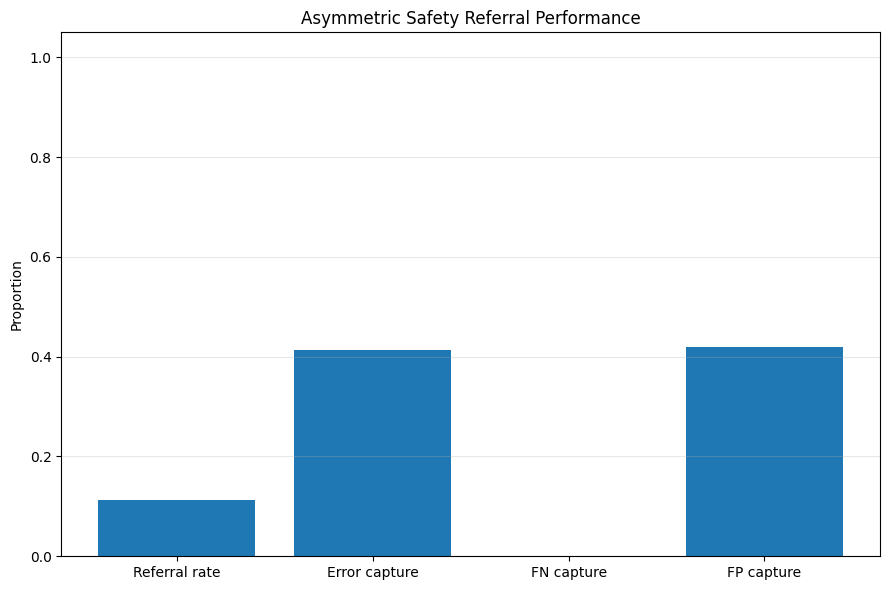

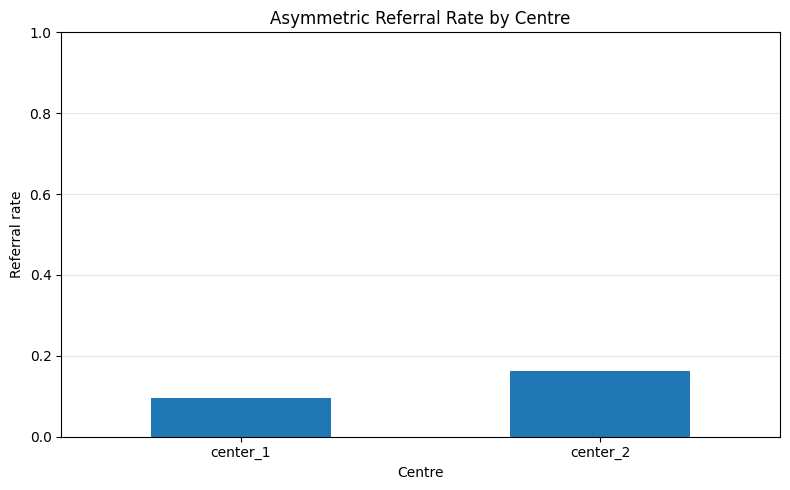


FINAL EXPERIMENT 11 SUMMARY
Uncertainty cutoff: 0.8300795372378887
Negative safety cutoff: 0.016423572
Test referral rate: 0.1132
Error capture rate: 0.4138
False-negative capture rate: 0.0
False-positive capture rate: 0.4186
Automatic recall: 0.96
Automatic PPV: 0.3243
Automatic specificity: 0.8718

Files saved:
/content/drive/MyDrive/RARE26/results/asymmetric_referral_validation_search.csv
/content/drive/MyDrive/RARE26/results/asymmetric_referral_test_predictions.csv
/content/drive/MyDrive/RARE26/results/asymmetric_referral_test_summary.csv
/content/drive/MyDrive/RARE26/results/asymmetric_referral_center_summary.csv
/content/drive/MyDrive/RARE26/results/figures/asymmetric_referral_performance.png
/content/drive/MyDrive/RARE26/results/figures/asymmetric_referral_by_center.png


In [ ]:
# ================================================================
# EXPERIMENT 11
# ASYMMETRIC SAFETY REFERRAL
#
# Existing rule:
# Top uncertain cases -> manual review
#
# New safety rule:
# Predicted-normal cases whose probability is close to the
# positive decision threshold -> manual review
#
# Selection:
# Validation data only
# Maximum target referral rate: 15%
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
)

from IPython.display import display as show_table


# ================================================================
# 1. PATHS AND SETTINGS
# ================================================================

drive_folder = Path(
    "/content/drive/MyDrive/RARE26"
)

results_folder = (
    drive_folder / "results"
)

figures_folder = (
    results_folder / "figures"
)

figures_folder.mkdir(
    parents=True,
    exist_ok=True
)


validation_input_path = (
    results_folder
    / "ensemble_uncertainty_validation_predictions.csv"
)

test_input_path = (
    results_folder
    / "ensemble_uncertainty_test_predictions.csv"
)


validation_search_path = (
    results_folder
    / "asymmetric_referral_validation_search.csv"
)

test_predictions_output_path = (
    results_folder
    / "asymmetric_referral_test_predictions.csv"
)

summary_output_path = (
    results_folder
    / "asymmetric_referral_test_summary.csv"
)

center_summary_output_path = (
    results_folder
    / "asymmetric_referral_center_summary.csv"
)

performance_graph_path = (
    figures_folder
    / "asymmetric_referral_performance.png"
)

center_graph_path = (
    figures_folder
    / "asymmetric_referral_by_center.png"
)


CLASSIFICATION_THRESHOLD = (
    0.01642357287928462
)

UNCERTAINTY_PERCENTILE = 0.90

MAX_VALIDATION_REFERRAL_RATE = 0.15


print(
    "Classification threshold:",
    CLASSIFICATION_THRESHOLD
)

print(
    "Maximum validation referral rate:",
    MAX_VALIDATION_REFERRAL_RATE
)


# ================================================================
# 2. READ EXPERIMENT 10 FILES
# ================================================================

validation_df = pd.read_csv(
    validation_input_path
)

test_df = pd.read_csv(
    test_input_path
)


print("\nValidation rows:", len(validation_df))
print("Test rows:", len(test_df))


required_columns = [
    "analysis_label",
    "center_name",
    "uncalibrated_ensemble_probability",
    "composite_uncertainty_score",
]


for column_name in required_columns:

    if column_name not in validation_df.columns:

        raise ValueError(
            f"Validation file mein "
            f"{column_name} missing hai."
        )

    if column_name not in test_df.columns:

        raise ValueError(
            f"Test file mein "
            f"{column_name} missing hai."
        )


for dataframe in [
    validation_df,
    test_df,
]:

    dataframe["analysis_label"] = (
        dataframe["analysis_label"]
        .astype(int)
    )

    dataframe[
        "uncalibrated_ensemble_probability"
    ] = (
        dataframe[
            "uncalibrated_ensemble_probability"
        ]
        .astype(float)
    )

    dataframe[
        "composite_uncertainty_score"
    ] = (
        dataframe[
            "composite_uncertainty_score"
        ]
        .astype(float)
    )

    dataframe["center_name"] = (
        dataframe["center_name"]
        .astype(str)
    )


# ================================================================
# 3. RECREATE PRIMARY CLASSIFICATION
# ================================================================

for dataframe in [
    validation_df,
    test_df,
]:

    dataframe[
        "ensemble_prediction"
    ] = (

        dataframe[
            "uncalibrated_ensemble_probability"
        ]

        >= CLASSIFICATION_THRESHOLD

    ).astype(int)


    dataframe[
        "is_error"
    ] = (

        dataframe[
            "ensemble_prediction"
        ]

        !=

        dataframe[
            "analysis_label"
        ]

    ).astype(int)


    dataframe[
        "is_false_negative"
    ] = (

        (
            dataframe[
                "analysis_label"
            ] == 1
        )

        &

        (
            dataframe[
                "ensemble_prediction"
            ] == 0
        )

    ).astype(int)


    dataframe[
        "is_false_positive"
    ] = (

        (
            dataframe[
                "analysis_label"
            ] == 0
        )

        &

        (
            dataframe[
                "ensemble_prediction"
            ] == 1
        )

    ).astype(int)


# ================================================================
# 4. BASE UNCERTAINTY REFERRAL
# ================================================================

uncertainty_cutoff = float(

    validation_df[
        "composite_uncertainty_score"
    ].quantile(
        UNCERTAINTY_PERCENTILE
    )
)


validation_df[
    "base_uncertainty_referral"
] = (

    validation_df[
        "composite_uncertainty_score"
    ]

    >= uncertainty_cutoff

).astype(int)


test_df[
    "base_uncertainty_referral"
] = (

    test_df[
        "composite_uncertainty_score"
    ]

    >= uncertainty_cutoff

).astype(int)


print("\nUncertainty cutoff:", uncertainty_cutoff)

print(
    "Base validation referral rate:",
    round(
        validation_df[
            "base_uncertainty_referral"
        ].mean(),
        4
    )
)


# ================================================================
# 5. METRICS FUNCTION
# ================================================================

def calculate_metrics(
    dataframe
):

    labels = (
        dataframe[
            "analysis_label"
        ]
        .astype(int)
        .to_numpy()
    )

    predictions = (
        dataframe[
            "ensemble_prediction"
        ]
        .astype(int)
        .to_numpy()
    )

    probabilities = (
        dataframe[
            "uncalibrated_ensemble_probability"
        ]
        .astype(float)
        .to_numpy()
    )


    tn, fp, fn, tp = confusion_matrix(

        labels,

        predictions,

        labels=[0, 1]

    ).ravel()


    specificity = (

        tn / (tn + fp)

        if (tn + fp) > 0

        else np.nan
    )


    if len(
        np.unique(labels)
    ) == 2:

        auroc = roc_auc_score(
            labels,
            probabilities
        )

        auprc = average_precision_score(
            labels,
            probabilities
        )

    else:

        auroc = np.nan
        auprc = np.nan


    return {

        "total_cases":
            int(len(dataframe)),

        "accuracy":
            float(
                accuracy_score(
                    labels,
                    predictions
                )
            ),

        "precision":
            float(
                precision_score(
                    labels,
                    predictions,
                    zero_division=0
                )
            ),

        "recall":
            float(
                recall_score(
                    labels,
                    predictions,
                    zero_division=0
                )
            ),

        "specificity":
            float(
                specificity
            ),

        "auroc":
            float(
                auroc
            ),

        "auprc":
            float(
                auprc
            ),

        "true_negatives":
            int(tn),

        "false_positives":
            int(fp),

        "false_negatives":
            int(fn),

        "true_positives":
            int(tp),
    }


# ================================================================
# 6. VALIDATION SEARCH FOR NEGATIVE-SIDE SAFETY CUTOFF
#
# Predicted-negative cases:
# probability >= selected safety cutoff
# and probability < classification threshold
# ================================================================

validation_negative_df = validation_df[

    validation_df[
        "ensemble_prediction"
    ] == 0

].copy()


negative_candidate_cutoffs = np.unique(

    np.concatenate(
        [
            validation_negative_df[
                "uncalibrated_ensemble_probability"
            ].to_numpy(),

            np.array([
                0.0,
                CLASSIFICATION_THRESHOLD,
            ]),
        ]
    )
)


search_records = []


for negative_cutoff in negative_candidate_cutoffs:

    negative_safety_referral = (

        (
            validation_df[
                "ensemble_prediction"
            ] == 0
        )

        &

        (
            validation_df[
                "uncalibrated_ensemble_probability"
            ] >= negative_cutoff
        )

    ).astype(int)


    combined_referral = (

        (
            validation_df[
                "base_uncertainty_referral"
            ] == 1
        )

        |

        (
            negative_safety_referral == 1
        )

    ).astype(int)


    referral_rate = float(
        combined_referral.mean()
    )


    referred_mask = (
        combined_referral == 1
    )


    automatic_mask = (
        combined_referral == 0
    )


    total_errors = int(
        validation_df[
            "is_error"
        ].sum()
    )


    referred_errors = int(

        validation_df.loc[
            referred_mask,
            "is_error"
        ].sum()
    )


    total_false_negatives = int(
        validation_df[
            "is_false_negative"
        ].sum()
    )


    referred_false_negatives = int(

        validation_df.loc[
            referred_mask,
            "is_false_negative"
        ].sum()
    )


    error_capture_rate = (

        referred_errors
        / total_errors

        if total_errors > 0

        else 0.0
    )


    false_negative_capture_rate = (

        referred_false_negatives
        / total_false_negatives

        if total_false_negatives > 0

        else 1.0
    )


    if automatic_mask.sum() > 0:

        automatic_metrics = (
            calculate_metrics(

                validation_df.loc[
                    automatic_mask
                ]
            )
        )

    else:

        automatic_metrics = {
            "precision": 0.0,
            "recall": 0.0,
            "specificity": 0.0,
        }


    search_records.append({

        "negative_safety_cutoff":
            float(
                negative_cutoff
            ),

        "validation_referral_count":
            int(
                combined_referral.sum()
            ),

        "validation_referral_rate":
            referral_rate,

        "total_validation_errors":
            total_errors,

        "referred_validation_errors":
            referred_errors,

        "error_capture_rate":
            error_capture_rate,

        "total_validation_false_negatives":
            total_false_negatives,

        "referred_validation_false_negatives":
            referred_false_negatives,

        "false_negative_capture_rate":
            false_negative_capture_rate,

        "automatic_precision":
            automatic_metrics[
                "precision"
            ],

        "automatic_recall":
            automatic_metrics[
                "recall"
            ],

        "automatic_specificity":
            automatic_metrics[
                "specificity"
            ],
    })


search_df = pd.DataFrame(
    search_records
)


eligible_df = search_df[

    search_df[
        "validation_referral_rate"
    ]

    <= MAX_VALIDATION_REFERRAL_RATE

].copy()


if len(eligible_df) == 0:

    print(
        "\n15% referral limit ke andar "
        "koi rule nahi mila."
    )

    print(
        "Limit automatically 20% ki ja rahi hai."
    )


    eligible_df = search_df[

        search_df[
            "validation_referral_rate"
        ] <= 0.20

    ].copy()


eligible_df = eligible_df.sort_values(

    by=[
        "false_negative_capture_rate",
        "error_capture_rate",
        "validation_referral_rate",
        "automatic_specificity",
    ],

    ascending=[
        False,
        False,
        True,
        False,
    ]
)


selected_row = eligible_df.iloc[0]


selected_negative_cutoff = float(

    selected_row[
        "negative_safety_cutoff"
    ]
)


search_df.to_csv(
    validation_search_path,
    index=False
)


print("\n" + "=" * 95)

print(
    "VALIDATION-SELECTED ASYMMETRIC REFERRAL RULE"
)

print("=" * 95)


print(
    "Uncertainty cutoff:",
    uncertainty_cutoff
)


print(
    "Negative safety cutoff:",
    selected_negative_cutoff
)


print(
    "Validation referral rate:",
    selected_row[
        "validation_referral_rate"
    ]
)


print(
    "Validation FN capture rate:",
    selected_row[
        "false_negative_capture_rate"
    ]
)


print(
    "Validation all-error capture rate:",
    selected_row[
        "error_capture_rate"
    ]
)


# ================================================================
# 7. APPLY VALIDATION-SELECTED RULE TO TEST
# ================================================================

test_df[
    "negative_safety_referral"
] = (

    (
        test_df[
            "ensemble_prediction"
        ] == 0
    )

    &

    (
        test_df[
            "uncalibrated_ensemble_probability"
        ]

        >= selected_negative_cutoff
    )

).astype(int)


test_df[
    "asymmetric_manual_review"
] = (

    (
        test_df[
            "base_uncertainty_referral"
        ] == 1
    )

    |

    (
        test_df[
            "negative_safety_referral"
        ] == 1
    )

).astype(int)


referred_test_df = test_df[

    test_df[
        "asymmetric_manual_review"
    ] == 1

].copy()


automatic_test_df = test_df[

    test_df[
        "asymmetric_manual_review"
    ] == 0

].copy()


# ================================================================
# 8. TEST REFERRAL RESULTS
# ================================================================

all_test_metrics = calculate_metrics(
    test_df
)


automatic_test_metrics = calculate_metrics(
    automatic_test_df
)


referred_test_metrics = calculate_metrics(
    referred_test_df
)


total_errors = int(
    test_df[
        "is_error"
    ].sum()
)


referred_errors = int(
    referred_test_df[
        "is_error"
    ].sum()
)


total_false_negatives = int(
    test_df[
        "is_false_negative"
    ].sum()
)


referred_false_negatives = int(
    referred_test_df[
        "is_false_negative"
    ].sum()
)


total_false_positives = int(
    test_df[
        "is_false_positive"
    ].sum()
)


referred_false_positives = int(
    referred_test_df[
        "is_false_positive"
    ].sum()
)


error_capture_rate = (

    referred_errors / total_errors

    if total_errors > 0

    else 0.0
)


false_negative_capture_rate = (

    referred_false_negatives
    / total_false_negatives

    if total_false_negatives > 0

    else 1.0
)


false_positive_capture_rate = (

    referred_false_positives
    / total_false_positives

    if total_false_positives > 0

    else 0.0
)


summary_df = pd.DataFrame([

    {
        "evaluation_group":
            "all_test_cases",

        **all_test_metrics,
    },

    {
        "evaluation_group":
            "automatic_cases",

        **automatic_test_metrics,
    },

    {
        "evaluation_group":
            "manual_review_cases",

        **referred_test_metrics,
    },
])


summary_df[
    "classification_threshold"
] = CLASSIFICATION_THRESHOLD


summary_df[
    "uncertainty_cutoff"
] = uncertainty_cutoff


summary_df[
    "negative_safety_cutoff"
] = selected_negative_cutoff


summary_df[
    "test_referral_count"
] = int(
    test_df[
        "asymmetric_manual_review"
    ].sum()
)


summary_df[
    "test_referral_rate"
] = float(
    test_df[
        "asymmetric_manual_review"
    ].mean()
)


summary_df[
    "total_errors"
] = total_errors


summary_df[
    "referred_errors"
] = referred_errors


summary_df[
    "error_capture_rate"
] = error_capture_rate


summary_df[
    "total_false_negatives"
] = total_false_negatives


summary_df[
    "referred_false_negatives"
] = referred_false_negatives


summary_df[
    "false_negative_capture_rate"
] = false_negative_capture_rate


summary_df[
    "total_false_positives"
] = total_false_positives


summary_df[
    "referred_false_positives"
] = referred_false_positives


summary_df[
    "false_positive_capture_rate"
] = false_positive_capture_rate


summary_df.to_csv(
    summary_output_path,
    index=False
)


# ================================================================
# 9. PER-CENTRE RESULTS
# ================================================================

center_rows = []


for center_name in [
    "center_1",
    "center_2",
]:

    center_df = test_df[

        test_df[
            "center_name"
        ] == center_name

    ].copy()


    center_referred_df = center_df[

        center_df[
            "asymmetric_manual_review"
        ] == 1

    ]


    center_rows.append({

        "center":
            center_name,

        "total_cases":
            int(
                len(center_df)
            ),

        "referred_cases":
            int(
                len(
                    center_referred_df
                )
            ),

        "referral_rate":
            float(
                center_df[
                    "asymmetric_manual_review"
                ].mean()
            ),

        "total_errors":
            int(
                center_df[
                    "is_error"
                ].sum()
            ),

        "referred_errors":
            int(
                center_referred_df[
                    "is_error"
                ].sum()
            ),

        "total_false_negatives":
            int(
                center_df[
                    "is_false_negative"
                ].sum()
            ),

        "referred_false_negatives":
            int(
                center_referred_df[
                    "is_false_negative"
                ].sum()
            ),

        "total_false_positives":
            int(
                center_df[
                    "is_false_positive"
                ].sum()
            ),

        "referred_false_positives":
            int(
                center_referred_df[
                    "is_false_positive"
                ].sum()
            ),
    })


center_summary_df = pd.DataFrame(
    center_rows
)


center_summary_df.to_csv(
    center_summary_output_path,
    index=False
)


# ================================================================
# 10. SAVE DETAILED TEST PREDICTIONS
# ================================================================

test_df.to_csv(
    test_predictions_output_path,
    index=False
)


# ================================================================
# 11. PRINT RESULTS
# ================================================================

print("\n" + "=" * 100)

print(
    "EXPERIMENT 11 TEST SUMMARY"
)

print("=" * 100)


show_table(
    summary_df
)


print("\n" + "=" * 100)

print(
    "PER-CENTRE ASYMMETRIC REFERRAL"
)

print("=" * 100)


show_table(
    center_summary_df
)


print("\nMain findings:")


print(
    "Test referral count:",
    int(
        test_df[
            "asymmetric_manual_review"
        ].sum()
    )
)


print(
    "Test referral rate:",
    round(
        test_df[
            "asymmetric_manual_review"
        ].mean(),
        4
    )
)


print(
    "Errors captured:",
    referred_errors,
    "/",
    total_errors
)


print(
    "Error capture rate:",
    round(
        error_capture_rate,
        4
    )
)


print(
    "False negatives captured:",
    referred_false_negatives,
    "/",
    total_false_negatives
)


print(
    "False positives captured:",
    referred_false_positives,
    "/",
    total_false_positives
)


print(
    "Automatic-case recall:",
    round(
        automatic_test_metrics[
            "recall"
        ],
        4
    )
)


print(
    "Automatic-case PPV:",
    round(
        automatic_test_metrics[
            "precision"
        ],
        4
    )
)


print(
    "Automatic-case specificity:",
    round(
        automatic_test_metrics[
            "specificity"
        ],
        4
    )
)


# ================================================================
# 12. GRAPH — REFERRAL PERFORMANCE
# ================================================================

graph_labels = [

    "Referral rate",

    "Error capture",

    "FN capture",

    "FP capture",
]


graph_values = [

    float(
        test_df[
            "asymmetric_manual_review"
        ].mean()
    ),

    error_capture_rate,

    false_negative_capture_rate,

    false_positive_capture_rate,
]


plt.figure(
    figsize=(9, 6)
)


plt.bar(
    graph_labels,
    graph_values
)


plt.title(
    "Asymmetric Safety Referral Performance"
)

plt.ylabel(
    "Proportion"
)

plt.ylim(
    0,
    1.05
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()


plt.savefig(
    performance_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ================================================================
# 13. GRAPH — PER-CENTRE REFERRAL
# ================================================================

center_plot_df = (
    center_summary_df
    .set_index("center")
)


center_plot_df[
    [
        "referral_rate",
    ]
].plot(

    kind="bar",

    figsize=(8, 5),

    legend=False
)


plt.title(
    "Asymmetric Referral Rate by Centre"
)

plt.xlabel(
    "Centre"
)

plt.ylabel(
    "Referral rate"
)

plt.ylim(
    0,
    1
)

plt.xticks(
    rotation=0
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()


plt.savefig(
    center_graph_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ================================================================
# 14. FINAL SIMPLE OUTPUT
# ================================================================

print("\n" + "=" * 100)

print(
    "FINAL EXPERIMENT 11 SUMMARY"
)

print("=" * 100)


print(
    "Uncertainty cutoff:",
    uncertainty_cutoff
)


print(
    "Negative safety cutoff:",
    selected_negative_cutoff
)


print(
    "Test referral rate:",
    round(
        test_df[
            "asymmetric_manual_review"
        ].mean(),
        4
    )
)


print(
    "Error capture rate:",
    round(
        error_capture_rate,
        4
    )
)


print(
    "False-negative capture rate:",
    round(
        false_negative_capture_rate,
        4
    )
)


print(
    "False-positive capture rate:",
    round(
        false_positive_capture_rate,
        4
    )
)


print(
    "Automatic recall:",
    round(
        automatic_test_metrics[
            "recall"
        ],
        4
    )
)


print(
    "Automatic PPV:",
    round(
        automatic_test_metrics[
            "precision"
        ],
        4
    )
)


print(
    "Automatic specificity:",
    round(
        automatic_test_metrics[
            "specificity"
        ],
        4
    )
)


print("\nFiles saved:")

print(
    validation_search_path
)

print(
    test_predictions_output_path
)

print(
    summary_output_path
)

print(
    center_summary_output_path
)

print(
    performance_graph_path
)

print(
    center_graph_path
)

Classification threshold: 0.01642357287928462

Total test rows: 468
Available columns: ['file_path', 'relative_path', 'center', 'class', 'label', 'sha256', 'split', 'colab_path', 'file_exists', 'center_name', 'true_label', 'baseline_probability', 'augmentation_probability', 'ensemble_probability', 'ensemble_threshold', 'ensemble_prediction', 'uncalibrated_ensemble_probability', 'calibrated_ensemble_probability', 'temperature', 'calibrated_threshold', 'calibrated_prediction', 'analysis_label', 'predictive_entropy', 'model_disagreement', 'threshold_proximity', 'is_correct', 'is_error', 'is_false_negative', 'is_false_positive', 'predictive_entropy_percentile', 'model_disagreement_percentile', 'threshold_proximity_percentile', 'composite_uncertainty_score', 'refer_for_manual_review', 'base_uncertainty_referral', 'negative_safety_referral', 'asymmetric_manual_review']
Available image files: 468
Missing image files: 0

Calculating image artifact statistics...

FALSE-NEGATIVE CASE


,center_name,class,analysis_label,ensemble_prediction,baseline_probability,augmentation_probability,uncalibrated_ensemble_probability,composite_uncertainty_score,refer_for_manual_review,asymmetric_manual_review,mean_brightness,whole_image_dark_ratio,dark_border_ratio,colab_path
337,center_1,neo,1,0,0.003299,0.004343,0.003873,0.561099,0,0,136.378906,0.067525,0.188821,/content/RARE26_data/center_1/neo/878baebcfe9e...



TOP 12 HIGHEST-CONFIDENCE FALSE POSITIVES


,center_name,class,analysis_label,ensemble_prediction,baseline_probability,augmentation_probability,uncalibrated_ensemble_probability,composite_uncertainty_score,refer_for_manual_review,asymmetric_manual_review,mean_brightness,whole_image_dark_ratio,dark_border_ratio,colab_path
44,center_1,ndbe,0,1,0.053024,0.989485,0.568077,0.678959,0,0,117.847038,0.074188,0.188624,/content/RARE26_data/center_1/ndbe/7b266de6202...
403,center_2,ndbe,0,1,0.010332,0.998017,0.553559,0.682574,0,0,114.205338,0.165175,0.250284,/content/RARE26_data/center_2/ndbe/8716f221f7a...
255,center_1,ndbe,0,1,0.015494,0.974198,0.542781,0.684743,0,0,104.804810,0.067605,0.188830,/content/RARE26_data/center_1/ndbe/66aef480efc...
264,center_1,ndbe,0,1,0.013090,0.904046,0.503116,0.690528,0,0,112.996971,0.067780,0.188659,/content/RARE26_data/center_1/ndbe/1ccb0773227...
20,center_1,ndbe,0,1,0.025829,0.839309,0.473243,0.694143,0,0,110.746384,0.076758,0.192731,/content/RARE26_data/center_1/ndbe/7e13b4c94bf...
425,center_2,ndbe,0,1,0.006974,0.828222,0.458660,0.693420,0,0,109.025017,0.076478,0.153629,/content/RARE26_data/center_2/ndbe/1a79d2e5cb2...
225,center_1,ndbe,0,1,0.046722,0.773415,0.446404,0.694866,0,0,102.012810,0.075335,0.189079,/content/RARE26_data/center_1/ndbe/fc569da9f31...
47,center_1,ndbe,0,1,0.006383,0.804117,0.445137,0.695589,0,0,104.365700,0.068267,0.190609,/content/RARE26_data/center_1/ndbe/808d8449ca6...
52,center_1,ndbe,0,1,0.003507,0.725276,0.400480,0.702097,0,0,105.916519,0.067412,0.187968,/content/RARE26_data/center_1/ndbe/8de95b6b1fc...
446,center_2,ndbe,0,1,0.009506,0.685945,0.381547,0.707158,0,0,107.443657,0.115105,0.240071,/content/RARE26_data/center_2/ndbe/284cfc3018b...


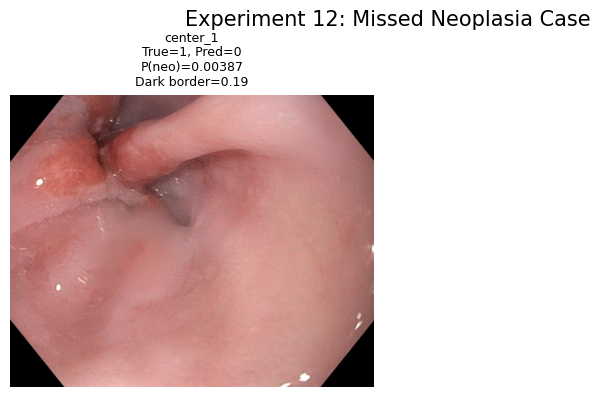

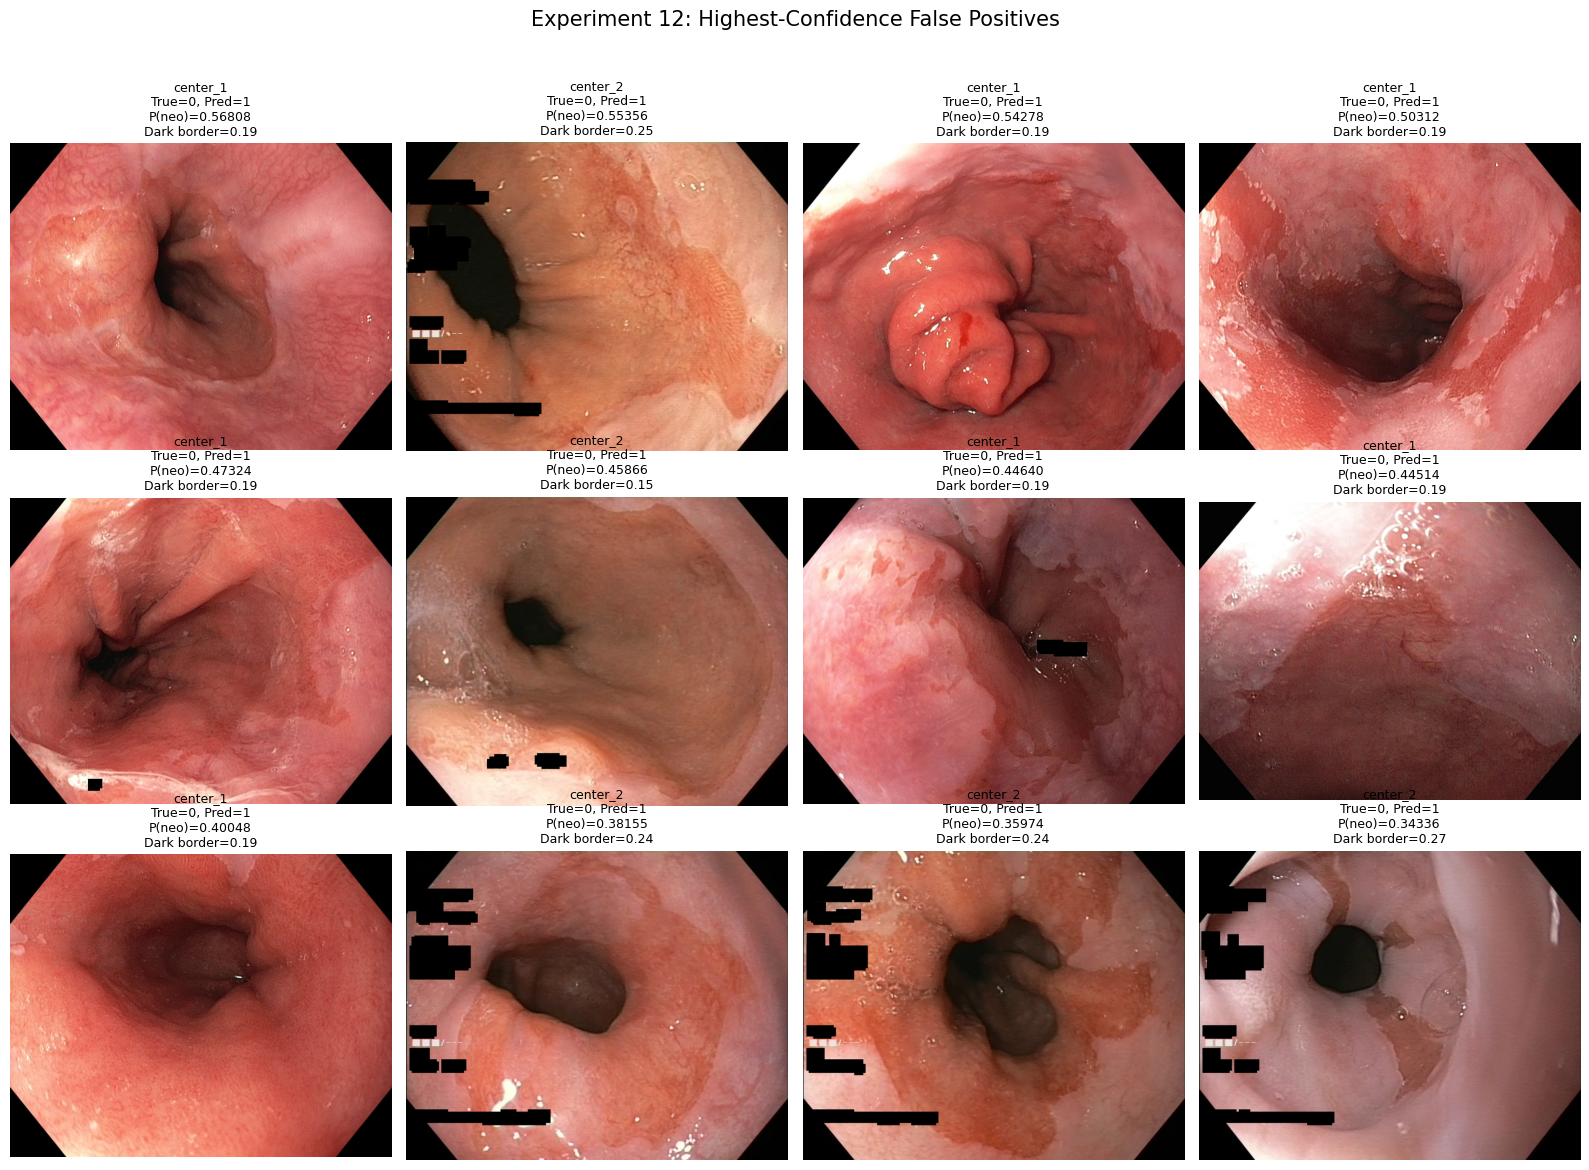

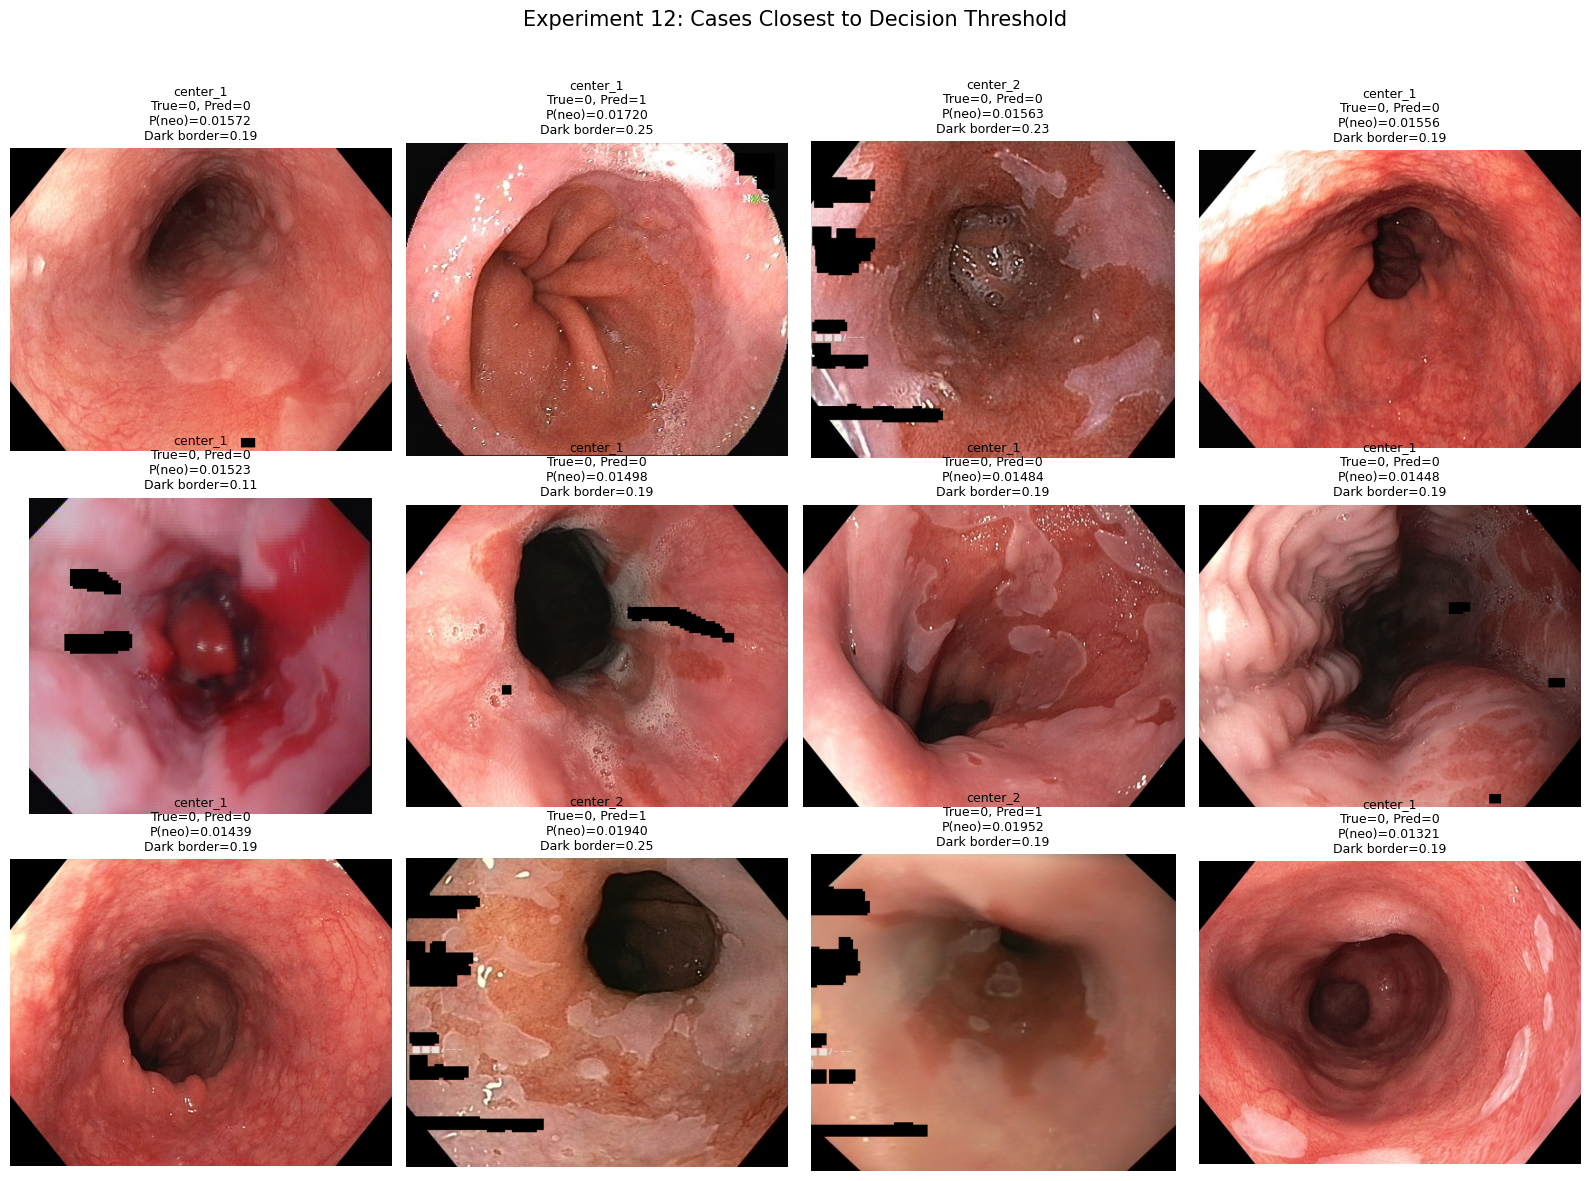


ARTIFACT SUMMARY BY CASE TYPE


,case_type,case_count,mean_probability,mean_brightness,mean_dark_ratio,mean_dark_border_ratio,mean_uncertainty
0,false_negative,1,0.003873,136.378906,0.067525,0.188821,0.561099
1,false_positive,86,0.150746,107.200435,0.091879,0.197831,0.800350
2,true_negative,356,0.002757,105.663006,0.085774,0.192343,0.422579
3,true_positive,25,0.788100,107.648802,0.079930,0.183435,0.520145



FINAL EXPERIMENT 12 SUMMARY
False-negative count: 1
False-negative center: center_1
False-negative ensemble probability: 0.0038729575
Baseline probability: 0.0032990652
Augmentation probability: 0.0043425057
Distance below threshold: 0.012550615379284622
Composite uncertainty: 0.5610990600144613
Mean brightness: 136.37890625
Whole-image dark ratio: 0.0675253875588697
Dark-border ratio: 0.18882144143217244
Image path: /content/RARE26_data/center_1/neo/878baebcfe9e4c909ac1dab9e4c6b36c.png

Top false positives audited: 12
Near-threshold cases audited: 12

Files saved:
/content/drive/MyDrive/RARE26/results/experiment12_error_audit_cases.csv
/content/drive/MyDrive/RARE26/results/experiment12_artifact_group_summary.csv
/content/drive/MyDrive/RARE26/results/figures/experiment12_false_negative_case.png
/content/drive/MyDrive/RARE26/results/figures/experiment12_top_false_positives.png
/content/drive/MyDrive/RARE26/results/figures/experiment12_near_threshold_cases.png


In [ ]:
# ================================================================
# EXPERIMENT 12
# FOCUSED VISUAL ERROR AND ARTIFACT AUDIT
#
# Purpose:
# 1. Single false-negative case inspect karna
# 2. Highest-confidence false positives inspect karna
# 3. Threshold ke qareeb difficult cases inspect karna
# 4. Brightness aur dark-border statistics save karna
# ================================================================

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image, ImageOps
from IPython.display import display as show_table


# ================================================================
# 1. PATHS
# ================================================================

drive_folder = Path(
    "/content/drive/MyDrive/RARE26"
)

results_folder = (
    drive_folder / "results"
)

figures_folder = (
    results_folder / "figures"
)

figures_folder.mkdir(
    parents=True,
    exist_ok=True
)


input_predictions_path = (
    results_folder
    / "asymmetric_referral_test_predictions.csv"
)


error_audit_csv_path = (
    results_folder
    / "experiment12_error_audit_cases.csv"
)

artifact_summary_path = (
    results_folder
    / "experiment12_artifact_group_summary.csv"
)

false_negative_figure_path = (
    figures_folder
    / "experiment12_false_negative_case.png"
)

top_false_positive_figure_path = (
    figures_folder
    / "experiment12_top_false_positives.png"
)

near_threshold_figure_path = (
    figures_folder
    / "experiment12_near_threshold_cases.png"
)


CLASSIFICATION_THRESHOLD = (
    0.01642357287928462
)


print(
    "Classification threshold:",
    CLASSIFICATION_THRESHOLD
)


# ================================================================
# 2. READ SAVED TEST PREDICTIONS
# ================================================================

audit_df = pd.read_csv(
    input_predictions_path
)


print("\nTotal test rows:", len(audit_df))

print(
    "Available columns:",
    list(audit_df.columns)
)


# ================================================================
# 3. STANDARDIZE REQUIRED COLUMNS
# ================================================================

if "analysis_label" not in audit_df.columns:

    if "true_label" in audit_df.columns:

        audit_df["analysis_label"] = (
            audit_df["true_label"]
            .astype(int)
        )

    elif "label" in audit_df.columns:

        audit_df["analysis_label"] = (
            audit_df["label"]
            .astype(int)
        )

    else:

        raise ValueError(
            "Label column nahi mila."
        )


if (
    "uncalibrated_ensemble_probability"
    not in audit_df.columns
):

    if "ensemble_probability" in audit_df.columns:

        audit_df[
            "uncalibrated_ensemble_probability"
        ] = (
            audit_df[
                "ensemble_probability"
            ].astype(float)
        )

    else:

        raise ValueError(
            "Ensemble probability column nahi mila."
        )


if "colab_path" not in audit_df.columns:

    raise ValueError(
        "colab_path column missing hai."
    )


audit_df["colab_path"] = (
    audit_df["colab_path"]
    .astype(str)
    .str.replace(
        "\\",
        "/",
        regex=False
    )
)


audit_df["analysis_label"] = (
    audit_df["analysis_label"]
    .astype(int)
)


audit_df[
    "uncalibrated_ensemble_probability"
] = (
    audit_df[
        "uncalibrated_ensemble_probability"
    ].astype(float)
)


if "center_name" not in audit_df.columns:

    audit_df["center_name"] = (
        audit_df["center"]
        .astype(str)
        .str.lower()
        .str.replace(
            "centre_",
            "center_",
            regex=False
        )
    )


# ================================================================
# 4. VERIFY IMAGE FILES
# ================================================================

path_exists_mask = audit_df[
    "colab_path"
].apply(
    lambda path:
        Path(path).exists()
)


missing_count = int(
    (~path_exists_mask).sum()
)


print(
    "Available image files:",
    int(path_exists_mask.sum())
)

print(
    "Missing image files:",
    missing_count
)


if missing_count > 0:

    print(
        audit_df.loc[
            ~path_exists_mask,
            "colab_path"
        ].head()
    )

    raise FileNotFoundError(
        "Kuch image files missing hain."
    )


# ================================================================
# 5. RECREATE PREDICTIONS AND ERROR TYPES
# ================================================================

audit_df[
    "ensemble_prediction"
] = (

    audit_df[
        "uncalibrated_ensemble_probability"
    ]

    >= CLASSIFICATION_THRESHOLD

).astype(int)


audit_df[
    "is_false_negative"
] = (

    (
        audit_df[
            "analysis_label"
        ] == 1
    )

    &

    (
        audit_df[
            "ensemble_prediction"
        ] == 0
    )

).astype(int)


audit_df[
    "is_false_positive"
] = (

    (
        audit_df[
            "analysis_label"
        ] == 0
    )

    &

    (
        audit_df[
            "ensemble_prediction"
        ] == 1
    )

).astype(int)


audit_df[
    "is_true_positive"
] = (

    (
        audit_df[
            "analysis_label"
        ] == 1
    )

    &

    (
        audit_df[
            "ensemble_prediction"
        ] == 1
    )

).astype(int)


audit_df[
    "is_true_negative"
] = (

    (
        audit_df[
            "analysis_label"
        ] == 0
    )

    &

    (
        audit_df[
            "ensemble_prediction"
        ] == 0
    )

).astype(int)


audit_df[
    "distance_from_threshold"
] = np.abs(

    audit_df[
        "uncalibrated_ensemble_probability"
    ]

    - CLASSIFICATION_THRESHOLD
)


def assign_case_type(row):

    if row["is_false_negative"] == 1:
        return "false_negative"

    if row["is_false_positive"] == 1:
        return "false_positive"

    if row["is_true_positive"] == 1:
        return "true_positive"

    return "true_negative"


audit_df["case_type"] = audit_df.apply(
    assign_case_type,
    axis=1
)


# ================================================================
# 6. IMAGE ARTIFACT STATISTICS
# ================================================================

def calculate_image_statistics(
    image_path
):

    image = Image.open(
        image_path
    ).convert("RGB")


    image_array = np.asarray(
        image
    ).astype(np.float32)


    grayscale = np.mean(
        image_array,
        axis=2
    )


    height, width = grayscale.shape


    border_height = max(
        1,
        int(height * 0.10)
    )

    border_width = max(
        1,
        int(width * 0.10)
    )


    border_mask = np.zeros(
        (height, width),
        dtype=bool
    )


    border_mask[
        :border_height,
        :
    ] = True

    border_mask[
        -border_height:,
        :
    ] = True

    border_mask[
        :,
        :border_width
    ] = True

    border_mask[
        :,
        -border_width:
    ] = True


    whole_dark_ratio = float(
        (
            grayscale < 20
        ).mean()
    )


    dark_border_ratio = float(
        (
            grayscale[
                border_mask
            ] < 20
        ).mean()
    )


    mean_brightness = float(
        grayscale.mean()
    )


    brightness_std = float(
        grayscale.std()
    )


    return {

        "image_width":
            int(width),

        "image_height":
            int(height),

        "mean_brightness":
            mean_brightness,

        "brightness_std":
            brightness_std,

        "whole_image_dark_ratio":
            whole_dark_ratio,

        "dark_border_ratio":
            dark_border_ratio,
    }


print("\nCalculating image artifact statistics...")


image_statistics = []


for image_path in audit_df[
    "colab_path"
]:

    image_statistics.append(

        calculate_image_statistics(
            image_path
        )
    )


statistics_df = pd.DataFrame(
    image_statistics
)


audit_df = pd.concat(
    [
        audit_df.reset_index(
            drop=True
        ),

        statistics_df.reset_index(
            drop=True
        ),
    ],

    axis=1
)


# ================================================================
# 7. IMPORTANT CASE GROUPS
# ================================================================

false_negative_df = audit_df[

    audit_df[
        "is_false_negative"
    ] == 1

].copy()


top_false_positive_df = (

    audit_df[

        audit_df[
            "is_false_positive"
        ] == 1

    ]

    .sort_values(

        by=
            "uncalibrated_ensemble_probability",

        ascending=False
    )

    .head(12)

    .copy()
)


near_threshold_df = (

    audit_df

    .sort_values(

        by=
            "distance_from_threshold",

        ascending=True
    )

    .head(12)

    .copy()
)


print("\n" + "=" * 100)

print(
    "FALSE-NEGATIVE CASE"
)

print("=" * 100)


show_columns = [

    "center_name",

    "class",

    "analysis_label",

    "ensemble_prediction",

    "baseline_probability",

    "augmentation_probability",

    "uncalibrated_ensemble_probability",

    "composite_uncertainty_score",

    "refer_for_manual_review",

    "asymmetric_manual_review",

    "mean_brightness",

    "whole_image_dark_ratio",

    "dark_border_ratio",

    "colab_path",
]


existing_show_columns = [

    column_name

    for column_name in show_columns

    if column_name in false_negative_df.columns
]


show_table(

    false_negative_df[
        existing_show_columns
    ]
)


print("\n" + "=" * 100)

print(
    "TOP 12 HIGHEST-CONFIDENCE FALSE POSITIVES"
)

print("=" * 100)


show_table(

    top_false_positive_df[
        [
            column_name

            for column_name in show_columns

            if column_name
            in top_false_positive_df.columns
        ]
    ]
)


# ================================================================
# 8. CONTACT-SHEET FUNCTION
# ================================================================

def create_contact_sheet(
    dataframe,
    title,
    save_path,
    max_images=12,
    columns=4
):

    dataframe = (
        dataframe
        .head(max_images)
        .reset_index(drop=True)
    )


    number_of_images = len(
        dataframe
    )


    if number_of_images == 0:

        print(
            f"No images available for {title}"
        )

        return


    rows = math.ceil(
        number_of_images
        / columns
    )


    plt.figure(
        figsize=(
            columns * 4,
            rows * 4
        )
    )


    for index in range(
        number_of_images
    ):

        row = dataframe.iloc[
            index
        ]


        image = Image.open(
            row["colab_path"]
        ).convert("RGB")


        image = ImageOps.exif_transpose(
            image
        )


        axis = plt.subplot(
            rows,
            columns,
            index + 1
        )


        axis.imshow(
            image
        )


        probability = float(

            row[
                "uncalibrated_ensemble_probability"
            ]
        )


        center_name = str(
            row["center_name"]
        )


        true_label = int(
            row["analysis_label"]
        )


        predicted_label = int(
            row["ensemble_prediction"]
        )


        axis.set_title(

            f"{center_name}\n"
            f"True={true_label}, Pred={predicted_label}\n"
            f"P(neo)={probability:.5f}\n"
            f"Dark border={row['dark_border_ratio']:.2f}",

            fontsize=9
        )


        axis.axis(
            "off"
        )


    plt.suptitle(
        title,
        fontsize=15
    )


    plt.tight_layout(
        rect=[
            0,
            0,
            1,
            0.95
        ]
    )


    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )


    plt.show()
    plt.close()


# ================================================================
# 9. CREATE CONTACT SHEETS
# ================================================================

create_contact_sheet(

    dataframe=false_negative_df,

    title=
        "Experiment 12: Missed Neoplasia Case",

    save_path=
        false_negative_figure_path,

    max_images=4,

    columns=2
)


create_contact_sheet(

    dataframe=top_false_positive_df,

    title=
        "Experiment 12: Highest-Confidence False Positives",

    save_path=
        top_false_positive_figure_path,

    max_images=12,

    columns=4
)


create_contact_sheet(

    dataframe=near_threshold_df,

    title=
        "Experiment 12: Cases Closest to Decision Threshold",

    save_path=
        near_threshold_figure_path,

    max_images=12,

    columns=4
)


# ================================================================
# 10. ARTIFACT SUMMARY BY CASE TYPE
# ================================================================

artifact_summary_df = (

    audit_df

    .groupby(
        "case_type"
    )

    .agg(

        case_count=(
            "case_type",
            "size"
        ),

        mean_probability=(
            "uncalibrated_ensemble_probability",
            "mean"
        ),

        mean_brightness=(
            "mean_brightness",
            "mean"
        ),

        mean_dark_ratio=(
            "whole_image_dark_ratio",
            "mean"
        ),

        mean_dark_border_ratio=(
            "dark_border_ratio",
            "mean"
        ),

        mean_uncertainty=(
            "composite_uncertainty_score",
            "mean"
        ),
    )

    .reset_index()
)


artifact_summary_df.to_csv(
    artifact_summary_path,
    index=False
)


audit_df.to_csv(
    error_audit_csv_path,
    index=False
)


print("\n" + "=" * 100)

print(
    "ARTIFACT SUMMARY BY CASE TYPE"
)

print("=" * 100)


show_table(
    artifact_summary_df
)


# ================================================================
# 11. SINGLE FALSE-NEGATIVE DETAILS
# ================================================================

print("\n" + "=" * 100)

print(
    "FINAL EXPERIMENT 12 SUMMARY"
)

print("=" * 100)


print(
    "False-negative count:",
    len(false_negative_df)
)


if len(false_negative_df) > 0:

    fn_row = false_negative_df.iloc[0]


    print(
        "False-negative center:",
        fn_row["center_name"]
    )


    print(
        "False-negative ensemble probability:",
        fn_row[
            "uncalibrated_ensemble_probability"
        ]
    )


    if (
        "baseline_probability"
        in fn_row.index
    ):

        print(
            "Baseline probability:",
            fn_row[
                "baseline_probability"
            ]
        )


    if (
        "augmentation_probability"
        in fn_row.index
    ):

        print(
            "Augmentation probability:",
            fn_row[
                "augmentation_probability"
            ]
        )


    print(
        "Distance below threshold:",
        CLASSIFICATION_THRESHOLD
        -
        fn_row[
            "uncalibrated_ensemble_probability"
        ]
    )


    print(
        "Composite uncertainty:",
        fn_row[
            "composite_uncertainty_score"
        ]
    )


    print(
        "Mean brightness:",
        fn_row[
            "mean_brightness"
        ]
    )


    print(
        "Whole-image dark ratio:",
        fn_row[
            "whole_image_dark_ratio"
        ]
    )


    print(
        "Dark-border ratio:",
        fn_row[
            "dark_border_ratio"
        ]
    )


    print(
        "Image path:",
        fn_row[
            "colab_path"
        ]
    )


print(
    "\nTop false positives audited:",
    len(top_false_positive_df)
)


print(
    "Near-threshold cases audited:",
    len(near_threshold_df)
)


print("\nFiles saved:")

print(
    error_audit_csv_path
)

print(
    artifact_summary_path
)

print(
    false_negative_figure_path
)

print(
    top_false_positive_figure_path
)

print(
    near_threshold_figure_path
)

In [ ]:
# ================================================================
# EXPERIMENT 13
# GASTRONET-5M DATASET READINESS AND STRUCTURE CHECK
#
# Purpose:
# 1. GastroNet files/folders automatically locate karna
# 2. Archive ya extracted dataset identify karna
# 3. Folder structure aur sample image formats check karna
# 4. Next self-supervised pretraining plan decide karna
# ================================================================

import os
import pandas as pd

from pathlib import Path
from collections import Counter
from IPython.display import display as show_table


# ================================================================
# 1. SEARCH SETTINGS
# ================================================================

search_roots = [
    Path("/content/drive/MyDrive"),
    Path("/content"),
]

search_keywords = [
    "gastronet",
    "gastro-net",
    "gastro_net",
]

maximum_search_depth = 7

image_extensions = {
    ".png",
    ".jpg",
    ".jpeg",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp",
}

archive_extensions = {
    ".zip",
    ".tar",
    ".gz",
    ".tgz",
    ".7z",
    ".rar",
}


results_folder = Path(
    "/content/drive/MyDrive/RARE26/results"
)

results_folder.mkdir(
    parents=True,
    exist_ok=True
)

discovery_csv_path = (
    results_folder
    / "gastronet_dataset_discovery.csv"
)

structure_csv_path = (
    results_folder
    / "gastronet_candidate_structure.csv"
)


print("=" * 90)
print("GASTRONET-5M DATASET SEARCH")
print("=" * 90)


# ================================================================
# 2. HELPER FUNCTIONS
# ================================================================

def contains_keyword(path_value):

    lower_value = str(
        path_value
    ).lower()

    return any(
        keyword in lower_value
        for keyword in search_keywords
    )


def calculate_depth(
    current_path,
    root_path
):

    try:

        relative_path = Path(
            current_path
        ).relative_to(
            root_path
        )

        return len(
            relative_path.parts
        )

    except ValueError:

        return 999


def safe_file_size_mb(
    file_path
):

    try:

        return round(
            Path(file_path).stat().st_size
            / (1024 ** 2),
            3
        )

    except Exception:

        return None


# ================================================================
# 3. SEARCH FOR MATCHING FILES AND FOLDERS
# ================================================================

found_records = []


for root_path in search_roots:

    if not root_path.exists():

        print(
            "Search root missing:",
            root_path
        )

        continue


    print(
        "\nSearching:",
        root_path
    )


    for current_root, directory_names, file_names in os.walk(
        root_path
    ):

        current_path = Path(
            current_root
        )


        current_depth = calculate_depth(
            current_path,
            root_path
        )


        # Search ko limited depth tak rakhna
        if current_depth >= maximum_search_depth:

            directory_names[:] = []


        # Hidden/cache folders skip karna
        directory_names[:] = [

            directory_name

            for directory_name in directory_names

            if not directory_name.startswith(".")
            and directory_name not in {
                "sample_data",
                "__pycache__",
                ".ipynb_checkpoints",
            }
        ]


        # Matching directory
        if contains_keyword(
            current_path.name
        ):

            found_records.append({

                "type":
                    "directory",

                "path":
                    str(current_path),

                "name":
                    current_path.name,

                "extension":
                    "",

                "size_mb":
                    None,

                "search_root":
                    str(root_path),
            })


        # Matching files
        for file_name in file_names:

            file_path = (
                current_path
                / file_name
            )


            if contains_keyword(
                file_name
            ):

                found_records.append({

                    "type":
                        "file",

                    "path":
                        str(file_path),

                    "name":
                        file_name,

                    "extension":
                        file_path.suffix.lower(),

                    "size_mb":
                        safe_file_size_mb(
                            file_path
                        ),

                    "search_root":
                        str(root_path),
                })


# ================================================================
# 4. CLEAN AND DISPLAY DISCOVERY RESULTS
# ================================================================

discovery_df = pd.DataFrame(
    found_records
)


if len(discovery_df) > 0:

    discovery_df = (

        discovery_df

        .drop_duplicates(
            subset=["path"]
        )

        .sort_values(
            by=[
                "type",
                "path",
            ]
        )

        .reset_index(
            drop=True
        )
    )


    discovery_df.to_csv(
        discovery_csv_path,
        index=False
    )


    print("\n" + "=" * 90)
    print("GASTRONET CANDIDATES FOUND")
    print("=" * 90)


    show_table(
        discovery_df
    )

else:

    discovery_df = pd.DataFrame(
        columns=[
            "type",
            "path",
            "name",
            "extension",
            "size_mb",
            "search_root",
        ]
    )


    discovery_df.to_csv(
        discovery_csv_path,
        index=False
    )


    print("\nNo GastroNet-named files or folders were found.")


# ================================================================
# 5. CREATE CANDIDATE DIRECTORY LIST
# ================================================================

candidate_directories = set()


for _, row in discovery_df.iterrows():

    candidate_path = Path(
        row["path"]
    )


    if row["type"] == "directory":

        candidate_directories.add(
            candidate_path
        )

    else:

        candidate_directories.add(
            candidate_path.parent
        )


candidate_directories = sorted(
    candidate_directories,
    key=lambda path:
        str(path)
)


# ================================================================
# 6. INSPECT EACH CANDIDATE DIRECTORY
# ================================================================

structure_records = []


for candidate_directory in candidate_directories:

    if not candidate_directory.exists():

        continue


    print("\n" + "=" * 90)

    print(
        "INSPECTING CANDIDATE:",
        candidate_directory
    )

    print("=" * 90)


    try:

        immediate_items = list(
            candidate_directory.iterdir()
        )

    except PermissionError:

        print(
            "Permission denied:",
            candidate_directory
        )

        continue


    immediate_directories = [

        item

        for item in immediate_items

        if item.is_dir()
    ]


    immediate_files = [

        item

        for item in immediate_items

        if item.is_file()
    ]


    print(
        "Immediate subfolders:",
        len(immediate_directories)
    )

    print(
        "Immediate files:",
        len(immediate_files)
    )


    if len(immediate_directories) > 0:

        print("\nFirst subfolders:")

        for folder_path in (
            immediate_directories[:20]
        ):

            print(
                " -",
                folder_path.name
            )


    if len(immediate_files) > 0:

        print("\nFirst files:")

        for file_path in (
            immediate_files[:20]
        ):

            print(
                " -",
                file_path.name
            )


    # ------------------------------------------------------------
    # Sample up to 100 image files without scanning all 5M files
    # ------------------------------------------------------------

    sampled_image_paths = []

    sampled_extensions = Counter()

    visited_file_count = 0

    maximum_files_to_inspect = 5000

    maximum_images_to_sample = 100


    for current_root, directory_names, file_names in os.walk(
        candidate_directory
    ):

        directory_names[:] = [

            directory_name

            for directory_name in directory_names

            if not directory_name.startswith(".")
        ]


        for file_name in file_names:

            visited_file_count += 1


            file_path = (
                Path(current_root)
                / file_name
            )


            extension = (
                file_path.suffix.lower()
            )


            sampled_extensions[
                extension
            ] += 1


            if (
                extension
                in image_extensions
            ):

                sampled_image_paths.append(
                    str(file_path)
                )


            if (
                visited_file_count
                >= maximum_files_to_inspect
                or
                len(sampled_image_paths)
                >= maximum_images_to_sample
            ):

                break


        if (
            visited_file_count
            >= maximum_files_to_inspect
            or
            len(sampled_image_paths)
            >= maximum_images_to_sample
        ):

            break


    print(
        "\nFiles inspected:",
        visited_file_count
    )

    print(
        "Sample image files found:",
        len(sampled_image_paths)
    )

    print(
        "Observed extensions:",
        dict(
            sampled_extensions.most_common(
                15
            )
        )
    )


    if len(sampled_image_paths) > 0:

        print("\nFirst sample images:")

        for image_path in (
            sampled_image_paths[:10]
        ):

            print(
                " -",
                image_path
            )


    structure_records.append({

        "candidate_directory":
            str(candidate_directory),

        "immediate_subfolder_count":
            len(immediate_directories),

        "immediate_file_count":
            len(immediate_files),

        "files_inspected":
            visited_file_count,

        "sample_images_found":
            len(sampled_image_paths),

        "observed_extensions":
            str(
                dict(
                    sampled_extensions.most_common(
                        15
                    )
                )
            ),

        "first_sample_image":
            (
                sampled_image_paths[0]
                if len(sampled_image_paths) > 0
                else ""
            ),
    })


# ================================================================
# 7. ARCHIVE FILE SUMMARY
# ================================================================

archive_rows = []


for _, row in discovery_df.iterrows():

    file_path = Path(
        row["path"]
    )


    lower_name = (
        file_path.name.lower()
    )


    is_archive = any(

        lower_name.endswith(
            extension
        )

        for extension in archive_extensions
    )


    if (
        row["type"] == "file"
        and is_archive
    ):

        archive_rows.append(
            row.to_dict()
        )


archive_df = pd.DataFrame(
    archive_rows
)


print("\n" + "=" * 90)
print("GASTRONET ARCHIVE SUMMARY")
print("=" * 90)


if len(archive_df) > 0:

    show_table(
        archive_df
    )

else:

    print(
        "No GastroNet archive file was detected."
    )


# ================================================================
# 8. SAVE STRUCTURE RESULTS
# ================================================================

structure_df = pd.DataFrame(
    structure_records
)


structure_df.to_csv(
    structure_csv_path,
    index=False
)


# ================================================================
# 9. FINAL READINESS SUMMARY
# ================================================================

print("\n" + "=" * 90)
print("FINAL GASTRONET READINESS SUMMARY")
print("=" * 90)


print(
    "Total named candidates:",
    len(discovery_df)
)

print(
    "Candidate directories inspected:",
    len(structure_df)
)


if len(structure_df) > 0:

    total_sample_images = int(
        structure_df[
            "sample_images_found"
        ].sum()
    )

else:

    total_sample_images = 0


print(
    "Total sample images detected:",
    total_sample_images
)


if total_sample_images > 0:

    print(
        "\nSTATUS: Extracted GastroNet image data "
        "appears to be available."
    )

elif len(archive_df) > 0:

    print(
        "\nSTATUS: GastroNet archive appears available, "
        "but extraction may still be required."
    )

else:

    print(
        "\nSTATUS: GastroNet dataset was not found "
        "in the searched Colab/Drive locations."
    )


print("\nFiles saved:")

print(
    discovery_csv_path
)

print(
    structure_csv_path
)

GASTRONET-5M DATASET SEARCH

Searching: /content/drive/MyDrive

Searching: /content

No GastroNet-named files or folders were found.

GASTRONET ARCHIVE SUMMARY
No GastroNet archive file was detected.

FINAL GASTRONET READINESS SUMMARY
Total named candidates: 0
Candidate directories inspected: 0
Total sample images detected: 0

STATUS: GastroNet dataset was not found in the searched Colab/Drive locations.

Files saved:
/content/drive/MyDrive/RARE26/results/gastronet_dataset_discovery.csv
/content/drive/MyDrive/RARE26/results/gastronet_candidate_structure.csv


In [ ]:
# ================================================================
# PHASE 2A — STEP 1
# MAXVIT-TINY 384 READINESS CHECK
#
# Purpose:
# 1. timm install/version check
# 2. Existing RARE26 split files verify karna
# 3. All image paths verify karna
# 4. Official ImageNet-pretrained MaxViT-Tiny 384 load karna
# 5. GPU forward-pass and memory readiness check
# ================================================================

# ------------------------------------------------
# Install timm
# ------------------------------------------------
!pip install -q --upgrade timm


# ================================================================
# 1. IMPORTS
# ================================================================

import sys
import platform
import numpy as np
import pandas as pd
import torch
import torchvision
import timm

from pathlib import Path
from IPython.display import display as show_table


# ================================================================
# 2. SETTINGS
# ================================================================

SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


MODEL_NAME = "maxvit_tiny_tf_384.in1k"

IMAGE_SIZE = 384

NUMBER_OF_CLASSES = 1


print("=" * 90)
print("PHASE 2A — MAXVIT READINESS CHECK")
print("=" * 90)

print("Device:", device)
print("Python version:", sys.version.split()[0])
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("timm version:", timm.__version__)


if device.type == "cuda":

    gpu_properties = torch.cuda.get_device_properties(0)

    total_gpu_memory_gb = (
        gpu_properties.total_memory
        / (1024 ** 3)
    )

    print("GPU name:", gpu_properties.name)

    print(
        "Total GPU memory:",
        round(total_gpu_memory_gb, 2),
        "GB"
    )

else:

    print(
        "WARNING: GPU active nahi hai. "
        "Colab Runtime > Change runtime type > T4 GPU select karein."
    )


# ================================================================
# 3. GOOGLE DRIVE PATHS
# ================================================================

drive_folder = Path(
    "/content/drive/MyDrive/RARE26"
)

splits_folder = drive_folder / "splits"
models_folder = drive_folder / "models"
results_folder = drive_folder / "results"
figures_folder = results_folder / "figures"


models_folder.mkdir(
    parents=True,
    exist_ok=True
)

results_folder.mkdir(
    parents=True,
    exist_ok=True
)

figures_folder.mkdir(
    parents=True,
    exist_ok=True
)


train_csv_path = (
    splits_folder / "train_colab.csv"
)

validation_csv_path = (
    splits_folder / "validation_colab.csv"
)

test_csv_path = (
    splits_folder / "test_colab.csv"
)


readiness_report_path = (
    results_folder
    / "phase2a_maxvit_readiness_report.csv"
)


# ================================================================
# 4. VERIFY SPLIT CSV FILES
# ================================================================

required_csv_files = {
    "train": train_csv_path,
    "validation": validation_csv_path,
    "test": test_csv_path,
}


print("\n" + "=" * 90)
print("SPLIT FILE CHECK")
print("=" * 90)


for split_name, split_path in required_csv_files.items():

    print(
        split_name,
        ":",
        split_path.exists(),
        "|",
        split_path
    )


missing_csv_files = [

    split_name

    for split_name, split_path
    in required_csv_files.items()

    if not split_path.exists()
]


if len(missing_csv_files) > 0:

    raise FileNotFoundError(
        "Missing split CSV files: "
        + ", ".join(missing_csv_files)
    )


# ================================================================
# 5. READ SPLITS
# ================================================================

train_df = pd.read_csv(
    train_csv_path
)

validation_df = pd.read_csv(
    validation_csv_path
)

test_df = pd.read_csv(
    test_csv_path
)


print("\nSplit sizes:")

print("Training:", len(train_df))
print("Validation:", len(validation_df))
print("Test:", len(test_df))


expected_split_sizes = {
    "train": 2159,
    "validation": 461,
    "test": 468,
}


if len(train_df) != expected_split_sizes["train"]:

    raise ValueError(
        f"Unexpected training size: {len(train_df)}"
    )


if len(validation_df) != expected_split_sizes["validation"]:

    raise ValueError(
        f"Unexpected validation size: {len(validation_df)}"
    )


if len(test_df) != expected_split_sizes["test"]:

    raise ValueError(
        f"Unexpected test size: {len(test_df)}"
    )


# ================================================================
# 6. VERIFY REQUIRED COLUMNS
# ================================================================

required_columns = [
    "colab_path",
    "label",
    "center",
]


for split_name, dataframe in [
    ("train", train_df),
    ("validation", validation_df),
    ("test", test_df),
]:

    missing_columns = [

        column_name

        for column_name in required_columns

        if column_name not in dataframe.columns
    ]


    if len(missing_columns) > 0:

        raise ValueError(
            f"{split_name} CSV mein missing columns: "
            + ", ".join(missing_columns)
        )


# ================================================================
# 7. CLEAN AND VERIFY IMAGE PATHS
# ================================================================

def prepare_split(
    dataframe,
    split_name
):

    dataframe = (
        dataframe.copy()
        .reset_index(drop=True)
    )


    dataframe["colab_path"] = (

        dataframe["colab_path"]

        .astype(str)

        .str.replace(
            "\\",
            "/",
            regex=False
        )
    )


    dataframe["label"] = (
        dataframe["label"]
        .astype(int)
    )


    dataframe["center_name"] = (

        dataframe["center"]

        .astype(str)

        .str.lower()

        .str.replace(
            "centre_",
            "center_",
            regex=False
        )
    )


    dataframe["path_exists"] = (

        dataframe["colab_path"]

        .apply(
            lambda image_path:
                Path(image_path).exists()
        )
    )


    missing_count = int(
        (~dataframe["path_exists"]).sum()
    )


    print(
        f"{split_name} available images:",
        int(dataframe["path_exists"].sum())
    )

    print(
        f"{split_name} missing images:",
        missing_count
    )


    if missing_count > 0:

        print(
            dataframe.loc[
                ~dataframe["path_exists"],
                "colab_path"
            ].head(10)
        )


        raise FileNotFoundError(
            f"{split_name} dataset images "
            "Colab /content folder mein missing hain."
        )


    return dataframe


print("\n" + "=" * 90)
print("IMAGE PATH CHECK")
print("=" * 90)


train_df = prepare_split(
    train_df,
    "Training"
)

validation_df = prepare_split(
    validation_df,
    "Validation"
)

test_df = prepare_split(
    test_df,
    "Test"
)


total_available_images = (

    int(train_df["path_exists"].sum())

    +

    int(validation_df["path_exists"].sum())

    +

    int(test_df["path_exists"].sum())
)


print(
    "\nTotal available images:",
    total_available_images
)


if total_available_images != 3088:

    raise ValueError(
        "Expected 3088 available images, "
        f"but found {total_available_images}."
    )


# ================================================================
# 8. DISPLAY DATA DISTRIBUTION
# ================================================================

print("\nTraining centre/class distribution:")

training_distribution = pd.crosstab(
    train_df["center_name"],
    train_df["label"]
)

show_table(
    training_distribution
)


print("\nValidation centre/class distribution:")

validation_distribution = pd.crosstab(
    validation_df["center_name"],
    validation_df["label"]
)

show_table(
    validation_distribution
)


print("\nTest centre/class distribution:")

test_distribution = pd.crosstab(
    test_df["center_name"],
    test_df["label"]
)

show_table(
    test_distribution
)


# ================================================================
# 9. LOAD IMAGENET-PRETRAINED MAXVIT-TINY 384
# ================================================================

print("\n" + "=" * 90)
print("LOADING IMAGENET-PRETRAINED MAXVIT-TINY 384")
print("=" * 90)


try:

    maxvit_model = timm.create_model(

        MODEL_NAME,

        pretrained=True,

        num_classes=NUMBER_OF_CLASSES
    )


    loaded_model_name = MODEL_NAME


except Exception as first_error:

    print(
        "Direct timm model name failed."
    )

    print(
        "Trying Hugging Face timm model reference..."
    )


    fallback_model_name = (
        "hf_hub:timm/"
        "maxvit_tiny_tf_384.in1k"
    )


    try:

        maxvit_model = timm.create_model(

            fallback_model_name,

            pretrained=True,

            num_classes=NUMBER_OF_CLASSES
        )


        loaded_model_name = (
            fallback_model_name
        )


    except Exception as second_error:

        print("\nFirst loading error:")

        print(first_error)

        print("\nSecond loading error:")

        print(second_error)


        raise RuntimeError(
            "MaxViT pretrained weights load nahi hue. "
            "Internet connection ya Hugging Face access check karein."
        )


maxvit_model = maxvit_model.to(
    device
)


print(
    "Successfully loaded model:",
    loaded_model_name
)


# ================================================================
# 10. MODEL DATA CONFIGURATION
# ================================================================

model_data_config = (
    timm.data.resolve_model_data_config(
        maxvit_model
    )
)


print("\nModel data configuration:")

for config_name, config_value in (
    model_data_config.items()
):

    print(
        config_name,
        ":",
        config_value
    )


resolved_input_size = (
    model_data_config.get(
        "input_size",
        None
    )
)


print(
    "\nResolved model input size:",
    resolved_input_size
)


if resolved_input_size is not None:

    resolved_height = int(
        resolved_input_size[-2]
    )

    resolved_width = int(
        resolved_input_size[-1]
    )


    if (
        resolved_height != IMAGE_SIZE
        or
        resolved_width != IMAGE_SIZE
    ):

        raise ValueError(
            "Loaded model ka input size 384×384 nahi hai. "
            f"Resolved size: {resolved_input_size}"
        )


# ================================================================
# 11. MODEL PARAMETER COUNT
# ================================================================

total_parameters = sum(

    parameter.numel()

    for parameter in maxvit_model.parameters()
)


trainable_parameters = sum(

    parameter.numel()

    for parameter in maxvit_model.parameters()

    if parameter.requires_grad
)


print(
    "\nTotal parameters:",
    f"{total_parameters:,}"
)

print(
    "Trainable parameters:",
    f"{trainable_parameters:,}"
)


# ================================================================
# 12. SYNTHETIC 384×384 GPU FORWARD PASS
# ================================================================

print("\n" + "=" * 90)
print("384×384 GPU FORWARD-PASS TEST")
print("=" * 90)


TEST_BATCH_SIZE = 2


dummy_images = torch.randn(

    TEST_BATCH_SIZE,

    3,

    IMAGE_SIZE,

    IMAGE_SIZE,

    device=device
)


maxvit_model.eval()


if device.type == "cuda":

    torch.cuda.empty_cache()

    torch.cuda.reset_peak_memory_stats()


    with torch.inference_mode():

        with torch.autocast(

            device_type="cuda",

            dtype=torch.float16
        ):

            dummy_outputs = maxvit_model(
                dummy_images
            )


    peak_gpu_memory_gb = (

        torch.cuda.max_memory_allocated()

        / (1024 ** 3)
    )


else:

    with torch.inference_mode():

        dummy_outputs = maxvit_model(
            dummy_images
        )


    peak_gpu_memory_gb = np.nan


print(
    "Test batch size:",
    TEST_BATCH_SIZE
)

print(
    "Dummy input shape:",
    tuple(dummy_images.shape)
)

print(
    "Model output shape:",
    tuple(dummy_outputs.shape)
)

print(
    "Peak GPU memory during test:",
    (
        round(peak_gpu_memory_gb, 3)
        if not np.isnan(
            peak_gpu_memory_gb
        )
        else "CPU mode"
    ),
    "GB"
)


expected_output_shape = (
    TEST_BATCH_SIZE,
    NUMBER_OF_CLASSES
)


if tuple(dummy_outputs.shape) != expected_output_shape:

    raise ValueError(
        "Unexpected output shape: "
        f"{tuple(dummy_outputs.shape)}"
    )


# ================================================================
# 13. SAVE READINESS REPORT
# ================================================================

readiness_status = "READY"


readiness_report_df = pd.DataFrame([

    {
        "phase":
            "Phase 2A",

        "step":
            "MaxViT-Tiny 384 readiness check",

        "status":
            readiness_status,

        "device":
            str(device),

        "gpu_name":
            (
                torch.cuda.get_device_properties(0).name

                if device.type == "cuda"

                else "CPU"
            ),

        "total_gpu_memory_gb":
            (
                round(
                    torch.cuda.get_device_properties(
                        0
                    ).total_memory
                    / (1024 ** 3),
                    3
                )

                if device.type == "cuda"

                else np.nan
            ),

        "python_version":
            sys.version.split()[0],

        "pytorch_version":
            torch.__version__,

        "torchvision_version":
            torchvision.__version__,

        "timm_version":
            timm.__version__,

        "model_name":
            loaded_model_name,

        "image_size":
            IMAGE_SIZE,

        "output_classes":
            NUMBER_OF_CLASSES,

        "total_parameters":
            total_parameters,

        "trainable_parameters":
            trainable_parameters,

        "test_batch_size":
            TEST_BATCH_SIZE,

        "test_output_shape":
            str(
                tuple(dummy_outputs.shape)
            ),

        "peak_forward_memory_gb":
            (
                peak_gpu_memory_gb

                if device.type == "cuda"

                else np.nan
            ),

        "train_images":
            len(train_df),

        "validation_images":
            len(validation_df),

        "test_images":
            len(test_df),

        "total_available_images":
            total_available_images,
    }
])


readiness_report_df.to_csv(
    readiness_report_path,
    index=False
)


print("\n" + "=" * 90)
print("FINAL PHASE 2A READINESS SUMMARY")
print("=" * 90)


show_table(
    readiness_report_df
)


print("\nSTATUS: MAXVIT-TINY 384 PILOT IS READY.")


print("\nFile saved:")

print(
    readiness_report_path
)


# Clear synthetic tensors from GPU
del dummy_images
del dummy_outputs

torch.cuda.empty_cache()